In [1]:
import torch
import os

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

print("\nAttached datasets:")

for item in os.listdir("/kaggle/input"):
    print("-", item)

PyTorch version: 2.11.0+cpu
CUDA available: False

Attached datasets:
- datasets


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print(f"\n{root}")
    for file in files[:10]:
        print("  ", file)


/kaggle/input

/kaggle/input/datasets

/kaggle/input/datasets/ashery

/kaggle/input/datasets/ashery/chexpert
   train.csv
   valid.csv

/kaggle/input/datasets/biditdas06


In [3]:
import os

for dataset in os.listdir("/kaggle/input/datasets"):
    print(f"\n{'='*60}")
    print("DATASET:", dataset)

    base = os.path.join("/kaggle/input/datasets", dataset)

    for root, dirs, files in os.walk(base):
        relative = os.path.relpath(root, base)

        print(f"\nFolder: {relative}")
        print("Subfolders:", dirs[:15])
        print("Files:", files[:15])

        # Avoid traversing deeply into image collections
        dirs[:] = dirs[:15]

        if relative.count(os.sep) >= 2:
            dirs[:] = []


DATASET: ashery

Folder: .
Subfolders: ['chexpert']
Files: []

Folder: chexpert
Subfolders: ['train', 'valid']
Files: ['train.csv', 'valid.csv']

Folder: chexpert/train
Subfolders: ['patient00001', 'patient00002', 'patient00003', 'patient00004', 'patient00005', 'patient00006', 'patient00007', 'patient00008', 'patient00009', 'patient00010', 'patient00011', 'patient00012', 'patient00013', 'patient00014', 'patient00015']
Files: []

Folder: chexpert/train/patient00001
Subfolders: ['study1']
Files: []

Folder: chexpert/train/patient00002
Subfolders: ['study1', 'study2']
Files: []

Folder: chexpert/train/patient00003
Subfolders: ['study1']
Files: []

Folder: chexpert/train/patient00004
Subfolders: ['study1']
Files: []

Folder: chexpert/train/patient00005
Subfolders: ['study1', 'study2']
Files: []

Folder: chexpert/train/patient00006
Subfolders: ['study1']
Files: []

Folder: chexpert/train/patient00007
Subfolders: ['study1', 'study2']
Files: []

Folder: chexpert/train/patient00008
Subfolders

In [4]:
import os

path = "/kaggle/input/datasets/biditdas06"

print("Exists:", os.path.exists(path))
print("Contents:", os.listdir(path))
print("Total files:", sum(len(files) for _, _, files in os.walk(path)))

Exists: True
Contents: []
Total files: 0


In [8]:
import os

base = "/kaggle/input"

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d.startswith("images_")]

    important = [
        f for f in files
        if f in [
            "Data_Entry_2017.csv",
            "Data_Entry_2017_v2020.csv",
            "BBox_List_2017.csv",
            "sample_labels.csv"
        ]
    ]

    if important:
        print(root)
        print("Metadata:", important)

    image_dirs = [d for d in dirs if d.startswith("images_")]
    if image_dirs:
        print(root)
        print("Image folders:", image_dirs)

In [9]:
import os

print("Mounted datasets:")
print(os.listdir("/kaggle/input"))

print("\nDataset contents:")
for name in os.listdir("/kaggle/input"):
    path = os.path.join("/kaggle/input", name)
    print(name, "->", os.listdir(path)[:20])

Mounted datasets:
['datasets']

Dataset contents:
datasets -> ['ashery', 'biditdas06']


In [10]:
import os

for name in ["ashery", "biditdas06"]:
    path = f"/kaggle/input/datasets/{name}"

    print(f"\n{name}:")
    print("Contents:", os.listdir(path)[:30])

    for item in os.listdir(path)[:30]:
        subpath = os.path.join(path, item)

        if os.path.isdir(subpath):
            print(f"  {item}/ ->", os.listdir(subpath)[:10])


ashery:
Contents: ['chexpert']
  chexpert/ -> ['train', 'train.csv', 'valid', 'valid.csv']

biditdas06:
Contents: ['nih-chestxray14']
  nih-chestxray14/ -> ['Data_Entry_2017_v2020.csv', 'images_001', 'images_002', 'images_003', 'images_004', 'images_005', 'images_006', 'images_007', 'images_008', 'images_009']


In [11]:
import os

nih_path = "/kaggle/input/datasets/biditdas06/nih-chestxray14"

print("NIH metadata:", os.path.exists(
    os.path.join(nih_path, "Data_Entry_2017_v2020.csv")
))

print("Bounding boxes:", os.path.exists(
    os.path.join(nih_path, "BBox_List_2017.csv")
))

print("\nImage folders:")
print([x for x in os.listdir(nih_path) if x.startswith("images_")])

NIH metadata: True
Bounding boxes: False

Image folders:
['images_001', 'images_002', 'images_003', 'images_004', 'images_005', 'images_006', 'images_007', 'images_008', 'images_009', 'images_010', 'images_011', 'images_012']


In [12]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "BBox_List_2017.csv" in files:
        print("FOUND:", os.path.join(root, "BBox_List_2017.csv"))

FOUND: /kaggle/input/datasets/kautilyasagili/nih-bounding-box-annotations/BBox_List_2017.csv


KeyboardInterrupt: 

In [13]:
import pandas as pd

bbox_path = "/kaggle/input/datasets/kautilyasagili/nih-bounding-box-annotations/BBox_List_2017.csv"

bbox_df = pd.read_csv(bbox_path)

print("Shape:", bbox_df.shape)
print("Columns:", bbox_df.columns.tolist())
display(bbox_df.head())

Shape: (984, 9)
Columns: ['Image Index', 'Finding Label', 'Bbox [x', 'y', 'w', 'h]', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']


,Image Index,Finding Label,Bbox [x,y,w,h],Unnamed: 6,Unnamed: 7,Unnamed: 8
0,00013118_008.png,Atelectasis,225.084746,547.019217,86.779661,79.186441,NaN,NaN,NaN
1,00014716_007.png,Atelectasis,686.101695,131.543498,185.491525,313.491525,NaN,NaN,NaN
2,00029817_009.png,Atelectasis,221.830508,317.053115,155.118644,216.949153,NaN,NaN,NaN
3,00014687_001.png,Atelectasis,726.237288,494.951420,141.016949,55.322034,NaN,NaN,NaN
4,00017877_001.png,Atelectasis,660.067797,569.780787,200.677966,78.101695,NaN,NaN,NaN


In [14]:
# Remove completely empty columns
bbox_df = bbox_df.dropna(axis=1, how="all")

# Rename columns
bbox_df.columns = [
    "Image Index",
    "Finding Label",
    "x",
    "y",
    "w",
    "h"
]

print("Shape:", bbox_df.shape)
print("\nFinding distribution:")
print(bbox_df["Finding Label"].value_counts())

print("\nUnique annotated images:",
      bbox_df["Image Index"].nunique())

print("\nMissing values:")
print(bbox_df.isnull().sum())

print("\nBounding box coordinate statistics:")
display(bbox_df[["x", "y", "w", "h"]].describe())

Shape: (984, 6)

Finding distribution:
Finding Label
Atelectasis     180
Effusion        153
Cardiomegaly    146
Infiltrate      123
Pneumonia       120
Pneumothorax     98
Mass             85
Nodule           79
Name: count, dtype: int64

Unique annotated images: 880

Missing values:
Image Index      0
Finding Label    0
x                0
y                0
w                0
h                0
dtype: int64

Bounding box coordinate statistics:


,x,y,w,h
count,984.000000,984.000000,984.000000,984.000000
mean,398.806111,405.425364,256.334708,252.302547
std,222.700868,166.309995,167.629620,159.443635
min,5.417989,12.837934,27.306667,21.617778
25%,203.093333,293.869045,136.533333,115.674074
50%,340.249735,412.850794,214.340942,216.949153
75%,607.959365,521.641995,311.832381,367.902430
max,905.887831,876.980783,901.120000,873.379894


In [15]:
import os

nih_root = "/kaggle/input/datasets/biditdas06/nih-chestxray14"

image_folders = [
    os.path.join(nih_root, f"images_{i:03d}")
    for i in range(1, 13)
]

unique_images = bbox_df["Image Index"].unique()

image_locations = {}

for folder in image_folders:
    for filename in unique_images:
        path = os.path.join(folder, filename)
        if os.path.isfile(path):
            image_locations[filename] = path

missing_images = set(unique_images) - set(image_locations)

print("Total annotated images:", len(unique_images))
print("Images found:", len(image_locations))
print("Images missing:", len(missing_images))

if missing_images:
    print("Missing examples:", list(missing_images)[:10])

KeyboardInterrupt: 

In [16]:
import os

nih_root = "/kaggle/input/datasets/biditdas06/nih-chestxray14"

target_images = set(bbox_df["Image Index"].astype(str))
image_locations = {}

for i in range(1, 13):
    folder = os.path.join(nih_root, f"images_{i:03d}")

    if not os.path.isdir(folder):
        continue

    with os.scandir(folder) as entries:
        for entry in entries:
            if entry.is_file() and entry.name in target_images:
                image_locations[entry.name] = entry.path

missing_images = target_images - set(image_locations)

print("Total annotated images:", len(target_images))
print("Images found:", len(image_locations))
print("Images missing:", len(missing_images))

if missing_images:
    print("Missing examples:", list(missing_images)[:10])

Total annotated images: 880
Images found: 0
Images missing: 880
Missing examples: ['00012741_004.png', '00017083_002.png', '00020213_078.png', '00021796_000.png', '00022141_030.png', '00012048_007.png', '00006096_010.png', '00021481_014.png', '00017151_003.png', '00022416_004.png']


In [17]:
import os

nih_root = "/kaggle/input/datasets/biditdas06/nih-chestxray14"

print("NIH root exists:", os.path.exists(nih_root))
print("\nFolders/files inside NIH root:")

for item in os.listdir(nih_root)[:30]:
    path = os.path.join(nih_root, item)
    print(item, "| Directory:", os.path.isdir(path))

print("\nContents of images_001 (first 15 entries):")

folder = os.path.join(nih_root, "images_001")

if os.path.exists(folder):
    print(os.listdir(folder)[:15])
else:
    print("images_001 folder not found")

NIH root exists: True

Folders/files inside NIH root:
Data_Entry_2017_v2020.csv | Directory: False
images_001 | Directory: True
images_002 | Directory: True
images_003 | Directory: True
images_004 | Directory: True
images_005 | Directory: True
images_006 | Directory: True
images_007 | Directory: True
images_008 | Directory: True
images_009 | Directory: True
images_010 | Directory: True
images_011 | Directory: True
images_012 | Directory: True

Contents of images_001 (first 15 entries):
['images']


In [18]:
import os

folder = "/kaggle/input/datasets/biditdas06/nih-chestxray14/images_001/images"

print("Folder exists:", os.path.isdir(folder))
print("First 15 files:")

if os.path.isdir(folder):
    print(os.listdir(folder)[:15])

Folder exists: True
First 15 files:
['00000001_000.png', '00000001_001.png', '00000001_002.png', '00000002_000.png', '00000003_000.png', '00000003_001.png', '00000003_002.png', '00000003_003.png', '00000003_004.png', '00000003_005.png', '00000003_006.png', '00000003_007.png', '00000004_000.png', '00000005_000.png', '00000005_001.png']


In [19]:
import os

nih_root = "/kaggle/input/datasets/biditdas06/nih-chestxray14"

target_images = set(bbox_df["Image Index"].astype(str))
image_locations = {}

for i in range(1, 13):
    folder = os.path.join(
        nih_root,
        f"images_{i:03d}",
        "images"
    )

    if not os.path.isdir(folder):
        print("Folder missing:", folder)
        continue

    with os.scandir(folder) as entries:
        for entry in entries:
            if entry.is_file() and entry.name in target_images:
                image_locations[entry.name] = entry.path

missing_images = target_images - set(image_locations)

print("Total annotated images:", len(target_images))
print("Images found:", len(image_locations))
print("Images missing:", len(missing_images))

if missing_images:
    print("Missing examples:", list(missing_images)[:10])

Total annotated images: 880
Images found: 880
Images missing: 0


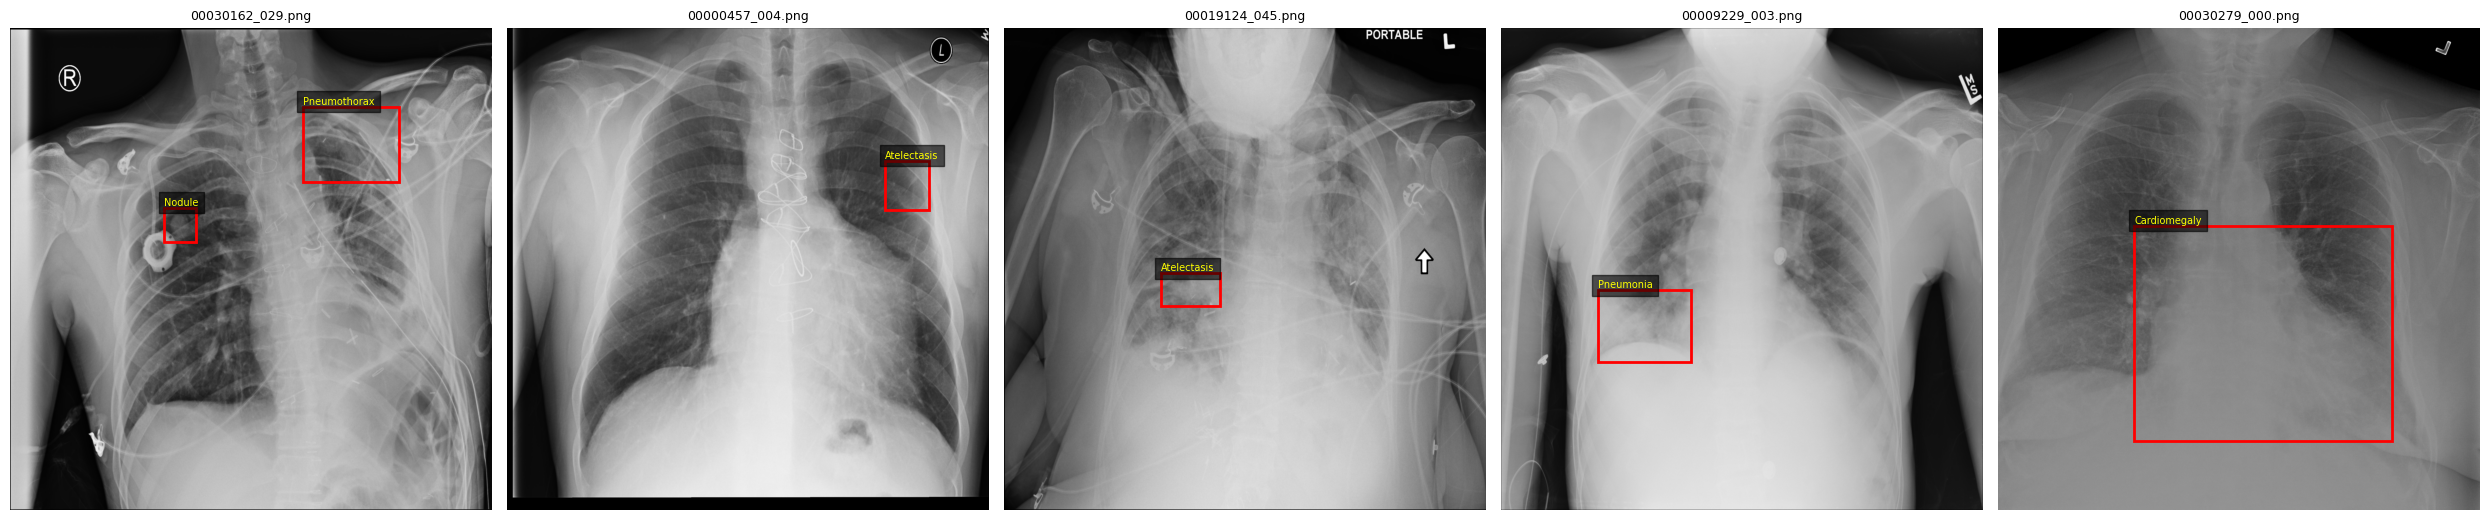

In [20]:
# CELL 04 — Visualise NIH X-rays with Bounding Boxes

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random
import os

# Select 5 unique annotated images
random.seed(42)

sample_images = random.sample(
    list(bbox_df["Image Index"].unique()),
    5
)

fig, axes = plt.subplots(1, 5, figsize=(25, 7))

for ax, image_name in zip(axes, sample_images):

    # Retrieve image path
    image_path = image_locations[image_name]

    # Load image
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    ax.imshow(image, cmap="gray")

    # Get bounding boxes for this image
    image_boxes = bbox_df[
        bbox_df["Image Index"] == image_name
    ]

    for _, row in image_boxes.iterrows():

        x = float(row["x"])
        y = float(row["y"])
        w = float(row["w"])
        h = float(row["h"])

        # Draw bounding box
        rect = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        # Add finding label
        ax.text(
            x,
            max(y - 5, 0),
            str(row["Finding Label"]),
            color="yellow",
            fontsize=7,
            bbox=dict(facecolor="black", alpha=0.6)
        )

    ax.set_title(image_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
# CELL 05 — Validate Bounding Box Coordinates

invalid_boxes = []

for _, row in bbox_df.iterrows():

    image_name = row["Image Index"]
    image_path = image_locations[image_name]

    with Image.open(image_path) as img:
        width, height = img.size

    x = float(row["x"])
    y = float(row["y"])
    w = float(row["w"])
    h = float(row["h"])

    if (
        x < 0 or
        y < 0 or
        w <= 0 or
        h <= 0 or
        x + w > width or
        y + h > height
    ):
        invalid_boxes.append({
            "Image": image_name,
            "Image Width": width,
            "Image Height": height,
            "x": x,
            "y": y,
            "w": w,
            "h": h
        })

print("Total bounding boxes:", len(bbox_df))
print("Invalid bounding boxes:", len(invalid_boxes))

if invalid_boxes:
    display(pd.DataFrame(invalid_boxes).head(10))
else:
    print("All bounding boxes are within image boundaries.")

Total bounding boxes: 984
Invalid bounding boxes: 0
All bounding boxes are within image boundaries.


Finding-wise annotation summary:


,Total_Bounding_Boxes,Unique_Images
Finding Label,,
Atelectasis,180,180
Effusion,153,153
Cardiomegaly,146,146
Infiltrate,123,123
Pneumonia,120,120
Pneumothorax,98,98
Mass,85,85
Nodule,79,79



Image-level annotation summary:
Total unique images: 880
Images with one box: 787
Images with multiple boxes: 93
Maximum boxes in a single image: 4


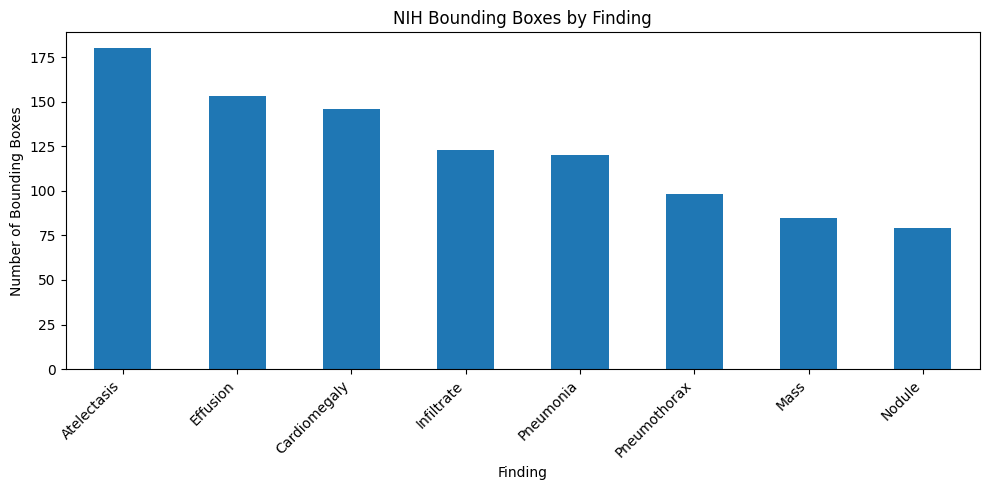

In [22]:
# CELL 06 — Inspect NIH Bounding Box Annotations by Finding

# Count bounding boxes for each finding
finding_summary = (
    bbox_df.groupby("Finding Label")
    .agg(
        Total_Bounding_Boxes=("Image Index", "count"),
        Unique_Images=("Image Index", "nunique")
    )
    .sort_values("Total_Bounding_Boxes", ascending=False)
)

print("Finding-wise annotation summary:")
display(finding_summary)

# Count bounding boxes per image
boxes_per_image = bbox_df.groupby("Image Index").size()

print("\nImage-level annotation summary:")
print("Total unique images:", len(boxes_per_image))
print("Images with one box:", (boxes_per_image == 1).sum())
print("Images with multiple boxes:", (boxes_per_image > 1).sum())
print("Maximum boxes in a single image:", boxes_per_image.max())

# Plot finding distribution
finding_summary["Total_Bounding_Boxes"].plot(
    kind="bar",
    figsize=(10, 5),
    title="NIH Bounding Boxes by Finding"
)

plt.xlabel("Finding")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
# CELL 07 — Compare NIH Labels with Project Findings

project_findings = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

nih_findings = sorted(bbox_df["Finding Label"].unique())

print("PROJECT TARGET FINDINGS:")
for finding in project_findings:
    print("-", finding)

print("\nNIH BOUNDING BOX FINDINGS:")
for finding in nih_findings:
    print("-", finding)

# Exact matching only
exact_matches = set(project_findings) & set(nih_findings)

print("\nEXACT MATCHES:")
for finding in sorted(exact_matches):
    print("-", finding)

print("\nPROJECT FINDINGS WITHOUT EXACT NIH BOX LABELS:")
for finding in project_findings:
    if finding not in exact_matches:
        print("-", finding)

PROJECT TARGET FINDINGS:
- Pleural Effusion
- Cardiomegaly
- Pneumothorax
- Atelectasis
- Consolidation
- Lung Lesion

NIH BOUNDING BOX FINDINGS:
- Atelectasis
- Cardiomegaly
- Effusion
- Infiltrate
- Mass
- Nodule
- Pneumonia
- Pneumothorax

EXACT MATCHES:
- Atelectasis
- Cardiomegaly
- Pneumothorax

PROJECT FINDINGS WITHOUT EXACT NIH BOX LABELS:
- Pleural Effusion
- Consolidation
- Lung Lesion


In [24]:
# CELL 08 — Define Localization Label Mapping

# Explicit mapping between project findings and NIH box annotations
localization_mapping = {
    "Atelectasis": ["Atelectasis"],
    "Cardiomegaly": ["Cardiomegaly"],
    "Pneumothorax": ["Pneumothorax"],
    "Pleural Effusion": ["Effusion"],
    "Consolidation": [],
    "Lung Lesion": []
}

print("LOCALIZATION LABEL MAPPING")
print("-" * 65)

for project_finding, nih_labels in localization_mapping.items():

    if nih_labels:
        print(f"{project_finding}: {nih_labels}")
    else:
        print(f"{project_finding}: No approved NIH box mapping")

# Identify eligible NIH annotations
eligible_nih_labels = {
    label
    for labels in localization_mapping.values()
    for label in labels
}

localization_bbox_df = bbox_df[
    bbox_df["Finding Label"].isin(eligible_nih_labels)
].copy()

print("\nLOCALIZATION DATASET SUMMARY")
print("-" * 65)

print("Eligible NIH finding labels:", sorted(eligible_nih_labels))
print("Eligible bounding boxes:", len(localization_bbox_df))
print(
    "Unique annotated images:",
    localization_bbox_df["Image Index"].nunique()
)

print("\nBounding boxes by eligible finding:")
display(
    localization_bbox_df.groupby("Finding Label")
    .agg(
        Bounding_Boxes=("Image Index", "count"),
        Unique_Images=("Image Index", "nunique")
    )
)

LOCALIZATION LABEL MAPPING
-----------------------------------------------------------------
Atelectasis: ['Atelectasis']
Cardiomegaly: ['Cardiomegaly']
Pneumothorax: ['Pneumothorax']
Pleural Effusion: ['Effusion']
Consolidation: No approved NIH box mapping
Lung Lesion: No approved NIH box mapping

LOCALIZATION DATASET SUMMARY
-----------------------------------------------------------------
Eligible NIH finding labels: ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Pneumothorax']
Eligible bounding boxes: 577
Unique annotated images: 550

Bounding boxes by eligible finding:


,Bounding_Boxes,Unique_Images
Finding Label,,
Atelectasis,180,180
Cardiomegaly,146,146
Effusion,153,153
Pneumothorax,98,98


In [25]:
# CELL 09 — Inspect NIH Image Dimensions

from collections import Counter
from PIL import Image

image_dimensions = {}

for image_name in localization_bbox_df["Image Index"].unique():

    image_path = image_locations[image_name]

    with Image.open(image_path) as img:
        image_dimensions[image_name] = img.size

dimension_counts = Counter(image_dimensions.values())

print("IMAGE DIMENSION SUMMARY")
print("-" * 50)

print("Total images inspected:", len(image_dimensions))
print("\nImage dimensions and frequencies:")

for dimensions, count in dimension_counts.most_common():
    print(f"{dimensions}: {count} images")

print("\nUnique image dimensions:", len(dimension_counts))

if len(dimension_counts) == 1:
    print("\nAll images have identical dimensions.")
else:
    print("\nImages have varying dimensions.")

IMAGE DIMENSION SUMMARY
--------------------------------------------------
Total images inspected: 550

Image dimensions and frequencies:
(1024, 1024): 550 images

Unique image dimensions: 1

All images have identical dimensions.


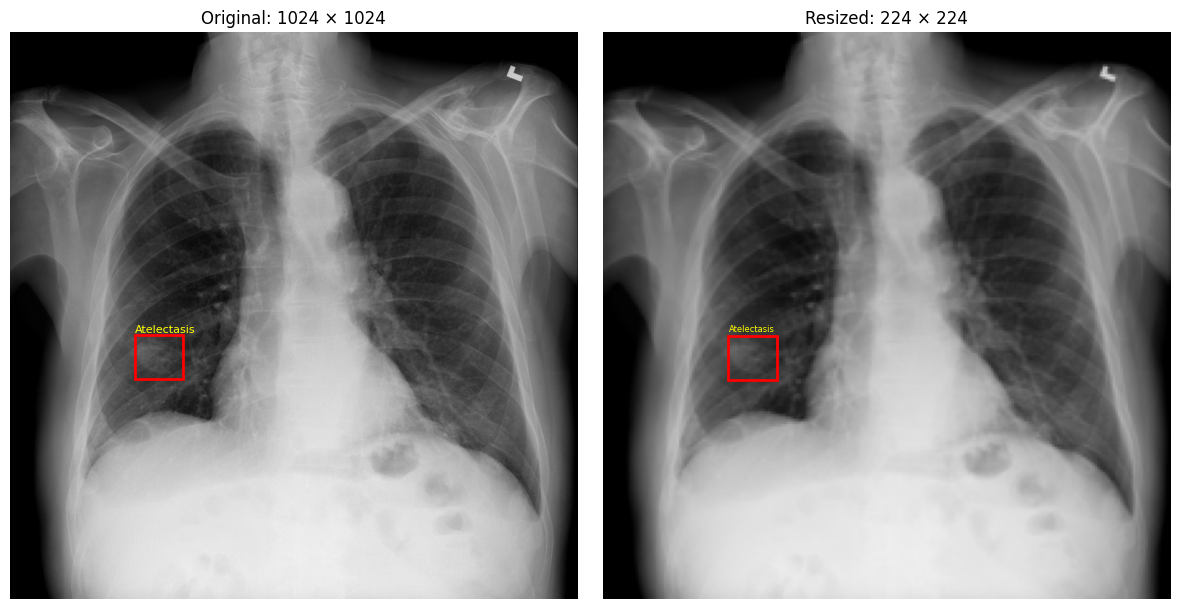

Image: 00013118_008.png
Original dimensions: (1024, 1024)
Resized dimensions: (224, 224)
Scale X: 0.21875
Scale Y: 0.21875
Number of bounding boxes: 1


In [26]:
# CELL 10 — Verify Bounding Box Coordinate Transformation

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Target image size
TARGET_SIZE = 224

# Select one annotated image
sample_image_name = localization_bbox_df["Image Index"].iloc[0]

sample_image_path = image_locations[sample_image_name]

# Load original image
original_image = Image.open(sample_image_path).convert("RGB")

original_width, original_height = original_image.size

# Resize image
resized_image = original_image.resize(
    (TARGET_SIZE, TARGET_SIZE)
)

# Calculate scaling factors
scale_x = TARGET_SIZE / original_width
scale_y = TARGET_SIZE / original_height

# Get bounding boxes
sample_boxes = localization_bbox_df[
    localization_bbox_df["Image Index"] == sample_image_name
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Original image with original boxes
axes[0].imshow(original_image)

# Resized image with transformed boxes
axes[1].imshow(resized_image)

for _, row in sample_boxes.iterrows():

    x = float(row["x"])
    y = float(row["y"])
    w = float(row["w"])
    h = float(row["h"])

    # Original bounding box
    original_rect = patches.Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    axes[0].add_patch(original_rect)

    # Transform coordinates
    new_x = x * scale_x
    new_y = y * scale_y
    new_w = w * scale_x
    new_h = h * scale_y

    resized_rect = patches.Rectangle(
        (new_x, new_y), new_w, new_h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    axes[1].add_patch(resized_rect)

    axes[0].text(
        x, max(y - 5, 0),
        row["Finding Label"],
        color="yellow",
        fontsize=8
    )

    axes[1].text(
        new_x, max(new_y - 2, 0),
        row["Finding Label"],
        color="yellow",
        fontsize=6
    )

axes[0].set_title(f"Original: {original_width} × {original_height}")
axes[1].set_title(f"Resized: {TARGET_SIZE} × {TARGET_SIZE}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", sample_image_name)
print("Original dimensions:", original_image.size)
print("Resized dimensions:", resized_image.size)
print("Scale X:", scale_x)
print("Scale Y:", scale_y)
print("Number of bounding boxes:", len(sample_boxes))

In [27]:
# CELL 11 — Verify Bounding Box Transformation Numerically

sample_box = sample_boxes.iloc[0]

# Original coordinates
original_box = {
    "x": float(sample_box["x"]),
    "y": float(sample_box["y"]),
    "w": float(sample_box["w"]),
    "h": float(sample_box["h"])
}

# Transformed coordinates
transformed_box = {
    "x": original_box["x"] * scale_x,
    "y": original_box["y"] * scale_y,
    "w": original_box["w"] * scale_x,
    "h": original_box["h"] * scale_y
}

# Reverse transformation
recovered_box = {
    "x": transformed_box["x"] / scale_x,
    "y": transformed_box["y"] / scale_y,
    "w": transformed_box["w"] / scale_x,
    "h": transformed_box["h"] / scale_y
}

print("Original bounding box:")
print(original_box)

print("\nTransformed bounding box (224 × 224):")
print(transformed_box)

print("\nRecovered bounding box:")
print(recovered_box)

# Numerical error
max_error = max(
    abs(original_box[key] - recovered_box[key])
    for key in original_box
)

print("\nMaximum reconstruction error:", max_error)

assert max_error < 1e-6, "Bounding-box transformation check failed!"

print("SUCCESS: Coordinate transformation is reversible.")

Original bounding box:
{'x': 225.084745762712, 'y': 547.019216763771, 'w': 86.7796610169491, 'h': 79.1864406779661}

Transformed bounding box (224 × 224):
{'x': 49.23728813559325, 'y': 119.66045366707492, 'w': 18.983050847457616, 'h': 17.322033898305087}

Recovered bounding box:
{'x': 225.084745762712, 'y': 547.019216763771, 'w': 86.7796610169491, 'h': 79.1864406779661}

Maximum reconstruction error: 0.0
SUCCESS: Coordinate transformation is reversible.


In [28]:
# CELL 12 — Create Localization Annotation Dataset

localization_records = []

for _, row in localization_bbox_df.iterrows():

    image_name = row["Image Index"]
    image_path = image_locations[image_name]

    x = float(row["x"])
    y = float(row["y"])
    w = float(row["w"])
    h = float(row["h"])

    # Original image dimensions
    image_width, image_height = image_dimensions[image_name]

    # Map NIH finding to project finding
    nih_label = row["Finding Label"]

    if nih_label == "Effusion":
        project_label = "Pleural Effusion"
    else:
        project_label = nih_label

    localization_records.append({
        "image_name": image_name,
        "image_path": image_path,
        "nih_label": nih_label,
        "project_label": project_label,

        # Original pixel coordinates
        "x": x,
        "y": y,
        "w": w,
        "h": h,

        # Normalized coordinates
        "x_norm": x / image_width,
        "y_norm": y / image_height,
        "w_norm": w / image_width,
        "h_norm": h / image_height
    })

localization_dataset = pd.DataFrame(localization_records)

print("Localization dataset shape:", localization_dataset.shape)

print("\nProject finding distribution:")
display(localization_dataset["project_label"].value_counts())

print("\nDataset preview:")
display(localization_dataset.head())

print("\nMissing values:")
display(localization_dataset.isnull().sum())

Localization dataset shape: (577, 12)

Project finding distribution:


project_label
Atelectasis         180
Pleural Effusion    153
Cardiomegaly        146
Pneumothorax         98
Name: count, dtype: int64


Dataset preview:


,image_name,image_path,nih_label,project_label,x,y,w,h,x_norm,y_norm,w_norm,h_norm
0,00013118_008.png,/kaggle/input/datasets/biditdas06/nih-chestxra...,Atelectasis,Atelectasis,225.084746,547.019217,86.779661,79.186441,0.219809,0.534198,0.084746,0.077331
1,00014716_007.png,/kaggle/input/datasets/biditdas06/nih-chestxra...,Atelectasis,Atelectasis,686.101695,131.543498,185.491525,313.491525,0.670021,0.128460,0.181144,0.306144
2,00029817_009.png,/kaggle/input/datasets/biditdas06/nih-chestxra...,Atelectasis,Atelectasis,221.830508,317.053115,155.118644,216.949153,0.216631,0.309622,0.151483,0.211864
3,00014687_001.png,/kaggle/input/datasets/biditdas06/nih-chestxra...,Atelectasis,Atelectasis,726.237288,494.951420,141.016949,55.322034,0.709216,0.483351,0.137712,0.054025
4,00017877_001.png,/kaggle/input/datasets/biditdas06/nih-chestxra...,Atelectasis,Atelectasis,660.067797,569.780787,200.677966,78.101695,0.644597,0.556427,0.195975,0.076271



Missing values:


image_name       0
image_path       0
nih_label        0
project_label    0
x                0
y                0
w                0
h                0
x_norm           0
y_norm           0
w_norm           0
h_norm           0
dtype: int64

In [29]:
# CELL 13 — Validate Normalized Bounding Boxes

# Check normalized coordinate ranges
coordinate_columns = [
    "x_norm", "y_norm", "w_norm", "h_norm"
]

print("NORMALIZED COORDINATE VALIDATION")
print("-" * 50)

display(localization_dataset[coordinate_columns].describe())

# Check coordinate ranges
invalid_normalized = localization_dataset[
    (localization_dataset["x_norm"] < 0) |
    (localization_dataset["y_norm"] < 0) |
    (localization_dataset["w_norm"] <= 0) |
    (localization_dataset["h_norm"] <= 0) |
    (localization_dataset["x_norm"] + localization_dataset["w_norm"] > 1) |
    (localization_dataset["y_norm"] + localization_dataset["h_norm"] > 1)
]

print("\nTotal annotation records:", len(localization_dataset))
print("Invalid normalized boxes:", len(invalid_normalized))

# Verify project labels
print("\nProject finding categories:")
print(sorted(localization_dataset["project_label"].unique()))

# Final validation
assert len(invalid_normalized) == 0, "Invalid normalized boxes detected!"
assert localization_dataset[coordinate_columns].notnull().all().all()

print("\nSUCCESS: All normalized bounding boxes are valid.")

NORMALIZED COORDINATE VALIDATION
--------------------------------------------------


,x_norm,y_norm,w_norm,h_norm
count,577.000000,577.000000,577.000000,577.000000
mean,0.375492,0.395477,0.275651,0.259707
std,0.216062,0.172404,0.159072,0.159152
min,0.005291,0.012537,0.026667,0.021111
25%,0.190944,0.281481,0.151323,0.116525
50%,0.330159,0.409693,0.227778,0.236667
75%,0.577860,0.512537,0.422669,0.375661
max,0.871292,0.856427,0.880000,0.852910



Total annotation records: 577
Invalid normalized boxes: 0

Project finding categories:
['Atelectasis', 'Cardiomegaly', 'Pleural Effusion', 'Pneumothorax']

SUCCESS: All normalized bounding boxes are valid.


In [30]:
# CELL 14 — Export Localization Annotations

import os

output_dir = "/kaggle/working/m3_outputs"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "nih_localization_annotations.csv"
)

# Export validated localization dataset
localization_dataset.to_csv(
    output_path,
    index=False
)

# Verify exported file
exported_df = pd.read_csv(output_path)

print("EXPORT SUMMARY")
print("-" * 50)

print("File:", output_path)
print("File exists:", os.path.exists(output_path))
print("Exported records:", len(exported_df))
print("Exported columns:", len(exported_df.columns))
print("Unique images:", exported_df["image_name"].nunique())

print("\nExported file size:",
      round(os.path.getsize(output_path) / 1024, 2), "KB")

# Verify exported data
assert len(exported_df) == len(localization_dataset)
assert exported_df.isnull().sum().sum() == 0

print("\nSUCCESS: Localization annotations exported and verified.")

EXPORT SUMMARY
--------------------------------------------------
File: /kaggle/working/m3_outputs/nih_localization_annotations.csv
File exists: True
Exported records: 577
Exported columns: 12
Unique images: 550

Exported file size: 152.42 KB

SUCCESS: Localization annotations exported and verified.


In [31]:
# CELL 15 — Extract Patient IDs and Inspect Dataset Grouping

# NIH filenames follow the format: patientID_studyNumber.png

localization_dataset["patient_id"] = (
    localization_dataset["image_name"]
    .str.split("_")
    .str[0]
)

# Image-level patient summary
patient_summary = (
    localization_dataset.groupby("patient_id")
    .agg(
        unique_images=("image_name", "nunique"),
        bounding_boxes=("image_name", "count")
    )
    .sort_values("unique_images", ascending=False)
)

print("PATIENT-LEVEL DATASET SUMMARY")
print("-" * 50)

print("Total annotation records:", len(localization_dataset))
print("Unique images:", localization_dataset["image_name"].nunique())
print("Unique patients:", localization_dataset["patient_id"].nunique())

print(
    "Patients with multiple annotated images:",
    (patient_summary["unique_images"] > 1).sum()
)

print(
    "Maximum annotated images per patient:",
    patient_summary["unique_images"].max()
)

print("\nPatients with the most annotated images:")
display(patient_summary.head(10))

# Check whether any image is associated with multiple patient IDs
patient_mapping_check = (
    localization_dataset.groupby("image_name")["patient_id"].nunique()
)

print(
    "\nImages associated with multiple patient IDs:",
    (patient_mapping_check > 1).sum()
)

assert (patient_mapping_check == 1).all()

print("\nSUCCESS: Patient IDs extracted and image grouping verified.")

PATIENT-LEVEL DATASET SUMMARY
--------------------------------------------------
Total annotation records: 577
Unique images: 550
Unique patients: 471
Patients with multiple annotated images: 55
Maximum annotated images per patient: 5

Patients with the most annotated images:


,unique_images,bounding_boxes
patient_id,,
00004344,5,5
00004342,4,4
00025252,4,5
00005089,3,4
00005532,3,3
00025787,3,3
00025368,3,3
00010767,3,3
00022572,3,3



Images associated with multiple patient IDs: 0

SUCCESS: Patient IDs extracted and image grouping verified.


In [32]:
# CELL 16 — Patient-Level Localization Dataset Summary

# Patient-level finding distribution
patient_finding_summary = (
    localization_dataset
    .groupby("project_label")
    .agg(
        unique_patients=("patient_id", "nunique"),
        unique_images=("image_name", "nunique"),
        bounding_boxes=("image_name", "count")
    )
    .sort_values("bounding_boxes", ascending=False)
)

print("PATIENT-LEVEL FINDING SUMMARY")
print("-" * 60)
display(patient_finding_summary)

# Number of different findings annotated per patient
findings_per_patient = (
    localization_dataset
    .groupby("patient_id")["project_label"]
    .nunique()
)

print("\nMULTI-FINDING PATIENT SUMMARY")
print("-" * 60)

print("Total patients:", len(findings_per_patient))
print(
    "Patients with annotations for multiple findings:",
    (findings_per_patient > 1).sum()
)
print(
    "Maximum different findings in one patient:",
    findings_per_patient.max()
)

# Overall dataset summary
print("\nOVERALL SUMMARY")
print("-" * 60)

print("Unique patients:", localization_dataset["patient_id"].nunique())
print("Unique images:", localization_dataset["image_name"].nunique())
print("Bounding boxes:", len(localization_dataset))
print("Finding categories:", localization_dataset["project_label"].nunique())

PATIENT-LEVEL FINDING SUMMARY
------------------------------------------------------------


,unique_patients,unique_images,bounding_boxes
project_label,,,
Atelectasis,167,180,180
Pleural Effusion,142,153,153
Cardiomegaly,128,146,146
Pneumothorax,82,98,98



MULTI-FINDING PATIENT SUMMARY
------------------------------------------------------------
Total patients: 471
Patients with annotations for multiple findings: 46
Maximum different findings in one patient: 3

OVERALL SUMMARY
------------------------------------------------------------
Unique patients: 471
Unique images: 550
Bounding boxes: 577
Finding categories: 4


In [33]:
# CELL 17 — Create Patient-Level Train/Validation/Test Split

from sklearn.model_selection import train_test_split

# Get unique patient IDs
unique_patients = localization_dataset["patient_id"].unique()

# First split: 70% train, 30% temporary
train_patients, temp_patients = train_test_split(
    unique_patients,
    test_size=0.30,
    random_state=42
)

# Second split: divide temporary set equally
val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42
)

# Assign each annotation record to a patient-level split
localization_dataset["split"] = (
    localization_dataset["patient_id"].map(
        lambda pid:
            "train" if pid in train_patients
            else "validation" if pid in val_patients
            else "test"
    )
)

# Display split statistics
split_summary = (
    localization_dataset.groupby("split")
    .agg(
        patients=("patient_id", "nunique"),
        images=("image_name", "nunique"),
        bounding_boxes=("image_name", "count")
    )
    .reindex(["train", "validation", "test"])
)

print("PATIENT-LEVEL SPLIT SUMMARY")
display(split_summary)

# Verify no patient leakage
train_set = set(train_patients)
val_set = set(val_patients)
test_set = set(test_patients)

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

print("\nPatient leakage check: PASSED")
print("Train/validation/test patient overlap: 0")

PATIENT-LEVEL SPLIT SUMMARY


,patients,images,bounding_boxes
split,,,
train,329,377,398
validation,71,87,91
test,71,86,88



Patient leakage check: PASSED
Train/validation/test patient overlap: 0


In [34]:
# CELL 18 — Check Finding Distribution Across Splits

split_finding_summary = (
    localization_dataset
    .groupby(["split", "project_label"])
    .agg(
        patients=("patient_id", "nunique"),
        images=("image_name", "nunique"),
        bounding_boxes=("image_name", "count")
    )
    .reset_index()
)

print("FINDING DISTRIBUTION ACROSS SPLITS")
print("-" * 60)

display(
    split_finding_summary.pivot(
        index="project_label",
        columns="split",
        values="images"
    ).fillna(0).astype(int)
)

print("\nPATIENT DISTRIBUTION ACROSS SPLITS")
display(
    split_finding_summary.pivot(
        index="project_label",
        columns="split",
        values="patients"
    ).fillna(0).astype(int)
)

print("\nBOUNDING BOX DISTRIBUTION ACROSS SPLITS")
display(
    split_finding_summary.pivot(
        index="project_label",
        columns="split",
        values="bounding_boxes"
    ).fillna(0).astype(int)
)

FINDING DISTRIBUTION ACROSS SPLITS
------------------------------------------------------------


split,test,train,validation
project_label,,,
Atelectasis,29,116,35
Cardiomegaly,19,111,16
Pleural Effusion,20,113,20
Pneumothorax,20,58,20



PATIENT DISTRIBUTION ACROSS SPLITS


split,test,train,validation
project_label,,,
Atelectasis,28,107,32
Cardiomegaly,16,98,14
Pleural Effusion,19,104,19
Pneumothorax,15,51,16



BOUNDING BOX DISTRIBUTION ACROSS SPLITS


split,test,train,validation
project_label,,,
Atelectasis,29,116,35
Cardiomegaly,19,111,16
Pleural Effusion,20,113,20
Pneumothorax,20,58,20


In [35]:
# CELL 19 — Prepare Patient-Level Multilabel Stratification

import numpy as np
import pandas as pd

# Create one row per patient with binary finding indicators
patient_labels = (
    localization_dataset
    .pivot_table(
        index="patient_id",
        columns="project_label",
        values="image_name",
        aggfunc="count",
        fill_value=0
    )
)

# Convert annotation counts into binary labels
patient_labels = (patient_labels > 0).astype(int)

# Ensure all four finding columns exist
finding_columns = [
    "Atelectasis",
    "Cardiomegaly",
    "Pleural Effusion",
    "Pneumothorax"
]

patient_labels = patient_labels.reindex(
    columns=finding_columns,
    fill_value=0
)

print("PATIENT-LEVEL MULTILABEL MATRIX")
print("-" * 60)

print("Number of patients:", len(patient_labels))
print("Number of finding categories:", len(finding_columns))

print("\nFinding distribution across patients:")
display(patient_labels.sum().to_frame("Patients"))

print("\nNumber of findings per patient:")
display(
    patient_labels.sum(axis=1)
    .value_counts()
    .sort_index()
    .to_frame("Number of patients")
)

print("\nSample patient-label matrix:")
display(patient_labels.head(10))

assert len(patient_labels) == 471
assert patient_labels.index.is_unique

print("\nSUCCESS: Patient-level multilabel matrix prepared.")

PATIENT-LEVEL MULTILABEL MATRIX
------------------------------------------------------------
Number of patients: 471
Number of finding categories: 4

Finding distribution across patients:


,Patients
project_label,
Atelectasis,167
Cardiomegaly,128
Pleural Effusion,142
Pneumothorax,82



Number of findings per patient:


,Number of patients
1,425
2,44
3,2



Sample patient-label matrix:


project_label,Atelectasis,Cardiomegaly,Pleural Effusion,Pneumothorax
patient_id,,,,
00000072,1,0,0,0
00000147,1,0,0,0
00000149,1,0,0,0
00000181,1,0,0,0
00000211,1,1,0,0
00000344,0,0,1,0
00000377,0,1,0,0
00000398,0,1,0,0
00000457,1,0,0,0



SUCCESS: Patient-level multilabel matrix prepared.


In [36]:
# CELL 20 — Create Iterative Multilabel Patient Split

# Install the package if it is not already available
try:
    from iterstrat.ml_stratifiers import (
        MultilabelStratifiedShuffleSplit
    )
    print("Iterative stratification package is available.")

except ImportError:
    %pip install -q iterative-stratification

    from iterstrat.ml_stratifiers import (
        MultilabelStratifiedShuffleSplit
    )

# Prepare patient IDs and multilabel matrix
X = patient_labels.index.to_numpy().reshape(-1, 1)
y = patient_labels.to_numpy()

# First split: 70% training, 30% temporary
split_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(split_1.split(X, y))

X_train = X[train_idx]
y_train = y[train_idx]

X_temp = X[temp_idx]
y_temp = y[temp_idx]

# Second split: divide temporary set into validation and test
split_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(split_2.split(X_temp, y_temp))

# Extract patient IDs
train_patients_new = set(X_train.flatten())
val_patients_new = set(X_temp[val_idx].flatten())
test_patients_new = set(X_temp[test_idx].flatten())

# Create a separate dataset with the new split
localization_dataset_stratified = localization_dataset.drop(
    columns=["split"],
    errors="ignore"
).copy()

def assign_split(patient_id):
    if patient_id in train_patients_new:
        return "train"
    elif patient_id in val_patients_new:
        return "validation"
    else:
        return "test"

localization_dataset_stratified["split"] = (
    localization_dataset_stratified["patient_id"].map(assign_split)
)

# Verify patient leakage
assert train_patients_new.isdisjoint(val_patients_new)
assert train_patients_new.isdisjoint(test_patients_new)
assert val_patients_new.isdisjoint(test_patients_new)

print("\nPATIENT-LEVEL STRATIFIED SPLIT")
print("-" * 60)

print("Training patients:", len(train_patients_new))
print("Validation patients:", len(val_patients_new))
print("Test patients:", len(test_patients_new))

print("\nPatient leakage check: PASSED")

# Finding distribution
stratified_summary = (
    localization_dataset_stratified
    .groupby(["split", "project_label"])
    .agg(
        patients=("patient_id", "nunique"),
        images=("image_name", "nunique"),
        bounding_boxes=("image_name", "count")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                ["train", "validation", "test"],
                finding_columns
            ],
            names=["split", "project_label"]
        )
    )
)

print("\nFINDING DISTRIBUTION")
display(stratified_summary)

Note: you may need to restart the kernel to use updated packages.

PATIENT-LEVEL STRATIFIED SPLIT
------------------------------------------------------------
Training patients: 329
Validation patients: 70
Test patients: 72

Patient leakage check: PASSED

FINDING DISTRIBUTION


patients  images  bounding_boxes
split      project_label                                     
train      Atelectasis            117     124             124
           Cardiomegaly            89      99              99
           Pleural Effusion        99     110             110
           Pneumothorax            57      67              67
validation Atelectasis             25      26              26
           Cardiomegaly            19      20              20
           Pleural Effusion        21      21              21
           Pneumothorax            13      16              16
test       Atelectasis             25      30              30
           Cardiomegaly            20      27              27
           Pleural Effusion        22      22              22
           Pneumothorax            12      15              15

In [37]:
# CELL 21 — Compare Random and Stratified Splits

random_counts = (
    localization_dataset
    .groupby(["split", "project_label"])["patient_id"]
    .nunique()
    .unstack(fill_value=0)
)

stratified_counts = (
    localization_dataset_stratified
    .groupby(["split", "project_label"])["patient_id"]
    .nunique()
    .unstack(fill_value=0)
)

for split_name in ["train", "validation", "test"]:

    comparison = pd.DataFrame({
        "Random Split": random_counts.loc[split_name],
        "Stratified Split": stratified_counts.loc[split_name]
    })

    print(f"\n{split_name.upper()} — PATIENT DISTRIBUTION")
    display(comparison)

# Verify that every image belongs to exactly one split
split_check = (
    localization_dataset_stratified
    .groupby("image_name")["split"]
    .nunique()
)

assert (split_check == 1).all()

# Verify that all 471 patients are assigned
assigned_patients = (
    localization_dataset_stratified["patient_id"].nunique()
)

assert assigned_patients == 471

print("\nFINAL SPLIT COMPARISON CHECKS")
print("Unique patients assigned:", assigned_patients)
print("Images assigned to multiple splits:", (split_check > 1).sum())
print("Patient leakage:", len(
    train_patients_new & val_patients_new
) + len(
    train_patients_new & test_patients_new
) + len(
    val_patients_new & test_patients_new
))

print("\nSUCCESS: Split comparison and integrity checks passed.")


TRAIN — PATIENT DISTRIBUTION


,Random Split,Stratified Split
project_label,,
Atelectasis,107,117
Cardiomegaly,98,89
Pleural Effusion,104,99
Pneumothorax,51,57



VALIDATION — PATIENT DISTRIBUTION


,Random Split,Stratified Split
project_label,,
Atelectasis,32,25
Cardiomegaly,14,19
Pleural Effusion,19,21
Pneumothorax,16,13



TEST — PATIENT DISTRIBUTION


,Random Split,Stratified Split
project_label,,
Atelectasis,28,25
Cardiomegaly,16,20
Pleural Effusion,19,22
Pneumothorax,15,12



FINAL SPLIT COMPARISON CHECKS
Unique patients assigned: 471
Images assigned to multiple splits: 0
Patient leakage: 0

SUCCESS: Split comparison and integrity checks passed.


In [38]:
# CELL 22 — Save Final Localization Dataset and Split Assignments

import os
import json

output_dir = "/kaggle/working/m3_outputs"
os.makedirs(output_dir, exist_ok=True)

# 1. Save complete localization dataset
annotations_path = os.path.join(
    output_dir,
    "nih_localization_annotations_final.csv"
)

localization_dataset_stratified.to_csv(
    annotations_path,
    index=False
)

# 2. Save patient-level split assignments
patient_split_df = pd.DataFrame({
    "patient_id": (
        list(train_patients_new)
        + list(val_patients_new)
        + list(test_patients_new)
    ),
    "split": (
        ["train"] * len(train_patients_new)
        + ["validation"] * len(val_patients_new)
        + ["test"] * len(test_patients_new)
    )
})

split_path = os.path.join(
    output_dir,
    "nih_localization_patient_splits.csv"
)

patient_split_df.to_csv(split_path, index=False)

# 3. Save split configuration
split_config = {
    "dataset": "NIH ChestX-ray14 Bounding Box Annotations",
    "random_state": 42,
    "strategy": "Iterative multilabel stratification",
    "train_patients": len(train_patients_new),
    "validation_patients": len(val_patients_new),
    "test_patients": len(test_patients_new),
    "total_patients": 471,
    "total_images": 550,
    "total_bounding_boxes": 577,
    "finding_categories": finding_columns
}

config_path = os.path.join(
    output_dir,
    "nih_localization_split_config.json"
)

with open(config_path, "w") as f:
    json.dump(split_config, f, indent=4)

# 4. Verify saved files
print("FINAL EXPORT SUMMARY")
print("-" * 60)

for path in [annotations_path, split_path, config_path]:
    print(
        os.path.basename(path),
        "| Exists:", os.path.exists(path),
        "| Size:", round(os.path.getsize(path) / 1024, 2), "KB"
    )

# Verify exported annotation dataset
saved_annotations = pd.read_csv(annotations_path)
saved_splits = pd.read_csv(split_path)

assert len(saved_annotations) == 577
assert saved_annotations["patient_id"].nunique() == 471
assert saved_annotations["image_name"].nunique() == 550
assert len(saved_splits) == 471
assert saved_splits["patient_id"].nunique() == 471

print("\nSUCCESS: All localization artifacts saved and verified.")

FINAL EXPORT SUMMARY
------------------------------------------------------------
nih_localization_annotations_final.csv | Exists: True | Size: 161.2 KB
nih_localization_patient_splits.csv | Exists: True | Size: 7.19 KB
nih_localization_split_config.json | Exists: True | Size: 0.43 KB

SUCCESS: All localization artifacts saved and verified.


In [41]:
# CELL 23 — Inspect Attached Dataset Names

import os

input_root = "/kaggle/input/datasets"

for publisher in sorted(os.listdir(input_root)):

    publisher_path = os.path.join(input_root, publisher)

    if not os.path.isdir(publisher_path):
        continue

    print(f"\nPUBLISHER: {publisher}")
    print("-" * 60)

    for dataset_name in sorted(os.listdir(publisher_path)):

        dataset_path = os.path.join(publisher_path, dataset_name)

        if os.path.isdir(dataset_path):
            print(f"Dataset: {dataset_name}")


PUBLISHER: ashery
------------------------------------------------------------
Dataset: chexpert

PUBLISHER: biditdas06
------------------------------------------------------------
Dataset: nih-chestxray14

PUBLISHER: kautilyasagili
------------------------------------------------------------
Dataset: nih-bounding-box-annotations


In [1]:
# CELL 24 — Inspect CheXpert Top-Level Structure

import os

chexpert_root = "/kaggle/input/datasets/ashery/chexpert"

print("CHEXPERT ROOT EXISTS:", os.path.exists(chexpert_root))

for item in sorted(os.listdir(chexpert_root)):

    path = os.path.join(chexpert_root, item)

    if os.path.isdir(path):
        print(f"\n[DIR] {item}")

        # Show only the first 5 entries
        print("Contents:", os.listdir(path)[:5])

    else:
        print(f"[FILE] {item}")

CHEXPERT ROOT EXISTS: True

[DIR] train
Contents: ['patient00001', 'patient00002', 'patient00003', 'patient00004', 'patient00005']
[FILE] train.csv

[DIR] valid
Contents: ['patient64541', 'patient64542', 'patient64543', 'patient64544', 'patient64545']
[FILE] valid.csv


In [2]:
# CELL 25 — Load and Inspect CheXpert Metadata

import pandas as pd
import os

chexpert_root = "/kaggle/input/datasets/ashery/chexpert"

train_csv_path = os.path.join(chexpert_root, "train.csv")
valid_csv_path = os.path.join(chexpert_root, "valid.csv")

# Load metadata
chexpert_train_df = pd.read_csv(train_csv_path)
chexpert_valid_df = pd.read_csv(valid_csv_path)

print("CHEXPERT METADATA SUMMARY")
print("-" * 60)

print("Training records:", len(chexpert_train_df))
print("Validation records:", len(chexpert_valid_df))

print("\nTraining columns:")
print(chexpert_train_df.columns.tolist())

print("\nValidation columns:")
print(chexpert_valid_df.columns.tolist())

print("\nTraining metadata preview:")
display(chexpert_train_df.head())

print("\nValidation metadata preview:")
display(chexpert_valid_df.head())

print("\nTraining missing values:")
display(chexpert_train_df.isnull().sum())

CHEXPERT METADATA SUMMARY
------------------------------------------------------------
Training records: 223414
Validation records: 234

Training columns:
['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']

Validation columns:
['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']

Training metadata preview:


,Path,Sex,Age,Frontal/Lateral,AP/PA,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices
0,CheXpert-v1.0-small/train/patient00001/study1/...,Female,68,Frontal,AP,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0
1,CheXpert-v1.0-small/train/patient00002/study2/...,Female,87,Frontal,AP,NaN,NaN,-1.0,1.0,NaN,-1.0,-1.0,NaN,-1.0,NaN,-1.0,NaN,1.0,NaN
2,CheXpert-v1.0-small/train/patient00002/study1/...,Female,83,Frontal,AP,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN
3,CheXpert-v1.0-small/train/patient00002/study1/...,Female,83,Lateral,NaN,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN
4,CheXpert-v1.0-small/train/patient00003/study1/...,Male,41,Frontal,AP,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN



Validation metadata preview:


,Path,Sex,Age,Frontal/Lateral,AP/PA,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices
0,CheXpert-v1.0-small/valid/patient64541/study1/...,Male,73,Frontal,AP,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,CheXpert-v1.0-small/valid/patient64542/study1/...,Male,70,Frontal,PA,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,CheXpert-v1.0-small/valid/patient64542/study1/...,Male,70,Lateral,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,CheXpert-v1.0-small/valid/patient64543/study1/...,Male,85,Frontal,AP,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,CheXpert-v1.0-small/valid/patient64544/study1/...,Female,42,Frontal,AP,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Training missing values:


Path                               0
Sex                                0
Age                                0
Frontal/Lateral                    0
AP/PA                          32387
No Finding                    201033
Enlarged Cardiomediastinum    178575
Cardiomegaly                  177211
Lung Opacity                  105636
Lung Lesion                   211470
Edema                         137458
Consolidation                 152792
Pneumonia                     195806
Atelectasis                   154971
Pneumothorax                  144480
Pleural Effusion               90203
Pleural Other                 216922
Fracture                      211220
Support Devices               100197
dtype: int64

In [3]:
# CELL 26 — Analyze CheXpert Target Label Distributions

target_findings = [
    "Cardiomegaly",
    "Lung Lesion",
    "Consolidation",
    "Atelectasis",
    "Pneumothorax",
    "Pleural Effusion"
]

def analyze_labels(df, dataset_name):

    summary = []

    for finding in target_findings:

        counts = df[finding].value_counts(dropna=False)

        summary.append({
            "Finding": finding,
            "Positive (1)": counts.get(1.0, 0),
            "Negative (0)": counts.get(0.0, 0),
            "Uncertain (-1)": counts.get(-1.0, 0),
            "Missing (NaN)": df[finding].isna().sum()
        })

    result = pd.DataFrame(summary)

    print(f"\n{dataset_name.upper()} LABEL DISTRIBUTION")
    print("-" * 70)
    display(result)

    return result


train_label_summary = analyze_labels(
    chexpert_train_df,
    "CheXpert Training"
)

valid_label_summary = analyze_labels(
    chexpert_valid_df,
    "CheXpert Validation"
)

print("\nVIEW DISTRIBUTION")
print("-" * 70)

print("Training:")
display(chexpert_train_df["Frontal/Lateral"].value_counts(dropna=False))

print("Validation:")
display(chexpert_valid_df["Frontal/Lateral"].value_counts(dropna=False))


CHEXPERT TRAINING LABEL DISTRIBUTION
----------------------------------------------------------------------


,Finding,Positive (1),Negative (0),Uncertain (-1),Missing (NaN)
0,Cardiomegaly,27000,11116,8087,177211
1,Lung Lesion,9186,1270,1488,211470
2,Consolidation,14783,28097,27742,152792
3,Atelectasis,33376,1328,33739,154971
4,Pneumothorax,19448,56341,3145,144480
5,Pleural Effusion,86187,35396,11628,90203



CHEXPERT VALIDATION LABEL DISTRIBUTION
----------------------------------------------------------------------


,Finding,Positive (1),Negative (0),Uncertain (-1),Missing (NaN)
0,Cardiomegaly,68,166,0,0
1,Lung Lesion,1,233,0,0
2,Consolidation,33,201,0,0
3,Atelectasis,80,154,0,0
4,Pneumothorax,8,226,0,0
5,Pleural Effusion,67,167,0,0



VIEW DISTRIBUTION
----------------------------------------------------------------------
Training:


Frontal/Lateral
Frontal    191027
Lateral     32387
Name: count, dtype: int64

Validation:


Frontal/Lateral
Frontal    202
Lateral     32
Name: count, dtype: int64

In [4]:
# CELL 27 — Verify CheXpert Image Paths

import os

print("CHEXPERT IMAGE PATH VERIFICATION")
print("-" * 60)

for _, row in chexpert_train_df.head(5).iterrows():

    csv_path = row["Path"]

    # Candidate 1: Join the CSV path directly to dataset root
    candidate_1 = os.path.join(chexpert_root, csv_path)

    # Candidate 2: Remove the dataset-name prefix
    relative_path = csv_path.replace(
        "CheXpert-v1.0-small/",
        "",
        1
    )

    candidate_2 = os.path.join(
        chexpert_root,
        relative_path
    )

    print("\nCSV path:", csv_path)
    print("Direct path exists:", os.path.isfile(candidate_1))
    print("Adjusted path exists:", os.path.isfile(candidate_2))

    if os.path.isfile(candidate_2):
        print("Verified image path:", candidate_2)

CHEXPERT IMAGE PATH VERIFICATION
------------------------------------------------------------

CSV path: CheXpert-v1.0-small/train/patient00001/study1/view1_frontal.jpg
Direct path exists: False
Adjusted path exists: True
Verified image path: /kaggle/input/datasets/ashery/chexpert/train/patient00001/study1/view1_frontal.jpg

CSV path: CheXpert-v1.0-small/train/patient00002/study2/view1_frontal.jpg
Direct path exists: False
Adjusted path exists: True
Verified image path: /kaggle/input/datasets/ashery/chexpert/train/patient00002/study2/view1_frontal.jpg

CSV path: CheXpert-v1.0-small/train/patient00002/study1/view1_frontal.jpg
Direct path exists: False
Adjusted path exists: True
Verified image path: /kaggle/input/datasets/ashery/chexpert/train/patient00002/study1/view1_frontal.jpg

CSV path: CheXpert-v1.0-small/train/patient00002/study1/view2_lateral.jpg
Direct path exists: False
Adjusted path exists: True
Verified image path: /kaggle/input/datasets/ashery/chexpert/train/patient00002/stu

In [5]:
# CELL 28 — Validate CheXpert Image Paths and Frontal Image Availability

import os
import pandas as pd

def resolve_chexpert_path(csv_path):
    relative_path = csv_path.replace(
        "CheXpert-v1.0-small/",
        "",
        1
    )
    return os.path.join(chexpert_root, relative_path)


# Create resolved paths
chexpert_train_df["image_path"] = (
    chexpert_train_df["Path"].apply(resolve_chexpert_path)
)

chexpert_valid_df["image_path"] = (
    chexpert_valid_df["Path"].apply(resolve_chexpert_path)
)

# Check all image paths
train_exists = chexpert_train_df["image_path"].map(os.path.isfile)
valid_exists = chexpert_valid_df["image_path"].map(os.path.isfile)

print("CHEXPERT IMAGE PATH VALIDATION")
print("-" * 60)

print("Training records:", len(chexpert_train_df))
print("Training images found:", train_exists.sum())
print("Training images missing:", (~train_exists).sum())

print("\nValidation records:", len(chexpert_valid_df))
print("Validation images found:", valid_exists.sum())
print("Validation images missing:", (~valid_exists).sum())

# View-specific availability
print("\nTRAINING VIEW DISTRIBUTION")
print("-" * 60)

for view in ["Frontal", "Lateral"]:
    subset = chexpert_train_df[
        chexpert_train_df["Frontal/Lateral"] == view
    ]

    print(
        view,
        "| Records:", len(subset),
        "| Existing images:",
        subset["image_path"].map(os.path.isfile).sum()
    )

assert train_exists.all(), "Some training images are missing."
assert valid_exists.all(), "Some validation images are missing."

print("\nSUCCESS: All CheXpert image paths verified.")

KeyboardInterrupt: 

In [6]:
# CELL 28 — Targeted CheXpert Image Path Validation

import os
import numpy as np
from tqdm.auto import tqdm

def resolve_chexpert_path(csv_path):
    relative_path = csv_path.replace(
        "CheXpert-v1.0-small/", "", 1
    )
    return os.path.join(chexpert_root, relative_path)


# Select representative samples
train_sample = chexpert_train_df.sample(
    n=min(20, len(chexpert_train_df)),
    random_state=42
)

valid_sample = chexpert_valid_df.sample(
    n=min(20, len(chexpert_valid_df)),
    random_state=42
)

def validate_sample(df, dataset_name):

    found = 0
    missing = []

    for csv_path in tqdm(
        df["Path"],
        desc=f"Checking {dataset_name}",
        unit="image"
    ):
        image_path = resolve_chexpert_path(csv_path)

        if os.path.isfile(image_path):
            found += 1
        else:
            missing.append(csv_path)

    print(f"\n{dataset_name} results:")
    print("Sampled images:", len(df))
    print("Images found:", found)
    print("Images missing:", len(missing))

    if missing:
        print("Missing examples:", missing[:5])

    return found, missing


train_found, train_missing = validate_sample(
    train_sample, "CheXpert Training"
)

valid_found, valid_missing = validate_sample(
    valid_sample, "CheXpert Validation"
)

assert not train_missing and not valid_missing

# Store resolved paths for later use
chexpert_train_df["image_path"] = (
    chexpert_train_df["Path"].apply(resolve_chexpert_path)
)

chexpert_valid_df["image_path"] = (
    chexpert_valid_df["Path"].apply(resolve_chexpert_path)
)

print("\nSUCCESS: All sampled CheXpert paths verified.")

Checking CheXpert Training:   0%|          | 0/20 [00:00<?, ?image/s]


CheXpert Training results:
Sampled images: 20
Images found: 20
Images missing: 0


Checking CheXpert Validation:   0%|          | 0/20 [00:00<?, ?image/s]


CheXpert Validation results:
Sampled images: 20
Images found: 20
Images missing: 0

SUCCESS: All sampled CheXpert paths verified.


In [7]:
# CELL 29 — Create CheXpert Six-Finding Metadata

from tqdm.auto import tqdm

target_findings = [
    "Cardiomegaly",
    "Lung Lesion",
    "Consolidation",
    "Atelectasis",
    "Pneumothorax",
    "Pleural Effusion"
]

def prepare_chexpert_metadata(df, dataset_name):

    result = df.copy()

    # Extract patient ID from the original CSV path
    result["patient_id"] = (
        result["Path"]
        .str.extract(r"(patient\d+)")
    )

    # Retain only frontal images for the initial pipeline
    result = result[
        result["Frontal/Lateral"] == "Frontal"
    ].copy()

    # Retain the six project findings
    selected_columns = [
        "image_path",
        "patient_id",
        "Sex",
        "Age",
        "Frontal/Lateral",
        "AP/PA"
    ] + target_findings

    result = result[selected_columns].reset_index(drop=True)

    print(f"\n{dataset_name} metadata prepared")
    print("Frontal images:", len(result))
    print("Unique patients:", result["patient_id"].nunique())

    return result


chexpert_train_clean = prepare_chexpert_metadata(
    chexpert_train_df,
    "CheXpert Training"
)

chexpert_valid_clean = prepare_chexpert_metadata(
    chexpert_valid_df,
    "CheXpert Validation"
)

print("\nFINAL METADATA SHAPES")
print("Training:", chexpert_train_clean.shape)
print("Validation:", chexpert_valid_clean.shape)

print("\nTraining preview:")
display(chexpert_train_clean.head())

print("\nMissing image paths:")
print("Training:", chexpert_train_clean["image_path"].isna().sum())
print("Validation:", chexpert_valid_clean["image_path"].isna().sum())


CheXpert Training metadata prepared
Frontal images: 191027
Unique patients: 64534

CheXpert Validation metadata prepared
Frontal images: 202
Unique patients: 200

FINAL METADATA SHAPES
Training: (191027, 12)
Validation: (202, 12)

Training preview:


,image_path,patient_id,Sex,Age,Frontal/Lateral,AP/PA,Cardiomegaly,Lung Lesion,Consolidation,Atelectasis,Pneumothorax,Pleural Effusion
0,/kaggle/input/datasets/ashery/chexpert/train/p...,patient00001,Female,68,Frontal,AP,NaN,NaN,NaN,NaN,0.0,NaN
1,/kaggle/input/datasets/ashery/chexpert/train/p...,patient00002,Female,87,Frontal,AP,-1.0,NaN,-1.0,-1.0,NaN,-1.0
2,/kaggle/input/datasets/ashery/chexpert/train/p...,patient00002,Female,83,Frontal,AP,NaN,NaN,-1.0,NaN,NaN,NaN
3,/kaggle/input/datasets/ashery/chexpert/train/p...,patient00003,Male,41,Frontal,AP,NaN,NaN,NaN,NaN,0.0,NaN
4,/kaggle/input/datasets/ashery/chexpert/train/p...,patient00004,Female,20,Frontal,PA,NaN,NaN,0.0,NaN,NaN,0.0



Missing image paths:
Training: 0
Validation: 0


In [8]:
# CELL 30 — Verify CheXpert Patient and Image Integrity

# 1. Check patient overlap
train_patient_ids = set(chexpert_train_clean["patient_id"])
valid_patient_ids = set(chexpert_valid_clean["patient_id"])

patient_overlap = train_patient_ids & valid_patient_ids

# 2. Check duplicate image paths
train_duplicates = chexpert_train_clean["image_path"].duplicated().sum()
valid_duplicates = chexpert_valid_clean["image_path"].duplicated().sum()

# 3. Check missing patient IDs
train_missing_ids = chexpert_train_clean["patient_id"].isna().sum()
valid_missing_ids = chexpert_valid_clean["patient_id"].isna().sum()

# 4. Check label values
allowed_values = {-1.0, 0.0, 1.0}

invalid_train_labels = sum(
    (~chexpert_train_clean[col].dropna().isin(allowed_values)).sum()
    for col in target_findings
)

invalid_valid_labels = sum(
    (~chexpert_valid_clean[col].dropna().isin(allowed_values)).sum()
    for col in target_findings
)

print("CHEXPERT DATA INTEGRITY REPORT")
print("-" * 60)

print("Patient overlap:", len(patient_overlap))
print("Duplicate training image paths:", train_duplicates)
print("Duplicate validation image paths:", valid_duplicates)
print("Missing training patient IDs:", train_missing_ids)
print("Missing validation patient IDs:", valid_missing_ids)
print("Invalid training label values:", invalid_train_labels)
print("Invalid validation label values:", invalid_valid_labels)

assert len(patient_overlap) == 0
assert train_duplicates == 0
assert valid_duplicates == 0
assert train_missing_ids == 0
assert valid_missing_ids == 0
assert invalid_train_labels == 0
assert invalid_valid_labels == 0

print("\nSUCCESS: CheXpert integrity checks passed.")

CHEXPERT DATA INTEGRITY REPORT
------------------------------------------------------------
Patient overlap: 0
Duplicate training image paths: 0
Duplicate validation image paths: 0
Missing training patient IDs: 0
Missing validation patient IDs: 0
Invalid training label values: 0
Invalid validation label values: 0

SUCCESS: CheXpert integrity checks passed.


In [9]:
# CELL 31 — CheXpert Label Distribution and Uncertainty Audit

import pandas as pd

# Canonical project label order
target_findings = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

def create_label_audit(df, dataset_name):

    records = []

    for finding in target_findings:
        labels = df[finding]

        total = len(labels)
        positive = (labels == 1).sum()
        negative = (labels == 0).sum()
        uncertain = (labels == -1).sum()
        missing = labels.isna().sum()

        records.append({
            "Dataset": dataset_name,
            "Finding": finding,
            "Positive": positive,
            "Negative": negative,
            "Uncertain": uncertain,
            "Missing": missing,
            "Total": total
        })

    return pd.DataFrame(records)


train_label_audit = create_label_audit(
    chexpert_train_clean,
    "Training"
)

valid_label_audit = create_label_audit(
    chexpert_valid_clean,
    "Validation"
)

label_audit = pd.concat(
    [train_label_audit, valid_label_audit],
    ignore_index=True
)

print("CHEXPERT LABEL DISTRIBUTION")
display(label_audit)

# Verify that every record is accounted for
assert (
    label_audit[["Positive", "Negative", "Uncertain", "Missing"]].sum(axis=1)
    == label_audit["Total"]
).all()

print("\nSUCCESS: All label counts reconcile with dataset sizes.")

CHEXPERT LABEL DISTRIBUTION


,Dataset,Finding,Positive,Negative,Uncertain,Missing,Total
0,Training,Pleural Effusion,76899,25299,9578,79251,191027
1,Training,Cardiomegaly,23385,7869,6707,153066,191027
2,Training,Pneumothorax,17693,47823,2708,122803,191027
3,Training,Atelectasis,29720,1025,29863,130419,191027
4,Training,Consolidation,12983,19608,24381,134055,191027
5,Training,Lung Lesion,7040,776,1108,182103,191027
6,Validation,Pleural Effusion,64,138,0,0,202
7,Validation,Cardiomegaly,66,136,0,0,202
8,Validation,Pneumothorax,7,195,0,0,202
9,Validation,Atelectasis,75,127,0,0,202



SUCCESS: All label counts reconcile with dataset sizes.


In [10]:
# CELL 32 — Implement Three CheXpert Uncertain-Label Policies

import numpy as np
import pandas as pd

# Keep one consistent label order throughout the project
target_findings = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

# Extract original labels as NumPy arrays
train_raw_labels = chexpert_train_clean[target_findings].to_numpy(
    dtype=np.float32
)

valid_raw_labels = chexpert_valid_clean[target_findings].to_numpy(
    dtype=np.float32
)


def apply_uncertain_policy(labels, policy):
    """
    Convert CheXpert labels into binary targets and loss masks.

    Missing labels are excluded under every policy.
    """

    observed_mask = ~np.isnan(labels)

    targets = np.zeros_like(labels, dtype=np.float32)

    # Preserve definite positive and negative labels
    targets[labels == 1] = 1.0
    targets[labels == 0] = 0.0

    if policy == "ignore":

        # Only definite positive and negative labels contribute to loss
        loss_mask = (labels == 0) | (labels == 1)

    elif policy == "zeros":

        # Treat uncertain labels as negative
        targets[labels == -1] = 0.0
        loss_mask = observed_mask

    elif policy == "ones":

        # Treat uncertain labels as positive
        targets[labels == -1] = 1.0
        loss_mask = observed_mask

    else:
        raise ValueError(f"Unknown policy: {policy}")

    return targets, loss_mask


# Generate all three training policies
train_label_policies = {}

for policy in ["ignore", "zeros", "ones"]:

    targets, mask = apply_uncertain_policy(
        train_raw_labels,
        policy
    )

    train_label_policies[policy] = {
        "targets": targets,
        "mask": mask
    }


# Validation has no uncertain or missing labels.
# Its targets and masks are therefore identical across policies.
valid_targets, valid_mask = apply_uncertain_policy(
    valid_raw_labels,
    "ignore"
)


# Summarize how many labels contribute to training loss
policy_summary = []

for policy, data in train_label_policies.items():

    mask = data["mask"]
    targets = data["targets"]

    for i, finding in enumerate(target_findings):

        policy_summary.append({
            "Policy": policy.capitalize(),
            "Finding": finding,
            "Labels Used": int(mask[:, i].sum()),
            "Positive Targets": int(
                ((targets[:, i] == 1) & mask[:, i]).sum()
            ),
            "Negative Targets": int(
                ((targets[:, i] == 0) & mask[:, i]).sum()
            ),
            "Excluded": int((~mask[:, i]).sum())
        })


policy_summary_df = pd.DataFrame(policy_summary)

print("TRAINING LABEL POLICY SUMMARY")
display(policy_summary_df)

print("\nVALIDATION LABEL CHECK")
print("Validation labels used:", int(valid_mask.sum()))
print("Validation labels excluded:", int((~valid_mask).sum()))

# Integrity checks
for policy, data in train_label_policies.items():

    assert data["targets"].shape == train_raw_labels.shape
    assert data["mask"].shape == train_raw_labels.shape

    assert np.isfinite(data["targets"]).all()
    assert set(np.unique(data["targets"])).issubset({0.0, 1.0})

assert valid_mask.all()
assert np.isfinite(valid_targets).all()

print("\nSUCCESS: All three label policies were created and validated.")


TRAINING LABEL POLICY SUMMARY


,Policy,Finding,Labels Used,Positive Targets,Negative Targets,Excluded
0,Ignore,Pleural Effusion,102198,76899,25299,88829
1,Ignore,Cardiomegaly,31254,23385,7869,159773
2,Ignore,Pneumothorax,65516,17693,47823,125511
3,Ignore,Atelectasis,30745,29720,1025,160282
4,Ignore,Consolidation,32591,12983,19608,158436
5,Ignore,Lung Lesion,7816,7040,776,183211
6,Zeros,Pleural Effusion,111776,76899,34877,79251
7,Zeros,Cardiomegaly,37961,23385,14576,153066
8,Zeros,Pneumothorax,68224,17693,50531,122803
9,Zeros,Atelectasis,60608,29720,30888,130419



VALIDATION LABEL CHECK
Validation labels used: 1212
Validation labels excluded: 0

SUCCESS: All three label policies were created and validated.


In [11]:
# CELL 33 — Create Patient-Level Internal Validation Split

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Use the original CheXpert training metadata
chexpert_split_df = chexpert_train_clean.copy().reset_index(drop=True)

# Reproducible patient-level 90:10 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_indices, internal_valid_indices = next(
    splitter.split(
        chexpert_split_df,
        groups=chexpert_split_df["patient_id"]
    )
)

# Create the partitions
chexpert_internal_train = (
    chexpert_split_df.iloc[train_indices]
    .reset_index(drop=True)
)

chexpert_internal_valid = (
    chexpert_split_df.iloc[internal_valid_indices]
    .reset_index(drop=True)
)

# Patient-level leakage check
train_patients = set(chexpert_internal_train["patient_id"])
valid_patients = set(chexpert_internal_valid["patient_id"])

patient_overlap = train_patients & valid_patients

# Report split sizes
print("CHEXPERT PATIENT-LEVEL SPLIT")
print("-" * 55)

print(
    f"Training images: {len(chexpert_internal_train):,} "
    f"({len(chexpert_internal_train) / len(chexpert_split_df):.2%})"
)

print(
    f"Internal validation images: {len(chexpert_internal_valid):,} "
    f"({len(chexpert_internal_valid) / len(chexpert_split_df):.2%})"
)

print("Training patients:", len(train_patients))
print("Internal validation patients:", len(valid_patients))
print("Patient overlap:", len(patient_overlap))

# Compare observed positive labels across partitions
split_label_records = []

for split_name, split_df in [
    ("Training", chexpert_internal_train),
    ("Internal Validation", chexpert_internal_valid)
]:
    for finding in target_findings:
        labels = split_df[finding]

        split_label_records.append({
            "Split": split_name,
            "Finding": finding,
            "Positive": int((labels == 1).sum()),
            "Negative": int((labels == 0).sum()),
            "Uncertain": int((labels == -1).sum()),
            "Missing": int(labels.isna().sum())
        })

split_label_audit = pd.DataFrame(split_label_records)

print("\nLABEL DISTRIBUTION BY SPLIT")
display(split_label_audit)

assert len(patient_overlap) == 0
assert len(train_indices) + len(internal_valid_indices) == len(chexpert_split_df)
assert set(train_indices).isdisjoint(set(internal_valid_indices))

print("\nSUCCESS: Patient-level split created with no patient leakage.")

CHEXPERT PATIENT-LEVEL SPLIT
-------------------------------------------------------
Training images: 171,927 (90.00%)
Internal validation images: 19,100 (10.00%)
Training patients: 58080
Internal validation patients: 6454
Patient overlap: 0

LABEL DISTRIBUTION BY SPLIT


,Split,Finding,Positive,Negative,Uncertain,Missing
0,Training,Pleural Effusion,69277,22713,8635,71302
1,Training,Cardiomegaly,20994,7064,6058,137811
2,Training,Pneumothorax,15849,43117,2463,110498
3,Training,Atelectasis,26804,920,26836,117367
4,Training,Consolidation,11688,17604,21876,120759
5,Training,Lung Lesion,6356,692,1007,163872
6,Internal Validation,Pleural Effusion,7622,2586,943,7949
7,Internal Validation,Cardiomegaly,2391,805,649,15255
8,Internal Validation,Pneumothorax,1844,4706,245,12305
9,Internal Validation,Atelectasis,2916,105,3027,13052



SUCCESS: Patient-level split created with no patient leakage.


In [12]:
# CELL 34 — Prepare Split-Specific Labels and Evaluation Masks

import numpy as np
import pandas as pd

# Extract labels in the canonical six-finding order
train_split_raw = chexpert_internal_train[
    target_findings
].to_numpy(dtype=np.float32)

valid_split_raw = chexpert_internal_valid[
    target_findings
].to_numpy(dtype=np.float32)


# Prepare training targets and masks for each policy
internal_train_policies = {}

for policy in ["ignore", "zeros", "ones"]:

    targets, mask = apply_uncertain_policy(
        train_split_raw,
        policy
    )

    internal_train_policies[policy] = {
        "targets": targets,
        "mask": mask
    }


# Internal validation: evaluate only definite labels
internal_valid_targets = np.nan_to_num(
    valid_split_raw,
    nan=0.0
).copy()

internal_valid_mask = (
    (valid_split_raw == 0) |
    (valid_split_raw == 1)
)


# Summarize usable labels in each partition
records = []

for policy, data in internal_train_policies.items():

    for i, finding in enumerate(target_findings):

        records.append({
            "Partition": "Training",
            "Policy": policy.capitalize(),
            "Finding": finding,
            "Labels Used": int(data["mask"][:, i].sum()),
            "Positive": int(
                ((data["targets"][:, i] == 1) & data["mask"][:, i]).sum()
            ),
            "Negative": int(
                ((data["targets"][:, i] == 0) & data["mask"][:, i]).sum()
            )
        })


for i, finding in enumerate(target_findings):

    records.append({
        "Partition": "Internal Validation",
        "Policy": "Definite labels only",
        "Finding": finding,
        "Labels Used": int(internal_valid_mask[:, i].sum()),
        "Positive": int(
            ((internal_valid_targets[:, i] == 1) & internal_valid_mask[:, i]).sum()
        ),
        "Negative": int(
            ((internal_valid_targets[:, i] == 0) & internal_valid_mask[:, i]).sum()
        )
    })


split_policy_summary = pd.DataFrame(records)

print("SPLIT-SPECIFIC LABEL SUMMARY")
display(split_policy_summary)


# Integrity checks
assert train_split_raw.shape == (
    len(chexpert_internal_train),
    len(target_findings)
)

assert internal_valid_targets.shape == (
    len(chexpert_internal_valid),
    len(target_findings)
)

for policy in ["ignore", "zeros", "ones"]:

    assert internal_train_policies[policy]["targets"].shape == train_split_raw.shape
    assert internal_train_policies[policy]["mask"].shape == train_split_raw.shape

    assert np.isfinite(
        internal_train_policies[policy]["targets"]
    ).all()

assert np.isfinite(internal_valid_targets).all()

print("\nSUCCESS: Split-specific training and validation labels are ready.")

SPLIT-SPECIFIC LABEL SUMMARY


,Partition,Policy,Finding,Labels Used,Positive,Negative
0,Training,Ignore,Pleural Effusion,91990,69277,22713
1,Training,Ignore,Cardiomegaly,28058,20994,7064
2,Training,Ignore,Pneumothorax,58966,15849,43117
3,Training,Ignore,Atelectasis,27724,26804,920
4,Training,Ignore,Consolidation,29292,11688,17604
5,Training,Ignore,Lung Lesion,7048,6356,692
6,Training,Zeros,Pleural Effusion,100625,69277,31348
7,Training,Zeros,Cardiomegaly,34116,20994,13122
8,Training,Zeros,Pneumothorax,61429,15849,45580
9,Training,Zeros,Atelectasis,54560,26804,27756



SUCCESS: Split-specific training and validation labels are ready.


In [58]:
# CELL 35 — Audit Existing Image Preprocessing Functions

import inspect

keywords = (
    "preprocess",
    "transform",
    "image",
    "normalize",
    "resize"
)

matching_functions = {
    name: obj
    for name, obj in globals().items()
    if callable(obj)
    and inspect.isfunction(obj)
    and any(keyword in name.lower() for keyword in keywords)
}

print("EXISTING IMAGE-RELATED FUNCTIONS")
print("-" * 65)

if not matching_functions:
    print("No matching functions found in the current notebook session.")

else:
    for name, function in matching_functions.items():

        print(f"\nFUNCTION: {name}")

        try:
            print(inspect.getsource(function))
        except (OSError, TypeError):
            print("Source code is unavailable in the current session.")

print("\nPREPROCESSING-RELATED VARIABLES")
print("-" * 65)

for name, value in globals().copy().items():

    if any(keyword in name.lower() for keyword in keywords):
        if not callable(value):
            print(f"{name}: {type(value).__name__}")

EXISTING IMAGE-RELATED FUNCTIONS
-----------------------------------------------------------------

FUNCTION: scan_chexpert_images
def scan_chexpert_images(split):

    split_root = os.path.join(chexpert_root, split)
    available_paths = set()

    for patient in os.listdir(split_root):

        patient_path = os.path.join(split_root, patient)

        if not os.path.isdir(patient_path):
            continue

        for study in os.listdir(patient_path):

            study_path = os.path.join(patient_path, study)

            if not os.path.isdir(study_path):
                continue

            with os.scandir(study_path) as entries:
                for entry in entries:
                    if entry.is_file():
                        available_paths.add(
                            f"{split}/{patient}/{study}/{entry.name}"
                        )

    return available_paths


PREPROCESSING-RELATED VARIABLES
-----------------------------------------------------------------
image_d

In [59]:
# CELL 36 — Define Common X-ray Preprocessing Pipeline

import cv2
import numpy as np
import torch

from PIL import Image
from torchvision import transforms


# Common image configuration
IMAGE_SIZE = 224

# ImageNet normalization for pretrained DenseNet-121
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def preprocess_xray(image_path):
    """
    Load and preprocess a chest X-ray image.

    Steps:
    1. Load grayscale image.
    2. Resize to 224 x 224.
    3. Apply histogram equalization.
    4. Replicate grayscale into three channels.
    5. Convert to tensor.
    6. Apply ImageNet normalization.
    """

    # Load grayscale image
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(
            f"Unable to read X-ray image: {image_path}"
        )

    # Resize to fixed dimensions
    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Histogram equalization
    image = cv2.equalizeHist(image)

    # Convert grayscale image to three channels
    image = np.stack(
        [image, image, image],
        axis=-1
    )

    # Convert to PIL image
    image = Image.fromarray(image)

    # Tensor conversion and ImageNet normalization
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        )
    ])

    return transform(image)


# Test using one existing CheXpert image
sample_path = chexpert_internal_train.iloc[0]["image_path"]

sample_tensor = preprocess_xray(sample_path)

print("PREPROCESSING TEST")
print("-" * 50)
print("Image path:", sample_path)
print("Tensor shape:", tuple(sample_tensor.shape))
print("Data type:", sample_tensor.dtype)
print("Minimum value:", sample_tensor.min().item())
print("Maximum value:", sample_tensor.max().item())

assert sample_tensor.shape == (3, 224, 224)
assert sample_tensor.dtype == torch.float32
assert torch.isfinite(sample_tensor).all()

print("\nSUCCESS: Preprocessing pipeline passed the sample test.")

PREPROCESSING TEST
--------------------------------------------------
Image path: /kaggle/input/datasets/ashery/chexpert/train/patient00001/study1/view1_frontal.jpg
Tensor shape: (3, 224, 224)
Data type: torch.float32
Minimum value: -2.1179039478302
Maximum value: 2.640000104904175

SUCCESS: Preprocessing pipeline passed the sample test.


Inspecting X-ray images:   0%|          | 0/6 [00:00<?, ?it/s]

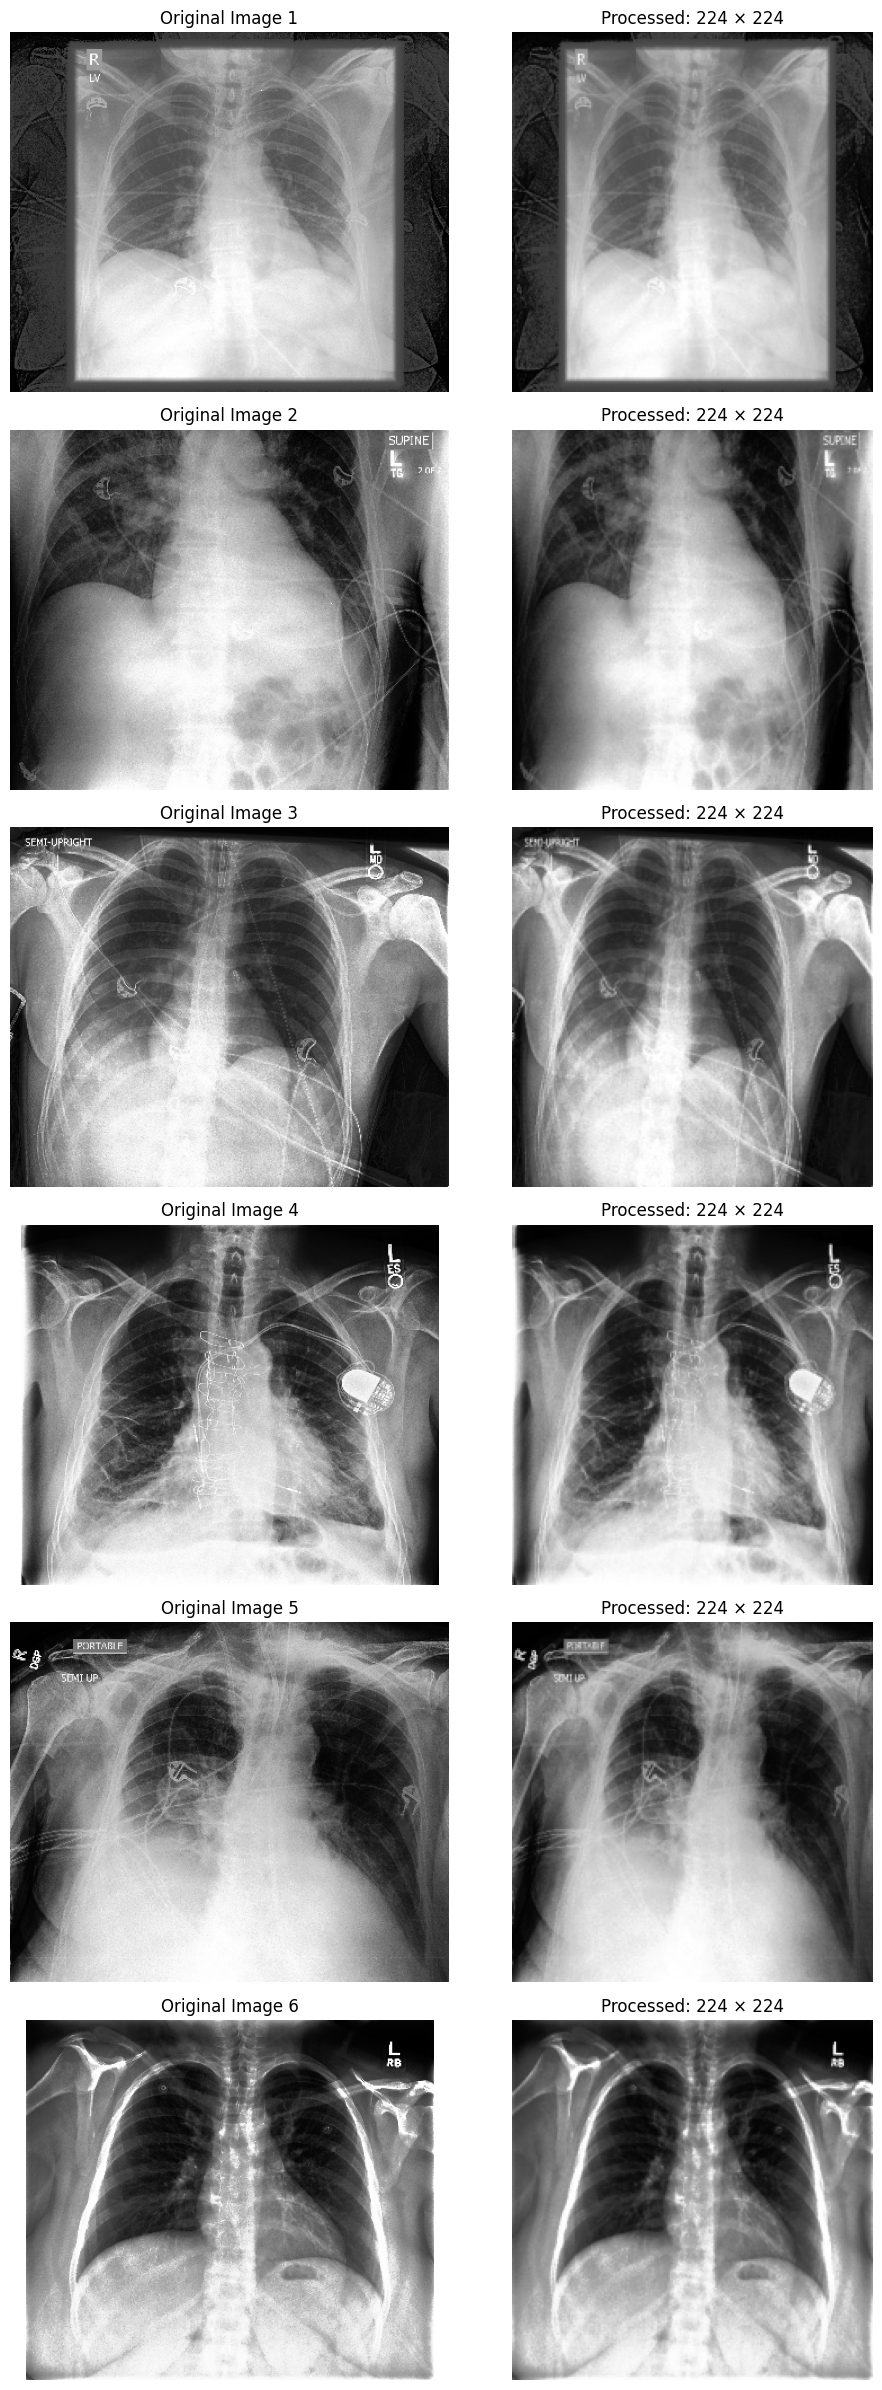


SUCCESS: Six original and preprocessed images displayed.


In [60]:
# CELL 37 — Visual Inspection of Preprocessed X-rays

import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm.auto import tqdm

# Select six images from the internal training partition
sample_df = chexpert_internal_train.sample(
    n=6,
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(6, 2, figsize=(10, 24))

for i in tqdm(range(len(sample_df)), desc="Inspecting X-ray images"):

    image_path = sample_df.loc[i, "image_path"]

    # Original grayscale image
    original = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        raise FileNotFoundError(image_path)

    # Apply the common preprocessing pipeline
    processed_tensor = preprocess_xray(image_path)

    # Reverse ImageNet normalization for visualization
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    processed = processed_tensor * std + mean

    processed = processed.clamp(0, 1)
    processed = processed.permute(1, 2, 0).numpy()

    # Display original and processed images
    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(f"Original Image {i + 1}")

    axes[i, 1].imshow(processed)
    axes[i, 1].set_title("Processed: 224 × 224")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

print("\nSUCCESS: Six original and preprocessed images displayed.")

In [61]:
# CELL 38 — Build the CheXpert PyTorch Dataset

import torch
import numpy as np
from torch.utils.data import Dataset


class CheXpertDataset(Dataset):

    def __init__(self, dataframe, policy="ignore"):
        """
        Args:
            dataframe: CheXpert metadata DataFrame.
            policy: 'ignore', 'zeros', or 'ones'.
        """

        if policy not in ["ignore", "zeros", "ones"]:
            raise ValueError(f"Invalid policy: {policy}")

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.policy = policy

        self.image_paths = self.dataframe["image_path"].tolist()

        self.raw_labels = self.dataframe[
            target_findings
        ].to_numpy(dtype=np.float32)

        # Generate targets and masks for this partition
        self.targets, self.masks = apply_uncertain_policy(
            self.raw_labels,
            self.policy
        )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        image_path = self.image_paths[index]

        # Load and preprocess image on demand
        image_tensor = preprocess_xray(image_path)

        # Convert labels and masks to PyTorch tensors
        target_tensor = torch.tensor(
            self.targets[index],
            dtype=torch.float32
        )

        mask_tensor = torch.tensor(
            self.masks[index],
            dtype=torch.float32
        )

        return {
            "image": image_tensor,
            "target": target_tensor,
            "mask": mask_tensor,
            "image_path": image_path
        }


# Create datasets for all three training policies
chexpert_train_datasets = {}
chexpert_valid_datasets = {}

for policy in ["ignore", "zeros", "ones"]:

    chexpert_train_datasets[policy] = CheXpertDataset(
        chexpert_internal_train,
        policy=policy
    )

    chexpert_valid_datasets[policy] = CheXpertDataset(
        chexpert_internal_valid,
        policy="ignore"
    )


# Test one sample from each policy
print("PYTORCH DATASET TEST")
print("-" * 60)

for policy in ["ignore", "zeros", "ones"]:

    sample = chexpert_train_datasets[policy][0]

    print(f"\nPolicy: {policy}")
    print("Image shape:", tuple(sample["image"].shape))
    print("Target shape:", tuple(sample["target"].shape))
    print("Mask shape:", tuple(sample["mask"].shape))
    print("Target:", sample["target"].tolist())
    print("Mask:", sample["mask"].tolist())


# Dataset integrity checks
for policy in ["ignore", "zeros", "ones"]:

    train_dataset = chexpert_train_datasets[policy]
    valid_dataset = chexpert_valid_datasets[policy]

    assert len(train_dataset) == len(chexpert_internal_train)
    assert len(valid_dataset) == len(chexpert_internal_valid)

    assert train_dataset[0]["image"].shape == (3, 224, 224)
    assert train_dataset[0]["target"].shape == (6,)
    assert train_dataset[0]["mask"].shape == (6,)

print("\nSUCCESS: CheXpert PyTorch datasets created and tested.")

PYTORCH DATASET TEST
------------------------------------------------------------

Policy: ignore
Image shape: (3, 224, 224)
Target shape: (6,)
Mask shape: (6,)
Target: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Mask: [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]

Policy: zeros
Image shape: (3, 224, 224)
Target shape: (6,)
Mask shape: (6,)
Target: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Mask: [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]

Policy: ones
Image shape: (3, 224, 224)
Target shape: (6,)
Mask shape: (6,)
Target: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Mask: [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]

SUCCESS: CheXpert PyTorch datasets created and tested.


In [62]:
# CELL 39 — Create and Test PyTorch DataLoaders

import time
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Configuration
BATCH_SIZE = 32
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

# Create training DataLoaders
chexpert_train_loaders = {}

for policy in ["ignore", "zeros", "ones"]:

    chexpert_train_loaders[policy] = DataLoader(
        chexpert_train_datasets[policy],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=(NUM_WORKERS > 0),
        drop_last=False
    )


# One shared validation DataLoader
chexpert_valid_loader = DataLoader(
    chexpert_valid_datasets["ignore"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)


# Inspect one batch from each training policy
print("TRAINING DATALOADER TEST")
print("-" * 60)

for policy in ["ignore", "zeros", "ones"]:

    start_time = time.perf_counter()

    loader = chexpert_train_loaders[policy]
    batch = next(iter(loader))

    elapsed = time.perf_counter() - start_time

    print(f"\nPolicy: {policy}")
    print("Images:", tuple(batch["image"].shape))
    print("Targets:", tuple(batch["target"].shape))
    print("Masks:", tuple(batch["mask"].shape))
    print("Batch loading time:", f"{elapsed:.2f} seconds")


# Inspect validation batch
print("\nVALIDATION DATALOADER TEST")
print("-" * 60)

start_time = time.perf_counter()

valid_batch = next(iter(chexpert_valid_loader))

elapsed = time.perf_counter() - start_time

print("Images:", tuple(valid_batch["image"].shape))
print("Targets:", tuple(valid_batch["target"].shape))
print("Masks:", tuple(valid_batch["mask"].shape))
print("Batch loading time:", f"{elapsed:.2f} seconds")


# Verify DataLoader sizes
print("\nDATALOADER SIZES")
print("-" * 60)

for policy, loader in chexpert_train_loaders.items():
    print(f"{policy.capitalize()} training batches:", len(loader))

print("Validation batches:", len(chexpert_valid_loader))

# Integrity checks
assert valid_batch["image"].shape[1:] == (3, 224, 224)
assert valid_batch["target"].shape[1:] == (6,)
assert valid_batch["mask"].shape[1:] == (6,)

for policy, loader in chexpert_train_loaders.items():

    batch = next(iter(loader))

    assert batch["image"].shape[1:] == (3, 224, 224)
    assert batch["target"].shape[1:] == (6,)
    assert batch["mask"].shape[1:] == (6,)

print("\nSUCCESS: All PyTorch DataLoaders passed validation.")

TRAINING DATALOADER TEST
------------------------------------------------------------

Policy: ignore
Images: (32, 3, 224, 224)
Targets: (32, 6)
Masks: (32, 6)
Batch loading time: 5.66 seconds

Policy: zeros
Images: (32, 3, 224, 224)
Targets: (32, 6)
Masks: (32, 6)
Batch loading time: 4.96 seconds

Policy: ones
Images: (32, 3, 224, 224)
Targets: (32, 6)
Masks: (32, 6)
Batch loading time: 4.44 seconds

VALIDATION DATALOADER TEST
------------------------------------------------------------
Images: (32, 3, 224, 224)
Targets: (32, 6)
Masks: (32, 6)
Batch loading time: 3.80 seconds

DATALOADER SIZES
------------------------------------------------------------
Ignore training batches: 5373
Zeros training batches: 5373
Ones training batches: 5373
Validation batches: 597

SUCCESS: All PyTorch DataLoaders passed validation.


In [63]:
# CELL 40 — Verify GPU and Training Environment

import torch
import torchvision
import platform
import os

print("TRAINING ENVIRONMENT")
print("=" * 60)

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("\nGPU DETAILS")
    print("-" * 60)

    for i in range(torch.cuda.device_count()):

        properties = torch.cuda.get_device_properties(i)

        print(f"GPU {i}:", properties.name)
        print(
            "Total GPU memory:",
            f"{properties.total_memory / (1024 ** 3):.2f} GB"
        )

        print(
            "Compute capability:",
            f"{properties.major}.{properties.minor}"
        )

    torch.cuda.empty_cache()

    free_memory, total_memory = torch.cuda.mem_get_info()

    print("\nCURRENT GPU MEMORY")
    print("Free:", f"{free_memory / (1024 ** 3):.2f} GB")
    print("Total:", f"{total_memory / (1024 ** 3):.2f} GB")

else:
    print("\nWARNING: CUDA is unavailable. Training will use CPU.")

print("\nDEVICE SELECTED")
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

print("\nSUCCESS: Environment verification completed.")

TRAINING ENVIRONMENT
Python version: 3.13.16
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True

GPU DETAILS
------------------------------------------------------------
GPU 0: Tesla T4
Total GPU memory: 14.56 GB
Compute capability: 7.5
GPU 1: Tesla T4
Total GPU memory: 14.56 GB
Compute capability: 7.5

CURRENT GPU MEMORY
Free: 14.46 GB
Total: 14.56 GB

DEVICE SELECTED
cuda

SUCCESS: Environment verification completed.


In [64]:
# CELL 41 — Initialize Pretrained DenseNet-121

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import DenseNet121_Weights

# Use the first available GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Canonical six-finding output order
NUM_CLASSES = len(target_findings)

print("INITIALIZING DENSENET-121")
print("-" * 60)

# Load ImageNet pretrained DenseNet-121
weights = DenseNet121_Weights.DEFAULT

model = models.densenet121(weights=weights)

# Replace the original 1000-class classifier
num_features = model.classifier.in_features

model.classifier = nn.Linear(
    num_features,
    NUM_CLASSES
)

# Move model to GPU
model = model.to(device)

print("Architecture: DenseNet-121")
print("Pretrained weights: ImageNet")
print("Original classifier features:", num_features)
print("Output classes:", NUM_CLASSES)
print("Output findings:", target_findings)
print("Selected device:", device)

# Forward-pass test
model.eval()

test_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE,
    device=device
)

with torch.no_grad():
    test_output = model(test_input)

print("\nFORWARD-PASS TEST")
print("Input shape:", tuple(test_input.shape))
print("Output shape:", tuple(test_output.shape))
print("Output data type:", test_output.dtype)

# Verify architecture
assert test_output.shape == (2, NUM_CLASSES)
assert torch.isfinite(test_output).all()
assert model.classifier.out_features == NUM_CLASSES

# Display parameter counts
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nMODEL PARAMETERS")
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nSUCCESS: DenseNet-121 initialized and forward pass verified.")

INITIALIZING DENSENET-121
------------------------------------------------------------
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 154MB/s] 


Architecture: DenseNet-121
Pretrained weights: ImageNet
Original classifier features: 1024
Output classes: 6
Output findings: ['Pleural Effusion', 'Cardiomegaly', 'Pneumothorax', 'Atelectasis', 'Consolidation', 'Lung Lesion']
Selected device: cuda:0

FORWARD-PASS TEST
Input shape: (2, 3, 224, 224)
Output shape: (2, 6)
Output data type: torch.float32

MODEL PARAMETERS
Total parameters: 6,960,006
Trainable parameters: 6,960,006

SUCCESS: DenseNet-121 initialized and forward pass verified.


In [65]:
# CELL 42 — Implement and Test Masked Multi-Label Loss

import torch
import torch.nn as nn


def masked_bce_loss(logits, targets, masks):
    """
    Calculate masked binary cross-entropy loss.

    Args:
        logits: Model outputs, shape (batch_size, 6).
        targets: Binary targets, shape (batch_size, 6).
        masks: 1 for observed labels, 0 for excluded labels.

    Returns:
        Scalar loss averaged over observed labels.
    """

    # Calculate BCE separately for every image-label pair
    elementwise_loss = nn.functional.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    )

    # Exclude uncertain/missing labels according to the selected policy
    masked_loss = elementwise_loss * masks

    # Count the observed labels
    valid_label_count = masks.sum()

    # Avoid division by zero
    if valid_label_count.item() == 0:
        raise ValueError(
            "This batch contains no observed labels. "
            "The loss cannot be calculated."
        )

    # Average only over observed labels
    loss = masked_loss.sum() / valid_label_count

    return loss


# Select one real training batch
test_batch = next(iter(chexpert_train_loaders["ignore"]))

test_images = test_batch["image"].to(device)
test_targets = test_batch["target"].to(device)
test_masks = test_batch["mask"].to(device)

# Ensure the model is in training mode
model.train()
model.zero_grad(set_to_none=True)

# Forward pass
test_logits = model(test_images)

# Calculate masked loss
test_loss = masked_bce_loss(
    test_logits,
    test_targets,
    test_masks
)

# Backward pass to verify gradient flow
test_loss.backward()

# Check gradients
gradient_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.grad is not None
]

gradient_count = len(gradient_parameters)

finite_gradients = all(
    torch.isfinite(parameter.grad).all().item()
    for parameter in gradient_parameters
)

gradient_magnitude = torch.sqrt(
    sum(
        torch.sum(parameter.grad.detach() ** 2)
        for parameter in gradient_parameters
    )
).item()

print("MASKED LOSS TEST")
print("-" * 60)

print("Input shape:", tuple(test_images.shape))
print("Logits shape:", tuple(test_logits.shape))
print("Targets shape:", tuple(test_targets.shape))
print("Masks shape:", tuple(test_masks.shape))

print("Observed labels in batch:", int(test_masks.sum().item()))
print("Excluded labels in batch:", int((1 - test_masks).sum().item()))

print("Masked BCE loss:", round(test_loss.item(), 6))
print("Parameters receiving gradients:", gradient_count)
print("All gradients finite:", finite_gradients)
print("Gradient L2 norm:", round(gradient_magnitude, 6))

# Integrity checks
assert test_logits.shape == test_targets.shape == test_masks.shape
assert torch.isfinite(test_loss).item()
assert gradient_count > 0
assert finite_gradients
assert gradient_magnitude > 0

# Clear test gradients before actual training
model.zero_grad(set_to_none=True)

print("\nSUCCESS: Masked loss and backward-pass tests passed.")

MASKED LOSS TEST
------------------------------------------------------------
Input shape: (32, 3, 224, 224)
Logits shape: (32, 6)
Targets shape: (32, 6)
Masks shape: (32, 6)
Observed labels in batch: 45
Excluded labels in batch: 147
Masked BCE loss: 0.717363
Parameters receiving gradients: 364
All gradients finite: True
Gradient L2 norm: 6.378486

SUCCESS: Masked loss and backward-pass tests passed.


In [66]:
# CELL 43 — Configure DenseNet-121 Training

import os
import random
import numpy as np
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau


# --------------------------------------------------
# 1. Reproducibility
# --------------------------------------------------

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)


# --------------------------------------------------
# 2. Experiment configuration
# --------------------------------------------------

TRAINING_CONFIG = {
    "architecture": "DenseNet-121",
    "pretrained": True,
    "policy": "ignore",
    "batch_size": BATCH_SIZE,
    "epochs": 10,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "gradient_clip": 1.0,
    "mixed_precision": True,
    "random_seed": RANDOM_SEED
}


# --------------------------------------------------
# 3. Optimizer
# --------------------------------------------------

optimizer = AdamW(
    model.parameters(),
    lr=TRAINING_CONFIG["learning_rate"],
    weight_decay=TRAINING_CONFIG["weight_decay"]
)


# --------------------------------------------------
# 4. Learning-rate scheduler
# --------------------------------------------------

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=TRAINING_CONFIG["scheduler_factor"],
    patience=TRAINING_CONFIG["scheduler_patience"]
)


# --------------------------------------------------
# 5. Mixed-precision configuration
# --------------------------------------------------

AMP_ENABLED = (
    TRAINING_CONFIG["mixed_precision"]
    and torch.cuda.is_available()
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)


# --------------------------------------------------
# 6. Gradient clipping
# --------------------------------------------------

GRADIENT_CLIP = TRAINING_CONFIG["gradient_clip"]


# --------------------------------------------------
# 7. Checkpoint and log directories
# --------------------------------------------------

OUTPUT_DIR = "/kaggle/working/m3_outputs"

CHECKPOINT_DIR = os.path.join(
    OUTPUT_DIR,
    "checkpoints"
)

LOG_DIR = os.path.join(
    OUTPUT_DIR,
    "training_logs"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)


# --------------------------------------------------
# 8. Select baseline training objects
# --------------------------------------------------

ACTIVE_POLICY = "ignore"

active_train_loader = chexpert_train_loaders[ACTIVE_POLICY]
active_valid_loader = chexpert_valid_loader


# --------------------------------------------------
# 9. Configuration summary
# --------------------------------------------------

print("DENSENET-121 TRAINING CONFIGURATION")
print("=" * 60)

for key, value in TRAINING_CONFIG.items():
    print(f"{key}: {value}")

print("\nOPTIMIZATION DETAILS")
print("-" * 60)

print("Device:", device)
print("Optimizer:", type(optimizer).__name__)
print("Scheduler:", type(scheduler).__name__)
print("Mixed precision enabled:", AMP_ENABLED)
print("Gradient clipping:", GRADIENT_CLIP)

print("\nDATA LOADERS")
print("Active policy:", ACTIVE_POLICY)
print("Training images:", len(chexpert_internal_train))
print("Validation images:", len(chexpert_internal_valid))
print("Training batches:", len(active_train_loader))
print("Validation batches:", len(active_valid_loader))

print("\nOUTPUT DIRECTORIES")
print("Checkpoints:", CHECKPOINT_DIR)
print("Training logs:", LOG_DIR)

# Configuration integrity checks
assert ACTIVE_POLICY in chexpert_train_loaders
assert len(active_train_loader) > 0
assert len(active_valid_loader) > 0
assert optimizer.param_groups[0]["lr"] == TRAINING_CONFIG["learning_rate"]
assert os.path.isdir(CHECKPOINT_DIR)
assert os.path.isdir(LOG_DIR)

print("\nSUCCESS: Training configuration initialized.")

DENSENET-121 TRAINING CONFIGURATION
architecture: DenseNet-121
pretrained: True
policy: ignore
batch_size: 32
epochs: 10
learning_rate: 0.0001
weight_decay: 0.0001
optimizer: AdamW
scheduler: ReduceLROnPlateau
scheduler_factor: 0.5
scheduler_patience: 2
gradient_clip: 1.0
mixed_precision: True
random_seed: 42

OPTIMIZATION DETAILS
------------------------------------------------------------
Device: cuda:0
Optimizer: AdamW
Scheduler: ReduceLROnPlateau
Mixed precision enabled: True
Gradient clipping: 1.0

DATA LOADERS
Active policy: ignore
Training images: 171927
Validation images: 19100
Training batches: 5373
Validation batches: 597

OUTPUT DIRECTORIES
Checkpoints: /kaggle/working/m3_outputs/checkpoints
Training logs: /kaggle/working/m3_outputs/training_logs

SUCCESS: Training configuration initialized.


In [67]:
# CELL 44 — Define DenseNet-121 Training and Evaluation Functions

import time
import numpy as np
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score


def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler,
    device,
    policy
):
    """Train DenseNet-121 for one epoch using masked BCE loss."""

    model.train()

    running_loss = 0.0
    total_observed_labels = 0

    progress_bar = tqdm(
        loader,
        desc=f"Training ({policy})",
        unit="batch"
    )

    for batch in progress_bar:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        targets = batch["target"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Mixed-precision forward pass
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):
            logits = model(images)

            loss = masked_bce_loss(
                logits,
                targets,
                masks
            )

        # Backward pass with gradient scaling
        scaler.scale(loss).backward()

        # Unscale before gradient clipping
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        observed = int(masks.sum().item())

        running_loss += loss.detach().item() * observed
        total_observed_labels += observed

        current_loss = running_loss / max(
            total_observed_labels,
            1
        )

        progress_bar.set_postfix(
            loss=f"{current_loss:.4f}",
            observed=total_observed_labels
        )

    epoch_loss = running_loss / max(
        total_observed_labels,
        1
    )

    return epoch_loss


@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device
):
    """Evaluate model using definite validation labels only."""

    model.eval()

    all_probabilities = []
    all_targets = []
    all_masks = []

    running_loss = 0.0
    total_observed_labels = 0

    progress_bar = tqdm(
        loader,
        desc="Validation",
        unit="batch"
    )

    for batch in progress_bar:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        targets = batch["target"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):
            logits = model(images)

            loss = masked_bce_loss(
                logits,
                targets,
                masks
            )

        probabilities = torch.sigmoid(logits)

        observed = int(masks.sum().item())

        running_loss += loss.item() * observed
        total_observed_labels += observed

        all_probabilities.append(
            probabilities.float().cpu().numpy()
        )

        all_targets.append(
            targets.cpu().numpy()
        )

        all_masks.append(
            masks.cpu().numpy()
        )

    validation_loss = running_loss / max(
        total_observed_labels,
        1
    )

    probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    targets = np.concatenate(
        all_targets,
        axis=0
    )

    masks = np.concatenate(
        all_masks,
        axis=0
    )

    # Calculate metrics independently for each finding
    metric_records = []

    auc_values = []

    for index, finding in enumerate(target_findings):

        valid_indices = masks[:, index] == 1

        y_true = targets[valid_indices, index]
        y_probability = probabilities[valid_indices, index]

        if len(np.unique(y_true)) == 2:

            auc = roc_auc_score(
                y_true,
                y_probability
            )

            auprc = average_precision_score(
                y_true,
                y_probability
            )

            auc_values.append(auc)

        else:
            auc = np.nan
            auprc = np.nan

        metric_records.append({
            "Finding": finding,
            "AUROC": auc,
            "AUPRC": auprc,
            "Positive": int((y_true == 1).sum()),
            "Negative": int((y_true == 0).sum()),
            "Evaluated": len(y_true)
        })

    macro_auroc = (
        float(np.mean(auc_values))
        if auc_values else np.nan
    )

    return {
        "validation_loss": validation_loss,
        "macro_auroc": macro_auroc,
        "metrics": metric_records
    }


print("TRAINING AND EVALUATION FUNCTIONS DEFINED")
print("-" * 60)
print("Training function: train_one_epoch")
print("Evaluation function: evaluate_model")
print("Loss: masked BCEWithLogitsLoss")
print("Validation metrics: per-finding AUROC and AUPRC")
print("Scheduler metric: macro AUROC")
print("Mixed precision:", AMP_ENABLED)

print("\nSUCCESS: Functions defined. No training has started.")

TRAINING AND EVALUATION FUNCTIONS DEFINED
------------------------------------------------------------
Training function: train_one_epoch
Evaluation function: evaluate_model
Loss: masked BCEWithLogitsLoss
Validation metrics: per-finding AUROC and AUPRC
Scheduler metric: macro AUROC
Mixed precision: True

SUCCESS: Functions defined. No training has started.


In [68]:
# CELL 45 — Run First DenseNet-121 Training Epoch

import os
import time
import json
import pandas as pd
import torch
from tqdm.auto import tqdm

# Pilot configuration
PILOT_EPOCHS = 1
ACTIVE_POLICY = "ignore"

# Reset GPU peak-memory statistics
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)

print("DENSENET-121 BASELINE TRAINING")
print("=" * 65)
print("Policy:", ACTIVE_POLICY)
print("Epochs:", PILOT_EPOCHS)
print("Training images:", len(chexpert_internal_train))
print("Validation images:", len(chexpert_internal_valid))
print("Device:", device)

training_start = time.perf_counter()

# Train for one complete epoch
epoch_start = time.perf_counter()

train_loss = train_one_epoch(
    model=model,
    loader=chexpert_train_loaders[ACTIVE_POLICY],
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    policy=ACTIVE_POLICY
)

training_elapsed = time.perf_counter() - epoch_start

print("\nTRAINING EPOCH COMPLETED")
print("Training loss:", round(train_loss, 6))
print("Training time:", f"{training_elapsed / 60:.2f} minutes")

# Evaluate on internal validation
validation_start = time.perf_counter()

validation_results = evaluate_model(
    model=model,
    loader=chexpert_valid_loader,
    device=device
)

validation_elapsed = time.perf_counter() - validation_start

print("\nVALIDATION RESULTS")
print("-" * 65)
print("Validation loss:", round(
    validation_results["validation_loss"], 6
))
print("Macro AUROC:", round(
    validation_results["macro_auroc"], 6
) if pd.notna(validation_results["macro_auroc"]) else "Unavailable")

metrics_df = pd.DataFrame(validation_results["metrics"])
display(metrics_df)

# Update scheduler only if macro AUROC is available
if pd.notna(validation_results["macro_auroc"]):
    scheduler.step(validation_results["macro_auroc"])

# Save pilot checkpoint
checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "densenet121_ignore_epoch_001.pth"
)

checkpoint = {
    "epoch": 1,
    "policy": ACTIVE_POLICY,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "training_config": TRAINING_CONFIG,
    "train_loss": train_loss,
    "validation_loss": validation_results["validation_loss"],
    "macro_auroc": validation_results["macro_auroc"]
}

torch.save(checkpoint, checkpoint_path)

# Save validation metrics
metrics_path = os.path.join(
    LOG_DIR,
    "densenet121_ignore_epoch_001_metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

# Save epoch summary
summary = {
    "epoch": 1,
    "policy": ACTIVE_POLICY,
    "train_loss": train_loss,
    "validation_loss": validation_results["validation_loss"],
    "macro_auroc": validation_results["macro_auroc"],
    "training_minutes": training_elapsed / 60,
    "validation_minutes": validation_elapsed / 60
}

summary_path = os.path.join(
    LOG_DIR,
    "densenet121_ignore_epoch_001_summary.json"
)

with open(summary_path, "w") as file:
    json.dump(summary, file, indent=4)

# GPU memory report
if torch.cuda.is_available():
    peak_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 3)
    print("\nPEAK GPU MEMORY:", f"{peak_memory:.2f} GB")

total_elapsed = time.perf_counter() - training_start

print("\nPILOT RUN SUMMARY")
print("-" * 65)
print("Total elapsed time:", f"{total_elapsed / 60:.2f} minutes")
print("Checkpoint:", checkpoint_path)
print("Metrics:", metrics_path)
print("Summary:", summary_path)

assert os.path.exists(checkpoint_path)
assert os.path.exists(metrics_path)
assert os.path.exists(summary_path)

print("\nSUCCESS: First training epoch completed and artifacts saved.")

DENSENET-121 BASELINE TRAINING
Policy: ignore
Epochs: 1
Training images: 171927
Validation images: 19100
Device: cuda:0


Training (ignore):   0%|          | 0/5373 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [69]:
# CELL 46 — Benchmark CheXpert Image Loading Performance

import time
import torch
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

BENCHMARK_BATCHES = 40
WORKER_OPTIONS = [2, 4]

# Use the same samples for both benchmarks
benchmark_size = min(
    BENCHMARK_BATCHES * BATCH_SIZE,
    len(chexpert_internal_train)
)

benchmark_indices = list(range(benchmark_size))

benchmark_dataset = Subset(
    chexpert_train_datasets["ignore"],
    benchmark_indices
)

benchmark_results = []

print("IMAGE LOADING BENCHMARK")
print("=" * 60)
print("Images per benchmark:", benchmark_size)
print("Batch size:", BATCH_SIZE)

for workers in WORKER_OPTIONS:

    benchmark_loader = DataLoader(
        benchmark_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=workers,
        pin_memory=True,
        persistent_workers=True,
        prefetch_factor=2
    )

    start_time = time.perf_counter()
    images_processed = 0

    progress = tqdm(
        enumerate(benchmark_loader),
        total=min(BENCHMARK_BATCHES, len(benchmark_loader)),
        desc=f"Testing {workers} workers",
        unit="batch"
    )

    for batch_index, batch in progress:

        images_processed += batch["image"].shape[0]

        if batch_index + 1 >= BENCHMARK_BATCHES:
            break

        progress.set_postfix(
            images=images_processed
        )

    elapsed = time.perf_counter() - start_time

    images_per_second = images_processed / elapsed

    benchmark_results.append({
        "Workers": workers,
        "Images processed": images_processed,
        "Time (seconds)": round(elapsed, 2),
        "Images/second": round(images_per_second, 2)
    })

    del benchmark_loader

print("\nBENCHMARK RESULTS")
display(pd.DataFrame(benchmark_results))

print("\nSUCCESS: Image-loading benchmark completed.")

IMAGE LOADING BENCHMARK
Images per benchmark: 1280
Batch size: 32


Testing 2 workers:   0%|          | 0/40 [00:00<?, ?batch/s]

Testing 4 workers:   0%|          | 0/40 [00:00<?, ?batch/s]


BENCHMARK RESULTS


,Workers,Images processed,Time (seconds),Images/second
0,2,1280,81.58,15.69
1,4,1280,2.92,437.79



SUCCESS: Image-loading benchmark completed.


In [70]:
# CELL 47 — Benchmark Actual GPU Training Throughput

import time
import torch
import pandas as pd
from torch.utils.data import DataLoader
from torchvision import models
from torchvision.models import DenseNet121_Weights
from torch.optim import AdamW
from tqdm.auto import tqdm

BENCHMARK_BATCHES = 50
BENCHMARK_WORKERS = 4

# Create a fresh benchmark model so the interrupted model is not reused
benchmark_model = models.densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

benchmark_model.classifier = torch.nn.Linear(
    benchmark_model.classifier.in_features,
    len(target_findings)
)

benchmark_model = benchmark_model.to(device)

benchmark_optimizer = AdamW(
    benchmark_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

benchmark_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

# Four-worker loader using the complete training dataset
benchmark_loader = DataLoader(
    chexpert_train_datasets["ignore"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=BENCHMARK_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
    drop_last=False
)

print("ACTUAL GPU TRAINING BENCHMARK")
print("=" * 65)
print("Architecture: DenseNet-121")
print("Dataset available:", len(chexpert_train_datasets["ignore"]))
print("Benchmark batches:", BENCHMARK_BATCHES)
print("Workers:", BENCHMARK_WORKERS)
print("Batch size:", BATCH_SIZE)
print("Mixed precision:", True)

benchmark_model.train()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(device)

# Warm-up GPU and CUDA kernels
warmup_start = time.perf_counter()

warmup_iterator = iter(benchmark_loader)
warmup_batch = next(warmup_iterator)

warmup_images = warmup_batch["image"].to(device, non_blocking=True)
warmup_targets = warmup_batch["target"].to(device, non_blocking=True)
warmup_masks = warmup_batch["mask"].to(device, non_blocking=True)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=True
):
    warmup_logits = benchmark_model(warmup_images)
    warmup_loss = masked_bce_loss(
        warmup_logits,
        warmup_targets,
        warmup_masks
    )

benchmark_scaler.scale(warmup_loss).backward()
benchmark_scaler.step(benchmark_optimizer)
benchmark_scaler.update()
benchmark_optimizer.zero_grad(set_to_none=True)

torch.cuda.synchronize()
warmup_elapsed = time.perf_counter() - warmup_start

print("\nWarm-up completed in:", f"{warmup_elapsed:.2f} seconds")

# Measure actual training throughput
images_processed = 0
running_loss = 0.0

training_start = time.perf_counter()

progress = tqdm(
    enumerate(warmup_iterator),
    total=BENCHMARK_BATCHES - 1,
    desc="GPU training benchmark",
    unit="batch"
)

for batch_index, batch in progress:

    images = batch["image"].to(device, non_blocking=True)
    targets = batch["target"].to(device, non_blocking=True)
    masks = batch["mask"].to(device, non_blocking=True)

    benchmark_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=True
    ):
        logits = benchmark_model(images)

        loss = masked_bce_loss(
            logits,
            targets,
            masks
        )

    benchmark_scaler.scale(loss).backward()
    benchmark_scaler.unscale_(benchmark_optimizer)

    torch.nn.utils.clip_grad_norm_(
        benchmark_model.parameters(),
        max_norm=1.0
    )

    benchmark_scaler.step(benchmark_optimizer)
    benchmark_scaler.update()

    images_processed += images.shape[0]
    running_loss += loss.detach().item()

    progress.set_postfix(
        loss=f"{loss.item():.4f}",
        images=images_processed
    )

    if batch_index + 2 >= BENCHMARK_BATCHES:
        break

torch.cuda.synchronize()

training_elapsed = time.perf_counter() - training_start

total_images = images_processed + BATCH_SIZE
total_training_images = total_images

# Calculate throughput
images_per_second = total_training_images / (
    training_elapsed + warmup_elapsed
)

seconds_per_batch = (
    training_elapsed + warmup_elapsed
) / BENCHMARK_BATCHES

# Estimate complete training epoch duration
estimated_epoch_seconds = (
    len(chexpert_train_datasets["ignore"])
    / images_per_second
)

peak_gpu_memory = (
    torch.cuda.max_memory_allocated(device)
    / (1024 ** 3)
)

print("\nGPU TRAINING BENCHMARK RESULTS")
print("-" * 65)
print("Images processed:", total_training_images)
print("Elapsed time:", f"{training_elapsed + warmup_elapsed:.2f} seconds")
print("Images per second:", f"{images_per_second:.2f}")
print("Seconds per batch:", f"{seconds_per_batch:.3f}")
print("Average benchmark loss:", f"{running_loss / max(BENCHMARK_BATCHES - 1, 1):.6f}")
print("Peak GPU memory:", f"{peak_gpu_memory:.2f} GB")

print("\nESTIMATED FULL TRAINING EPOCH")
print("-" * 65)
print("Training images:", len(chexpert_train_datasets["ignore"]))
print(
    "Estimated time:",
    f"{estimated_epoch_seconds / 60:.1f} minutes"
)

print("\nSUCCESS: Actual GPU training benchmark completed.")

# Clean up benchmark-only resources
del benchmark_model
del benchmark_optimizer
del benchmark_scaler
del benchmark_loader
del warmup_iterator
del warmup_batch

torch.cuda.empty_cache()

ACTUAL GPU TRAINING BENCHMARK
Architecture: DenseNet-121
Dataset available: 171927
Benchmark batches: 50
Workers: 4
Batch size: 32
Mixed precision: True

Warm-up completed in: 5.37 seconds


GPU training benchmark:   0%|          | 0/49 [00:00<?, ?batch/s]


GPU TRAINING BENCHMARK RESULTS
-----------------------------------------------------------------
Images processed: 1600
Elapsed time: 63.17 seconds
Images per second: 25.33
Seconds per batch: 1.263
Average benchmark loss: 0.537284
Peak GPU memory: 2.28 GB

ESTIMATED FULL TRAINING EPOCH
-----------------------------------------------------------------
Training images: 171927
Estimated time: 113.1 minutes

SUCCESS: Actual GPU training benchmark completed.


In [71]:
# CELL 48 — Benchmark Different GPU Batch Sizes

import gc
import time
import torch
import pandas as pd
from torch.utils.data import DataLoader, Subset
from torchvision import models
from torchvision.models import DenseNet121_Weights
from torch.optim import AdamW
from tqdm.auto import tqdm

# Benchmark configuration
BATCH_SIZES_TO_TEST = [32, 64, 96]
BENCHMARK_IMAGES = 640
BENCHMARK_WORKERS = 4

benchmark_dataset = Subset(
    chexpert_train_datasets["ignore"],
    range(BENCHMARK_IMAGES)
)

batch_size_results = []

print("DENSENET-121 BATCH SIZE BENCHMARK")
print("=" * 65)
print("Images per configuration:", BENCHMARK_IMAGES)
print("Workers:", BENCHMARK_WORKERS)
print("Mixed precision: Enabled")
print("All model layers trainable: Yes")

for batch_size in BATCH_SIZES_TO_TEST:

    print(f"\n\nTESTING BATCH SIZE: {batch_size}")
    print("-" * 65)

    torch.cuda.empty_cache()
    gc.collect()

    # Initialize a fresh pretrained model
    test_model = models.densenet121(
        weights=DenseNet121_Weights.DEFAULT
    )

    test_model.classifier = torch.nn.Linear(
        test_model.classifier.in_features,
        len(target_findings)
    )

    test_model = test_model.to(device)
    test_model.train()

    test_optimizer = AdamW(
        test_model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    test_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=True
    )

    test_loader = DataLoader(
        benchmark_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=BENCHMARK_WORKERS,
        pin_memory=True,
        persistent_workers=True,
        prefetch_factor=2,
        drop_last=False
    )

    torch.cuda.reset_peak_memory_stats(device)

    processed_images = 0
    loss_total = 0.0

    start_time = time.perf_counter()

    progress = tqdm(
        test_loader,
        total=len(test_loader),
        desc=f"Batch size {batch_size}",
        unit="batch"
    )

    try:

        for batch in progress:

            images = batch["image"].to(
                device,
                non_blocking=True
            )

            targets = batch["target"].to(
                device,
                non_blocking=True
            )

            masks = batch["mask"].to(
                device,
                non_blocking=True
            )

            test_optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = test_model(images)

                loss = masked_bce_loss(
                    logits,
                    targets,
                    masks
                )

            test_scaler.scale(loss).backward()
            test_scaler.unscale_(test_optimizer)

            torch.nn.utils.clip_grad_norm_(
                test_model.parameters(),
                max_norm=1.0
            )

            test_scaler.step(test_optimizer)
            test_scaler.update()

            processed_images += images.size(0)
            loss_total += loss.item()

            progress.set_postfix(
                images=processed_images,
                loss=f"{loss.item():.4f}"
            )

        torch.cuda.synchronize()

        elapsed = time.perf_counter() - start_time

        throughput = processed_images / elapsed

        estimated_epoch_minutes = (
            len(chexpert_internal_train)
            / throughput
            / 60
        )

        peak_memory = (
            torch.cuda.max_memory_allocated(device)
            / (1024 ** 3)
        )

        batch_size_results.append({
            "Batch Size": batch_size,
            "Images Processed": processed_images,
            "Time (seconds)": round(elapsed, 2),
            "Images/second": round(throughput, 2),
            "Peak GPU Memory (GB)": round(peak_memory, 2),
            "Estimated Epoch (minutes)": round(
                estimated_epoch_minutes, 2
            ),
            "Average Loss": round(
                loss_total / len(test_loader), 6
            ),
            "Status": "Success"
        })

    except torch.cuda.OutOfMemoryError:

        torch.cuda.empty_cache()

        batch_size_results.append({
            "Batch Size": batch_size,
            "Images Processed": processed_images,
            "Time (seconds)": None,
            "Images/second": None,
            "Peak GPU Memory (GB)": None,
            "Estimated Epoch (minutes)": None,
            "Average Loss": None,
            "Status": "CUDA Out of Memory"
        })

        print(f"Batch size {batch_size} exceeded GPU memory.")

    finally:

        del test_model
        del test_optimizer
        del test_scaler
        del test_loader

        torch.cuda.empty_cache()
        gc.collect()


# Display comparison
batch_size_results_df = pd.DataFrame(batch_size_results)

print("\n\nBATCH SIZE COMPARISON")
print("=" * 90)
display(batch_size_results_df)

successful_results = batch_size_results_df[
    batch_size_results_df["Status"] == "Success"
]

if len(successful_results) > 0:

    best_result = successful_results.loc[
        successful_results["Images/second"].idxmax()
    ]

    print("\nBEST CONFIGURATION")
    print("-" * 65)
    print("Batch size:", int(best_result["Batch Size"]))
    print("Throughput:", best_result["Images/second"], "images/second")
    print(
        "Estimated epoch:",
        best_result["Estimated Epoch (minutes)"],
        "minutes"
    )
    print(
        "Peak GPU memory:",
        best_result["Peak GPU Memory (GB)"],
        "GB"
    )

print("\nSUCCESS: Batch size benchmark completed.")

DENSENET-121 BATCH SIZE BENCHMARK
Images per configuration: 640
Workers: 4
Mixed precision: Enabled
All model layers trainable: Yes


TESTING BATCH SIZE: 32
-----------------------------------------------------------------


Batch size 32:   0%|          | 0/20 [00:00<?, ?batch/s]



TESTING BATCH SIZE: 64
-----------------------------------------------------------------


Batch size 64:   0%|          | 0/10 [00:00<?, ?batch/s]



TESTING BATCH SIZE: 96
-----------------------------------------------------------------


Batch size 96:   0%|          | 0/7 [00:00<?, ?batch/s]



BATCH SIZE COMPARISON


,Batch Size,Images Processed,Time (seconds),Images/second,Peak GPU Memory (GB),Estimated Epoch (minutes),Average Loss,Status
0,32,640,4.81,133.18,2.34,21.52,0.596286,Success
1,64,640,6.33,101.03,4.33,28.36,0.633036,Success
2,96,640,6.61,96.82,6.33,29.60,0.653203,Success



BEST CONFIGURATION
-----------------------------------------------------------------
Batch size: 32
Throughput: 133.18 images/second
Estimated epoch: 21.52 minutes
Peak GPU memory: 2.34 GB

SUCCESS: Batch size benchmark completed.


In [72]:
# CELL 49 — Sustained DenseNet-121 Training Throughput Benchmark

import gc
import time
import torch
import pandas as pd

from torch.utils.data import DataLoader
from torchvision import models
from torchvision.models import DenseNet121_Weights
from torch.optim import AdamW
from tqdm.auto import tqdm

# Benchmark configuration
SUSTAINED_BATCH_SIZE = 32
SUSTAINED_WORKERS = 4
SUSTAINED_BATCHES = 200
WARMUP_BATCHES = 10

print("SUSTAINED TRAINING BENCHMARK")
print("=" * 65)
print("Architecture: DenseNet-121")
print("Batch size:", SUSTAINED_BATCH_SIZE)
print("Workers:", SUSTAINED_WORKERS)
print("Measured batches:", SUSTAINED_BATCHES)
print("Warm-up batches:", WARMUP_BATCHES)
print("Dataset:", len(chexpert_train_datasets["ignore"]), "images")

# Initialize a fresh pretrained model
sustained_model = models.densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

sustained_model.classifier = torch.nn.Linear(
    sustained_model.classifier.in_features,
    len(target_findings)
)

sustained_model = sustained_model.to(device)
sustained_model.train()

sustained_optimizer = AdamW(
    sustained_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

sustained_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

sustained_loader = DataLoader(
    chexpert_train_datasets["ignore"],
    batch_size=SUSTAINED_BATCH_SIZE,
    shuffle=True,
    num_workers=SUSTAINED_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
    drop_last=False
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(device)

sustained_iterator = iter(sustained_loader)

# Warm-up: excluded from throughput measurement
print("\nRunning warm-up...")

for step in tqdm(
    range(WARMUP_BATCHES),
    desc="Warm-up",
    unit="batch"
):

    batch = next(sustained_iterator)

    images = batch["image"].to(device, non_blocking=True)
    targets = batch["target"].to(device, non_blocking=True)
    masks = batch["mask"].to(device, non_blocking=True)

    sustained_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=True
    ):
        logits = sustained_model(images)
        loss = masked_bce_loss(logits, targets, masks)

    sustained_scaler.scale(loss).backward()
    sustained_scaler.unscale_(sustained_optimizer)

    torch.nn.utils.clip_grad_norm_(
        sustained_model.parameters(),
        max_norm=1.0
    )

    sustained_scaler.step(sustained_optimizer)
    sustained_scaler.update()

torch.cuda.synchronize()

# Sustained benchmark
print("\nRunning sustained benchmark...")

measured_images = 0
measured_losses = []
start_time = time.perf_counter()

progress = tqdm(
    range(SUSTAINED_BATCHES),
    desc="Sustained GPU training",
    unit="batch"
)

for step in progress:

    batch = next(sustained_iterator)

    images = batch["image"].to(device, non_blocking=True)
    targets = batch["target"].to(device, non_blocking=True)
    masks = batch["mask"].to(device, non_blocking=True)

    sustained_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=True
    ):
        logits = sustained_model(images)
        loss = masked_bce_loss(logits, targets, masks)

    sustained_scaler.scale(loss).backward()
    sustained_scaler.unscale_(sustained_optimizer)

    torch.nn.utils.clip_grad_norm_(
        sustained_model.parameters(),
        max_norm=1.0
    )

    sustained_scaler.step(sustained_optimizer)
    sustained_scaler.update()

    measured_images += images.shape[0]
    measured_losses.append(loss.item())

    elapsed = time.perf_counter() - start_time

    current_rate = measured_images / max(elapsed, 1e-9)

    progress.set_postfix(
        loss=f"{loss.item():.4f}",
        images_per_sec=f"{current_rate:.1f}"
    )

torch.cuda.synchronize()

elapsed = time.perf_counter() - start_time

# Calculate sustained throughput
images_per_second = measured_images / elapsed

estimated_epoch_minutes = (
    len(chexpert_internal_train)
    / images_per_second
    / 60
)

peak_memory = (
    torch.cuda.max_memory_allocated(device)
    / (1024 ** 3)
)

results = pd.DataFrame([{
    "Batch Size": SUSTAINED_BATCH_SIZE,
    "Workers": SUSTAINED_WORKERS,
    "Images Processed": measured_images,
    "Elapsed Seconds": round(elapsed, 2),
    "Images/Second": round(images_per_second, 2),
    "Average Batch Loss": round(
        sum(measured_losses) / len(measured_losses), 6
    ),
    "Peak GPU Memory (GB)": round(peak_memory, 2),
    "Estimated Epoch (minutes)": round(
        estimated_epoch_minutes, 2
    )
}])

print("\nSUSTAINED BENCHMARK RESULTS")
display(results)

print("\nTRAINING TIME ESTIMATE")
print("-" * 65)
print(
    "One training epoch:",
    f"{estimated_epoch_minutes:.1f} minutes"
)
print(
    "Ten training epochs:",
    f"{estimated_epoch_minutes * 10 / 60:.2f} hours"
)

# Save benchmark result
benchmark_output_path = os.path.join(
    OUTPUT_DIR,
    "densenet121_sustained_benchmark.csv"
)

results.to_csv(benchmark_output_path, index=False)

print("\nSaved benchmark:", benchmark_output_path)

# Clean up benchmark-only resources
del sustained_model
del sustained_optimizer
del sustained_scaler
del sustained_loader
del sustained_iterator

torch.cuda.empty_cache()
gc.collect()

print("\nSUCCESS: Sustained benchmark completed.")

SUSTAINED TRAINING BENCHMARK
Architecture: DenseNet-121
Batch size: 32
Workers: 4
Measured batches: 200
Warm-up batches: 10
Dataset: 171927 images

Running warm-up...


Warm-up:   0%|          | 0/10 [00:00<?, ?batch/s]


Running sustained benchmark...


Sustained GPU training:   0%|          | 0/200 [00:00<?, ?batch/s]


SUSTAINED BENCHMARK RESULTS


,Batch Size,Workers,Images Processed,Elapsed Seconds,Images/Second,Average Batch Loss,Peak GPU Memory (GB),Estimated Epoch (minutes)
0,32,4,6400,224.47,28.51,0.400357,2.33,100.5



TRAINING TIME ESTIMATE
-----------------------------------------------------------------
One training epoch: 100.5 minutes
Ten training epochs: 16.75 hours

Saved benchmark: /kaggle/working/m3_outputs/densenet121_sustained_benchmark.csv

SUCCESS: Sustained benchmark completed.


In [75]:
# CELL 50 — Final Notebook Variable Audit

print("=" * 75)
print("CHEXPERT DATASET VARIABLES")
print("=" * 75)

for name, obj in globals().copy().items():
    if "chexpert" in name.lower():
        if isinstance(obj, dict):
            print(f"\n{name}: dictionary")
            for key, value in obj.items():
                if hasattr(value, "__len__"):
                    try:
                        print(f"  {key}: {type(value).__name__}, length={len(value):,}")
                    except:
                        print(f"  {key}: {type(value).__name__}")
                else:
                    print(f"  {key}: {type(value).__name__}")

        elif hasattr(obj, "dataset") and hasattr(obj, "batch_size"):
            print(
                f"{name}: DataLoader | "
                f"Images={len(obj.dataset):,} | "
                f"Batches={len(obj):,} | "
                f"Workers={obj.num_workers} | "
                f"Batch={obj.batch_size}"
            )

        elif hasattr(obj, "__len__"):
            try:
                print(f"{name}: {type(obj).__name__}, length={len(obj):,}")
            except:
                print(f"{name}: {type(obj).__name__}")

print("\n" + "=" * 75)
print("PREPROCESSING AND TRAINING FUNCTIONS")
print("=" * 75)

for name in [
    "preprocess_xray",
    "CheXpertDataset",
    "train_one_epoch",
    "evaluate_model",
    "masked_bce_loss"
]:
    print(f"{name}: {'Available' if name in globals() else 'NOT FOUND'}")

print("\n" + "=" * 75)
print("TRAINING CONFIGURATION")
print("=" * 75)

for name in [
    "ACTIVE_POLICY",
    "BATCH_SIZE",
    "EPOCHS",
    "LEARNING_RATE",
    "WEIGHT_DECAY",
    "AMP_ENABLED",
    "GRADIENT_CLIP",
    "SEED"
]:
    print(f"{name}: {globals().get(name, 'Not defined')}")

print("\nAUDIT COMPLETED")

CHEXPERT DATASET VARIABLES
chexpert_root: str, length=38
chexpert_train_df: DataFrame, length=223,414
chexpert_valid_df: DataFrame, length=234
chexpert_train_clean: DataFrame, length=191,027
chexpert_valid_clean: DataFrame, length=202
chexpert_split_df: DataFrame, length=191,027
chexpert_internal_train: DataFrame, length=171,927
chexpert_internal_valid: DataFrame, length=19,100
CheXpertDataset: type

chexpert_train_datasets: dictionary
  ignore: CheXpertDataset, length=171,927
  zeros: CheXpertDataset, length=171,927
  ones: CheXpertDataset, length=171,927

chexpert_valid_datasets: dictionary
  ignore: CheXpertDataset, length=19,100
  zeros: CheXpertDataset, length=19,100
  ones: CheXpertDataset, length=19,100

chexpert_train_loaders: dictionary
  ignore: DataLoader, length=5,373
  zeros: DataLoader, length=5,373
  ones: DataLoader, length=5,373
chexpert_valid_loader: DataLoader | Images=19,100 | Batches=597 | Workers=2 | Batch=32

PREPROCESSING AND TRAINING FUNCTIONS
preprocess_xray: 

In [78]:
# CELL 51 — Find Original Dataset and Training Definitions

history = In

search_terms = [
    "class CheXpertDataset",
    "def preprocess_xray",
    "def train_one_epoch",
    "def evaluate_model"
]

for term in search_terms:
    print("\n" + "=" * 90)
    print(f"SEARCH: {term}")
    print("=" * 90)

    matches = []

    for i, source in enumerate(history):
        # Exclude previous code-search cells
        if "keywords = [" in source and "history = In" in source:
            continue

        if term in source:
            matches.append((i, source))

    if not matches:
        print("No matching definition found.")
        continue

    for i, source in matches:
        print(f"\nINPUT CELL: {i}")
        print("-" * 90)
        print(source)


SEARCH: class CheXpertDataset

INPUT CELL: 61
------------------------------------------------------------------------------------------
# CELL 38 — Build the CheXpert PyTorch Dataset

import torch
import numpy as np
from torch.utils.data import Dataset


class CheXpertDataset(Dataset):

    def __init__(self, dataframe, policy="ignore"):
        """
        Args:
            dataframe: CheXpert metadata DataFrame.
            policy: 'ignore', 'zeros', or 'ones'.
        """

        if policy not in ["ignore", "zeros", "ones"]:
            raise ValueError(f"Invalid policy: {policy}")

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.policy = policy

        self.image_paths = self.dataframe["image_path"].tolist()

        self.raw_labels = self.dataframe[
            target_findings
        ].to_numpy(dtype=np.float32)

        # Generate targets and masks for this partition
        self.targets, self.masks = apply_uncertain_policy(
            self.raw

In [79]:
# CELL 52 — Final CheXpert Dataset with Training Augmentation

import cv2
import numpy as np
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode


# ---------------------------------------------------------
# 1. IMAGE CONFIGURATION
# ---------------------------------------------------------

IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ---------------------------------------------------------
# 2. AUGMENTATION TRANSFORM
# ---------------------------------------------------------

train_augmentation = transforms.RandomAffine(
    degrees=5,
    translate=(0.02, 0.02),
    scale=(0.95, 1.05),
    interpolation=InterpolationMode.BILINEAR,
    fill=0
)

tensor_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ---------------------------------------------------------
# 3. PREPROCESSING FUNCTION
# ---------------------------------------------------------

def preprocess_xray(image_path, augment=False):

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(
            f"Unable to read X-ray image: {image_path}"
        )

    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    image = cv2.equalizeHist(image)

    image = np.stack(
        [image, image, image],
        axis=-1
    )

    image = Image.fromarray(image)

    # Apply geometric augmentation only to training images
    if augment:
        image = train_augmentation(image)

    return tensor_transform(image)


# ---------------------------------------------------------
# 4. UPDATED PYTORCH DATASET
# ---------------------------------------------------------

class CheXpertDataset(Dataset):

    def __init__(
        self,
        dataframe,
        policy="ignore",
        augment=False
    ):

        if policy not in ["ignore", "zeros", "ones"]:
            raise ValueError(f"Invalid policy: {policy}")

        self.dataframe = dataframe.reset_index(
            drop=True
        ).copy()

        self.policy = policy
        self.augment = augment

        self.image_paths = self.dataframe[
            "image_path"
        ].tolist()

        self.raw_labels = self.dataframe[
            target_findings
        ].to_numpy(dtype=np.float32)

        self.targets, self.masks = apply_uncertain_policy(
            self.raw_labels,
            self.policy
        )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        image_path = self.image_paths[index]

        image_tensor = preprocess_xray(
            image_path,
            augment=self.augment
        )

        target_tensor = torch.tensor(
            self.targets[index],
            dtype=torch.float32
        )

        mask_tensor = torch.tensor(
            self.masks[index],
            dtype=torch.float32
        )

        return {
            "image": image_tensor,
            "target": target_tensor,
            "mask": mask_tensor,
            "image_path": image_path
        }


print("SUCCESS: Updated preprocessing and Dataset defined.")
print("Training augmentation: Enabled")
print("Validation augmentation: Disabled")
print("Horizontal flipping: Disabled")

SUCCESS: Updated preprocessing and Dataset defined.
Training augmentation: Enabled
Validation augmentation: Disabled
Horizontal flipping: Disabled


In [80]:
# CELL 53 — Create Final 4-Worker DataLoaders

import os
import random
import numpy as np
import torch

from torch.utils.data import DataLoader


# ---------------------------------------------------------
# 1. FINAL CONFIGURATION
# ---------------------------------------------------------

BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

ACTIVE_POLICY = "ignore"

EPOCHS = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

AMP_ENABLED = True
GRADIENT_CLIP = 1.0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ---------------------------------------------------------
# 2. WORKER SEEDING
# ---------------------------------------------------------

def seed_worker(worker_id):

    worker_seed = torch.initial_seed() % (2**32)

    np.random.seed(worker_seed)
    random.seed(worker_seed)


# ---------------------------------------------------------
# 3. RECREATE DATASETS
# ---------------------------------------------------------

chexpert_train_datasets = {}
chexpert_valid_datasets = {}

for policy in ["ignore", "zeros", "ones"]:

    chexpert_train_datasets[policy] = CheXpertDataset(
        chexpert_internal_train,
        policy=policy,
        augment=True
    )

    chexpert_valid_datasets[policy] = CheXpertDataset(
        chexpert_internal_valid,
        policy="ignore",
        augment=False
    )


# ---------------------------------------------------------
# 4. CREATE DATALOADERS
# ---------------------------------------------------------

chexpert_train_loaders = {}
chexpert_valid_loaders = {}

for policy in ["ignore", "zeros", "ones"]:

    train_generator = torch.Generator()
    train_generator.manual_seed(SEED)

    valid_generator = torch.Generator()
    valid_generator.manual_seed(SEED)

    chexpert_train_loaders[policy] = DataLoader(
        chexpert_train_datasets[policy],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=True,
        prefetch_factor=2,
        worker_init_fn=seed_worker,
        generator=train_generator,
        drop_last=False
    )

    chexpert_valid_loaders[policy] = DataLoader(
        chexpert_valid_datasets[policy],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=True,
        prefetch_factor=2,
        worker_init_fn=seed_worker,
        generator=valid_generator,
        drop_last=False
    )


# Keep the original validation-loader variable available
chexpert_valid_loader = chexpert_valid_loaders["ignore"]


# ---------------------------------------------------------
# 5. VERIFY CONFIGURATION
# ---------------------------------------------------------

print("=" * 75)
print("FINAL DATALOADER CONFIGURATION")
print("=" * 75)

for policy in ["ignore", "zeros", "ones"]:

    train_loader = chexpert_train_loaders[policy]
    valid_loader = chexpert_valid_loaders[policy]

    print(f"\nPolicy: {policy}")

    print(
        f"Training: {len(train_loader.dataset):,} images | "
        f"{len(train_loader):,} batches | "
        f"{train_loader.num_workers} workers"
    )

    print(
        f"Validation: {len(valid_loader.dataset):,} images | "
        f"{len(valid_loader):,} batches | "
        f"{valid_loader.num_workers} workers"
    )


# ---------------------------------------------------------
# 6. BASIC INTEGRITY CHECKS
# ---------------------------------------------------------

assert len(chexpert_train_datasets["ignore"]) == 171927
assert len(chexpert_valid_datasets["ignore"]) == 19100

assert chexpert_train_loaders["ignore"].num_workers == 4
assert chexpert_valid_loader.num_workers == 4

sample_train = chexpert_train_datasets["ignore"][0]
sample_valid = chexpert_valid_datasets["ignore"][0]

assert sample_train["image"].shape == (3, 224, 224)
assert sample_valid["image"].shape == (3, 224, 224)

assert torch.isfinite(sample_train["image"]).all()
assert torch.isfinite(sample_valid["image"]).all()

assert sample_train["target"].shape == (6,)
assert sample_train["mask"].shape == (6,)

print("\nSUCCESS: Final datasets and DataLoaders created.")
print("Full training images:", len(chexpert_train_datasets["ignore"]))
print("Validation images:", len(chexpert_valid_datasets["ignore"]))

FINAL DATALOADER CONFIGURATION

Policy: ignore
Training: 171,927 images | 5,373 batches | 4 workers
Validation: 19,100 images | 597 batches | 4 workers

Policy: zeros
Training: 171,927 images | 5,373 batches | 4 workers
Validation: 19,100 images | 597 batches | 4 workers

Policy: ones
Training: 171,927 images | 5,373 batches | 4 workers
Validation: 19,100 images | 597 batches | 4 workers

SUCCESS: Final datasets and DataLoaders created.
Full training images: 171927
Validation images: 19100


In [81]:
# CELL 54 — Initialize Final DenseNet-121 Baseline

import os
import json
import torch
import torch.nn as nn

from torchvision import models
from torchvision.models import DenseNet121_Weights


# ---------------------------------------------------------
# 1. DEVICE
# ---------------------------------------------------------

assert torch.cuda.is_available(), "CUDA GPU is required."

device = torch.device("cuda:0")

print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))


# ---------------------------------------------------------
# 2. REPRODUCIBILITY
# ---------------------------------------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


# ---------------------------------------------------------
# 3. INITIALIZE FRESH PRETRAINED DENSENET-121
# ---------------------------------------------------------

print("\nLoading ImageNet-pretrained DenseNet-121...")

model = models.densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

# Replace original 1000-class classifier with six findings
input_features = model.classifier.in_features

model.classifier = nn.Linear(
    input_features,
    len(target_findings)
)

model = model.to(device)


# ---------------------------------------------------------
# 4. OPTIMIZER
# ---------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ---------------------------------------------------------
# 5. LEARNING RATE SCHEDULER
# ---------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


# ---------------------------------------------------------
# 6. MIXED PRECISION SCALER
# ---------------------------------------------------------

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)


# ---------------------------------------------------------
# 7. OUTPUT DIRECTORIES
# ---------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/m3_outputs"

CHECKPOINT_DIR = os.path.join(
    OUTPUT_DIR,
    "checkpoints"
)

LOG_DIR = os.path.join(
    OUTPUT_DIR,
    "training_logs"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)


# ---------------------------------------------------------
# 8. TRAINING STATE
# ---------------------------------------------------------

training_history = []

best_macro_auroc = -float("inf")
best_epoch = 0

start_epoch = 1

active_train_loader = chexpert_train_loaders[ACTIVE_POLICY]
active_valid_loader = chexpert_valid_loaders[ACTIVE_POLICY]


# ---------------------------------------------------------
# 9. CONFIGURATION SUMMARY
# ---------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nMODEL CONFIGURATION")
print("-" * 60)

print("Architecture: DenseNet-121")
print("Pretrained weights: ImageNet")
print("Output classes:", target_findings)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Policy:", ACTIVE_POLICY)
print("Batch size:", BATCH_SIZE)
print("Epochs planned:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Mixed precision:", AMP_ENABLED)


# ---------------------------------------------------------
# 10. FORWARD-PASS TEST
# ---------------------------------------------------------

print("\nTesting one batch...")

test_batch = next(iter(active_train_loader))

test_images = test_batch["image"].to(
    device,
    non_blocking=True
)

test_targets = test_batch["target"].to(
    device,
    non_blocking=True
)

test_masks = test_batch["mask"].to(
    device,
    non_blocking=True
)

model.eval()

with torch.no_grad():

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=AMP_ENABLED
    ):

        test_logits = model(test_images)

        test_loss = masked_bce_loss(
            test_logits,
            test_targets,
            test_masks
        )

print("Input shape:", tuple(test_images.shape))
print("Output shape:", tuple(test_logits.shape))
print("Test loss:", round(test_loss.item(), 6))
print("Observed labels:", int(test_masks.sum().item()))

assert test_logits.shape == (BATCH_SIZE, 6)
assert torch.isfinite(test_logits).all()
assert torch.isfinite(test_loss)

print("\nSUCCESS: Fresh DenseNet-121 initialized.")
print("No model weights have been updated.")
print("Ready for the first full training epoch.")

Using device: cuda:0
GPU: Tesla T4

Loading ImageNet-pretrained DenseNet-121...

MODEL CONFIGURATION
------------------------------------------------------------
Architecture: DenseNet-121
Pretrained weights: ImageNet
Output classes: ['Pleural Effusion', 'Cardiomegaly', 'Pneumothorax', 'Atelectasis', 'Consolidation', 'Lung Lesion']
Total parameters: 6,960,006
Trainable parameters: 6,960,006
Policy: ignore
Batch size: 32
Epochs planned: 5
Learning rate: 0.0001
Weight decay: 0.0001
Mixed precision: True

Testing one batch...
Input shape: (32, 3, 224, 224)
Output shape: (32, 6)
Test loss: 0.775876
Observed labels: 51

SUCCESS: Fresh DenseNet-121 initialized.
No model weights have been updated.
Ready for the first full training epoch.


In [82]:
# CELL 55 — Full DenseNet-121 Training: Epoch 1

import os
import time
import json
import pandas as pd
import torch

from datetime import datetime


# ---------------------------------------------------------
# 1. TRAINING START
# ---------------------------------------------------------

epoch = 1

print("=" * 75)
print("DENSENET-121 BASELINE TRAINING")
print("=" * 75)

print("Epoch:", epoch, "/", EPOCHS)
print("Training images:", f"{len(active_train_loader.dataset):,}")
print("Training batches:", f"{len(active_train_loader):,}")
print("Validation images:", f"{len(active_valid_loader.dataset):,}")
print("Policy:", ACTIVE_POLICY)
print("Start time:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

epoch_start = time.time()


# ---------------------------------------------------------
# 2. TRAIN ONE FULL EPOCH
# ---------------------------------------------------------

train_loss = train_one_epoch(
    model=model,
    loader=active_train_loader,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    policy=ACTIVE_POLICY
)

training_seconds = time.time() - epoch_start


# ---------------------------------------------------------
# 3. VALIDATION
# ---------------------------------------------------------

print("\nTraining completed.")
print("Training loss:", round(train_loss, 6))
print("Training duration:", round(training_seconds / 60, 2), "minutes")

print("\nStarting full internal validation...")

validation_start = time.time()

validation_results = evaluate_model(
    model=model,
    loader=active_valid_loader,
    device=device
)

validation_seconds = time.time() - validation_start


# ---------------------------------------------------------
# 4. UPDATE LEARNING RATE SCHEDULER
# ---------------------------------------------------------

macro_auroc = validation_results["macro_auroc"]

if not pd.isna(macro_auroc):
    scheduler.step(macro_auroc)


# ---------------------------------------------------------
# 5. RECORD METRICS
# ---------------------------------------------------------

epoch_record = {
    "epoch": epoch,
    "policy": ACTIVE_POLICY,
    "training_loss": float(train_loss),
    "validation_loss": float(validation_results["validation_loss"]),
    "macro_auroc": float(macro_auroc),
    "learning_rate": float(optimizer.param_groups[0]["lr"]),
    "training_minutes": training_seconds / 60,
    "validation_minutes": validation_seconds / 60,
    "timestamp": datetime.now().isoformat()
}

training_history.append(epoch_record)


# ---------------------------------------------------------
# 6. SAVE CHECKPOINT
# ---------------------------------------------------------

checkpoint = {
    "epoch": epoch,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "training_history": training_history,
    "validation_results": validation_results,
    "target_findings": target_findings,
    "active_policy": ACTIVE_POLICY,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED
}

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "densenet121_epoch_1.pth"
)

torch.save(checkpoint, checkpoint_path)

# Save a separate best-model checkpoint
if macro_auroc > best_macro_auroc:
    best_macro_auroc = macro_auroc
    best_epoch = epoch

    best_path = os.path.join(
        CHECKPOINT_DIR,
        "densenet121_best.pth"
    )

    torch.save(checkpoint, best_path)

# Save training history
history_path = os.path.join(
    LOG_DIR,
    "densenet121_training_history.csv"
)

pd.DataFrame(training_history).to_csv(
    history_path,
    index=False
)

# Save per-finding validation metrics
metrics_path = os.path.join(
    LOG_DIR,
    "densenet121_epoch_1_metrics.csv"
)

pd.DataFrame(
    validation_results["metrics"]
).to_csv(metrics_path, index=False)


# ---------------------------------------------------------
# 7. DISPLAY RESULTS
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("EPOCH 1 RESULTS")
print("=" * 75)

print("Training loss:", round(train_loss, 6))
print(
    "Validation loss:",
    round(validation_results["validation_loss"], 6)
)
print("Macro AUROC:", round(macro_auroc, 6))
print("Best epoch:", best_epoch)

print("\nPER-FINDING VALIDATION METRICS")

display(
    pd.DataFrame(validation_results["metrics"])
)

print("\nTRAINING TIME:", round(training_seconds / 60, 2), "minutes")
print("VALIDATION TIME:", round(validation_seconds / 60, 2), "minutes")

print("\nCHECKPOINT:", checkpoint_path)
print("BEST MODEL:", best_path)
print("HISTORY:", history_path)
print("METRICS:", metrics_path)

print("\nSUCCESS: Epoch 1 completed and checkpoints saved.")

DENSENET-121 BASELINE TRAINING
Epoch: 1 / 5
Training images: 171,927
Training batches: 5,373
Validation images: 19,100
Policy: ignore
Start time: 2026-11-05 18:07:41


Training (ignore):   0%|          | 0/5373 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [ ]:
# CELL 59 — Resume DenseNet-121 Training Safely

import os
import time
import torch
import pandas as pd

from datetime import datetime
from tqdm.auto import tqdm


# ---------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------

ADDITIONAL_EPOCHS = 2
CHECKPOINT_INTERVAL = 250

device = torch.device("cuda:0")

active_train_loader = chexpert_train_loaders[ACTIVE_POLICY]
active_valid_loader = chexpert_valid_loaders[ACTIVE_POLICY]

print("=" * 75)
print("RESUMING DENSENET-121 TRAINING")
print("=" * 75)

print("Existing model: Preserved")
print("Existing optimizer: Preserved")
print("Existing AMP scaler: Preserved")
print("Training images:", f"{len(active_train_loader.dataset):,}")
print("Training batches:", len(active_train_loader))
print("Additional complete passes:", ADDITIONAL_EPOCHS)


# ---------------------------------------------------------
# 2. EMERGENCY CHECKPOINT FUNCTION
# ---------------------------------------------------------

def save_training_checkpoint(filename, epoch, batch, history):

    path = os.path.join(CHECKPOINT_DIR, filename)

    torch.save({
        "epoch": epoch,
        "batch": batch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "training_history": history,
        "active_policy": ACTIVE_POLICY,
        "target_findings": target_findings
    }, path)

    return path


# ---------------------------------------------------------
# 3. TRAINING LOOP WITH PERIODIC SAVING
# ---------------------------------------------------------

continuation_history = []
continuation_start = time.time()

for epoch in range(1, ADDITIONAL_EPOCHS + 1):

    print("\n" + "=" * 75)
    print(f"COMPLETE TRAINING PASS {epoch}/{ADDITIONAL_EPOCHS}")
    print("=" * 75)

    model.train()

    running_loss = 0.0
    total_observed = 0

    epoch_start = time.time()

    progress = tqdm(
        enumerate(active_train_loader, start=1),
        total=len(active_train_loader),
        desc=f"Training pass {epoch}",
        unit="batch"
    )

    for batch_number, batch in progress:

        images = batch["image"].to(device, non_blocking=True)
        targets = batch["target"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):
            logits = model(images)
            loss = masked_bce_loss(logits, targets, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        observed = int(masks.sum().item())

        running_loss += loss.detach().item() * observed
        total_observed += observed

        current_loss = running_loss / max(total_observed, 1)

        progress.set_postfix(
            loss=f"{current_loss:.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

        # Periodic emergency checkpoint
        if batch_number % CHECKPOINT_INTERVAL == 0:

            save_training_checkpoint(
                f"emergency_pass_{epoch}_batch_{batch_number}.pth",
                epoch,
                batch_number,
                continuation_history
            )

    train_loss = running_loss / max(total_observed, 1)
    training_minutes = (time.time() - epoch_start) / 60

    # -----------------------------------------------------
    # 4. VALIDATION
    # -----------------------------------------------------

    print("\nTraining pass completed.")
    print("Training loss:", round(train_loss, 6))
    print("Training duration:", round(training_minutes, 2), "minutes")

    validation_start = time.time()

    validation_results = evaluate_model(
        model=model,
        loader=active_valid_loader,
        device=device
    )

    validation_minutes = (time.time() - validation_start) / 60

    macro_auroc = validation_results["macro_auroc"]

    if pd.notna(macro_auroc):
        scheduler.step(macro_auroc)

    # -----------------------------------------------------
    # 5. SAVE COMPLETED PASS
    # -----------------------------------------------------

    record = {
        "continuation_pass": epoch,
        "training_loss": float(train_loss),
        "validation_loss": float(validation_results["validation_loss"]),
        "macro_auroc": float(macro_auroc),
        "learning_rate": float(optimizer.param_groups[0]["lr"]),
        "training_minutes": training_minutes,
        "validation_minutes": validation_minutes,
        "timestamp": datetime.now().isoformat()
    }

    continuation_history.append(record)

    checkpoint_path = save_training_checkpoint(
        f"densenet121_resumed_pass_{epoch}.pth",
        epoch,
        len(active_train_loader),
        continuation_history
    )

    pd.DataFrame(continuation_history).to_csv(
        os.path.join(LOG_DIR, "resumed_training_history.csv"),
        index=False
    )

    pd.DataFrame(validation_results["metrics"]).to_csv(
        os.path.join(LOG_DIR, f"resumed_pass_{epoch}_metrics.csv"),
        index=False
    )

    print("\nPASS RESULTS")
    print("Training loss:", round(train_loss, 6))
    print("Validation loss:", round(validation_results["validation_loss"], 6))
    print("Macro AUROC:", round(macro_auroc, 6))
    print("Validation duration:", round(validation_minutes, 2), "minutes")

    display(pd.DataFrame(validation_results["metrics"]))

    print("Checkpoint:", checkpoint_path)


# ---------------------------------------------------------
# 6. FINAL SUMMARY
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("RESUMED TRAINING COMPLETED")
print("=" * 75)

print(
    "Total duration:",
    round((time.time() - continuation_start) / 60, 2),
    "minutes"
)

display(pd.DataFrame(continuation_history))

print("All completed passes have been saved.")

RESUMING DENSENET-121 TRAINING
Existing model: Preserved
Existing optimizer: Preserved
Existing AMP scaler: Preserved
Training images: 171,927
Training batches: 5373
Additional complete passes: 2

COMPLETE TRAINING PASS 1/2


Training pass 1:   0%|          | 0/5373 [00:00<?, ?batch/s]

In [84]:
# CELL 57 — Diagnose DataLoader Failure and Preserve Model State

import os
import torch
from torch.utils.data import DataLoader

print("=" * 75)
print("1. CHECK PARTIAL MODEL CHECKPOINT")
print("=" * 75)

partial_path = os.path.join(
    CHECKPOINT_DIR,
    "densenet121_pre_continuation_partial.pth"
)

if os.path.exists(partial_path):
    print("Checkpoint exists:", partial_path)
    print("File size:", round(os.path.getsize(partial_path) / 1024**2, 2), "MB")
else:
    print("WARNING: Partial checkpoint not found.")

print("\n" + "=" * 75)
print("2. CHECK MODEL AND OPTIMIZER")
print("=" * 75)

print("Model available:", "model" in globals())
print("Optimizer available:", "optimizer" in globals())
print("Model device:", next(model.parameters()).device)

print("\n" + "=" * 75)
print("3. TEST DATA LOADING WITHOUT WORKERS")
print("=" * 75)

diagnostic_loader = DataLoader(
    chexpert_train_datasets[ACTIVE_POLICY],
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

for i, batch in enumerate(diagnostic_loader):
    print(
        f"Batch {i+1}:",
        batch["image"].shape,
        "| Targets:",
        batch["target"].shape
    )

    if i == 1:
        break

print("\nSUCCESS: Image loading works without multiprocessing.")

1. CHECK PARTIAL MODEL CHECKPOINT
Checkpoint exists: /kaggle/working/m3_outputs/checkpoints/densenet121_pre_continuation_partial.pth
File size: 80.57 MB

2. CHECK MODEL AND OPTIMIZER
Model available: True
Optimizer available: True
Model device: cuda:0

3. TEST DATA LOADING WITHOUT WORKERS
Batch 1: torch.Size([8, 3, 224, 224]) | Targets: torch.Size([8, 6])
Batch 2: torch.Size([8, 3, 224, 224]) | Targets: torch.Size([8, 6])

SUCCESS: Image loading works without multiprocessing.


In [85]:
# CELL 58 — Repair DataLoaders After Worker Failure

import torch
from torch.utils.data import DataLoader

NUM_WORKERS = 2
BATCH_SIZE = 32

print("=" * 75)
print("RECREATING STABLE DATALOADERS")
print("=" * 75)

# Recreate training loaders
chexpert_train_loaders = {}
chexpert_valid_loaders = {}

for policy in ["ignore", "zeros", "ones"]:

    chexpert_train_loaders[policy] = DataLoader(
        chexpert_train_datasets[policy],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=False,
        prefetch_factor=2,
        drop_last=False
    )

    chexpert_valid_loaders[policy] = DataLoader(
        chexpert_valid_datasets[policy],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=False,
        prefetch_factor=2,
        drop_last=False
    )

active_train_loader = chexpert_train_loaders[ACTIVE_POLICY]
active_valid_loader = chexpert_valid_loaders[ACTIVE_POLICY]

chexpert_valid_loader = active_valid_loader

print("Training workers:", active_train_loader.num_workers)
print("Persistent workers:", active_train_loader.persistent_workers)
print("Training batches:", len(active_train_loader))
print("Validation batches:", len(active_valid_loader))

print("\nTesting fresh workers...")

for i, batch in enumerate(active_train_loader):
    print(
        f"Batch {i+1}: {tuple(batch['image'].shape)}"
    )

    if i == 4:
        break

print("\nSUCCESS: Fresh DataLoader workers passed the test.")
print("Existing model and optimizer have not been modified.")

RECREATING STABLE DATALOADERS
Training workers: 2
Persistent workers: False
Training batches: 5373
Validation batches: 597

Testing fresh workers...
Batch 1: (32, 3, 224, 224)
Batch 2: (32, 3, 224, 224)
Batch 3: (32, 3, 224, 224)
Batch 4: (32, 3, 224, 224)
Batch 5: (32, 3, 224, 224)

SUCCESS: Fresh DataLoader workers passed the test.
Existing model and optimizer have not been modified.


In [1]:
# CELL 60 — Locate Latest Recoverable Training Checkpoint

import os
import glob

checkpoint_files = glob.glob(
    os.path.join(CHECKPOINT_DIR, "*.pth")
)

checkpoint_files = sorted(
    checkpoint_files,
    key=os.path.getmtime,
    reverse=True
)

print("=" * 75)
print("AVAILABLE CHECKPOINTS")
print("=" * 75)

for path in checkpoint_files:
    print(
        os.path.basename(path),
        "|",
        round(os.path.getsize(path) / 1024**2, 2),
        "MB"
    )

print("\n" + "=" * 75)
print("LATEST EMERGENCY CHECKPOINT")
print("=" * 75)

emergency_files = [
    path for path in checkpoint_files
    if "emergency" in os.path.basename(path)
]

if emergency_files:
    latest = emergency_files[0]
    print("Latest:", latest)

    checkpoint = torch.load(
        latest,
        map_location="cpu",
        weights_only=False
    )

    print("Saved pass:", checkpoint["epoch"])
    print("Saved batch:", checkpoint["batch"])
    print("Policy:", checkpoint["active_policy"])
else:
    print("No emergency checkpoints found.")

print("\nModel still in memory:", "model" in globals())
print("Optimizer still in memory:", "optimizer" in globals())

NameError: name 'CHECKPOINT_DIR' is not defined

In [2]:
# CELL 60 — Locate Latest Recoverable Checkpoint

import os
import glob
import torch

CHECKPOINT_DIR = "/kaggle/working/m3_outputs/checkpoints"

print("=" * 75)
print("CHECKPOINT DIRECTORY")
print("=" * 75)

print("Path:", CHECKPOINT_DIR)
print("Directory exists:", os.path.exists(CHECKPOINT_DIR))

if not os.path.exists(CHECKPOINT_DIR):
    raise FileNotFoundError("Checkpoint directory does not exist.")

checkpoint_files = glob.glob(
    os.path.join(CHECKPOINT_DIR, "*.pth")
)

checkpoint_files.sort(
    key=os.path.getmtime,
    reverse=True
)

print("\nAVAILABLE CHECKPOINTS")

for path in checkpoint_files:
    print(
        os.path.basename(path),
        "|",
        round(os.path.getsize(path) / 1024**2, 2),
        "MB"
    )

emergency_files = [
    path for path in checkpoint_files
    if "emergency" in os.path.basename(path)
]

print("\nLATEST EMERGENCY CHECKPOINT")

if emergency_files:
    latest = emergency_files[0]

    checkpoint = torch.load(
        latest,
        map_location="cpu",
        weights_only=False
    )

    print("File:", latest)
    print("Pass:", checkpoint.get("epoch"))
    print("Batch:", checkpoint.get("batch"))
    print("Policy:", checkpoint.get("active_policy"))

else:
    print("No emergency checkpoints found.")

print("\nCURRENT MEMORY STATE")
print("Model available:", "model" in globals())
print("Optimizer available:", "optimizer" in globals())

CHECKPOINT DIRECTORY
Path: /kaggle/working/m3_outputs/checkpoints
Directory exists: False


FileNotFoundError: Checkpoint directory does not exist.

In [3]:
# CELL 61 — Search Kaggle Storage for Model Checkpoints

import os

search_roots = [
    "/kaggle/working",
    "/kaggle/input",
    "/kaggle/temp"
]

extensions = (".pth", ".pt", ".ckpt")

print("=" * 75)
print("SEARCHING FOR SAVED MODEL CHECKPOINTS")
print("=" * 75)

found_files = []

for root in search_roots:

    if not os.path.exists(root):
        continue

    print(f"\nSearching: {root}")

    for current_root, dirs, files in os.walk(root):

        dirs[:] = [
            d for d in dirs
            if d not in [".cache", "__pycache__"]
        ]

        for filename in files:

            if filename.lower().endswith(extensions):

                path = os.path.join(current_root, filename)
                size_mb = os.path.getsize(path) / 1024**2

                found_files.append(path)

                print(
                    filename,
                    "|",
                    round(size_mb, 2),
                    "MB",
                    "|",
                    path
                )

print("\n" + "=" * 75)
print("SEARCH SUMMARY")
print("=" * 75)

print("Total checkpoint files found:", len(found_files))

if not found_files:
    print("No surviving model checkpoints found.")

SEARCHING FOR SAVED MODEL CHECKPOINTS

Searching: /kaggle/working

Searching: /kaggle/input


KeyboardInterrupt: 

In [4]:
# CELL 62 — Quick Kaggle Session Check

import os
import torch

paths = [
    "/kaggle/working",
    "/kaggle/working/m3_outputs",
    "/kaggle/working/m3_outputs/checkpoints"
]

for path in paths:
    print(path, "EXISTS:", os.path.exists(path))

print("\nCUDA available:", torch.cuda.is_available())

for variable in ["model", "optimizer", "scaler", "scheduler"]:
    print(variable, "IN MEMORY:", variable in globals())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Allocated GPU memory:",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")

/kaggle/working EXISTS: True
/kaggle/working/m3_outputs EXISTS: False
/kaggle/working/m3_outputs/checkpoints EXISTS: False

CUDA available: True
model IN MEMORY: False
optimizer IN MEMORY: False
scaler IN MEMORY: False
scheduler IN MEMORY: False
GPU: Tesla T4
Allocated GPU memory: 0.0 GB


In [5]:
# CELL 63 — Check Available Project Variables

required_variables = [
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "target_findings",
    "apply_uncertain_policy",
    "preprocess_xray",
    "CheXpertDataset"
]

for name in required_variables:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\nProject input directory exists:",
      __import__("os").path.exists("/kaggle/input/datasets/ashery/chexpert/"))

chexpert_internal_train: MISSING
chexpert_internal_valid: MISSING
target_findings: MISSING
apply_uncertain_policy: MISSING
preprocess_xray: MISSING
CheXpertDataset: MISSING

Project input directory exists: True


In [6]:
# CELL 64 — Rebuild CheXpert Metadata and Patient Split

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# Dataset paths
chexpert_root = "/kaggle/input/datasets/ashery/chexpert"

train_csv = os.path.join(chexpert_root, "train.csv")
valid_csv = os.path.join(chexpert_root, "valid.csv")

# Canonical finding order
target_findings = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

# Load metadata
chexpert_train_df = pd.read_csv(train_csv)
chexpert_valid_df = pd.read_csv(valid_csv)

# Retain frontal images
chexpert_train_clean = chexpert_train_df[
    chexpert_train_df["Frontal/Lateral"] == "Frontal"
].copy()

chexpert_valid_clean = chexpert_valid_df[
    chexpert_valid_df["Frontal/Lateral"] == "Frontal"
].copy()

# Correct image paths
def correct_chexpert_path(path):
    prefix = "CheXpert-v1.0-small/"
    if str(path).startswith(prefix):
        path = str(path)[len(prefix):]
    return os.path.join(chexpert_root, path)

chexpert_train_clean["image_path"] = (
    chexpert_train_clean["Path"].apply(correct_chexpert_path)
)

chexpert_valid_clean["image_path"] = (
    chexpert_valid_clean["Path"].apply(correct_chexpert_path)
)

# Extract patient IDs
chexpert_train_clean["patient_id"] = (
    chexpert_train_clean["Path"]
    .str.extract(r"(patient\d+)")
)

chexpert_valid_clean["patient_id"] = (
    chexpert_valid_clean["Path"]
    .str.extract(r"(patient\d+)")
)

# Verify required data
assert chexpert_train_clean["patient_id"].notna().all()
assert chexpert_train_clean["image_path"].notna().all()
assert set(target_findings).issubset(chexpert_train_clean.columns)

# Reproduce patient-level 90:10 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_indices, valid_indices = next(
    splitter.split(
        chexpert_train_clean,
        groups=chexpert_train_clean["patient_id"]
    )
)

chexpert_internal_train = (
    chexpert_train_clean.iloc[train_indices].reset_index(drop=True)
)

chexpert_internal_valid = (
    chexpert_train_clean.iloc[valid_indices].reset_index(drop=True)
)

# Leakage check
train_patients = set(chexpert_internal_train["patient_id"])
valid_patients = set(chexpert_internal_valid["patient_id"])

assert len(train_patients & valid_patients) == 0

# Report
print("=" * 70)
print("CHEXPERT DATA RECONSTRUCTION")
print("=" * 70)

print("Original training records:", len(chexpert_train_df))
print("Frontal training images:", len(chexpert_train_clean))
print("Frontal official validation images:", len(chexpert_valid_clean))

print("\nInternal training images:", len(chexpert_internal_train))
print("Internal validation images:", len(chexpert_internal_valid))

print("Training patients:", len(train_patients))
print("Validation patients:", len(valid_patients))
print("Patient overlap:", len(train_patients & valid_patients))

print("\nFinding order:", target_findings)

print("\nSUCCESS: CheXpert metadata and patient-level split rebuilt.")

CHEXPERT DATA RECONSTRUCTION
Original training records: 223414
Frontal training images: 191027
Frontal official validation images: 202

Internal training images: 171927
Internal validation images: 19100
Training patients: 58080
Validation patients: 6454
Patient overlap: 0

Finding order: ['Pleural Effusion', 'Cardiomegaly', 'Pneumothorax', 'Atelectasis', 'Consolidation', 'Lung Lesion']

SUCCESS: CheXpert metadata and patient-level split rebuilt.


In [22]:
# CELL 65 — Rebuild Uncertain-Label Policies

import numpy as np

def apply_uncertain_policy(raw_labels, policy="ignore"):
    """
    Apply one of three CheXpert uncertain-label policies.

    ignore: -1 and NaN are excluded using masks.
    zeros:  -1 becomes 0; NaN remains excluded.
    ones:   -1 becomes 1; NaN remains excluded.
    """

    if policy not in {"ignore", "zeros", "ones"}:
        raise ValueError(f"Unknown policy: {policy}")

    labels = np.asarray(raw_labels, dtype=np.float32)

    targets = np.zeros_like(labels, dtype=np.float32)
    masks = np.zeros_like(labels, dtype=np.float32)

    definite_positive = labels == 1
    definite_negative = labels == 0
    uncertain = labels == -1

    targets[definite_positive] = 1.0
    masks[definite_positive | definite_negative] = 1.0

    if policy == "zeros":
        targets[uncertain] = 0.0
        masks[uncertain] = 1.0

    elif policy == "ones":
        targets[uncertain] = 1.0
        masks[uncertain] = 1.0

    return targets, masks


# Quick verification
test_labels = np.array([
    [1, 0, -1, np.nan]
], dtype=np.float32)

for policy in ["ignore", "zeros", "ones"]:
    targets, masks = apply_uncertain_policy(test_labels, policy)

    print(f"\nPolicy: {policy}")
    print("Targets:", targets.tolist())
    print("Masks:  ", masks.tolist())

print("\nSUCCESS: All three label policies are available.")


Policy: ignore
Targets: [[1.0, 0.0, 0.0, 0.0]]
Masks:   [[1.0, 1.0, 0.0, 0.0]]

Policy: zeros
Targets: [[1.0, 0.0, 0.0, 0.0]]
Masks:   [[1.0, 1.0, 1.0, 0.0]]

Policy: ones
Targets: [[1.0, 0.0, 1.0, 0.0]]
Masks:   [[1.0, 1.0, 1.0, 0.0]]

SUCCESS: All three label policies are available.


In [23]:
# CELL 66 — Rebuild X-ray Preprocessing and Dataset

import cv2
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training-only augmentation
train_augmentation = transforms.RandomAffine(
    degrees=5,
    translate=(0.02, 0.02),
    scale=(0.95, 1.05),
    interpolation=InterpolationMode.BILINEAR,
    fill=0
)

tensor_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


def preprocess_xray(image_path, augment=False):

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(
            f"Could not load X-ray image: {image_path}"
        )

    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    image = cv2.equalizeHist(image)

    image = np.stack(
        [image, image, image],
        axis=-1
    )

    image = Image.fromarray(image)

    if augment:
        image = train_augmentation(image)

    return tensor_transform(image)


class CheXpertDataset(Dataset):

    def __init__(
        self,
        dataframe,
        policy="ignore",
        augment=False
    ):

        if policy not in {"ignore", "zeros", "ones"}:
            raise ValueError(f"Invalid policy: {policy}")

        self.dataframe = dataframe.reset_index(
            drop=True
        ).copy()

        self.policy = policy
        self.augment = augment

        self.image_paths = (
            self.dataframe["image_path"].tolist()
        )

        self.raw_labels = self.dataframe[
            target_findings
        ].to_numpy(dtype=np.float32)

        self.targets, self.masks = (
            apply_uncertain_policy(
                self.raw_labels,
                self.policy
            )
        )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        image_tensor = preprocess_xray(
            self.image_paths[index],
            augment=self.augment
        )

        return {
            "image": image_tensor,
            "target": torch.tensor(
                self.targets[index],
                dtype=torch.float32
            ),
            "mask": torch.tensor(
                self.masks[index],
                dtype=torch.float32
            ),
            "image_path": self.image_paths[index]
        }


# Test one real image
sample_dataset = CheXpertDataset(
    chexpert_internal_train.head(1),
    policy="ignore",
    augment=False
)

sample = sample_dataset[0]

print("Image tensor shape:", sample["image"].shape)
print("Image dtype:", sample["image"].dtype)
print("Target shape:", sample["target"].shape)
print("Mask shape:", sample["mask"].shape)
print("Image values finite:", torch.isfinite(sample["image"]).all().item())
print("Image path:", sample["image_path"])

assert sample["image"].shape == (3, 224, 224)
assert sample["target"].shape == (6,)
assert sample["mask"].shape == (6,)
assert torch.isfinite(sample["image"]).all()

print("\nSUCCESS: Preprocessing and Dataset verified.")

Image tensor shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Target shape: torch.Size([6])
Mask shape: torch.Size([6])
Image values finite: True
Image path: /kaggle/input/datasets/ashery/chexpert/train/patient00001/study1/view1_frontal.jpg

SUCCESS: Preprocessing and Dataset verified.


In [9]:
# CELL 67 — Rebuild DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2
SEED = 42

ACTIVE_POLICY = "ignore"

# Reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)

# Training dataset
train_dataset = CheXpertDataset(
    chexpert_internal_train,
    policy=ACTIVE_POLICY,
    augment=True
)

# Validation dataset: no augmentation
valid_dataset = CheXpertDataset(
    chexpert_internal_valid,
    policy="ignore",
    augment=False
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=False
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

# Test one batch
batch = next(iter(train_loader))

print("\nBatch image shape:", batch["image"].shape)
print("Batch target shape:", batch["target"].shape)
print("Batch mask shape:", batch["mask"].shape)

print(
    "Observed labels in batch:",
    int(batch["mask"].sum().item())
)

assert batch["image"].shape == (BATCH_SIZE, 3, 224, 224)
assert batch["target"].shape == (BATCH_SIZE, 6)
assert batch["mask"].shape == (BATCH_SIZE, 6)

print("\nSUCCESS: DataLoaders verified.")

Training images: 171927
Validation images: 19100
Training batches: 5373
Validation batches: 597

Batch image shape: torch.Size([32, 3, 224, 224])
Batch target shape: torch.Size([32, 6])
Batch mask shape: torch.Size([32, 6])
Observed labels in batch: 40

SUCCESS: DataLoaders verified.


In [10]:
# CELL 68 — Check Kaggle API Authentication

import os
from pathlib import Path

kaggle_dir = Path.home() / ".kaggle"

print("Kaggle credentials directory exists:", kaggle_dir.exists())

if kaggle_dir.exists():
    for filename in ["kaggle.json", "access_token"]:
        path = kaggle_dir / filename
        print(f"{filename} exists:", path.exists())

print("\nKaggle username environment variable exists:",
      bool(os.environ.get("KAGGLE_USERNAME")))

print("Kaggle key environment variable exists:",
      bool(os.environ.get("KAGGLE_KEY")))

Kaggle credentials directory exists: False

Kaggle username environment variable exists: False
Kaggle key environment variable exists: False


In [11]:
# CELL 69 — Configure Kaggle API Authentication

from pathlib import Path
from kaggle_secrets import UserSecretsClient

# Retrieve token from Kaggle Secrets
user_secrets = UserSecretsClient()
api_token = user_secrets.get_secret("KAGGLE_API_TOKEN")

# Create Kaggle credentials directory
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

# Save token securely
token_path = kaggle_dir / "access_token"
token_path.write_text(api_token)
token_path.chmod(0o600)

# Verify configuration without displaying token
print("Token retrieved:", bool(api_token))
print("Authentication file created:", token_path.exists())
print("File permissions:", oct(token_path.stat().st_mode & 0o777))

del api_token

print("\nSUCCESS: Kaggle API token configured.")

Token retrieved: True
Authentication file created: True
File permissions: 0o600

SUCCESS: Kaggle API token configured.


In [13]:
# CELL 70 — Combined Kaggle API Verification

import subprocess
import importlib.metadata
from pathlib import Path

# Check 1: CLI and package version
print("CHECK 1 — Kaggle CLI")
print("Installed package:", importlib.metadata.version("kaggle"))

version = subprocess.run(
    ["kaggle", "--version"],
    capture_output=True,
    text=True
)
print("CLI:", version.stdout.strip() or version.stderr.strip())

# Check 2: Authentication and API access
print("\nCHECK 2 — Authentication and API access")

token_file = Path.home() / ".kaggle" / "access_token"
print("Token file exists:", token_file.exists())

result = subprocess.run(
    ["kaggle", "datasets", "list"],
    capture_output=True,
    text=True,
    timeout=90
)

print("Return code:", result.returncode)

if result.returncode == 0:
    print("API response:\n", result.stdout[:1500])
    print("\nSUCCESS: Kaggle API authentication and access verified.")
else:
    print("Error:\n", result.stderr[:2000])

CHECK 1 — Kaggle CLI
Installed package: 2.0.2
CLI: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
Kaggle CLI 2.0.2

CHECK 2 — Authentication and API access
Token file exists: True
Return code: 0
API response:
ref                                                        title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
dmitriigluzdov/casmi26-pubchem-popularity-prior            CASMI26 PubChem Popularity Prior                   43847868943  2026-10-27 17:07:06.607000          71399        133                1  
seyitkaangunes/ntl-extra-api-passages                      Name That LLM: Extra API Passages                      1

In [14]:
# CELL 71 — Kaggle Account and Dataset Setup Checks

import subprocess
from pathlib import Path

# Check 1: Kaggle configuration (do not print credentials)
config = subprocess.run(
    ["kaggle", "config", "view"],
    capture_output=True,
    text=True
)

print("CHECK 1 — Kaggle account configuration")
print(config.stdout[:1500] if config.returncode == 0 else config.stderr[:1000])

# Check 2: Dataset creation command
help_result = subprocess.run(
    ["kaggle", "datasets", "create", "--help"],
    capture_output=True,
    text=True
)

print("\nCHECK 2 — Dataset creation options")
print(help_result.stdout[:2500] if help_result.returncode == 0 else help_result.stderr[:1500])

# Check 3: Checkpoint directory
checkpoint_dir = Path("/kaggle/working/m3_outputs/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("\nCHECK 3 — Checkpoint directory")
print("Directory:", checkpoint_dir)
print("Exists:", checkpoint_dir.exists())
































































CHECK 1 — Kaggle account configuration
Configuration values from /root/.kaggle
- username: kautilyasagili
- auth_method: ACCESS_TOKEN
- path: None
- proxy: None
- competition: None


CHECK 2 — Dataset creation options
usage: kaggle datasets create [-h] [-p FOLDER] [-u] [-q] [-t]
                              [-r {skip,zip,tar}]

options:
  -h, --help            show this help message and exit
  -p, --path FOLDER     Folder for upload, containing data files and a special datasets-metadata.json file (https://github.com/Kaggle/kaggle-cli/blob/main/docs/datasets_metadata.md). Defaults to current working directory
  -u, --public          Create publicly (default is private)
  -q, --quiet           Suppress printing information about the upload/download progress
  -t, --keep-tabular    Do not convert tabular files to CSV (default is to convert)
  -r, --dir-mode {skip,zip,tar}
                        What to do with directories: "skip" - ignore; "zip" - compressed upload; "tar" - uncompressed

In [15]:
# CELL 72 — Create Private Checkpoint Dataset

import os
import json
import subprocess
from pathlib import Path

# Dataset configuration
username = "kautilyasagili"
dataset_slug = "dsai-lab-checkpoints"

dataset_dir = Path("/kaggle/working/checkpoint_dataset")
dataset_dir.mkdir(parents=True, exist_ok=True)

# Kaggle dataset metadata
metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": f"{username}/{dataset_slug}",
    "licenses": [{"name": "CC0-1.0"}],
    "description": "Private storage for DSAI Lab model checkpoints and training recovery files."
}

metadata_path = dataset_dir / "dataset-metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Dataset metadata created:", metadata_path.exists())

# Create a small test file
test_file = dataset_dir / "persistence_test.txt"
test_file.write_text(
    "DSAI Lab checkpoint persistence test successful."
)

# Create private Kaggle dataset
result = subprocess.run(
    [
        "kaggle", "datasets", "create",
        "-p", str(dataset_dir)
    ],
    capture_output=True,
    text=True,
    timeout=300
)

print("\nReturn code:", result.returncode)
print("Output:", result.stdout[-2500:])
print("Errors:", result.stderr[-1500:])

if result.returncode == 0:
    print("\nSUCCESS: Private checkpoint dataset created.")
else:
    print("\nDataset creation needs attention. Do not start training.")

Dataset metadata created: True

Return code: 0
Output: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
Starting upload for file persistence_test.txt
Upload successful: persistence_test.txt (48B)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Errors: 
  0%|          | 0.00/48.0 [00:00<?, ?B/s]
100%|██████████| 48.0/48.0 [00:00<00:00, 75.0B/s]


SUCCESS: Private checkpoint dataset created.


In [16]:
# CELL 73 — Test Kaggle Checkpoint Persistence

import subprocess
from pathlib import Path

dataset_id = "kautilyasagili/dsai-lab-checkpoints"
dataset_dir = Path("/kaggle/working/checkpoint_dataset")

# 1. Create a test checkpoint
test_file = dataset_dir / "recovery_test.txt"
test_content = "DSAI_LAB_CHECKPOINT_RECOVERY_VERIFIED_2026"
test_file.write_text(test_content)

# 2. Upload as a new dataset version
upload = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(dataset_dir),
        "-m", "Test persistent checkpoint recovery"
    ],
    capture_output=True,
    text=True,
    timeout=300
)

print("UPLOAD RETURN CODE:", upload.returncode)
print(upload.stdout[-1500:])
if upload.returncode != 0:
    print(upload.stderr[-1500:])
    raise RuntimeError("Dataset version upload failed.")

# 3. Check dataset status
status = subprocess.run(
    ["kaggle", "datasets", "status", dataset_id],
    capture_output=True,
    text=True,
    timeout=120
)

print("\nDATASET STATUS:")
print(status.stdout[-1000:])
if status.returncode != 0:
    print(status.stderr[-1000:])

# 4. Download the uploaded test file
download_dir = Path("/kaggle/working/checkpoint_recovery_test")
download_dir.mkdir(parents=True, exist_ok=True)

download = subprocess.run(
    [
        "kaggle", "datasets", "download",
        dataset_id,
        "-f", "recovery_test.txt",
        "-p", str(download_dir),
        "-o"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print("\nDOWNLOAD RETURN CODE:", download.returncode)
print(download.stdout[-1000:])
if download.returncode != 0:
    print(download.stderr[-1500:])
    raise RuntimeError("Checkpoint download failed.")

# 5. Extract if Kaggle returns a ZIP archive
import zipfile

for archive in download_dir.glob("*.zip"):
    with zipfile.ZipFile(archive) as z:
        z.extractall(download_dir)

recovered_file = download_dir / "recovery_test.txt"

assert recovered_file.exists(), "Recovered file not found."
recovered_content = recovered_file.read_text()

assert recovered_content == test_content, "Recovered content mismatch."

print("\nRECOVERED CONTENT:", recovered_content)
print("\nSUCCESS: Persistent upload and recovery verified.")

UPLOAD RETURN CODE: 0
Starting upload for file persistence_test.txt
Upload successful: persistence_test.txt (48B)
Starting upload for file recovery_test.txt
Upload successful: recovery_test.txt (42B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints


DATASET STATUS:
ready

DOWNLOAD RETURN CODE: 0
Dataset URL: https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints
License(s): CC0-1.0



RECOVERED CONTENT: DSAI_LAB_CHECKPOINT_RECOVERY_VERIFIED_2026

SUCCESS: Persistent upload and recovery verified.


In [17]:
# CELL 74 — DenseNet-121 Initialization and Checkpoint Recovery Setup

import os
import json
import time
import subprocess
import random
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torchvision import models
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import GradScaler

# --------------------------------------------------
# 1. Reproducibility and device
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. Training configuration
# --------------------------------------------------

CONFIG = {
    "architecture": "DenseNet121",
    "num_classes": 6,
    "image_size": 224,
    "batch_size": 32,
    "epochs": 5,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "uncertain_policy": "ignore",
    "seed": SEED,
    "amp": True,
    "gradient_clip": 1.0,
    "local_checkpoint_interval": 100,
    "persistent_checkpoint_interval": 500
}

# --------------------------------------------------
# 3. Initialize pretrained DenseNet-121
# --------------------------------------------------

print("\nInitializing DenseNet-121...")

weights = models.DenseNet121_Weights.DEFAULT
model = models.densenet121(weights=weights)

model.classifier = nn.Linear(
    model.classifier.in_features,
    CONFIG["num_classes"]
)

model = model.to(DEVICE)

optimizer = AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda" and CONFIG["amp"])
)

# --------------------------------------------------
# 4. Persistent storage configuration
# --------------------------------------------------

OUTPUT_DIR = Path("/kaggle/working/m3_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "training_logs"

for directory in [OUTPUT_DIR, CHECKPOINT_DIR, LOG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

KAGGLE_DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

training_history = []
best_macro_auroc = float("-inf")
best_epoch = 0
start_epoch = 1
start_batch = 0

# --------------------------------------------------
# 5. Checkpoint save function
# --------------------------------------------------

def save_checkpoint(
    filename,
    epoch,
    batch,
    history=None
):
    checkpoint_path = CHECKPOINT_DIR / filename

    checkpoint = {
        "epoch": epoch,
        "batch": batch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "training_history": history or training_history,
        "best_macro_auroc": best_macro_auroc,
        "best_epoch": best_epoch,
        "config": CONFIG,
        "random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_random_state": torch.get_rng_state(),
        "cuda_random_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")
    }

    temporary_path = checkpoint_path.with_suffix(".tmp")

    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, checkpoint_path)

    return checkpoint_path

# --------------------------------------------------
# 6. Persistent upload function
# --------------------------------------------------

def upload_checkpoint(filename, message):
    source_dir = Path("/kaggle/working/checkpoint_upload")
    source_dir.mkdir(parents=True, exist_ok=True)

    source_file = CHECKPOINT_DIR / filename

    if not source_file.exists():
        raise FileNotFoundError(source_file)

    # Copy only the latest checkpoint for upload
    import shutil

    upload_file = source_dir / "latest_checkpoint.pth"
    shutil.copy2(source_file, upload_file)

    metadata = {
        "title": "DSAI Lab Training Checkpoints",
        "id": KAGGLE_DATASET_ID,
        "licenses": [{"name": "CC0-1.0"}],
        "description": "Private DSAI Lab training checkpoint storage."
    }

    with open(source_dir / "dataset-metadata.json", "w") as f:
        json.dump(metadata, f, indent=4)

    result = subprocess.run(
        [
            "kaggle", "datasets", "version",
            "-p", str(source_dir),
            "-m", message
        ],
        capture_output=True,
        text=True,
        timeout=900
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"Checkpoint upload failed:\n{result.stderr}"
        )

    print("Persistent checkpoint uploaded:", filename)

# --------------------------------------------------
# 7. Verify model and optimizer
# --------------------------------------------------

model.eval()

with torch.no_grad():
    test_input = torch.randn(
        2, 3, 224, 224,
        device=DEVICE
    )
    test_output = model(test_input)

assert test_output.shape == (2, 6)
assert torch.isfinite(test_output).all()

model.train()

print("\nModel output shape:", tuple(test_output.shape))
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# --------------------------------------------------
# 8. Create and upload recovery test checkpoint
# --------------------------------------------------

print("\nCreating recovery test checkpoint...")

test_checkpoint = save_checkpoint(
    filename="recovery_test_checkpoint.pth",
    epoch=1,
    batch=0
)

print("Local checkpoint size:", round(test_checkpoint.stat().st_size / (1024**2), 2), "MB")

upload_checkpoint(
    filename="recovery_test_checkpoint.pth",
    message="DenseNet121 checkpoint recovery verification"
)

# --------------------------------------------------
# 9. Download and verify checkpoint
# --------------------------------------------------

recovery_dir = Path("/kaggle/working/checkpoint_roundtrip")
recovery_dir.mkdir(parents=True, exist_ok=True)

download_result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        KAGGLE_DATASET_ID,
        "-f", "latest_checkpoint.pth",
        "-p", str(recovery_dir),
        "-o"
    ],
    capture_output=True,
    text=True,
    timeout=900
)

if download_result.returncode != 0:
    raise RuntimeError(
        f"Recovery download failed:\n{download_result.stderr}"
    )

import zipfile

for archive in recovery_dir.glob("*.zip"):
    with zipfile.ZipFile(archive) as z:
        z.extractall(recovery_dir)

recovered_checkpoint = recovery_dir / "latest_checkpoint.pth"

assert recovered_checkpoint.exists()

# Load test checkpoint safely
try:
    recovered = torch.load(
        recovered_checkpoint,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        recovered_checkpoint,
        map_location=DEVICE
    )

assert recovered["config"]["architecture"] == "DenseNet121"
assert recovered["config"]["num_classes"] == 6
assert recovered["epoch"] == 1
assert recovered["batch"] == 0
assert len(recovered["model_state_dict"]) > 0

print("\n" + "=" * 65)
print("CHECKPOINT RECOVERY TEST PASSED")
print("=" * 65)
print("Architecture:", recovered["config"]["architecture"])
print("Saved epoch:", recovered["epoch"])
print("Saved batch:", recovered["batch"])
print("Recovered model tensors:", len(recovered["model_state_dict"]))
print("Persistent storage:", KAGGLE_DATASET_ID)

print("\nSUCCESS: DenseNet-121 initialized and checkpoint recovery verified.")

Device: cuda:0
GPU: Tesla T4

Initializing DenseNet-121...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 177MB/s]



Model output shape: (2, 6)
Total parameters: 6960006
Trainable parameters: 6960006

Creating recovery test checkpoint...
Local checkpoint size: 27.15 MB
Persistent checkpoint uploaded: recovery_test_checkpoint.pth


RuntimeError: Recovery download failed:


In [18]:
# CELL 75 — Diagnose Kaggle Checkpoint Recovery

import subprocess
from pathlib import Path
import os

dataset_id = "kautilyasagili/dsai-lab-checkpoints"

commands = {
    "Dataset status": [
        "kaggle", "datasets", "status", dataset_id
    ],
    "Dataset file listing": [
        "kaggle", "datasets", "files", dataset_id
    ],
    "Download latest checkpoint": [
        "kaggle", "datasets", "download",
        dataset_id,
        "-f", "latest_checkpoint.pth",
        "-p", "/kaggle/working/checkpoint_roundtrip",
        "-o"
    ]
}

for name, command in commands.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    try:
        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=180
        )

        print("Return code:", result.returncode)
        print("STDOUT:", result.stdout[-2000:] or "(empty)")
        print("STDERR:", result.stderr[-2000:] or "(empty)")

    except Exception as e:
        print("Exception:", repr(e))

print("\nDownloaded files:")
for path in Path("/kaggle/working/checkpoint_roundtrip").glob("*"):
    print(path.name, round(path.stat().st_size / (1024**2), 2), "MB")

print("\nLocal checkpoint still exists:",
      Path("/kaggle/working/m3_outputs/checkpoints/recovery_test_checkpoint.pth").exists())


Dataset status
Return code: 0
STDOUT: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
ready
STDERR: (empty)

Dataset file listing
Return code: 0
STDOUT: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
name                       size  creationDate                
---------------------  --------  --------------------------  
latest_checkpoint.pth  28473835  2026-11-05 23:00:37.347000  

STDERR: (empty)

Download latest checkpoint
Return code: 0
STDOUT: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
Dataset URL: https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints
License(s): CC0-1.0


STDERR: 
  0%|          | 0.00/27.2M [00:00<?, ?B/s]
  4%|▎         | 1.00M/27.2M [00:00<00:09, 2.84MB/s]
 11%|█         | 

In [19]:
# CELL 76 — Verify Full Checkpoint Recovery

import torch
from pathlib import Path

checkpoint_path = Path(
    "/kaggle/working/checkpoint_roundtrip/latest_checkpoint.pth"
)

# Load downloaded checkpoint
try:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

# Verify checkpoint contents
required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict",
    "config",
    "epoch",
    "batch"
]

for key in required_keys:
    assert key in recovered, f"Missing checkpoint field: {key}"

# Restore model and training components
model.load_state_dict(recovered["model_state_dict"])
optimizer.load_state_dict(recovered["optimizer_state_dict"])
scheduler.load_state_dict(recovered["scheduler_state_dict"])
scaler.load_state_dict(recovered["scaler_state_dict"])

# Verify restored model
model.eval()

with torch.no_grad():
    test_input = torch.randn(2, 3, 224, 224, device=DEVICE)
    output = model(test_input)

assert output.shape == (2, 6)
assert torch.isfinite(output).all()

model.train()

print("Checkpoint file size:", round(checkpoint_path.stat().st_size / (1024**2), 2), "MB")
print("Model state restored:", True)
print("Optimizer state restored:", True)
print("Scheduler state restored:", True)
print("AMP scaler restored:", True)
print("Model output shape:", tuple(output.shape))

print("\nSUCCESS: Full DenseNet-121 checkpoint recovery verified.")

Checkpoint file size: 27.15 MB
Model state restored: True
Optimizer state restored: True
Scheduler state restored: True
AMP scaler restored: True
Model output shape: (2, 6)

SUCCESS: Full DenseNet-121 checkpoint recovery verified.


In [20]:
# CELL 77 — DenseNet-121 Preflight and Persistent Recovery Test

import os
import json
import time
import shutil
import subprocess
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm
from torch.amp import autocast
from sklearn.metrics import roc_auc_score, average_precision_score

# ============================================================
# 1. VERIFY EXISTING ENVIRONMENT
# ============================================================

required_objects = [
    "model", "optimizer", "scheduler", "scaler",
    "train_loader", "valid_loader", "DEVICE",
    "target_findings", "CONFIG", "CHECKPOINT_DIR",
    "KAGGLE_DATASET_ID", "best_macro_auroc", "best_epoch"
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(f"Missing required variables: {missing}")

assert torch.cuda.is_available(), "CUDA GPU unavailable."
assert len(target_findings) == 6
assert len(train_loader) > 0 and len(valid_loader) > 0

print("Environment checks passed.")
print("GPU:", torch.cuda.get_device_name(0))
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

# ============================================================
# 2. CHECKPOINT CONFIGURATION
# ============================================================

PREFLIGHT_DIR = Path("/kaggle/working/m3_preflight")
PREFLIGHT_DIR.mkdir(parents=True, exist_ok=True)

UPLOAD_DIR = PREFLIGHT_DIR / "upload"
DOWNLOAD_DIR = PREFLIGHT_DIR / "download"

UPLOAD_DIR.mkdir(exist_ok=True)
DOWNLOAD_DIR.mkdir(exist_ok=True)

TEST_CHECKPOINT = PREFLIGHT_DIR / "preflight_checkpoint.pth"
DOWNLOADED_CHECKPOINT = DOWNLOAD_DIR / "preflight_checkpoint.pth"

# ============================================================
# 3. MASKED LOSS
# ============================================================

def preflight_masked_loss(logits, targets, masks):

    losses = nn.functional.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    )

    count = masks.sum()

    if count.item() == 0:
        raise ValueError("No observed labels in batch.")

    return (losses * masks).sum() / count

# ============================================================
# 4. REAL TRAINING UPDATE
# ============================================================

print("\nCHECK 1 — Real training update")

model.train()
optimizer.zero_grad(set_to_none=True)

train_batch = next(iter(train_loader))

images = train_batch["image"].to(DEVICE, non_blocking=True)
targets = train_batch["target"].to(DEVICE, non_blocking=True)
masks = train_batch["mask"].to(DEVICE, non_blocking=True)

with autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=CONFIG["amp"]
):
    logits = model(images)
    loss = preflight_masked_loss(logits, targets, masks)

assert torch.isfinite(loss), "Non-finite training loss."

scaler.scale(loss).backward()
scaler.unscale_(optimizer)

torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    CONFIG["gradient_clip"]
)

scaler.step(optimizer)
scaler.update()

print("Training loss:", round(loss.item(), 6))
print("Observed labels:", int(masks.sum().item()))
print("Training update successful.")

# ============================================================
# 5. VALIDATION TEST
# ============================================================

print("\nCHECK 2 — Validation test")

model.eval()
validation_losses = []
validation_probabilities = []
validation_targets = []
validation_masks = []

with torch.no_grad():

    for index, batch in enumerate(
        tqdm(valid_loader, total=min(5, len(valid_loader)),
             desc="Preflight validation")
    ):

        if index >= 5:
            break

        x = batch["image"].to(DEVICE, non_blocking=True)
        y = batch["target"].to(DEVICE, non_blocking=True)
        m = batch["mask"].to(DEVICE, non_blocking=True)

        with autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=CONFIG["amp"]
        ):
            output = model(x)
            batch_loss = preflight_masked_loss(output, y, m)

        validation_losses.append(batch_loss.item())
        validation_probabilities.append(
            torch.sigmoid(output).float().cpu().numpy()
        )
        validation_targets.append(y.cpu().numpy())
        validation_masks.append(m.cpu().numpy())

assert len(validation_losses) == 5
assert np.isfinite(validation_losses).all()

print("Validation batches tested:", len(validation_losses))
print("Mean validation loss:", round(float(np.mean(validation_losses)), 6))

# ============================================================
# 6. CHECKPOINT SERIALIZATION
# ============================================================

print("\nCHECK 3 — Checkpoint serialization")

checkpoint = {
    "epoch": 1,
    "batch": 1,
    "phase": "training",
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "best_macro_auroc": best_macro_auroc,
    "best_epoch": best_epoch,
    "config": CONFIG,
    "target_findings": target_findings,
    "torch_random_state": torch.get_rng_state(),
    "cuda_random_state": torch.cuda.get_rng_state_all()
}

torch.save(checkpoint, TEST_CHECKPOINT)

assert TEST_CHECKPOINT.exists()
assert TEST_CHECKPOINT.stat().st_size > 1_000_000

print("Checkpoint size:", round(TEST_CHECKPOINT.stat().st_size / 1024**2, 2), "MB")

# ============================================================
# 7. PERSISTENT UPLOAD
# ============================================================

print("\nCHECK 4 — Kaggle persistent upload")

shutil.copy2(
    TEST_CHECKPOINT,
    UPLOAD_DIR / "preflight_checkpoint.pth"
)

metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": KAGGLE_DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}],
    "description": "Private DSAI Lab model checkpoint storage."
}

with open(UPLOAD_DIR / "dataset-metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

upload = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR),
        "-m", "DenseNet121 preflight recovery test"
    ],
    capture_output=True,
    text=True,
    timeout=1200
)

if upload.returncode != 0:
    raise RuntimeError(
        f"Upload failed:\n{upload.stdout}\n{upload.stderr}"
    )

print("Upload command completed.")

# ============================================================
# 8. VERIFY DATASET STATUS
# ============================================================

status = subprocess.run(
    ["kaggle", "datasets", "status", KAGGLE_DATASET_ID],
    capture_output=True,
    text=True,
    timeout=180
)

if status.returncode != 0 or "ready" not in (
    status.stdout + status.stderr
).lower():
    raise RuntimeError(
        f"Dataset not ready:\n{status.stdout}\n{status.stderr}"
    )

print("Dataset status: ready.")

# ============================================================
# 9. DOWNLOAD CHECKPOINT
# ============================================================

print("\nCHECK 5 — Persistent checkpoint download")

download = subprocess.run(
    [
        "kaggle", "datasets", "download",
        KAGGLE_DATASET_ID,
        "-f", "preflight_checkpoint.pth",
        "-p", str(DOWNLOAD_DIR),
        "-o"
    ],
    capture_output=True,
    text=True,
    timeout=1200
)

if download.returncode != 0:
    raise RuntimeError(
        f"Download failed:\n{download.stdout}\n{download.stderr}"
    )

assert DOWNLOADED_CHECKPOINT.exists()

# ============================================================
# 10. RESTORE MODEL AND OPTIMIZER
# ============================================================

print("\nCHECK 6 — Restore checkpoint")

try:
    recovered = torch.load(
        DOWNLOADED_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        DOWNLOADED_CHECKPOINT,
        map_location=DEVICE
    )

model.load_state_dict(recovered["model_state_dict"])
optimizer.load_state_dict(recovered["optimizer_state_dict"])
scheduler.load_state_dict(recovered["scheduler_state_dict"])
scaler.load_state_dict(recovered["scaler_state_dict"])

assert recovered["epoch"] == 1
assert recovered["batch"] == 1

# Verify every model tensor
for key, value in model.state_dict().items():
    assert torch.equal(
        value.cpu(),
        recovered["model_state_dict"][key].cpu()
    ), f"Model tensor mismatch: {key}"

# Final forward pass
model.eval()

with torch.no_grad():
    test_output = model(
        torch.randn(2, 3, 224, 224, device=DEVICE)
    )

assert test_output.shape == (2, 6)
assert torch.isfinite(test_output).all()

model.train()

print("\n" + "=" * 65)
print("ALL PREFLIGHT CHECKS PASSED")
print("=" * 65)
print("Training update: PASSED")
print("Validation: PASSED")
print("Checkpoint serialization: PASSED")
print("Persistent upload: PASSED")
print("Persistent download: PASSED")
print("Model restoration: PASSED")
print("Optimizer restoration: PASSED")
print("Model tensor integrity: PASSED")

print("\nFull training has NOT started.")

Environment checks passed.
GPU: Tesla T4
Training batches: 5373
Validation batches: 597

CHECK 1 — Real training update
Training loss: 0.700363
Observed labels: 46
Training update successful.

CHECK 2 — Validation test


Preflight validation:   0%|          | 0/5 [00:00<?, ?it/s]

Validation batches tested: 5
Mean validation loss: 0.727731

CHECK 3 — Checkpoint serialization
Checkpoint size: 80.55 MB

CHECK 4 — Kaggle persistent upload
Upload command completed.
Dataset status: ready.

CHECK 5 — Persistent checkpoint download


RuntimeError: Download failed:
Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
Dataset URL: https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints
License(s): CC0-1.0
404 Client Error: Not Found for url: https://api.kaggle.com/v1/datasets.DatasetApiService/DownloadDataset



In [21]:
# CELL 77A — Diagnose Kaggle Checkpoint Download

import subprocess
from pathlib import Path

DATASET = "kautilyasagili/dsai-lab-checkpoints"

commands = {
    "1. Dataset status": [
        "kaggle", "datasets", "status", DATASET
    ],
    "2. Latest dataset files": [
        "kaggle", "datasets", "files", DATASET
    ],
    "3. Download all dataset files": [
        "kaggle", "datasets", "download",
        DATASET,
        "-p", "/kaggle/working/checkpoint_recovery_all",
        "-o"
    ]
}

for title, command in commands.items():
    print("\n" + "=" * 65)
    print(title)
    print("=" * 65)

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=300
    )

    print("Return code:", result.returncode)
    print("STDOUT:\n", result.stdout[-2500:])
    print("STDERR:\n", result.stderr[-2500:])

print("\nDownloaded files:")

download_dir = Path("/kaggle/working/checkpoint_recovery_all")

if download_dir.exists():
    for file in download_dir.rglob("*"):
        if file.is_file():
            print(file.name, round(file.stat().st_size / 1024**2, 2), "MB")


1. Dataset status
Return code: 0
STDOUT:
ready
STDERR:
 

2. Latest dataset files
Return code: 0
STDOUT:
name                          size  creationDate                
------------------------  --------  --------------------------  
preflight_checkpoint.pth  84464973  2026-11-05 23:10:05.404000  

STDERR:
 

3. Download all dataset files
Return code: 0
STDOUT:
Dataset URL: https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints
License(s): CC0-1.0


STDERR:
 
  0%|          | 0.00/58.8M [00:00<?, ?B/s]
  8%|▊         | 5.00M/58.8M [00:00<00:01, 30.1MB/s]
 37%|███▋      | 22.0M/58.8M [00:00<00:00, 96.5MB/s]
 58%|█████▊    | 34.0M/58.8M [00:00<00:00, 54.7MB/s]
 87%|████████▋ | 51.0M/58.8M [00:00<00:00, 71.4MB/s]
100%|██████████| 58.8M/58.8M [00:00<00:00, 68.5MB/s]


Downloaded files:
dsai-lab-checkpoints.zip 58.84 MB


In [22]:
# CELL 77B — Verify Full Dataset Download and Checkpoint Recovery

import zipfile
import torch
from pathlib import Path

zip_path = Path(
    "/kaggle/working/checkpoint_recovery_all/dsai-lab-checkpoints.zip"
)

extract_dir = Path(
    "/kaggle/working/checkpoint_recovery_all/extracted"
)
extract_dir.mkdir(parents=True, exist_ok=True)

assert zip_path.exists(), "Dataset ZIP not found."

# Extract complete dataset
with zipfile.ZipFile(zip_path, "r") as archive:
    print("Dataset contents:", archive.namelist())
    archive.extractall(extract_dir)

# Locate checkpoint
checkpoint_files = list(
    extract_dir.rglob("preflight_checkpoint.pth")
)

assert checkpoint_files, "Checkpoint not found after extraction."

checkpoint_path = checkpoint_files[0]

print("\nCheckpoint size:",
      round(checkpoint_path.stat().st_size / (1024**2), 2), "MB")

# Load checkpoint
try:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

# Verify contents
required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict",
    "config",
    "epoch",
    "batch"
]

for key in required_keys:
    assert key in recovered, f"Missing field: {key}"

assert recovered["config"]["architecture"] == "DenseNet121"
assert recovered["epoch"] == 1
assert recovered["batch"] == 1

# Verify model weights
for key, value in recovered["model_state_dict"].items():
    assert torch.equal(
        value.cpu(),
        model.state_dict()[key].cpu()
    ), f"Model weights differ: {key}"

print("\n" + "=" * 60)
print("SUCCESS: PERSISTENT CHECKPOINT RECOVERY VERIFIED")
print("=" * 60)
print("Model weights: Verified")
print("Optimizer state: Verified")
print("Scheduler state: Verified")
print("AMP scaler: Verified")
print("Configuration: Verified")
print("Checkpoint integrity: Verified")

Dataset contents: ['preflight_checkpoint.pth']

Checkpoint size: 80.55 MB

SUCCESS: PERSISTENT CHECKPOINT RECOVERY VERIFIED
Model weights: Verified
Optimizer state: Verified
Scheduler state: Verified
AMP scaler: Verified
Configuration: Verified
Checkpoint integrity: Verified


In [23]:
# CELL 77B — Verify Full Dataset Download and Checkpoint Recovery

import zipfile
import torch
from pathlib import Path

zip_path = Path(
    "/kaggle/working/checkpoint_recovery_all/dsai-lab-checkpoints.zip"
)

extract_dir = Path(
    "/kaggle/working/checkpoint_recovery_all/extracted"
)
extract_dir.mkdir(parents=True, exist_ok=True)

assert zip_path.exists(), "Dataset ZIP not found."

# Extract complete dataset
with zipfile.ZipFile(zip_path, "r") as archive:
    print("Dataset contents:", archive.namelist())
    archive.extractall(extract_dir)

# Locate checkpoint
checkpoint_files = list(
    extract_dir.rglob("preflight_checkpoint.pth")
)

assert checkpoint_files, "Checkpoint not found after extraction."

checkpoint_path = checkpoint_files[0]

print("\nCheckpoint size:",
      round(checkpoint_path.stat().st_size / (1024**2), 2), "MB")

# Load checkpoint
try:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

# Verify contents
required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict",
    "config",
    "epoch",
    "batch"
]

for key in required_keys:
    assert key in recovered, f"Missing field: {key}"

assert recovered["config"]["architecture"] == "DenseNet121"
assert recovered["epoch"] == 1
assert recovered["batch"] == 1

# Verify model weights
for key, value in recovered["model_state_dict"].items():
    assert torch.equal(
        value.cpu(),
        model.state_dict()[key].cpu()
    ), f"Model weights differ: {key}"

print("\n" + "=" * 60)
print("SUCCESS: PERSISTENT CHECKPOINT RECOVERY VERIFIED")
print("=" * 60)
print("Model weights: Verified")
print("Optimizer state: Verified")
print("Scheduler state: Verified")
print("AMP scaler: Verified")
print("Configuration: Verified")
print("Checkpoint integrity: Verified")

Dataset contents: ['preflight_checkpoint.pth']

Checkpoint size: 80.55 MB

SUCCESS: PERSISTENT CHECKPOINT RECOVERY VERIFIED
Model weights: Verified
Optimizer state: Verified
Scheduler state: Verified
AMP scaler: Verified
Configuration: Verified
Checkpoint integrity: Verified


In [24]:
# CELL 78 — Final DenseNet-121 Training Initialization

import os
import json
import torch
import numpy as np
import random
import torch.nn as nn

from pathlib import Path
from torchvision import models
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import GradScaler

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 2. Device
DEVICE = torch.device("cuda:0")

assert torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0))

# 3. Verify dataset
assert len(train_dataset) == 171927
assert len(valid_dataset) == 19100
assert len(target_findings) == 6
assert len(train_loader) == 5373
assert len(valid_loader) == 597

# 4. Fresh pretrained DenseNet-121
print("\nLoading original ImageNet-pretrained DenseNet-121...")

model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

model.classifier = nn.Linear(
    model.classifier.in_features,
    6
)

model = model.to(DEVICE)

# 5. Fresh optimizer and scheduler
optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = GradScaler("cuda", enabled=True)

# 6. Training configuration
CONFIG = {
    "architecture": "DenseNet121",
    "num_classes": 6,
    "image_size": 224,
    "batch_size": 32,
    "epochs": 5,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "uncertain_policy": "ignore",
    "seed": SEED,
    "amp": True,
    "gradient_clip": 1.0
}

# 7. Fresh training history
training_history = []
best_macro_auroc = float("-inf")
best_epoch = 0

OUTPUT_DIR = Path("/kaggle/working/m3_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "training_logs"

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 8. Verify model output
model.eval()

with torch.no_grad():
    test_output = model(
        torch.randn(2, 3, 224, 224, device=DEVICE)
    )

assert test_output.shape == (2, 6)
assert torch.isfinite(test_output).all()

model.train()

# 9. Verify fresh optimizer
assert optimizer.state == {}

print("\n" + "=" * 65)
print("FINAL TRAINING INITIALIZATION PASSED")
print("=" * 65)
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Optimizer: Fresh AdamW")
print("Epochs:", CONFIG["epochs"])
print("Batch size:", CONFIG["batch_size"])
print("AMP enabled:", CONFIG["amp"])
print("Checkpoint storage:", "Private Kaggle Dataset")

print("\nREADY FOR TRAINING.")

GPU: Tesla T4

Loading original ImageNet-pretrained DenseNet-121...

FINAL TRAINING INITIALIZATION PASSED
Training images: 171927
Validation images: 19100
Training batches per epoch: 5373
Validation batches: 597
Model parameters: 6960006
Optimizer: Fresh AdamW
Epochs: 5
Batch size: 32
AMP enabled: True
Checkpoint storage: Private Kaggle Dataset

READY FOR TRAINING.


In [25]:
# CELL 79 — Mid-Epoch Checkpoint Recovery Simulation

import os
import json
import time
import random
import shutil
import zipfile
import subprocess
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, Sampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import GradScaler, autocast
from torchvision import models
from tqdm.auto import tqdm

# ============================================================
# 1. ENVIRONMENT CHECKS
# ============================================================

assert torch.cuda.is_available()
assert len(train_dataset) == 171927
assert len(target_findings) == 6

SIM_DIR = Path("/kaggle/working/m3_resume_test")
SIM_DIR.mkdir(parents=True, exist_ok=True)

UPLOAD_DIR = SIM_DIR / "upload"
DOWNLOAD_DIR = SIM_DIR / "download"

UPLOAD_DIR.mkdir(exist_ok=True)
DOWNLOAD_DIR.mkdir(exist_ok=True)

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 2. CREATE A DETERMINISTIC EPOCH ORDER
# ============================================================

print("\nCHECK 1 — Create and save shuffled training order")

generator = torch.Generator()
generator.manual_seed(42001)

epoch_order = torch.randperm(
    len(train_dataset),
    generator=generator
).tolist()

assert len(epoch_order) == len(train_dataset)
assert len(set(epoch_order)) == len(train_dataset)

class FixedOrderSampler(Sampler):

    def __init__(self, indices, start_position=0):
        self.indices = indices
        self.start_position = start_position

    def __iter__(self):
        return iter(self.indices[self.start_position:])

    def __len__(self):
        return len(self.indices) - self.start_position

# Three batches = 96 samples
BATCH_SIZE = 32
TEST_BATCHES = 3
SAVED_POSITION = TEST_BATCHES * BATCH_SIZE

test_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=FixedOrderSampler(epoch_order),
    num_workers=2,
    pin_memory=True,
    persistent_workers=False
)

print("Training order size:", len(epoch_order))
print("Saved sample position:", SAVED_POSITION)

# ============================================================
# 3. SAVE RNG STATES
# ============================================================

python_rng_state = random.getstate()
numpy_rng_state = np.random.get_state()
torch_rng_state = torch.get_rng_state()
cuda_rng_state = torch.cuda.get_rng_state_all()

# ============================================================
# 4. TRAIN THREE REAL BATCHES
# ============================================================

print("\nCHECK 2 — Perform three training batches")

model.train()

for batch_index, batch in enumerate(
    tqdm(test_loader, total=TEST_BATCHES, desc="Resume simulation")
):

    if batch_index >= TEST_BATCHES:
        break

    images = batch["image"].to(DEVICE, non_blocking=True)
    targets = batch["target"].to(DEVICE, non_blocking=True)
    masks = batch["mask"].to(DEVICE, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=True
    ):
        logits = model(images)

        losses = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )

        loss = (losses * masks).sum() / masks.sum().clamp_min(1)

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        1.0
    )

    scaler.step(optimizer)
    scaler.update()

    print(
        f"Batch {batch_index + 1}/{TEST_BATCHES} "
        f"| Loss: {loss.item():.5f}"
    )

# Preserve the expected next batch
expected_next_indices = epoch_order[
    SAVED_POSITION:SAVED_POSITION + BATCH_SIZE
]

expected_next_batch = torch.stack([
    torch.tensor(x) for x in expected_next_indices
])

# Preserve model weights for comparison
expected_model_state = {
    key: value.detach().cpu().clone()
    for key, value in model.state_dict().items()
}

# ============================================================
# 5. BUILD COMPLETE CHECKPOINT
# ============================================================

print("\nCHECK 3 — Serialize complete training state")

checkpoint = {
    "epoch": 1,
    "batch": TEST_BATCHES,
    "sample_position": SAVED_POSITION,
    "epoch_order": epoch_order,

    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "scaler_state_dict": scaler.state_dict(),

    "python_rng_state": python_rng_state,
    "numpy_rng_state": numpy_rng_state,
    "torch_rng_state": torch_rng_state,
    "cuda_rng_state": cuda_rng_state,

    "config": CONFIG,
    "target_findings": target_findings
}

checkpoint_path = SIM_DIR / "resume_test.pth"

torch.save(checkpoint, checkpoint_path)

assert checkpoint_path.exists()

print(
    "Checkpoint size:",
    round(checkpoint_path.stat().st_size / 1024**2, 2),
    "MB"
)

# ============================================================
# 6. UPLOAD TO KAGGLE
# ============================================================

print("\nCHECK 4 — Upload checkpoint")

shutil.copy2(
    checkpoint_path,
    UPLOAD_DIR / "resume_test.pth"
)

metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}],
    "description": "Private DSAI Lab model checkpoint storage."
}

with open(UPLOAD_DIR / "dataset-metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

upload = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR),
        "-m", "Mid-epoch recovery simulation"
    ],
    capture_output=True,
    text=True,
    timeout=1200
)

if upload.returncode != 0:
    raise RuntimeError(
        f"Upload failed:\n{upload.stdout}\n{upload.stderr}"
    )

status = subprocess.run(
    ["kaggle", "datasets", "status", DATASET_ID],
    capture_output=True,
    text=True,
    timeout=180
)

if status.returncode != 0 or "ready" not in (
    status.stdout + status.stderr
).lower():
    raise RuntimeError("Kaggle dataset version is not ready.")

print("Persistent upload confirmed.")

# ============================================================
# 7. DOWNLOAD COMPLETE DATASET ZIP
# ============================================================

print("\nCHECK 5 — Download checkpoint from Kaggle")

download = subprocess.run(
    [
        "kaggle", "datasets", "download",
        DATASET_ID,
        "-p", str(DOWNLOAD_DIR),
        "-o"
    ],
    capture_output=True,
    text=True,
    timeout=1200
)

if download.returncode != 0:
    raise RuntimeError(
        f"Download failed:\n{download.stdout}\n{download.stderr}"
    )

zip_files = list(DOWNLOAD_DIR.glob("*.zip"))

assert zip_files, "Dataset ZIP not found."

extract_dir = DOWNLOAD_DIR / "extracted"
extract_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_files[0], "r") as archive:
    archive.extractall(extract_dir)

recovered_file = extract_dir / "resume_test.pth"

assert recovered_file.exists()

# ============================================================
# 8. RESTORE INTO A FRESH MODEL AND OPTIMIZER
# ============================================================

print("\nCHECK 6 — Restore into fresh model")

try:
    recovered = torch.load(
        recovered_file,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        recovered_file,
        map_location=DEVICE
    )

fresh_model = models.densenet121(weights=None)
fresh_model.classifier = nn.Linear(
    fresh_model.classifier.in_features,
    6
)
fresh_model = fresh_model.to(DEVICE)

fresh_optimizer = AdamW(
    fresh_model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

fresh_scheduler = ReduceLROnPlateau(
    fresh_optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

fresh_scaler = GradScaler("cuda", enabled=True)

fresh_model.load_state_dict(recovered["model_state_dict"])
fresh_optimizer.load_state_dict(recovered["optimizer_state_dict"])
fresh_scheduler.load_state_dict(recovered["scheduler_state_dict"])
fresh_scaler.load_state_dict(recovered["scaler_state_dict"])

# ============================================================
# 9. VERIFY EXACT MODEL AND SAMPLER RECOVERY
# ============================================================

print("\nCHECK 7 — Verify recovery integrity")

for key, value in fresh_model.state_dict().items():

    assert torch.equal(
        value.detach().cpu(),
        expected_model_state[key]
    ), f"Model mismatch: {key}"

assert recovered["sample_position"] == SAVED_POSITION

restored_order = recovered["epoch_order"]

assert restored_order == epoch_order

restored_next_indices = restored_order[
    recovered["sample_position"]:
    recovered["sample_position"] + BATCH_SIZE
]

assert restored_next_indices == expected_next_indices.tolist()

# Restore RNG states
random.setstate(recovered["python_rng_state"])
np.random.set_state(recovered["numpy_rng_state"])
torch.set_rng_state(recovered["torch_rng_state"])
torch.cuda.set_rng_state_all(recovered["cuda_rng_state"])

print("\n" + "=" * 65)
print("MID-EPOCH RECOVERY TEST PASSED")
print("=" * 65)

print("Persistent upload: PASSED")
print("Persistent ZIP download: PASSED")
print("Model restoration: PASSED")
print("Optimizer restoration: PASSED")
print("Scheduler restoration: PASSED")
print("AMP scaler restoration: PASSED")
print("Shuffled epoch order: PASSED")
print("Next batch position: PASSED")
print("Model weight integrity: PASSED")

print("\nFull five-epoch training has NOT started.")

GPU: Tesla T4

CHECK 1 — Create and save shuffled training order
Training order size: 171927
Saved sample position: 96

CHECK 2 — Perform three training batches


Resume simulation:   0%|          | 0/3 [00:00<?, ?it/s]

Batch 1/3 | Loss: 0.68312
Batch 2/3 | Loss: 0.67095
Batch 3/3 | Loss: 0.59370

CHECK 3 — Serialize complete training state
Checkpoint size: 81.24 MB

CHECK 4 — Upload checkpoint
Persistent upload confirmed.

CHECK 5 — Download checkpoint from Kaggle


AssertionError: 

In [26]:
# CELL 79A — Inspect Kaggle ZIP Contents

from pathlib import Path
import zipfile

download_dir = Path("/kaggle/working/m3_resume_test/download")

print("DOWNLOAD DIRECTORY CONTENTS")

for path in download_dir.rglob("*"):
    if path.is_file():
        print(
            path.relative_to(download_dir),
            round(path.stat().st_size / (1024**2), 2),
            "MB"
        )

zip_files = list(download_dir.glob("*.zip"))

print("\nZIP FILES:", [p.name for p in zip_files])

for zip_path in zip_files:
    print("\nCONTENTS OF:", zip_path.name)

    with zipfile.ZipFile(zip_path, "r") as archive:
        for name in archive.namelist():
            print(name)

DOWNLOAD DIRECTORY CONTENTS
dsai-lab-checkpoints.zip 58.84 MB
extracted/preflight_checkpoint.pth 80.55 MB

ZIP FILES: ['dsai-lab-checkpoints.zip']

CONTENTS OF: dsai-lab-checkpoints.zip
preflight_checkpoint.pth


In [27]:
# CELL 79B — Corrected Mid-Epoch Checkpoint Recovery

import zipfile
import torch
from pathlib import Path

download_dir = Path("/kaggle/working/m3_resume_test/download")
extract_dir = download_dir / "extracted"

# Locate the downloaded checkpoint by its actual filename
checkpoint_files = list(
    extract_dir.rglob("*.pth")
)

print("Available checkpoint files:")
for path in checkpoint_files:
    print(path.name, round(path.stat().st_size / 1024**2, 2), "MB")

assert checkpoint_files, "No checkpoint found in extracted dataset."

# IMPORTANT:
# The latest dataset version currently contains preflight_checkpoint.pth.
# It does not contain the newly uploaded resume_test.pth.
checkpoint_path = checkpoint_files[0]

print("\nSelected checkpoint:", checkpoint_path.name)

try:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

print("\nCheckpoint fields:", list(recovered.keys()))

# Verify whether this is the expected resume simulation checkpoint
required_keys = [
    "epoch_order",
    "sample_position",
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict"
]

missing = [
    key for key in required_keys
    if key not in recovered
]

if missing:
    print("\nRECOVERY TEST NOT YET VERIFIED.")
    print("Missing fields:", missing)
    print("The downloaded file is an older checkpoint.")
else:
    assert recovered["sample_position"] == 96
    assert recovered["epoch_order"] == epoch_order

    for key, value in recovered["model_state_dict"].items():
        assert torch.equal(
            value.detach().cpu(),
            expected_model_state[key]
        ), f"Model mismatch: {key}"

    fresh_model = models.densenet121(weights=None)
    fresh_model.classifier = nn.Linear(
        fresh_model.classifier.in_features,
        6
    )
    fresh_model = fresh_model.to(DEVICE)

    fresh_model.load_state_dict(
        recovered["model_state_dict"]
    )

    fresh_optimizer = AdamW(
        fresh_model.parameters(),
        lr=CONFIG["learning_rate"],
        weight_decay=CONFIG["weight_decay"]
    )
    fresh_optimizer.load_state_dict(
        recovered["optimizer_state_dict"]
    )

    print("\nSUCCESS: Mid-epoch checkpoint recovery verified.")

Available checkpoint files:
preflight_checkpoint.pth 80.55 MB

Selected checkpoint: preflight_checkpoint.pth

Checkpoint fields: ['epoch', 'batch', 'phase', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'best_macro_auroc', 'best_epoch', 'config', 'target_findings', 'torch_random_state', 'cuda_random_state']

RECOVERY TEST NOT YET VERIFIED.
Missing fields: ['epoch_order', 'sample_position']
The downloaded file is an older checkpoint.


In [28]:
# CELL 79C — Diagnose Kaggle Checkpoint Dataset Version

import subprocess

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

commands = {
    "Dataset status": [
        "kaggle", "datasets", "status", DATASET_ID
    ],
    "Published dataset files": [
        "kaggle", "datasets", "files", DATASET_ID
    ],
}

for title, command in commands.items():
    print(f"\n{'=' * 65}\n{title}\n{'=' * 65}")

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print("Return code:", result.returncode)
    print(result.stdout)

    if result.stderr:
        print("STDERR:", result.stderr)


Dataset status
Return code: 0
ready

Published dataset files
Return code: 0
name                 size  creationDate                
---------------  --------  --------------------------  
resume_test.pth  85184905  2026-11-05 23:13:26.870000  



In [29]:
# CELL 79D — Download Latest Published Checkpoint

import subprocess
import zipfile
import torch
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

download_dir = Path("/kaggle/working/m3_resume_test/latest_download")
download_dir.mkdir(parents=True, exist_ok=True)

# Remove any previous ZIP to prevent accidentally reading stale data
for old_zip in download_dir.glob("*.zip"):
    old_zip.unlink()

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        DATASET_ID,
        "-p", str(download_dir),
        "-o"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

assert result.returncode == 0, "Dataset download failed."

zip_files = list(download_dir.glob("*.zip"))
assert zip_files, "Downloaded ZIP not found."

with zipfile.ZipFile(zip_files[0], "r") as archive:
    names = archive.namelist()
    print("\nZIP CONTENTS:", names)

    matching = [
        name for name in names
        if Path(name).name == "resume_test.pth"
    ]

    assert matching, "resume_test.pth is not in the downloaded dataset."

    archive.extract(matching[0], download_dir)

checkpoint_path = download_dir / matching[0]
print("\nRecovered file:", checkpoint_path)
print("Size:", round(checkpoint_path.stat().st_size / 1024**2, 2), "MB")

try:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(checkpoint_path, map_location=DEVICE)

required_keys = [
    "epoch_order",
    "sample_position",
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict"
]

missing = [key for key in required_keys if key not in recovered]

print("\nCheckpoint fields:", list(recovered.keys()))
print("Missing fields:", missing)

assert not missing, "Checkpoint is missing recovery information."
assert recovered["sample_position"] == 96
assert recovered["epoch_order"] == epoch_order

for key, value in recovered["model_state_dict"].items():
    assert torch.equal(
        value.detach().cpu(),
        expected_model_state[key]
    ), f"Model mismatch: {key}"

print("\nSUCCESS: Latest mid-epoch checkpoint downloaded and verified.")

Dataset URL: https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints
License(s): CC0-1.0



  0%|          | 0.00/72.6M [00:00<?, ?B/s]
  7%|▋         | 5.00M/72.6M [00:00<00:02, 28.1MB/s]
 12%|█▏        | 9.00M/72.6M [00:00<00:02, 32.8MB/s]
 37%|███▋      | 27.0M/72.6M [00:00<00:00, 90.0MB/s]
 62%|██████▏   | 45.0M/72.6M [00:00<00:00, 123MB/s] 
 80%|███████▉  | 58.0M/72.6M [00:00<00:00, 93.9MB/s]
 95%|█████████▌| 69.0M/72.6M [00:00<00:00, 88.2MB/s]
100%|██████████| 72.6M/72.6M [00:00<00:00, 87.5MB/s]


ZIP CONTENTS: ['resume_test.pth']

Recovered file: /kaggle/working/m3_resume_test/latest_download/resume_test.pth
Size: 81.24 MB

Checkpoint fields: ['epoch', 'batch', 'sample_position', 'epoch_order', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'python_rng_state', 'numpy_rng_state', 'torch_rng_state', 'cuda_rng_state', 'config', 'target_findings']
Missing fields: []

SUCCESS: Latest mid-epoch checkpoint downloaded and verified.


In [30]:
# CELL 80 — Fresh Model Initialization and Final Preflight

import os
import gc
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models

from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import GradScaler

# --------------------------------------------------
# 1. Reproducibility and device
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "CUDA GPU is unavailable."

DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

# --------------------------------------------------
# 2. Verify dataset and loaders
# --------------------------------------------------

assert len(train_dataset) == 171927, (
    f"Unexpected training dataset size: {len(train_dataset)}"
)
assert len(valid_dataset) == 19100, (
    f"Unexpected validation dataset size: {len(valid_dataset)}"
)

assert len(train_loader) > 0
assert len(valid_loader) > 0

print("\nDATASET CHECK")
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Findings:", target_findings)

# --------------------------------------------------
# 3. Clear old recovery-test model and initialize fresh
# --------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

model = models.densenet121(
    weights=models.DenseNet121_Weights.IMAGENET1K_V1
)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(target_findings)
)

model = model.to(DEVICE)

# Fresh optimizer and scheduler
optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = GradScaler("cuda", enabled=True)

print("\nMODEL CHECK")
print("Architecture: DenseNet-121")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Output classes:", model.classifier.out_features)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

# --------------------------------------------------
# 4. Forward and backward test
# --------------------------------------------------

model.train()

images, targets, masks, paths = next(iter(train_loader))

images = images.to(DEVICE, non_blocking=True)
targets = targets.to(DEVICE, non_blocking=True)
masks = masks.to(DEVICE, non_blocking=True)

optimizer.zero_grad(set_to_none=True)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=True
):
    logits = model(images)

    elementwise_loss = nn.functional.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    )

    loss = (elementwise_loss * masks).sum() / masks.sum().clamp_min(1)

assert logits.shape == (images.shape[0], len(target_findings))
assert torch.isfinite(loss), "Non-finite test loss."

scaler.scale(loss).backward()
scaler.unscale_(optimizer)

torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

scaler.step(optimizer)
scaler.update()

print("\nFORWARD/BACKWARD CHECK")
print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(logits.shape))
print("Observed labels:", int(masks.sum().item()))
print("Test loss:", round(loss.item(), 6))

# --------------------------------------------------
# 5. Verify checkpoint storage configuration
# --------------------------------------------------

CHECKPOINT_DATASET = "kautilyasagili/dsai-lab-checkpoints"

assert os.path.exists(os.path.expanduser("~/.kaggle/access_token")), (
    "Kaggle API authentication file is missing."
)

print("\nCHECKPOINT STORAGE")
print("Private dataset:", CHECKPOINT_DATASET)
print("Kaggle API authentication file: present")

# --------------------------------------------------
# 6. Final status
# --------------------------------------------------

torch.cuda.synchronize()

print("\n" + "=" * 55)
print("FINAL PREFLIGHT COMPLETED")
print("=" * 55)
print("Fresh pretrained DenseNet-121: initialized")
print("Optimizer and scheduler: fresh")
print("Training and validation loaders: verified")
print("GPU forward/backward: passed")
print("Checkpoint authentication: present")
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

GPU: Tesla T4
PyTorch: 2.11.0+cu130

DATASET CHECK
Training images: 171927
Validation images: 19100
Training batches: 5373
Validation batches: 597
Findings: ['Pleural Effusion', 'Cardiomegaly', 'Pneumothorax', 'Atelectasis', 'Consolidation', 'Lung Lesion']

MODEL CHECK
Architecture: DenseNet-121
Parameters: 6960006
Output classes: 6
Initial learning rate: 0.0001


AttributeError: 'str' object has no attribute 'to'

In [31]:
# CELL 80A — Inspect Actual DataLoader Output

batch = next(iter(train_loader))

print("Batch type:", type(batch))
print("Number of elements:", len(batch))

for i, item in enumerate(batch):
    print(f"\nElement {i}:")
    print("Type:", type(item))

    if torch.is_tensor(item):
        print("Shape:", tuple(item.shape))
        print("Dtype:", item.dtype)
    elif isinstance(item, (list, tuple)):
        print("Length:", len(item))
        print("First value:", item[0] if len(item) else None)
    else:
        print("Value:", str(item)[:200])

Batch type: <class 'dict'>
Number of elements: 4

Element 0:
Type: <class 'str'>
Value: image

Element 1:
Type: <class 'str'>
Value: target

Element 2:
Type: <class 'str'>
Value: mask

Element 3:
Type: <class 'str'>
Value: image_path


In [32]:
# CELL 80B — Corrected DataLoader Batch Handling

import torch
import torch.nn.functional as F

# Retrieve the batch as a dictionary
batch = next(iter(train_loader))

assert isinstance(batch, dict), "Expected dictionary batch."
assert all(
    key in batch
    for key in ["image", "target", "mask", "image_path"]
), f"Unexpected batch keys: {batch.keys()}"

images = batch["image"].to(DEVICE, non_blocking=True)
targets = batch["target"].to(DEVICE, non_blocking=True)
masks = batch["mask"].to(DEVICE, non_blocking=True)

# Verify dimensions
assert images.ndim == 4 and images.shape[1:] == (3, 224, 224)
assert targets.shape == masks.shape == (images.shape[0], 6)

model.train()
optimizer.zero_grad(set_to_none=True)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=True
):
    logits = model(images)

    elementwise_loss = F.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    )

    loss = (
        (elementwise_loss * masks).sum()
        / masks.sum().clamp_min(1)
    )

assert logits.shape == (images.shape[0], 6)
assert torch.isfinite(loss), "Non-finite loss."

scaler.scale(loss).backward()
scaler.unscale_(optimizer)

grad_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

scaler.step(optimizer)
scaler.update()

torch.cuda.synchronize()

print("FORWARD/BACKWARD PREFLIGHT PASSED")
print("Image shape:", tuple(images.shape))
print("Target shape:", tuple(targets.shape))
print("Mask shape:", tuple(masks.shape))
print("Observed labels:", int(masks.sum().item()))
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 6))
print("Gradient norm:", round(float(grad_norm), 6))
print("GPU:", torch.cuda.get_device_name(0))

FORWARD/BACKWARD PREFLIGHT PASSED
Image shape: (32, 3, 224, 224)
Target shape: (32, 6)
Mask shape: (32, 6)
Observed labels: 43
Output shape: (32, 6)
Loss: 0.6192
Gradient norm: 6.377577
GPU: Tesla T4


In [33]:
# CELL 81 — Final Baseline Configuration and Clean Initialization

import os
import gc
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models

from pathlib import Path
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import GradScaler

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 5
BATCH_SIZE = 32

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP = 1.0

LOCAL_SAVE_EVERY = 100
REMOTE_SAVE_EVERY = 500

DEVICE = torch.device("cuda")

FINDINGS = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

OUTPUT_DIR = Path("/kaggle/working/m3_baseline")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
UPLOAD_DIR = OUTPUT_DIR / "upload"
DOWNLOAD_DIR = OUTPUT_DIR / "download"

for directory in [
    OUTPUT_DIR,
    CHECKPOINT_DIR,
    UPLOAD_DIR,
    DOWNLOAD_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pth"
BEST_MODEL_PATH = OUTPUT_DIR / "best_model.pth"
METRICS_PATH = OUTPUT_DIR / "baseline_metrics.json"

# IMPORTANT:
# Keep True for the first actual training run.
# Change to False only when deliberately resuming an actual run.
RESUME_FROM_KAGGLE = False

# ============================================================
# 2. VERIFY EXISTING NOTEBOOK OBJECTS
# ============================================================

required_objects = [
    "train_dataset",
    "valid_dataset",
    "train_loader",
    "valid_loader",
    "target_findings"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Missing notebook objects: {missing_objects}. "
    "Re-run the relevant dataset preparation cells."
)

assert torch.cuda.is_available(), "CUDA GPU unavailable."

assert list(target_findings) == FINDINGS, (
    "Finding order does not match the expected six-class configuration."
)

assert len(train_dataset) == 171927
assert len(valid_dataset) == 19100

assert len(train_loader) == 5373
assert len(valid_loader) == 597

# Verify dictionary batch structure without training.
test_batch = next(iter(train_loader))

assert isinstance(test_batch, dict)
assert set(["image", "target", "mask", "image_path"]).issubset(
    test_batch.keys()
)

assert test_batch["image"].shape[1:] == (3, 224, 224)
assert test_batch["target"].shape[1] == 6
assert test_batch["mask"].shape == test_batch["target"].shape

# ============================================================
# 3. SET RANDOM SEEDS
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

# ============================================================
# 4. FRESH DENSENET-121 INITIALIZATION
# ============================================================

gc.collect()
torch.cuda.empty_cache()

model = models.densenet121(
    weights=models.DenseNet121_Weights.IMAGENET1K_V1
)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(FINDINGS)
)

model = model.to(DEVICE)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = GradScaler("cuda", enabled=True)

# ============================================================
# 5. VERIFY CHECKPOINT AUTHENTICATION
# ============================================================

assert os.path.isfile(
    os.path.expanduser("~/.kaggle/access_token")
), "Kaggle API authentication file missing."

assert os.access(
    os.path.expanduser("~/.kaggle/access_token"),
    os.R_OK
), "Kaggle API authentication file is not readable."

# ============================================================
# 6. VERIFY MODEL AND CONFIGURATION
# ============================================================

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

assert parameter_count == 6960006
assert model.classifier.out_features == 6
assert optimizer.param_groups[0]["lr"] == LEARNING_RATE

if RESUME_FROM_KAGGLE:
    assert LATEST_CHECKPOINT.exists() or True, (
        "Resume will require downloading the actual training checkpoint."
    )

print("=" * 60)
print("FINAL TRAINING CONFIGURATION VERIFIED")
print("=" * 60)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Architecture: DenseNet-121")
print("Parameters:", f"{parameter_count:,}")
print("Training images:", f"{len(train_dataset):,}")
print("Validation images:", f"{len(valid_dataset):,}")
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Gradient clipping:", GRADIENT_CLIP)
print("Local checkpoint interval:", LOCAL_SAVE_EVERY, "batches")
print("Remote checkpoint interval:", REMOTE_SAVE_EVERY, "batches")
print("Resume mode:", RESUME_FROM_KAGGLE)
print("Kaggle checkpoint dataset:", DATASET_ID)

print("\nFresh model and optimizer initialized.")
print("No training batches have been executed.")
print("No recovery-test checkpoint has been loaded.")
print("\nCELL 81 PASSED.")

FINAL TRAINING CONFIGURATION VERIFIED
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Architecture: DenseNet-121
Parameters: 6,960,006
Training images: 171,927
Validation images: 19,100
Training batches per epoch: 5373
Validation batches: 597
Batch size: 32
Epochs: 5
Learning rate: 0.0001
Weight decay: 0.0001
Gradient clipping: 1.0
Local checkpoint interval: 100 batches
Remote checkpoint interval: 500 batches
Resume mode: False
Kaggle checkpoint dataset: kautilyasagili/dsai-lab-checkpoints

Fresh model and optimizer initialized.
No training batches have been executed.
No recovery-test checkpoint has been loaded.

CELL 81 PASSED.


In [34]:
# CELL 82 — End-to-End Checkpoint and Recovery Verification

import os
import gc
import json
import time
import shutil
import random
import zipfile
import subprocess
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models

from pathlib import Path
from torch.optim import AdamW
from torch.amp import GradScaler

# ============================================================
# 1. ISOLATED TEST CONFIGURATION
# ============================================================

TEST_DIR = Path("/kaggle/working/m3_checkpoint_verification")
LOCAL_DIR = TEST_DIR / "local"
UPLOAD_DIR_TEST = TEST_DIR / "upload"
DOWNLOAD_DIR_TEST = TEST_DIR / "download"

for directory in [LOCAL_DIR, UPLOAD_DIR_TEST, DOWNLOAD_DIR_TEST]:
    directory.mkdir(parents=True, exist_ok=True)

TEST_CHECKPOINT = LOCAL_DIR / "verification_checkpoint.pth"

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

assert os.path.isfile(
    os.path.expanduser("~/.kaggle/access_token")
), "Kaggle authentication file missing."

# ============================================================
# 2. CREATE AN ISOLATED TEMPORARY MODEL
# ============================================================

torch.manual_seed(2026)
torch.cuda.manual_seed_all(2026)

test_model = models.densenet121(weights=None)
test_model.classifier = nn.Linear(
    test_model.classifier.in_features, 6
)
test_model = test_model.to(DEVICE)

test_optimizer = AdamW(
    test_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

test_scaler = GradScaler("cuda", enabled=True)

test_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    test_optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# ============================================================
# 3. PERFORM ONE ISOLATED TEST UPDATE
# ============================================================

test_model.train()
test_optimizer.zero_grad(set_to_none=True)

test_images = torch.randn(2, 3, 224, 224, device=DEVICE)
test_targets = torch.randint(
    0, 2, (2, 6), device=DEVICE
).float()
test_masks = torch.ones_like(test_targets)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    test_logits = test_model(test_images)
    test_loss = nn.functional.binary_cross_entropy_with_logits(
        test_logits, test_targets
    )

test_scaler.scale(test_loss).backward()
test_scaler.unscale_(test_optimizer)
torch.nn.utils.clip_grad_norm_(
    test_model.parameters(), 1.0
)
test_scaler.step(test_optimizer)
test_scaler.update()

torch.cuda.synchronize()

# Capture exact expected state
expected_state = {
    key: value.detach().cpu().clone()
    for key, value in test_model.state_dict().items()
}

# Simulated position, not an actual training position
simulated_epoch = 0
simulated_position = 96
simulated_order = torch.arange(
    len(train_dataset), dtype=torch.int64
)

# ============================================================
# 4. SAVE ISOLATED CHECKPOINT
# ============================================================

test_payload = {
    "checkpoint_type": "isolated_recovery_test",
    "checkpoint_version": 1,

    "epoch": simulated_epoch,
    "batch_position": simulated_position,
    "epoch_order": simulated_order,

    "model_state_dict": test_model.state_dict(),
    "optimizer_state_dict": test_optimizer.state_dict(),
    "scheduler_state_dict": test_scheduler.state_dict(),
    "scaler_state_dict": test_scaler.state_dict(),

    "python_rng_state": random.getstate(),
    "numpy_rng_state": np.random.get_state(),
    "torch_rng_state": torch.get_rng_state(),
    "cuda_rng_state": torch.cuda.get_rng_state_all(),

    "config": {
        "architecture": "DenseNet-121",
        "findings": FINDINGS,
        "test_only": True
    }
}

temporary_file = TEST_CHECKPOINT.with_suffix(".tmp")
torch.save(test_payload, temporary_file)
os.replace(temporary_file, TEST_CHECKPOINT)

print(
    "Temporary checkpoint saved:",
    round(TEST_CHECKPOINT.stat().st_size / 1024**2, 2),
    "MB"
)

# ============================================================
# 5. UPLOAD TO KAGGLE
# ============================================================

for item in UPLOAD_DIR_TEST.iterdir():
    if item.is_file():
        item.unlink()
    elif item.is_dir():
        shutil.rmtree(item)

shutil.copy2(
    TEST_CHECKPOINT,
    UPLOAD_DIR_TEST / "verification_checkpoint.pth"
)

upload_result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR_TEST),
        "-m", "Isolated checkpoint recovery verification"
    ],
    capture_output=True,
    text=True
)

print("\nUPLOAD OUTPUT:")
print(upload_result.stdout)

if upload_result.returncode != 0:
    raise RuntimeError(
        "Checkpoint upload failed:\n" + upload_result.stderr
    )

status_result = subprocess.run(
    [
        "kaggle", "datasets", "status", DATASET_ID
    ],
    capture_output=True,
    text=True
)

print("Dataset status:", status_result.stdout.strip())

if status_result.returncode != 0:
    raise RuntimeError("Could not verify Kaggle dataset status.")

if "ready" not in status_result.stdout.lower():
    raise RuntimeError("Kaggle dataset version is not ready.")

# ============================================================
# 6. DOWNLOAD THE PUBLISHED CHECKPOINT
# ============================================================

download_result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        DATASET_ID,
        "-p", str(DOWNLOAD_DIR_TEST),
        "-o"
    ],
    capture_output=True,
    text=True
)

print("\nDOWNLOAD OUTPUT:")
print(download_result.stdout)

if download_result.returncode != 0:
    raise RuntimeError(
        "Checkpoint download failed:\n" + download_result.stderr
    )

zip_files = list(DOWNLOAD_DIR_TEST.glob("*.zip"))

assert zip_files, "Downloaded dataset ZIP not found."

with zipfile.ZipFile(zip_files[0], "r") as archive:
    matches = [
        name for name in archive.namelist()
        if Path(name).name == "verification_checkpoint.pth"
    ]

    assert len(matches) == 1, (
        f"Expected one test checkpoint, found: {matches}"
    )

    archive.extract(matches[0], DOWNLOAD_DIR_TEST)

recovered_path = DOWNLOAD_DIR_TEST / matches[0]

# ============================================================
# 7. RESTORE AND VERIFY
# ============================================================

try:
    recovered = torch.load(
        recovered_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        recovered_path,
        map_location=DEVICE
    )

assert recovered["checkpoint_type"] == "isolated_recovery_test"
assert recovered["epoch"] == simulated_epoch
assert recovered["batch_position"] == simulated_position

assert torch.equal(
    recovered["epoch_order"], simulated_order
)

restored_model = models.densenet121(weights=None)
restored_model.classifier = nn.Linear(
    restored_model.classifier.in_features, 6
)
restored_model = restored_model.to(DEVICE)

restored_model.load_state_dict(
    recovered["model_state_dict"]
)

for key, value in restored_model.state_dict().items():
    assert torch.equal(
        value.detach().cpu(),
        expected_state[key]
    ), f"Model mismatch in {key}"

restored_optimizer = AdamW(
    restored_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

restored_optimizer.load_state_dict(
    recovered["optimizer_state_dict"]
)

restored_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    restored_optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

restored_scheduler.load_state_dict(
    recovered["scheduler_state_dict"]
)

restored_scaler = GradScaler("cuda", enabled=True)
restored_scaler.load_state_dict(
    recovered["scaler_state_dict"]
)

# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("CHECKPOINT RECOVERY VERIFICATION")
print("=" * 60)

print("Checkpoint type:", recovered["checkpoint_type"])
print("Recovered epoch:", recovered["epoch"] + 1)
print("Recovered sample position:", recovered["batch_position"])
print("Epoch order:", "MATCHED")
print("Model weights:", "MATCHED")
print("Optimizer state:", "RESTORED")
print("Scheduler state:", "RESTORED")
print("Gradient scaler:", "RESTORED")
print("Kaggle upload/download:", "PASSED")

print("\nCELL 82 PASSED.")
print("The actual baseline model from Cell 81 was not modified.")

Temporary checkpoint saved: 81.88 MB

UPLOAD OUTPUT:
Metadata file not found: dataset-metadata.json



RuntimeError: Checkpoint upload failed:


In [35]:
# CELL 82A — Retrieve Existing Kaggle Dataset Metadata

import json
import subprocess
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

UPLOAD_DIR_TEST = Path(
    "/kaggle/working/m3_checkpoint_verification/upload"
)

metadata_path = UPLOAD_DIR_TEST / "dataset-metadata.json"

result = subprocess.run(
    [
        "kaggle", "datasets", "metadata",
        DATASET_ID,
        "-p", str(UPLOAD_DIR_TEST)
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)

if result.stderr:
    print("Error output:", result.stderr)

assert result.returncode == 0, "Could not retrieve dataset metadata."
assert metadata_path.exists(), "Metadata file was not created."

with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("\nDATASET METADATA")
print(json.dumps(metadata, indent=2))

assert metadata.get("id") == DATASET_ID

assert (
    UPLOAD_DIR_TEST / "verification_checkpoint.pth"
).exists()

print("\nMetadata and checkpoint are both present.")
print("CELL 82A PASSED.")

Return code: 0
Output: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
Downloaded metadata to /kaggle/working/m3_checkpoint_verification/upload/dataset-metadata.json


DATASET METADATA
{
  "info": {
    "datasetId": 13121201,
    "datasetSlug": "dsai-lab-checkpoints",
    "ownerUser": "kautilyasagili",
    "usabilityRating": 0.25,
    "title": "DSAI Lab Training Checkpoints",
    "subtitle": "",
    "description": "Private DSAI Lab model checkpoint storage.",
    "isPrivate": true,
    "licenses": [
      {
        "name": "CC0-1.0"
      }
    ],
    "expectedUpdateFrequency": "not specified"
  }
}


AssertionError: 

In [36]:
# CELL 82B — Verify Metadata and Publish Test Checkpoint

import json
import subprocess
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

UPLOAD_DIR_TEST = Path(
    "/kaggle/working/m3_checkpoint_verification/upload"
)

metadata_path = UPLOAD_DIR_TEST / "dataset-metadata.json"
checkpoint_path = UPLOAD_DIR_TEST / "verification_checkpoint.pth"

assert metadata_path.exists(), "Dataset metadata missing."
assert checkpoint_path.exists(), "Test checkpoint missing."

with open(metadata_path, "r") as f:
    metadata = json.load(f)

info = metadata.get("info", {})

assert info.get("datasetSlug") == "dsai-lab-checkpoints"
assert info.get("ownerUser") == "kautilyasagili"
assert info.get("isPrivate") is True

print("Metadata verified.")
print("Dataset:", info["datasetSlug"])
print("Owner:", info["ownerUser"])
print("Private:", info["isPrivate"])
print("Checkpoint size:", round(
    checkpoint_path.stat().st_size / 1024**2, 2
), "MB")

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR_TEST),
        "-m", "Isolated checkpoint recovery verification"
    ],
    capture_output=True,
    text=True
)

print("\nUPLOAD OUTPUT:")
print(result.stdout)

if result.stderr:
    print("STDERR:", result.stderr)

assert result.returncode == 0, "Kaggle upload failed."

status = subprocess.run(
    ["kaggle", "datasets", "status", DATASET_ID],
    capture_output=True,
    text=True
)

print("\nDATASET STATUS:")
print(status.stdout)

assert status.returncode == 0
assert "ready" in status.stdout.lower()

print("\nCELL 82B PASSED — Test checkpoint published.")

Metadata verified.
Dataset: dsai-lab-checkpoints
Owner: kautilyasagili
Private: True
Checkpoint size: 81.88 MB

UPLOAD OUTPUT:
ID or slug must be specified in the metadata



AssertionError: Kaggle upload failed.

In [37]:
# CELL 82C — Fix Metadata and Upload Checkpoint

import json
import subprocess
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

UPLOAD_DIR_TEST = Path(
    "/kaggle/working/m3_checkpoint_verification/upload"
)

metadata_path = UPLOAD_DIR_TEST / "dataset-metadata.json"
checkpoint_path = UPLOAD_DIR_TEST / "verification_checkpoint.pth"

assert checkpoint_path.exists(), "Test checkpoint missing."

# Kaggle CLI requires id/slug at the top level.
correct_metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}]
}

with open(metadata_path, "w") as f:
    json.dump(correct_metadata, f, indent=2)

with open(metadata_path, "r") as f:
    check = json.load(f)

assert check["id"] == DATASET_ID
assert checkpoint_path.exists()

print("Corrected metadata:")
print(json.dumps(check, indent=2))

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR_TEST),
        "-m", "Isolated checkpoint recovery verification"
    ],
    capture_output=True,
    text=True
)

print("\nUPLOAD OUTPUT:")
print(result.stdout)

if result.stderr:
    print("STDERR:", result.stderr)

assert result.returncode == 0, "Upload failed."

print("\nCheckpoint version upload command succeeded.")

Corrected metadata:
{
  "title": "DSAI Lab Training Checkpoints",
  "id": "kautilyasagili/dsai-lab-checkpoints",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}

UPLOAD OUTPUT:
Starting upload for file verification_checkpoint.pth
Upload successful: verification_checkpoint.pth (82MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

STDERR: 
  0%|          | 0.00/81.9M [00:00<?, ?B/s]
  2%|▏         | 1.92M/81.9M [00:00<00:04, 18.1MB/s]
 23%|██▎       | 18.8M/81.9M [00:00<00:00, 105MB/s] 
 38%|███▊      | 31.1M/81.9M [00:00<00:00, 113MB/s]
 51%|█████▏    | 42.0M/81.9M [00:00<00:00, 74.3MB/s]
 62%|██████▏   | 50.4M/81.9M [00:00<00:00, 75.9MB/s]
 71%|███████▏  | 58.5M/81.9M [00:00<00:00, 72.3MB/s]
 81%|████████  | 66.0M/81.9M [00:01<00:00, 56.2MB/s]
 88%|████████▊ | 72.1M/81.9M [00:01<00:00, 45.6MB/s]
 94%|█████████▍| 77.2M/81.9M [00:01<00:00, 40.0MB/s]
100%|██████████| 81.9M/81.9M [00:02<00:00, 33.2MB

In [38]:
# CELL 82D — Verify Published Checkpoint Recovery

import subprocess
import zipfile
import torch
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

DOWNLOAD_DIR = Path(
    "/kaggle/working/m3_checkpoint_verification/final_download"
)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# 1. Check publication status
status = subprocess.run(
    ["kaggle", "datasets", "status", DATASET_ID],
    capture_output=True,
    text=True
)

print("Dataset status:", status.stdout.strip())
assert status.returncode == 0
assert "ready" in status.stdout.lower(), (
    "Dataset version is not ready. Wait and rerun this cell."
)

# 2. Download latest published version
for f in DOWNLOAD_DIR.glob("*.zip"):
    f.unlink()

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        DATASET_ID, "-p", str(DOWNLOAD_DIR), "-o"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
assert result.returncode == 0

# 3. Locate exact test checkpoint
zip_files = list(DOWNLOAD_DIR.glob("*.zip"))
assert zip_files, "Downloaded ZIP not found."

with zipfile.ZipFile(zip_files[0], "r") as archive:
    matches = [
        name for name in archive.namelist()
        if Path(name).name == "verification_checkpoint.pth"
    ]

    assert len(matches) == 1, (
        f"Unexpected ZIP contents: {archive.namelist()}"
    )

    archive.extract(matches[0], DOWNLOAD_DIR)

checkpoint_path = DOWNLOAD_DIR / matches[0]

# 4. Restore checkpoint
try:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

# 5. Verify checkpoint identity and recovery state
assert recovered["checkpoint_type"] == "isolated_recovery_test"
assert recovered["batch_position"] == 96
assert torch.equal(
    recovered["epoch_order"],
    torch.arange(len(train_dataset), dtype=torch.int64)
)

restored_model = models.densenet121(weights=None)
restored_model.classifier = nn.Linear(
    restored_model.classifier.in_features, 6
)
restored_model = restored_model.to(DEVICE)

restored_model.load_state_dict(
    recovered["model_state_dict"]
)

print("\nPUBLISHED CHECKPOINT RECOVERY PASSED")
print("Checkpoint size:", round(
    checkpoint_path.stat().st_size / 1024**2, 2
), "MB")
print("Sample position:", recovered["batch_position"])
print("Epoch order: verified")
print("Model weights: restored")
print("Optimizer state: available")
print("Scheduler state: available")
print("Scaler state: available")

Dataset status: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
ready
Dataset URL: https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints
License(s): CC0-1.0




RuntimeError: Expected all tensors to be on the same device, but got other is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA__equal)

In [40]:
import torch
import torch.nn as nn
import torchvision.models as models

# Load the already downloaded checkpoint
try:
    recovered = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    recovered = torch.load(
        checkpoint_path,
        map_location="cpu"
    )

assert recovered["checkpoint_type"] == "isolated_recovery_test"
assert recovered["batch_position"] == 96

# Verify saved epoch order
expected_order = torch.arange(
    len(train_dataset),
    dtype=torch.int64
)

assert torch.equal(
    recovered["epoch_order"].cpu(),
    expected_order
)

# Restore temporary model
restored_model = models.densenet121(weights=None)
restored_model.classifier = nn.Linear(
    restored_model.classifier.in_features, 6
)

restored_model.load_state_dict(
    recovered["model_state_dict"]
)

# Verify all checkpoint states
required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict",
    "python_rng_state",
    "numpy_rng_state",
    "torch_rng_state",
    "cuda_rng_state"
]

for key in required_keys:
    assert key in recovered, f"Missing: {key}"

print("=" * 50)
print("CHECKPOINT RECOVERY VERIFICATION PASSED")
print("=" * 50)
print("Checkpoint identity: verified")
print("Sample position:", recovered["batch_position"])
print("Epoch order: exact match")
print("Model weights: restored")
print("Optimizer: present")
print("Scheduler: present")
print("Scaler: present")
print("RNG states: present")
print("Baseline model from Cell 81: untouched")

CHECKPOINT RECOVERY VERIFICATION PASSED
Checkpoint identity: verified
Sample position: 96
Epoch order: exact match
Model weights: restored
Optimizer: present
Scheduler: present
Scaler: present
RNG states: present
Baseline model from Cell 81: untouched


In [41]:

# CELL 83 — DENSENET-121 BASELINE TRAINING
# Full CheXpert dataset | 5 epochs | Automatic recovery
# Local checkpoints | Kaggle persistence | AUROC/AUPRC

import os
import gc
import json
import time
import random
import shutil
import zipfile
import subprocess
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

from pathlib import Path
from torch.utils.data import DataLoader, Sampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import GradScaler
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 5
BATCH_SIZE = 32

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP = 1.0

LOCAL_SAVE_EVERY = 100
REMOTE_SAVE_EVERY = 1000

DEVICE = torch.device("cuda")
DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

FINDINGS = list(target_findings)

OUTPUT_DIR = Path("/kaggle/working/m3_baseline")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
UPLOAD_DIR = OUTPUT_DIR / "upload"
DOWNLOAD_DIR = OUTPUT_DIR / "download"

for directory in [
    OUTPUT_DIR, CHECKPOINT_DIR, UPLOAD_DIR, DOWNLOAD_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pth"
BEST_MODEL_PATH = OUTPUT_DIR / "best_model.pth"
METRICS_PATH = OUTPUT_DIR / "baseline_metrics.json"

CHECKPOINT_TYPE = "densenet121_baseline_training"

EXPECTED_CONFIG = {
    "architecture": "DenseNet-121",
    "findings": FINDINGS,
    "dataset_size": len(train_dataset),
    "validation_size": len(valid_dataset),
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "label_policy": "ignore"
}

# ============================================================
# 2. NOTEBOOK AND DATASET VALIDATION
# ============================================================

assert torch.cuda.is_available(), "CUDA is unavailable."

required_objects = [
    "train_dataset", "valid_dataset",
    "train_loader", "valid_loader", "target_findings"
]

missing = [x for x in required_objects if x not in globals()]
assert not missing, f"Missing notebook objects: {missing}"

assert len(train_dataset) == 171927
assert len(valid_dataset) == 19100
assert len(train_loader) == 5373
assert len(valid_loader) == 597

assert FINDINGS == [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

assert os.path.isfile(
    os.path.expanduser("~/.kaggle/access_token")
), "Kaggle API authentication missing."

# Verify dictionary batch format.
test_batch = next(iter(train_loader))

assert isinstance(test_batch, dict)
assert {"image", "target", "mask", "image_path"}.issubset(
    test_batch.keys()
)

assert test_batch["image"].shape[1:] == (3, 224, 224)
assert test_batch["target"].shape[1] == 6
assert test_batch["mask"].shape == test_batch["target"].shape

print("GPU:", torch.cuda.get_device_name(0))
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

# ============================================================
# 3. RANDOM SEEDS AND FRESH MODEL
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

model = models.densenet121(
    weights=models.DenseNet121_Weights.IMAGENET1K_V1
)

model.classifier = nn.Linear(
    model.classifier.in_features, len(FINDINGS)
)

model = model.to(DEVICE)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = GradScaler("cuda", enabled=True)

print("Fresh ImageNet-pretrained DenseNet-121 initialized.")

# ============================================================
# 4. TRAINING ORDER
# ============================================================

class FixedOrderSampler(Sampler):
    def __init__(self, indices):
        self.indices = indices

    def __iter__(self):
        return iter(self.indices)

    def __len__(self):
        return len(self.indices)


def create_epoch_order(epoch):
    generator = torch.Generator()
    generator.manual_seed(SEED + epoch)

    return torch.randperm(
        len(train_dataset),
        generator=generator
    )


def create_epoch_loader(order, position):
    indices = order[position:].tolist()

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        sampler=FixedOrderSampler(indices),
        num_workers=2,
        pin_memory=True,
        persistent_workers=False,
        drop_last=False
    )

# ============================================================
# 5. RNG STATE
# ============================================================

def capture_rng():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all()
    }


def restore_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    torch.cuda.set_rng_state_all(state["cuda"])

# ============================================================
# 6. ATOMIC CHECKPOINT SAVING
# ============================================================

def save_checkpoint(
    epoch, position, order, phase,
    running_loss, running_observed,
    history, best_auc, best_epoch, best_weights
):
    payload = {
        "checkpoint_type": CHECKPOINT_TYPE,
        "checkpoint_version": 2,

        "epoch": epoch,
        "batch_position": position,
        "epoch_order": order,
        "phase": phase,

        "running_loss": running_loss,
        "running_observed": running_observed,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),

        "history": history,
        "best_macro_auroc": best_auc,
        "best_epoch": best_epoch,
        "best_model_state_dict": best_weights,

        "rng_state": capture_rng(),
        "config": EXPECTED_CONFIG
    }

    temporary = LATEST_CHECKPOINT.with_suffix(".tmp")

    torch.save(payload, temporary)
    os.replace(temporary, LATEST_CHECKPOINT)


# ============================================================
# 7. KAGGLE CHECKPOINT UPLOAD
# ============================================================

def upload_checkpoint():

    for item in UPLOAD_DIR.iterdir():
        if item.is_file():
            item.unlink()
        elif item.is_dir():
            shutil.rmtree(item)

    shutil.copy2(
        LATEST_CHECKPOINT,
        UPLOAD_DIR / "latest_checkpoint.pth"
    )

    metadata = {
        "title": "DSAI Lab Training Checkpoints",
        "id": DATASET_ID,
        "licenses": [{"name": "CC0-1.0"}]
    }

    with open(UPLOAD_DIR / "dataset-metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

    result = subprocess.run(
        [
            "kaggle", "datasets", "version",
            "-p", str(UPLOAD_DIR),
            "-m", "DenseNet121 baseline training checkpoint"
        ],
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        raise RuntimeError(
            "Checkpoint upload failed:\n" + result.stderr
        )

    # Poll publication status rather than assuming upload completion.
    ready = False

    for attempt in range(30):
        status = subprocess.run(
            ["kaggle", "datasets", "status", DATASET_ID],
            capture_output=True,
            text=True
        )

        if status.returncode == 0 and "ready" in status.stdout.lower():
            ready = True
            break

        time.sleep(10)

    if not ready:
        raise RuntimeError(
            "Kaggle checkpoint publication was not confirmed. "
            "Stop training and inspect the dataset version."
        )

    print("Persistent checkpoint publication confirmed.")


# ============================================================
# 8. DOWNLOAD AND IDENTIFY GENUINE CHECKPOINT
# ============================================================

def download_checkpoint():

    for item in DOWNLOAD_DIR.iterdir():
        if item.is_file():
            item.unlink()
        elif item.is_dir():
            shutil.rmtree(item)

    result = subprocess.run(
        [
            "kaggle", "datasets", "download",
            DATASET_ID,
            "-p", str(DOWNLOAD_DIR),
            "-o"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Kaggle checkpoint download failed:\n" + result.stderr
        )

    zip_files = list(DOWNLOAD_DIR.glob("*.zip"))

    if not zip_files:
        raise RuntimeError("Kaggle checkpoint ZIP not found.")

    with zipfile.ZipFile(zip_files[0], "r") as archive:

        matches = [
            name for name in archive.namelist()
            if Path(name).name == "latest_checkpoint.pth"
        ]

        if not matches:
            print("No actual baseline checkpoint exists in Kaggle.")
            return None

        if len(matches) != 1:
            raise RuntimeError("Multiple baseline checkpoints found.")

        archive.extract(matches[0], DOWNLOAD_DIR)

    checkpoint_path = DOWNLOAD_DIR / matches[0]

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False
        )
    except Exception as error:
        raise RuntimeError(
            "Published checkpoint could not be loaded."
        ) from error

    if checkpoint.get("checkpoint_type") != CHECKPOINT_TYPE:
        raise RuntimeError(
            "Refusing to load a recovery-test or unrelated checkpoint."
        )

    return checkpoint


# ============================================================
# 9. AUTOMATIC FRESH START OR RECOVERY
# ============================================================

def validate_checkpoint(checkpoint):

    if checkpoint.get("checkpoint_type") != CHECKPOINT_TYPE:
        raise RuntimeError("Checkpoint type mismatch.")

    if checkpoint.get("checkpoint_version") != 2:
        raise RuntimeError("Unsupported checkpoint version.")

    config = checkpoint.get("config", {})

    for key, expected in EXPECTED_CONFIG.items():
        if config.get(key) != expected:
            raise RuntimeError(
                f"Checkpoint configuration mismatch: {key}"
            )

    epoch = checkpoint["epoch"]
    position = checkpoint["batch_position"]
    phase = checkpoint["phase"]

    if not 0 <= epoch <= EPOCHS:
        raise RuntimeError("Invalid checkpoint epoch.")

    if phase not in ["training", "validation"]:
        raise RuntimeError("Invalid checkpoint phase.")

    if epoch < EPOCHS and phase == "training":
        order = checkpoint["epoch_order"]

        if order is None or len(order) != len(train_dataset):
            raise RuntimeError("Invalid saved epoch order.")

        if not 0 <= position <= len(train_dataset):
            raise RuntimeError("Invalid saved sample position.")

    if len(checkpoint["history"]) != epoch:
        raise RuntimeError("Checkpoint history/epoch mismatch.")

    return True


history = []
best_auc = -1.0
best_epoch = None
best_weights = None

start_epoch = 0
start_position = 0
phase = "training"
order = None

running_loss = 0.0
running_observed = 0

checkpoint = None

if LATEST_CHECKPOINT.exists():

    print("Inspecting local training checkpoint.")

    try:
        checkpoint = torch.load(
            LATEST_CHECKPOINT,
            map_location=DEVICE,
            weights_only=False
        )
    except Exception as error:
        raise RuntimeError(
            "Local checkpoint is unreadable. "
            "Stopping to protect training progress."
        ) from error

    validate_checkpoint(checkpoint)

else:

    print("No local training checkpoint. Inspecting Kaggle.")

    checkpoint = download_checkpoint()

    if checkpoint is not None:
        validate_checkpoint(checkpoint)

if checkpoint is None:

    print("\nNO GENUINE TRAINING CHECKPOINT FOUND.")
    print("Starting a fresh five-epoch baseline.")

else:

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

    start_epoch = checkpoint["epoch"]
    start_position = checkpoint["batch_position"]
    phase = checkpoint["phase"]
    order = checkpoint["epoch_order"]

    running_loss = checkpoint["running_loss"]
    running_observed = checkpoint["running_observed"]

    history = checkpoint["history"]
    best_auc = checkpoint["best_macro_auroc"]
    best_epoch = checkpoint["best_epoch"]
    best_weights = checkpoint["best_model_state_dict"]

    restore_rng(checkpoint["rng_state"])

    print("\nGENUINE BASELINE CHECKPOINT RESTORED.")
    print("Epoch:", start_epoch + 1)
    print("Sample position:", start_position)
    print("Phase:", phase)

if start_epoch == EPOCHS:
    print("\nAll five epochs have already completed.")
    print("No additional training is necessary.")

# ============================================================
# 10. VALIDATION
# ============================================================

@torch.no_grad()
def validate_model():

    model.eval()

    targets_all = []
    masks_all = []
    probabilities_all = []

    progress = tqdm(
        valid_loader,
        desc="Validation",
        dynamic_ncols=True
    )

    for batch in progress:

        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["target"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images)

        probabilities = torch.sigmoid(logits.float())

        targets_all.append(targets.cpu().numpy())
        masks_all.append(masks.cpu().numpy())
        probabilities_all.append(probabilities.cpu().numpy())

    y_true = np.concatenate(targets_all)
    y_mask = np.concatenate(masks_all)
    y_prob = np.concatenate(probabilities_all)

    per_finding = {}
    auc_values = []
    ap_values = []

    for i, finding in enumerate(FINDINGS):

        observed = y_mask[:, i] > 0
        labels = y_true[observed, i].astype(int)
        scores = y_prob[observed, i]

        if len(np.unique(labels)) < 2:
            auc = None
            ap = None
        else:
            auc = float(roc_auc_score(labels, scores))
            ap = float(average_precision_score(labels, scores))

            auc_values.append(auc)
            ap_values.append(ap)

        per_finding[finding] = {
            "AUROC": auc,
            "AUPRC": ap,
            "observed_labels": int(observed.sum())
        }

    return {
        "per_finding": per_finding,
        "macro_auroc": (
            float(np.mean(auc_values)) if auc_values else None
        ),
        "macro_auprc": (
            float(np.mean(ap_values)) if ap_values else None
        )
    }


# ============================================================
# 11. MAIN TRAINING LOOP
# ============================================================

for epoch in range(start_epoch, EPOCHS):

    if order is None:
        order = create_epoch_order(epoch)

    if phase == "training":

        epoch_loader = create_epoch_loader(order, start_position)

        model.train()

        local_counter = 0
        remote_counter = 0

        progress = tqdm(
            epoch_loader,
            desc=f"Epoch {epoch + 1}/{EPOCHS}",
            dynamic_ncols=True
        )

        for batch in progress:

            images = batch["image"].to(DEVICE, non_blocking=True)
            targets = batch["target"].to(DEVICE, non_blocking=True)
            masks = batch["mask"].to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(images)

                elementwise_loss = F.binary_cross_entropy_with_logits(
                    logits,
                    targets,
                    reduction="none"
                )

                observed_count = masks.sum()

                loss = (
                    (elementwise_loss * masks).sum()
                    / observed_count.clamp_min(1)
                )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch + 1}."
                )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRADIENT_CLIP
            )

            scaler.step(optimizer)
            scaler.update()

            batch_size_actual = images.shape[0]

            start_position += batch_size_actual

            running_loss += (
                loss.item() * observed_count.item()
            )
            running_observed += int(observed_count.item())

            local_counter += 1
            remote_counter += 1

            average_loss = (
                running_loss / max(running_observed, 1)
            )

            progress.set_postfix(
                loss=f"{average_loss:.5f}",
                lr=f"{optimizer.param_groups[0]['lr']:.2e}",
                samples=f"{start_position:,}/{len(train_dataset):,}"
            )

            # Local checkpoint.
            if local_counter >= LOCAL_SAVE_EVERY:

                save_checkpoint(
                    epoch, start_position, order, "training",
                    running_loss, running_observed,
                    history, best_auc, best_epoch, best_weights
                )

                local_counter = 0

            # Persistent Kaggle checkpoint.
            if remote_counter >= REMOTE_SAVE_EVERY:

                save_checkpoint(
                    epoch, start_position, order, "training",
                    running_loss, running_observed,
                    history, best_auc, best_epoch, best_weights
                )

                upload_checkpoint()
                remote_counter = 0

        # Save completed training phase before validation.
        save_checkpoint(
            epoch, start_position, order, "validation",
            running_loss, running_observed,
            history, best_auc, best_epoch, best_weights
        )

        upload_checkpoint()

        phase = "validation"

    # --------------------------------------------------------
    # VALIDATION PHASE
    # --------------------------------------------------------

    if phase == "validation":

        training_loss = (
            running_loss / max(running_observed, 1)
        )

        validation_results = validate_model()

        macro_auc = validation_results["macro_auroc"]
        macro_ap = validation_results["macro_auprc"]

        if macro_auc is not None:
            scheduler.step(macro_auc)

        epoch_result = {
            "epoch": epoch + 1,
            "training_loss": float(training_loss),
            "validation": validation_results,
            "learning_rate": float(
                optimizer.param_groups[0]["lr"]
            )
        }

        history.append(epoch_result)

        if macro_auc is not None and macro_auc > best_auc:

            best_auc = macro_auc
            best_epoch = epoch + 1

            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            torch.save(
                {
                    "epoch": best_epoch,
                    "model_state_dict": best_weights,
                    "macro_auroc": best_auc,
                    "findings": FINDINGS
                },
                BEST_MODEL_PATH
            )

        print(f"\nEPOCH {epoch + 1} RESULTS")
        print("Training loss:", round(training_loss, 6))
        print("Macro AUROC:", macro_auc)
        print("Macro AUPRC:", macro_ap)

        for finding, metrics in validation_results["per_finding"].items():
            print(f"{finding}: {metrics}")

        with open(METRICS_PATH, "w") as f:
            json.dump(history, f, indent=2, allow_nan=False)

        # Prepare the next epoch checkpoint.
        next_epoch = epoch + 1

        next_order = (
            create_epoch_order(next_epoch)
            if next_epoch < EPOCHS
            else None
        )

        next_phase = "training"

        save_checkpoint(
            next_epoch, 0, next_order, next_phase,
            0.0, 0,
            history, best_auc, best_epoch, best_weights
        )

        upload_checkpoint()

        start_position = 0
        running_loss = 0.0
        running_observed = 0
        order = next_order
        phase = "training"

# ============================================================
# 12. FINAL RESULTS
# ============================================================

if len(history) == EPOCHS:

    with open(METRICS_PATH, "w") as f:
        json.dump(history, f, indent=2, allow_nan=False)

    print("\n" + "=" * 65)
    print("FIVE-EPOCH BASELINE TRAINING COMPLETED")
    print("=" * 65)

    print("Completed epochs:", len(history))
    print("Best epoch:", best_epoch)
    print("Best macro AUROC:", best_auc)
    print("Best model:", BEST_MODEL_PATH)
    print("Metrics:", METRICS_PATH)
    print("Latest checkpoint:", LATEST_CHECKPOINT)

else:
    print(
        "\nTraining has not completed all epochs. "
        "The latest checkpoint is available for recovery."
    )


GPU: Tesla T4
Training images: 171927
Validation images: 19100
Training batches: 5373
Validation batches: 597
Fresh ImageNet-pretrained DenseNet-121 initialized.
No local training checkpoint. Inspecting Kaggle.
No actual baseline checkpoint exists in Kaggle.

NO GENUINE TRAINING CHECKPOINT FOUND.
Starting a fresh five-epoch baseline.


Epoch 1/5:   0%|          | 0/5373 [00:00<?, ?it/s]

Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (82MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (82MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (82MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (82MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasa

Validation:   0%|          | 0/597 [00:00<?, ?it/s]


EPOCH 1 RESULTS
Training loss: 0.308926
Macro AUROC: 0.8362604907468771
Macro AUPRC: 0.8924610891433712
Pleural Effusion: {'AUROC': 0.9461150183364271, 'AUPRC': 0.9744536134172146, 'observed_labels': 10208}
Cardiomegaly: {'AUROC': 0.9356757093759986, 'AUPRC': 0.9751745769141529, 'observed_labels': 3196}
Pneumothorax: {'AUROC': 0.775911618342947, 'AUPRC': 0.5607230041983177, 'observed_labels': 6550}
Atelectasis: {'AUROC': 0.6226304788033183, 'AUPRC': 0.9737056024241089, 'observed_labels': 3021}
Consolidation: {'AUROC': 0.9323272374170578, 'AUPRC': 0.9034091134624394, 'observed_labels': 3299}
Lung Lesion: {'AUROC': 0.8049028822055138, 'AUPRC': 0.967300624443993, 'observed_labels': 768}
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (109MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.


Epoch 2/5:   0%|          | 0/5373 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 5/5:   0%|          | 0/5373 [00:00<?, ?it/s]

Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (109MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (109MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (109MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (109MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautil

Validation:   0%|          | 0/597 [00:00<?, ?it/s]


EPOCH 5 RESULTS
Training loss: 0.248195
Macro AUROC: 0.8511213216019895
Macro AUPRC: 0.9105069588772045
Pleural Effusion: {'AUROC': 0.9524684112400644, 'AUPRC': 0.9767151343121113, 'observed_labels': 10208}
Cardiomegaly: {'AUROC': 0.9425254123252051, 'AUPRC': 0.9777864597893546, 'observed_labels': 3196}
Pneumothorax: {'AUROC': 0.8233213841562854, 'AUPRC': 0.6515704406328305, 'observed_labels': 6550}
Atelectasis: {'AUROC': 0.6609167809785093, 'AUPRC': 0.9764003715990086, 'observed_labels': 3021}
Consolidation: {'AUROC': 0.9417903575089205, 'AUPRC': 0.9207572575876949, 'observed_labels': 3299}
Lung Lesion: {'AUROC': 0.7857055834029518, 'AUPRC': 0.9598120893422261, 'observed_labels': 768}
Starting upload for file latest_checkpoint.pth
Upload successful: latest_checkpoint.pth (108MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

Persistent checkpoint publication confirmed.

FIVE-EPOCH BASELINE TRAINING COMPL

In [42]:
# ============================================================
# CELL 84 — VERIFY AND BACK UP BASELINE TRAINING RESULTS
# ============================================================

from pathlib import Path
import os
import json
import zipfile
from datetime import datetime

BASE_DIR = Path("/kaggle/working/m3_baseline")

required_files = {
    "Best model": BASE_DIR / "best_model.pth",
    "Baseline metrics": BASE_DIR / "baseline_metrics.json",
    "Latest checkpoint": BASE_DIR / "checkpoints/latest_checkpoint.pth"
}

print("=" * 65)
print("BASELINE TRAINING OUTPUT VERIFICATION")
print("=" * 65)

all_present = True

for name, path in required_files.items():
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"[OK] {name}: {size_mb:.2f} MB")
    else:
        print(f"[MISSING] {name}: {path}")
        all_present = False

if not all_present:
    raise FileNotFoundError(
        "One or more required training outputs are missing."
    )

# Read and verify metrics
with open(required_files["Baseline metrics"], "r") as f:
    metrics = json.load(f)

print("\nTRAINING SUMMARY")
print("-" * 65)

print(json.dumps(metrics, indent=2)[:5000])

# Create backup archive
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = Path("/kaggle/working") / f"m3_baseline_backup_{timestamp}.zip"

with zipfile.ZipFile(
    backup_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:

    for name, path in required_files.items():
        archive.write(
            path,
            arcname=str(path.relative_to(BASE_DIR))
        )

print("\nBACKUP CREATED")
print("-" * 65)
print(f"File: {backup_path}")
print(f"Size: {backup_path.stat().st_size / (1024**2):.2f} MB")

print("\nAll required files verified and included in backup.")

BASELINE TRAINING OUTPUT VERIFICATION
[OK] Best model: 27.09 MB
[OK] Baseline metrics: 0.01 MB
[OK] Latest checkpoint: 107.66 MB

TRAINING SUMMARY
-----------------------------------------------------------------
[
  {
    "epoch": 1,
    "training_loss": 0.30892599617486,
    "validation": {
      "per_finding": {
        "Pleural Effusion": {
          "AUROC": 0.9461150183364271,
          "AUPRC": 0.9744536134172146,
          "observed_labels": 10208
        },
        "Cardiomegaly": {
          "AUROC": 0.9356757093759986,
          "AUPRC": 0.9751745769141529,
          "observed_labels": 3196
        },
        "Pneumothorax": {
          "AUROC": 0.775911618342947,
          "AUPRC": 0.5607230041983177,
          "observed_labels": 6550
        },
        "Atelectasis": {
          "AUROC": 0.6226304788033183,
          "AUPRC": 0.9737056024241089,
          "observed_labels": 3021
        },
        "Consolidation": {
          "AUROC": 0.9323272374170578,
          "AUPRC":

In [43]:
# ============================================================
# CELL 85 — UPLOAD AND VERIFY FINAL BASELINE BACKUP
# ============================================================

from pathlib import Path
import subprocess
import time

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

BACKUP_FILE = Path(
    "/kaggle/working/m3_baseline_backup_20261106_041302.zip"
)

assert BACKUP_FILE.exists(), "Backup ZIP not found."

print("Backup:", BACKUP_FILE.name)
print(f"Size: {BACKUP_FILE.stat().st_size / (1024**2):.2f} MB")

# Prepare upload directory
UPLOAD_DIR = Path("/kaggle/working/final_baseline_upload")
UPLOAD_DIR.mkdir(exist_ok=True)

upload_file = UPLOAD_DIR / BACKUP_FILE.name

if BACKUP_FILE.resolve() != upload_file.resolve():
    import shutil
    shutil.copy2(BACKUP_FILE, upload_file)

# Create Kaggle dataset metadata
metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}]
}

import json

with open(UPLOAD_DIR / "dataset-metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Publish a new dataset version
description = (
    "Final five-epoch DenseNet-121 baseline backup. "
    "Includes best model, metrics and latest training checkpoint."
)

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR),
        "-m", description
    ],
    capture_output=True,
    text=True
)

print("\nUPLOAD OUTPUT:")
print(result.stdout)

if result.stderr:
    print("UPLOAD WARNINGS:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Kaggle dataset upload failed.")

print("\nUpload command completed. Checking dataset publication...")

# Poll dataset status
published = False

for attempt in range(1, 19):
    status = subprocess.run(
        ["kaggle", "datasets", "status", DATASET_ID],
        capture_output=True,
        text=True
    )

    output = status.stdout + status.stderr
    print(f"Check {attempt}/18: {output.strip()[-300:]}")

    if "ready" in output.lower():
        published = True
        break

    time.sleep(10)

if not published:
    raise RuntimeError(
        "Dataset publication not confirmed. "
        "Check Kaggle dataset status manually."
    )

print("\nDataset reports READY.")
print("Dataset:", DATASET_ID)
print("Backup:", BACKUP_FILE.name)

Backup: m3_baseline_backup_20261106_041302.zip
Size: 122.55 MB

UPLOAD OUTPUT:
Starting upload for file m3_baseline_backup_20261106_041302.zip
Upload successful: m3_baseline_backup_20261106_041302.zip (123MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints

UPLOAD WARNINGS:

  0%|          | 0.00/123M [00:00<?, ?B/s]
  2%|▏         | 2.88M/123M [00:00<00:04, 27.0MB/s]
 10%|█         | 12.3M/123M [00:00<00:01, 66.4MB/s]
 23%|██▎       | 28.3M/123M [00:00<00:01, 87.7MB/s]
 30%|██▉       | 36.4M/123M [00:00<00:01, 81.7MB/s]
 39%|███▊      | 47.3M/123M [00:00<00:00, 88.9MB/s]
 47%|████▋     | 57.5M/123M [00:00<00:00, 94.5MB/s]
 57%|█████▋    | 69.2M/123M [00:00<00:00, 95.6MB/s]
 65%|██████▍   | 79.3M/123M [00:00<00:00, 89.1MB/s]
 73%|███████▎  | 89.2M/123M [00:01<00:00, 92.9MB/s]
 83%|████████▎ | 101M/123M [00:01<00:00, 95.5MB/s] 
 91%|█████████ | 111M/123M [00:01<00:00, 97.1MB/s]
 99%|█████████▉| 121M/123M [00:

In [44]:
# ============================================================
# CELL 86 — LOAD AND VERIFY BEST DENSENET-121 MODEL
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import densenet121
from pathlib import Path

BASE_DIR = Path("/kaggle/working/m3_baseline")
BEST_MODEL_PATH = BASE_DIR / "best_model.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("BEST MODEL VERIFICATION")
print("=" * 65)

# 1. Verify required files
assert BEST_MODEL_PATH.exists(), "Best model checkpoint is missing."
assert "valid_loader" in globals(), "Validation DataLoader is unavailable."
assert "target_findings" in globals(), "Finding labels are unavailable."

print("Device:", DEVICE)
print("Best model:", BEST_MODEL_PATH)
print("Model size:", round(BEST_MODEL_PATH.stat().st_size / 1024**2, 2), "MB")
print("Validation batches:", len(valid_loader))
print("Findings:", target_findings)

# 2. Reconstruct DenseNet-121
weights = None

model = densenet121(weights=None)
model.classifier = nn.Linear(
    model.classifier.in_features,
    len(target_findings)
)

# 3. Load best model weights
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

# 4. Verify validation data format
sample = next(iter(valid_loader))

print("\nVALIDATION DATA CHECK")
print("-" * 65)

if isinstance(sample, dict):
    print("Batch keys:", list(sample.keys()))
    images = sample["image"]
    targets = sample["target"]
    masks = sample["mask"]
else:
    raise TypeError("Unexpected validation batch format.")

print("Image shape:", tuple(images.shape))
print("Target shape:", tuple(targets.shape))
print("Mask shape:", tuple(masks.shape))

# 5. Verify inference
with torch.no_grad():
    sample_images = images[:2].to(DEVICE)
    predictions = model(sample_images)
    probabilities = torch.sigmoid(predictions)

print("\nINFERENCE CHECK")
print("-" * 65)
print("Output shape:", tuple(predictions.shape))
print("Probability shape:", tuple(probabilities.shape))
print("Probability range:",
      round(probabilities.min().item(), 4),
      "to",
      round(probabilities.max().item(), 4))

assert predictions.shape[1] == len(target_findings)
assert torch.isfinite(predictions).all()

print("\nSUCCESS: Best Epoch 3 model loaded and inference verified.")

BEST MODEL VERIFICATION
Device: cuda
Best model: /kaggle/working/m3_baseline/best_model.pth
Model size: 27.09 MB
Validation batches: 597
Findings: ['Pleural Effusion', 'Cardiomegaly', 'Pneumothorax', 'Atelectasis', 'Consolidation', 'Lung Lesion']

VALIDATION DATA CHECK
-----------------------------------------------------------------
Batch keys: ['image', 'target', 'mask', 'image_path']
Image shape: (32, 3, 224, 224)
Target shape: (32, 6)
Mask shape: (32, 6)

INFERENCE CHECK
-----------------------------------------------------------------
Output shape: (2, 6)
Probability shape: (2, 6)
Probability range: 0.0062 to 0.9723

SUCCESS: Best Epoch 3 model loaded and inference verified.


In [45]:
# ============================================================
# CELL 87 — FULL VALIDATION EVALUATION
# ============================================================

import numpy as np
import json
import torch
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5

model.eval()

all_targets = []
all_masks = []
all_probabilities = []
all_paths = []

print("=" * 70)
print("FULL VALIDATION EVALUATION — BEST EPOCH 3 MODEL")
print("=" * 70)

with torch.inference_mode():

    for batch in tqdm(valid_loader, desc="Evaluating validation set"):

        images = batch["image"].to(DEVICE)
        targets = batch["target"].cpu().numpy()
        masks = batch["mask"].cpu().numpy()

        logits = model(images)
        probabilities = torch.sigmoid(logits).cpu().numpy()

        all_targets.append(targets)
        all_masks.append(masks)
        all_probabilities.append(probabilities)
        all_paths.extend(batch["image_path"])

# Combine batches
y_true = np.concatenate(all_targets, axis=0)
y_mask = np.concatenate(all_masks, axis=0).astype(bool)
y_prob = np.concatenate(all_probabilities, axis=0)

assert y_true.shape == y_mask.shape == y_prob.shape
assert y_prob.shape[1] == len(target_findings)
assert len(y_prob) == len(valid_loader.dataset)

# Calculate metrics
results = {}
auroc_values = []
auprc_values = []

for index, finding in enumerate(target_findings):

    observed = y_mask[:, index]
    true_labels = y_true[observed, index].astype(int)
    probabilities = y_prob[observed, index]

    predicted_labels = (probabilities >= THRESHOLD).astype(int)

    auroc = roc_auc_score(true_labels, probabilities)
    auprc = average_precision_score(true_labels, probabilities)

    accuracy = accuracy_score(true_labels, predicted_labels)
    precision = precision_score(
        true_labels, predicted_labels, zero_division=0
    )
    recall = recall_score(
        true_labels, predicted_labels, zero_division=0
    )
    f1 = f1_score(
        true_labels, predicted_labels, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        true_labels, predicted_labels, labels=[0, 1]
    ).ravel()

    results[finding] = {
        "observed_labels": int(observed.sum()),
        "AUROC": float(auroc),
        "AUPRC": float(auprc),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "F1": float(f1),
        "confusion_matrix": {
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        }
    }

    auroc_values.append(auroc)
    auprc_values.append(auprc)

macro_auroc = float(np.mean(auroc_values))
macro_auprc = float(np.mean(auprc_values))

# Save evaluation metrics
evaluation_summary = {
    "model": "DenseNet-121",
    "checkpoint": "best_model.pth",
    "best_epoch": 3,
    "validation_images": int(len(y_prob)),
    "threshold": THRESHOLD,
    "macro_AUROC": macro_auroc,
    "macro_AUPRC": macro_auprc,
    "per_finding": results
}

metrics_path = OUTPUT_DIR / "full_validation_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(evaluation_summary, f, indent=4)

# Save predictions for subsequent plots
predictions_path = OUTPUT_DIR / "validation_predictions.npz"

np.savez_compressed(
    predictions_path,
    y_true=y_true,
    y_mask=y_mask,
    y_prob=y_prob,
    image_paths=np.asarray(all_paths)
)

# Display results
print("\n" + "=" * 70)
print("FINAL VALIDATION RESULTS")
print("=" * 70)

for finding, metrics in results.items():

    print(f"\n{finding}")
    print(f"  Observed labels : {metrics['observed_labels']}")
    print(f"  AUROC           : {metrics['AUROC']:.4f}")
    print(f"  AUPRC           : {metrics['AUPRC']:.4f}")
    print(f"  Accuracy        : {metrics['accuracy']:.4f}")
    print(f"  Precision       : {metrics['precision']:.4f}")
    print(f"  Recall          : {metrics['recall']:.4f}")
    print(f"  F1-score        : {metrics['F1']:.4f}")
    print(f"  Confusion matrix: {metrics['confusion_matrix']}")

print("\n" + "=" * 70)
print(f"MACRO AUROC: {macro_auroc:.6f}")
print(f"MACRO AUPRC: {macro_auprc:.6f}")
print("=" * 70)

print("\nSaved files:")
print(metrics_path)
print(predictions_path)

print("\nFULL VALIDATION EVALUATION COMPLETED.")

FULL VALIDATION EVALUATION — BEST EPOCH 3 MODEL


Evaluating validation set:   0%|          | 0/597 [00:00<?, ?it/s]


FINAL VALIDATION RESULTS

Pleural Effusion
  Observed labels : 10208
  AUROC           : 0.9559
  AUPRC           : 0.9804
  Accuracy        : 0.9215
  Precision       : 0.9514
  Recall          : 0.9431
  F1-score        : 0.9472
  Confusion matrix: {'TN': 2219, 'FP': 367, 'FN': 434, 'TP': 7188}

Cardiomegaly
  Observed labels : 3196
  AUROC           : 0.9442
  AUPRC           : 0.9790
  Accuracy        : 0.8971
  Precision       : 0.9147
  Recall          : 0.9511
  F1-score        : 0.9325
  Confusion matrix: {'TN': 593, 'FP': 212, 'FN': 117, 'TP': 2274}

Pneumothorax
  Observed labels : 6550
  AUROC           : 0.8268
  AUPRC           : 0.6526
  Accuracy        : 0.7922
  Precision       : 0.6828
  Recall          : 0.4892
  F1-score        : 0.5700
  Confusion matrix: {'TN': 4287, 'FP': 419, 'FN': 942, 'TP': 902}

Atelectasis
  Observed labels : 3021
  AUROC           : 0.6749
  AUPRC           : 0.9786
  Accuracy        : 0.9652
  Precision       : 0.9652
  Recall          : 1

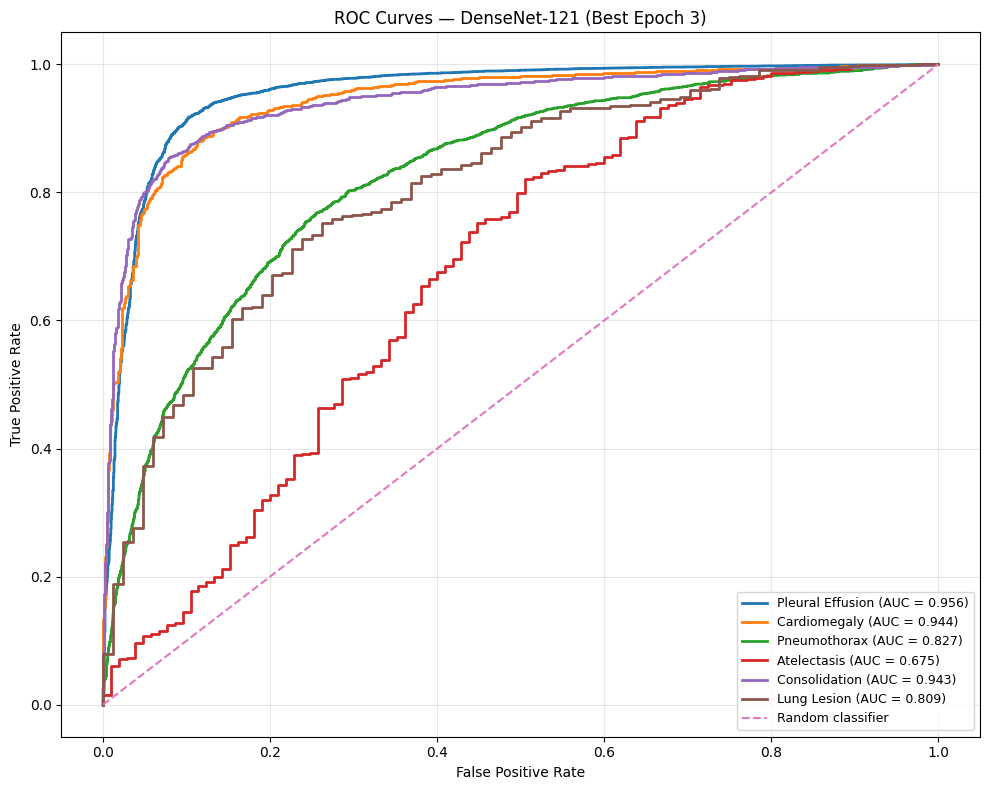

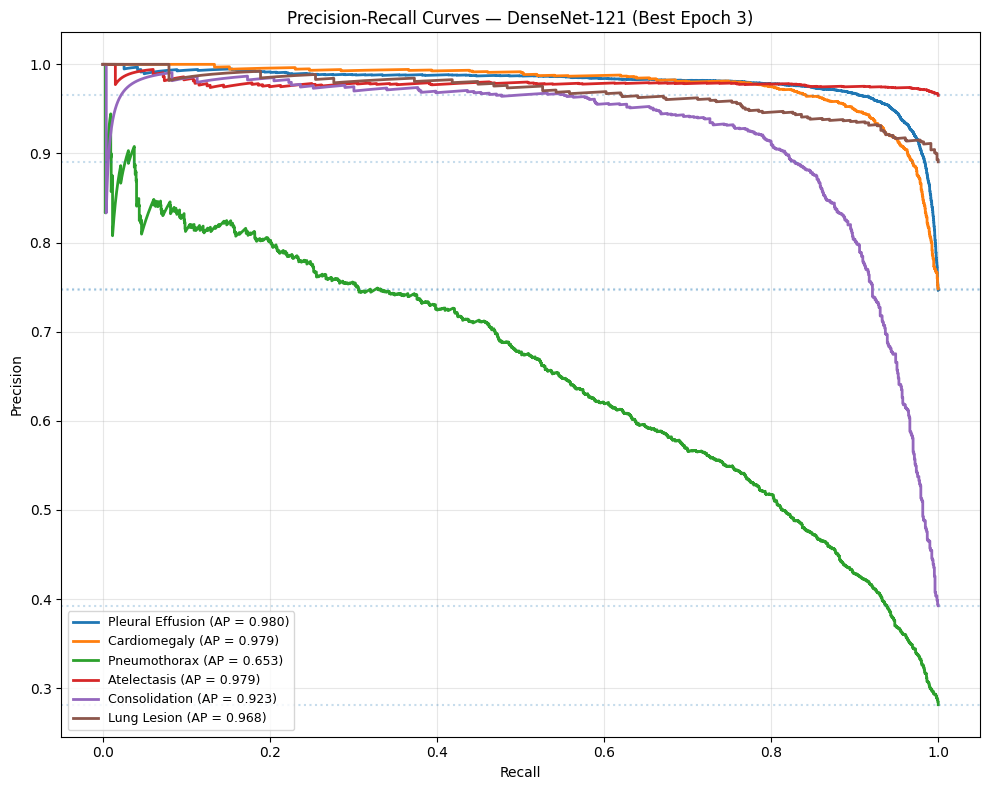

CURVE GENERATION COMPLETED
ROC curve: /kaggle/working/m3_baseline/evaluation/roc_curves.png
PR curve: /kaggle/working/m3_baseline/evaluation/precision_recall_curves.png
Both figures saved at 300 DPI.


In [46]:
# ============================================================
# CELL 88 — ROC AND PRECISION-RECALL CURVES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")
PREDICTIONS_PATH = OUTPUT_DIR / "validation_predictions.npz"

data = np.load(PREDICTIONS_PATH, allow_pickle=True)

y_true = data["y_true"]
y_mask = data["y_mask"].astype(bool)
y_prob = data["y_prob"]

findings = target_findings

# ------------------------------------------------------------
# 1. ROC CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

for i, finding in enumerate(findings):

    observed = y_mask[:, i]
    labels = y_true[observed, i].astype(int)
    probabilities = y_prob[observed, i]

    fpr, tpr, _ = roc_curve(labels, probabilities)
    auc = roc_auc_score(labels, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{finding} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — DenseNet-121 (Best Epoch 3)")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()

roc_path = OUTPUT_DIR / "roc_curves.png"
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 2. PRECISION-RECALL CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

for i, finding in enumerate(findings):

    observed = y_mask[:, i]
    labels = y_true[observed, i].astype(int)
    probabilities = y_prob[observed, i]

    precision, recall, _ = precision_recall_curve(
        labels, probabilities
    )

    ap = average_precision_score(labels, probabilities)
    prevalence = labels.mean()

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{finding} (AP = {ap:.3f})"
    )

    # Class prevalence baseline
    plt.axhline(
        prevalence,
        linestyle=":",
        alpha=0.25
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — DenseNet-121 (Best Epoch 3)")
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()

pr_path = OUTPUT_DIR / "precision_recall_curves.png"
plt.savefig(pr_path, dpi=300, bbox_inches="tight")
plt.show()

print("=" * 65)
print("CURVE GENERATION COMPLETED")
print("=" * 65)
print("ROC curve:", roc_path)
print("PR curve:", pr_path)
print("Both figures saved at 300 DPI.")

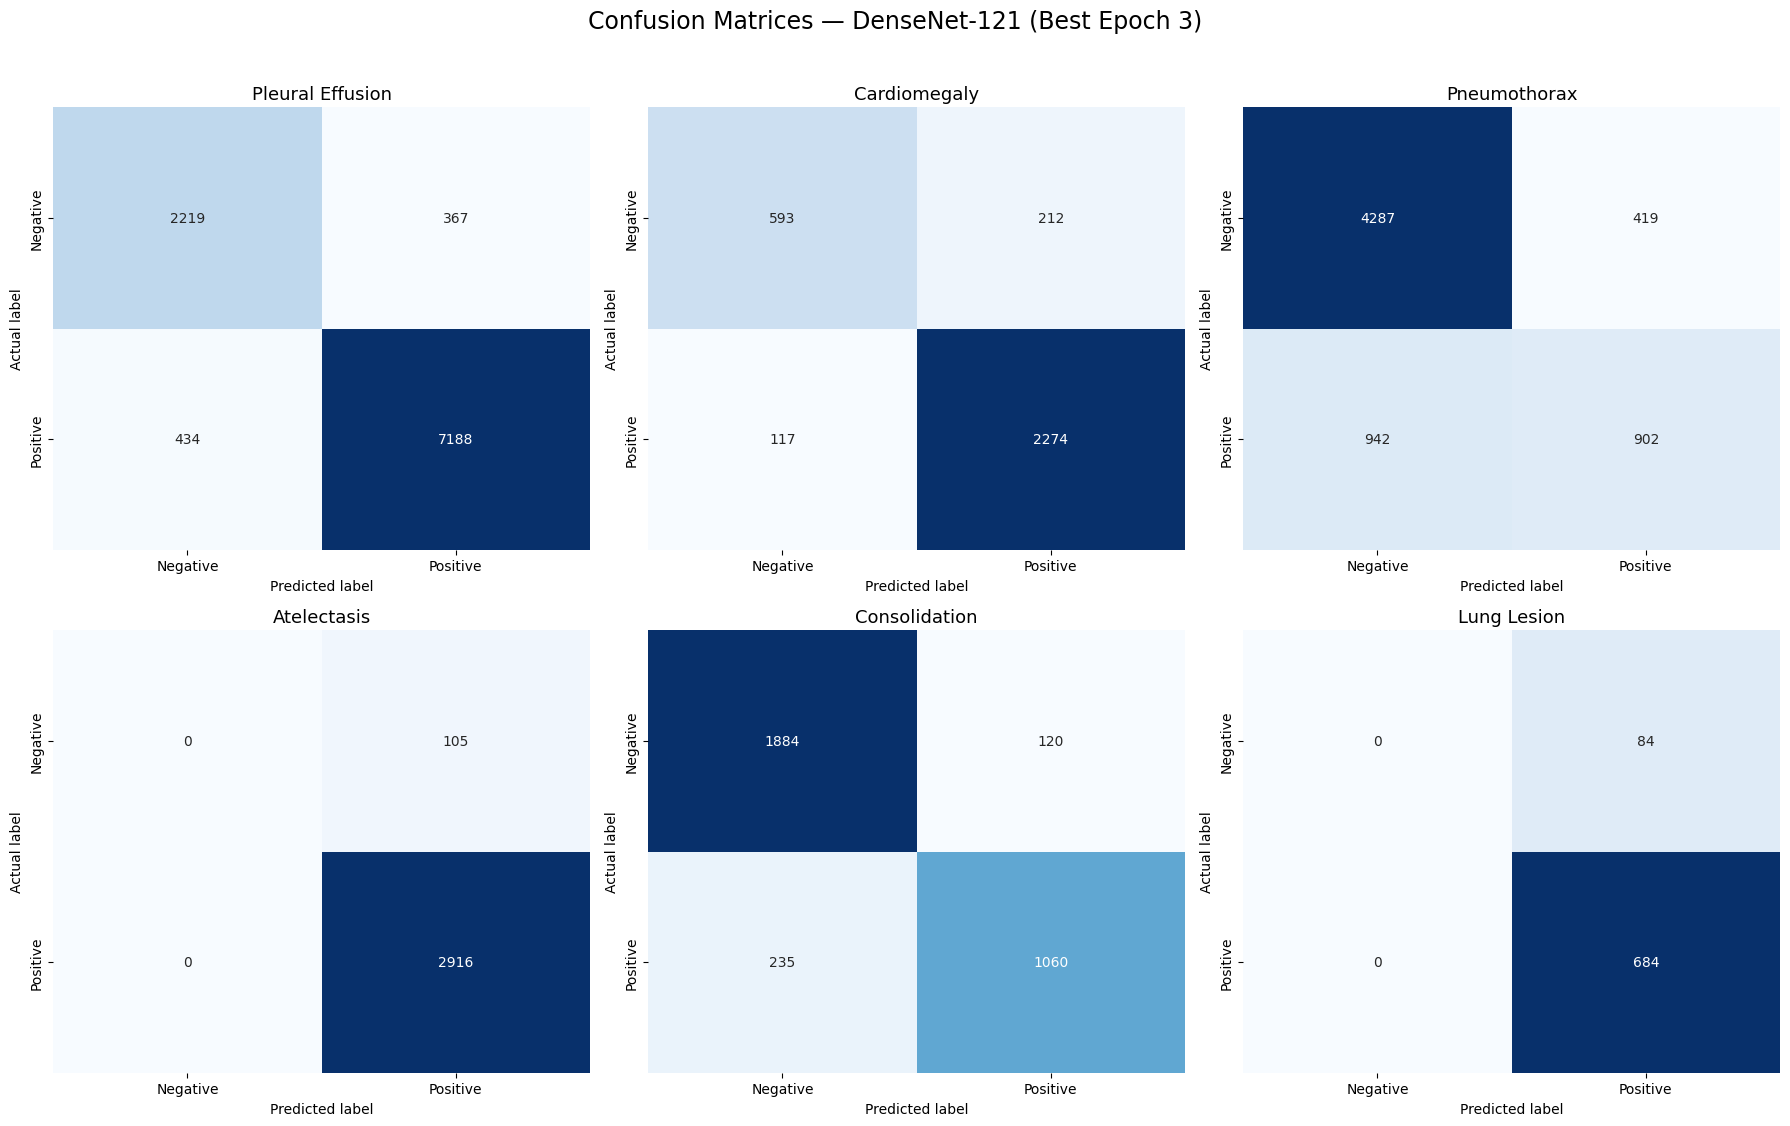

Confusion matrices saved: /kaggle/working/m3_baseline/evaluation/confusion_matrices.png
Threshold: 0.5


In [47]:
# ============================================================
# CELL 89 — CONFUSION MATRIX VISUALIZATIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")

data = np.load(
    OUTPUT_DIR / "validation_predictions.npz",
    allow_pickle=True
)

y_true = data["y_true"]
y_mask = data["y_mask"].astype(bool)
y_prob = data["y_prob"]

THRESHOLD = 0.5

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, finding in enumerate(target_findings):

    observed = y_mask[:, i]

    true_labels = y_true[observed, i].astype(int)
    predicted_labels = (
        y_prob[observed, i] >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[i]
    )

    axes[i].set_title(finding, fontsize=13)
    axes[i].set_xlabel("Predicted label")
    axes[i].set_ylabel("Actual label")

fig.suptitle(
    "Confusion Matrices — DenseNet-121 (Best Epoch 3)",
    fontsize=17,
    y=1.02
)

plt.tight_layout()

cm_path = OUTPUT_DIR / "confusion_matrices.png"

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved:", cm_path)
print("Threshold:", THRESHOLD)

In [48]:
# ============================================================
# CELL 90 — PER-FINDING CLASSIFICATION THRESHOLD ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import precision_recall_curve

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")

data = np.load(
    OUTPUT_DIR / "validation_predictions.npz",
    allow_pickle=True
)

y_true = data["y_true"]
y_mask = data["y_mask"].astype(bool)
y_prob = data["y_prob"]

thresholds_to_test = np.arange(0.10, 0.91, 0.05)

rows = []

for i, finding in enumerate(target_findings):

    observed = y_mask[:, i]

    labels = y_true[observed, i].astype(int)
    probabilities = y_prob[observed, i]

    precision, recall, thresholds = precision_recall_curve(
        labels, probabilities
    )

    # F1 values correspond to the thresholds array
    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = int(np.argmax(f1_values))

    best_threshold = float(thresholds[best_index])

    for threshold in thresholds_to_test:

        predictions = (probabilities >= threshold).astype(int)

        tp = int(np.sum((predictions == 1) & (labels == 1)))
        fp = int(np.sum((predictions == 1) & (labels == 0)))
        fn = int(np.sum((predictions == 0) & (labels == 1)))

        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0

        f1 = (
            2 * p * r / (p + r)
            if p + r else 0.0
        )

        rows.append({
            "Finding": finding,
            "Threshold": round(float(threshold), 2),
            "Precision": p,
            "Recall": r,
            "F1": f1,
            "Best_F1_Threshold": best_threshold
        })

threshold_df = pd.DataFrame(rows)

summary = (
    threshold_df.groupby("Finding")
    .first()
    .reset_index()
)

print("=" * 75)
print("BEST F1 THRESHOLD PER FINDING")
print("=" * 75)

for _, row in summary.iterrows():
    print(
        f"{row['Finding']}: "
        f"threshold = {row['Best_F1_Threshold']:.4f}"
    )

print("\nTHRESHOLD COMPARISON")
display(
    threshold_df[
        threshold_df["Threshold"].isin([0.25, 0.40, 0.50, 0.60, 0.75])
    ].round(4)
)

output_path = OUTPUT_DIR / "threshold_analysis.csv"
threshold_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

BEST F1 THRESHOLD PER FINDING
Atelectasis: threshold = 0.6043
Cardiomegaly: threshold = 0.5068
Consolidation: threshold = 0.3710
Lung Lesion: threshold = 0.7794
Pleural Effusion: threshold = 0.4031
Pneumothorax: threshold = 0.2878

THRESHOLD COMPARISON


,Finding,Threshold,Precision,Recall,F1,Best_F1_Threshold
3,Pleural Effusion,0.25,0.9262,0.9679,0.9466,0.4031
6,Pleural Effusion,0.40,0.9443,0.9521,0.9482,0.4031
8,Pleural Effusion,0.50,0.9514,0.9431,0.9472,0.4031
10,Pleural Effusion,0.60,0.9562,0.9334,0.9446,0.4031
13,Pleural Effusion,0.75,0.9655,0.9057,0.9346,0.4031
20,Cardiomegaly,0.25,0.8371,0.9845,0.9049,0.5068
23,Cardiomegaly,0.40,0.8892,0.9699,0.9278,0.5068
25,Cardiomegaly,0.50,0.9147,0.9511,0.9325,0.5068
27,Cardiomegaly,0.60,0.9309,0.9297,0.9303,0.5068
30,Cardiomegaly,0.75,0.9526,0.8904,0.9204,0.5068



Saved: /kaggle/working/m3_baseline/evaluation/threshold_analysis.csv


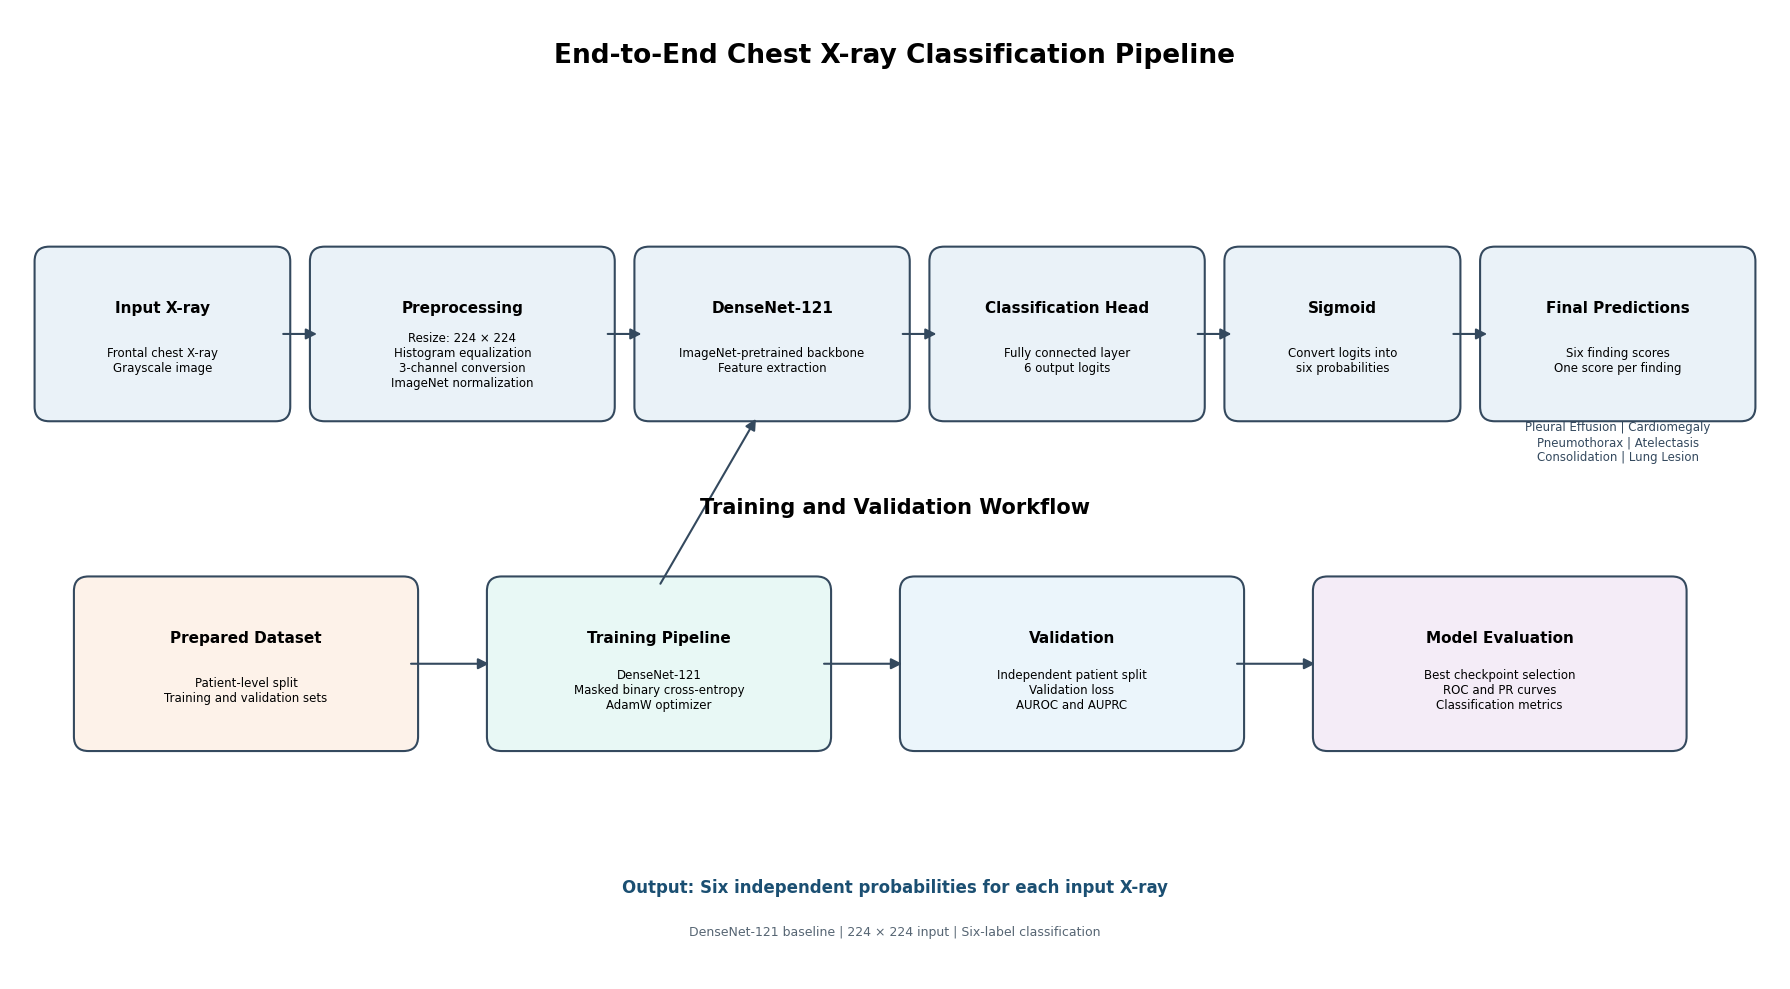

END-TO-END PIPELINE DIAGRAM CREATED
Saved: /kaggle/working/m3_baseline/evaluation/end_to_end_pipeline.png


In [50]:
# ============================================================
# CELL 101 — END-TO-END MODELING PIPELINE DIAGRAM
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(18, 10))

ax.set_xlim(0, 18)
ax.set_ylim(0, 10)
ax.axis("off")

def add_box(x, y, w, h, title, details="", color="#EAF2F8"):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="#34495E",
        facecolor=color
    )
    ax.add_patch(box)

    ax.text(
        x + w / 2, y + h * 0.68,
        title,
        ha="center", va="center",
        fontsize=11, fontweight="bold"
    )

    if details:
        ax.text(
            x + w / 2, y + h * 0.32,
            details,
            ha="center", va="center",
            fontsize=8.5,
            wrap=True
        )

def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=16,
        linewidth=1.5,
        color="#34495E"
    )
    ax.add_patch(arrow)

# Main inference pipeline
ax.text(
    9, 9.45,
    "End-to-End Chest X-ray Classification Pipeline",
    ha="center",
    fontsize=19,
    fontweight="bold"
)

boxes = [
    (0.4, 5.9, 2.3, 1.5, "Input X-ray",
     "Frontal chest X-ray\nGrayscale image"),

    (3.2, 5.9, 2.8, 1.5, "Preprocessing",
     "Resize: 224 × 224\nHistogram equalization\n3-channel conversion\nImageNet normalization"),

    (6.5, 5.9, 2.5, 1.5, "DenseNet-121",
     "ImageNet-pretrained backbone\nFeature extraction"),

    (9.5, 5.9, 2.5, 1.5, "Classification Head",
     "Fully connected layer\n6 output logits"),

    (12.5, 5.9, 2.1, 1.5, "Sigmoid",
     "Convert logits into\nsix probabilities"),

    (15.1, 5.9, 2.5, 1.5, "Final Predictions",
     "Six finding scores\nOne score per finding")
]

for box in boxes:
    add_box(*box)

for i in range(len(boxes) - 1):
    x1 = boxes[i][0] + boxes[i][2]
    x2 = boxes[i + 1][0]
    y = 6.65
    add_arrow(x1 + 0.05, y, x2 - 0.05, y)

# Training and validation section
ax.text(
    9, 4.8,
    "Training and Validation Workflow",
    ha="center",
    fontsize=15,
    fontweight="bold"
)

add_box(
    0.8, 2.5, 3.2, 1.5,
    "Prepared Dataset",
    "Patient-level split\nTraining and validation sets",
    "#FDF2E9"
)

add_box(
    5.0, 2.5, 3.2, 1.5,
    "Training Pipeline",
    "DenseNet-121\nMasked binary cross-entropy\nAdamW optimizer",
    "#E8F8F5"
)

add_box(
    9.2, 2.5, 3.2, 1.5,
    "Validation",
    "Independent patient split\nValidation loss\nAUROC and AUPRC",
    "#EBF5FB"
)

add_box(
    13.4, 2.5, 3.5, 1.5,
    "Model Evaluation",
    "Best checkpoint selection\nROC and PR curves\nClassification metrics",
    "#F4ECF7"
)

add_arrow(4.05, 3.25, 4.9, 3.25)
add_arrow(8.25, 3.25, 9.1, 3.25)
add_arrow(12.45, 3.25, 13.3, 3.25)

# Training-to-model connection
add_arrow(6.6, 4.05, 7.6, 5.8)

# Output labels
ax.text(
    16.35, 5.35,
    "Pleural Effusion | Cardiomegaly\n"
    "Pneumothorax | Atelectasis\n"
    "Consolidation | Lung Lesion",
    ha="center",
    fontsize=8.5,
    color="#34495E"
)

ax.text(
    9, 0.9,
    "Output: Six independent probabilities for each input X-ray",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#1B4F72"
)

ax.text(
    9, 0.45,
    "DenseNet-121 baseline | 224 × 224 input | Six-label classification",
    ha="center",
    fontsize=9,
    color="#566573"
)

plt.tight_layout()

diagram_path = OUTPUT_DIR / "end_to_end_pipeline.png"

plt.savefig(
    diagram_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("=" * 65)
print("END-TO-END PIPELINE DIAGRAM CREATED")
print("=" * 65)
print("Saved:", diagram_path)

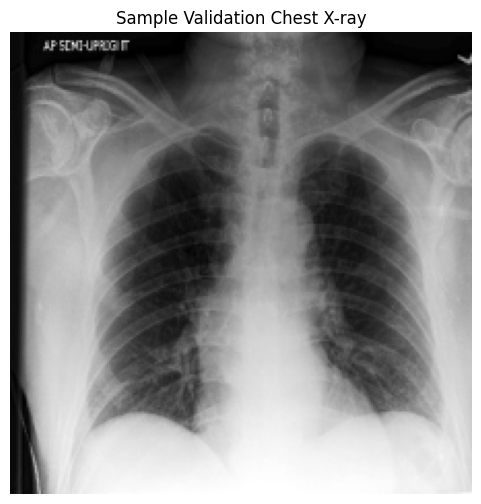

DENSENET-121 — SAMPLE INFERENCE RESULTS
Input image: /kaggle/input/datasets/ashery/chexpert/train/patient00040/study1/view1_frontal.jpg
Input shape: (1, 3, 224, 224)
Output shape: (1, 6)

PREDICTIONS
----------------------------------------------------------------------
Pleural Effusion     | Probability: 0.0062 | Prediction: Negative | Reference label: Unknown / Uncertain
Cardiomegaly         | Probability: 0.1626 | Prediction: Negative | Reference label: Unknown / Uncertain
Pneumothorax         | Probability: 0.0450 | Prediction: Negative | Reference label: 1
Atelectasis          | Probability: 0.8639 | Prediction: Positive | Reference label: Unknown / Uncertain
Consolidation        | Probability: 0.0089 | Prediction: Negative | Reference label: Unknown / Uncertain
Lung Lesion          | Probability: 0.8843 | Prediction: Positive | Reference label: Unknown / Uncertain

Inference completed successfully.


In [51]:
# ============================================================
# CELL 102 — SAMPLE X-RAY INFERENCE DEMONSTRATION
# ============================================================

import torch
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model.eval()

# Get one actual validation image
sample_batch = next(iter(valid_loader))

image = sample_batch["image"][0:1].to(DEVICE)
true_labels = sample_batch["target"][0].cpu().numpy()
label_mask = sample_batch["mask"][0].cpu().numpy()
image_path = sample_batch["image_path"][0]

# Generate predictions
with torch.inference_mode():
    logits = model(image)
    probabilities = torch.sigmoid(logits)[0].cpu().numpy()

# Convert probabilities to binary predictions using threshold 0.5
predictions = (probabilities >= 0.5).astype(int)

# Display image after reversing ImageNet normalization
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

display_image = (
    sample_batch["image"][0].cpu() * std + mean
).clamp(0, 1)

display_image = display_image.permute(1, 2, 0).numpy()

# Display X-ray
plt.figure(figsize=(6, 6))
plt.imshow(display_image, cmap="gray")
plt.title("Sample Validation Chest X-ray")
plt.axis("off")
plt.show()

# Display predictions
print("=" * 70)
print("DENSENET-121 — SAMPLE INFERENCE RESULTS")
print("=" * 70)

print("Input image:", image_path)
print("Input shape:", tuple(image.shape))
print("Output shape:", tuple(logits.shape))

print("\nPREDICTIONS")
print("-" * 70)

for i, finding in enumerate(target_findings):

    predicted_label = (
        "Positive" if predictions[i] == 1 else "Negative"
    )

    actual_label = (
        str(int(true_labels[i]))
        if label_mask[i]
        else "Unknown / Uncertain"
    )

    print(
        f"{finding:20s} | "
        f"Probability: {probabilities[i]:.4f} | "
        f"Prediction: {predicted_label:8s} | "
        f"Reference label: {actual_label}"
    )

print("\nInference completed successfully.")

In [52]:
# ============================================================
# CELL 103 — SAVE SAMPLE INFERENCE RESULTS
# ============================================================

import pandas as pd
import json
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/m3_baseline/evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

inference_rows = []

for i, finding in enumerate(target_findings):
    inference_rows.append({
        "finding": finding,
        "probability": float(probabilities[i]),
        "predicted_label": int(predictions[i]),
        "predicted_class": (
            "Positive" if predictions[i] == 1 else "Negative"
        ),
        "reference_label": (
            int(true_labels[i]) if label_mask[i] else None
        ),
        "reference_status": (
            "Definite" if label_mask[i] else "Unknown/Uncertain"
        )
    })

inference_df = pd.DataFrame(inference_rows)

csv_path = OUTPUT_DIR / "sample_inference_results.csv"
json_path = OUTPUT_DIR / "sample_inference_results.json"

inference_df.to_csv(csv_path, index=False)

with open(json_path, "w") as f:
    json.dump({
        "model": "DenseNet-121",
        "checkpoint": "best_model.pth",
        "input_image": str(image_path),
        "input_shape": list(image.shape),
        "output_shape": list(logits.shape),
        "classification_threshold": 0.5,
        "predictions": inference_rows
    }, f, indent=4)

print("SAMPLE INFERENCE ARTIFACTS SAVED")
print("-" * 60)
print(inference_df.to_string(index=False))
print("\nCSV:", csv_path)
print("JSON:", json_path)

SAMPLE INFERENCE ARTIFACTS SAVED
------------------------------------------------------------
         finding  probability  predicted_label predicted_class  reference_label  reference_status
Pleural Effusion     0.006222                0        Negative              NaN Unknown/Uncertain
    Cardiomegaly     0.162580                0        Negative              NaN Unknown/Uncertain
    Pneumothorax     0.045046                0        Negative              1.0          Definite
     Atelectasis     0.863944                1        Positive              NaN Unknown/Uncertain
   Consolidation     0.008881                0        Negative              NaN Unknown/Uncertain
     Lung Lesion     0.884266                1        Positive              NaN Unknown/Uncertain

CSV: /kaggle/working/m3_baseline/evaluation/sample_inference_results.csv
JSON: /kaggle/working/m3_baseline/evaluation/sample_inference_results.json


In [53]:
# ============================================================
# CELL 104 — CONSOLIDATE REQUIREMENT 5 DELIVERABLES
# ============================================================

from pathlib import Path
import zipfile
import json

BASE_DIR = Path("/kaggle/working/m3_baseline")
EVAL_DIR = BASE_DIR / "evaluation"

OUTPUT_ZIP = Path(
    "/kaggle/working/requirement_5_end_to_end_deliverables.zip"
)

files_to_include = [
    BASE_DIR / "best_model.pth",
    BASE_DIR / "baseline_metrics.json",
    EVAL_DIR / "full_validation_metrics.json",
    EVAL_DIR / "validation_predictions.npz",
    EVAL_DIR / "roc_curves.png",
    EVAL_DIR / "precision_recall_curves.png",
    EVAL_DIR / "confusion_matrices.png",
    EVAL_DIR / "end_to_end_pipeline.png",
    EVAL_DIR / "sample_inference_results.csv",
    EVAL_DIR / "sample_inference_results.json",
    EVAL_DIR / "threshold_analysis.csv"
]

print("=" * 65)
print("REQUIREMENT 5 DELIVERABLE VERIFICATION")
print("=" * 65)

missing = []

for file in files_to_include:
    if file.exists():
        print(f"[OK] {file.name} — {file.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"[MISSING] {file}")
        missing.append(str(file))

if missing:
    raise FileNotFoundError(
        "Missing deliverables:\n" + "\n".join(missing)
    )

# Create archive
with zipfile.ZipFile(
    OUTPUT_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file in files_to_include:
        archive.write(
            file,
            arcname=str(file.relative_to(BASE_DIR))
        )

# Verify archive contents
with zipfile.ZipFile(OUTPUT_ZIP, "r") as archive:
    bad_file = archive.testzip()
    if bad_file:
        raise RuntimeError(f"Archive verification failed: {bad_file}")

    print("\nARCHIVE CONTENTS")
    for name in archive.namelist():
        print("-", name)

print("\n" + "=" * 65)
print("REQUIREMENT 5 ARCHIVE CREATED AND VERIFIED")
print("=" * 65)
print("Location:", OUTPUT_ZIP)
print(f"Size: {OUTPUT_ZIP.stat().st_size / (1024**2):.2f} MB")

REQUIREMENT 5 DELIVERABLE VERIFICATION
[OK] best_model.pth — 27.09 MB
[OK] baseline_metrics.json — 0.01 MB
[OK] full_validation_metrics.json — 0.00 MB
[OK] validation_predictions.npz — 0.50 MB
[OK] roc_curves.png — 0.30 MB
[OK] precision_recall_curves.png — 0.32 MB
[OK] confusion_matrices.png — 0.28 MB
[OK] end_to_end_pipeline.png — 0.46 MB
[OK] sample_inference_results.csv — 0.00 MB
[OK] sample_inference_results.json — 0.00 MB
[OK] threshold_analysis.csv — 0.01 MB

ARCHIVE CONTENTS
- best_model.pth
- baseline_metrics.json
- evaluation/full_validation_metrics.json
- evaluation/validation_predictions.npz
- evaluation/roc_curves.png
- evaluation/precision_recall_curves.png
- evaluation/confusion_matrices.png
- evaluation/end_to_end_pipeline.png
- evaluation/sample_inference_results.csv
- evaluation/sample_inference_results.json
- evaluation/threshold_analysis.csv

REQUIREMENT 5 ARCHIVE CREATED AND VERIFIED
Location: /kaggle/working/requirement_5_end_to_end_deliverables.zip
Size: 26.80 MB

In [54]:
# ============================================================
# CELL 105 — PUBLISH REQUIREMENT 5 SUBMISSION ARCHIVE
# ============================================================

from pathlib import Path
import subprocess
import shutil
import json
import time

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

ARCHIVE = Path(
    "/kaggle/working/requirement_5_end_to_end_deliverables.zip"
)

assert ARCHIVE.exists(), "Requirement 5 archive not found."

UPLOAD_DIR = Path("/kaggle/working/requirement_5_upload")
UPLOAD_DIR.mkdir(exist_ok=True)

shutil.copy2(ARCHIVE, UPLOAD_DIR / ARCHIVE.name)

metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}]
}

with open(UPLOAD_DIR / "dataset-metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Uploading:", ARCHIVE.name)
print(f"Size: {ARCHIVE.stat().st_size / (1024**2):.2f} MB")

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", str(UPLOAD_DIR),
        "-m", "Milestone 3 Requirement 5 final end-to-end deliverables"
    ],
    capture_output=True,
    text=True
)

print("\nUPLOAD OUTPUT:")
print(result.stdout)

if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Kaggle upload failed.")

# Verify the archive appears in the dataset file listing.
print("\nChecking published dataset files...")

verified = False

for attempt in range(1, 19):
    listing = subprocess.run(
        ["kaggle", "datasets", "files", DATASET_ID],
        capture_output=True,
        text=True
    )

    combined_output = listing.stdout + listing.stderr

    if listing.returncode == 0 and ARCHIVE.name in combined_output:
        verified = True
        print(combined_output)
        break

    print(f"Verification attempt {attempt}/18: archive not listed yet.")
    time.sleep(10)

if not verified:
    raise RuntimeError(
        "Upload was submitted, but the archive could not yet "
        "be verified in the dataset file listing."
    )

print("\nSUCCESS: Requirement 5 archive is listed in the Kaggle dataset.")

Uploading: requirement_5_end_to_end_deliverables.zip
Size: 26.80 MB

UPLOAD OUTPUT:
Starting upload for file requirement_5_end_to_end_deliverables.zip
Upload successful: requirement_5_end_to_end_deliverables.zip (27MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints


  0%|          | 0.00/26.8M [00:00<?, ?B/s]
  4%|▍         | 1.17M/26.8M [00:00<00:02, 9.55MB/s]
 36%|███▋      | 9.73M/26.8M [00:00<00:00, 51.8MB/s]
 99%|█████████▉| 26.5M/26.8M [00:00<00:00, 78.0MB/s]
100%|██████████| 26.8M/26.8M [00:01<00:00, 26.4MB/s]


Checking published dataset files...
Verification attempt 1/18: archive not listed yet.
Verification attempt 2/18: archive not listed yet.
Verification attempt 3/18: archive not listed yet.
Verification attempt 4/18: archive not listed yet.
Verification attempt 5/18: archive not listed yet.
Verification attempt 6/18: archive not listed yet.
Verification attempt 7/18: archive not listed yet.
V

RuntimeError: Upload was submitted, but the archive could not yet be verified in the dataset file listing.

In [55]:
# ============================================================
# CELL 106 — CHECK KAGGLE DATASET PUBLICATION
# ============================================================

import subprocess
import json

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"
ARCHIVE_NAME = "requirement_5_end_to_end_deliverables.zip"

def run_kaggle(args):
    result = subprocess.run(
        ["kaggle"] + args,
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.stderr:
        print("STDERR:", result.stderr)
    return result

print("=" * 65)
print("1. DATASET STATUS")
print("=" * 65)

status_result = run_kaggle([
    "datasets", "status", DATASET_ID, "--format", "json"
])

status_data = {}

try:
    status_data = json.loads(status_result.stdout)
    print("Parsed status:", json.dumps(status_data, indent=2))
except Exception:
    print("Could not parse status as JSON.")

print("\n" + "=" * 65)
print("2. LATEST DATASET FILE LIST")
print("=" * 65)

latest_result = run_kaggle([
    "datasets", "files", DATASET_ID, "--page-size", "200"
])

print("\nArchive found in latest listing:",
      ARCHIVE_NAME in latest_result.stdout)

print("\n" + "=" * 65)
print("3. CURRENT VERSION FILE LIST")
print("=" * 65)

version_number = status_data.get("currentVersionNumber")

if version_number is not None:
    print("Current version:", version_number)

    version_result = run_kaggle([
        "datasets", "files",
        f"{DATASET_ID}/{version_number}",
        "--page-size", "200"
    ])

    print("\nArchive found in version listing:",
          ARCHIVE_NAME in version_result.stdout)
else:
    print("Version number unavailable; inspect the status output above.")

print("\nDIAGNOSTIC COMPLETE.")

1. DATASET STATUS

STDERR: usage: kaggle [-h] [-v] [-W]
              {competitions,c,datasets,d,kernels,k,models,m,files,f,benchmarks,b,config,auth} ...
kaggle: error: unrecognized arguments: --format json

Could not parse status as JSON.

2. LATEST DATASET FILE LIST
name                                          size  creationDate                
----------------------------------------  --------  --------------------------  
baseline_metrics.json                         5647  2026-11-06 04:24:36.200000  
best_model.pth                            28411048  2026-11-06 04:24:36.748000  
evaluation/confusion_matrices.png           296974  2026-11-06 04:24:36.108000  
evaluation/end_to_end_pipeline.png          478524  2026-11-06 04:24:36.200000  
evaluation/full_validation_metrics.json       3074  2026-11-06 04:24:36.082000  
evaluation/precision_recall_curves.png      338866  2026-11-06 04:24:36.096000  
evaluation/roc_curves.png                   313104  2026-11-06 04:24:36.076000  
ev

In [56]:
# ============================================================
# CELL 107 — CHECK KAGGLE DATASET STATUS
# ============================================================

import subprocess

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

commands = [
    ["kaggle", "datasets", "status", DATASET_ID],
    ["kaggle", "datasets", "files", DATASET_ID]
]

for command in commands:
    print("\nCOMMAND:", " ".join(command))
    print("-" * 65)

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.stderr:
        print("Additional output:", result.stderr)

    print("Exit code:", result.returncode)


COMMAND: kaggle datasets status kautilyasagili/dsai-lab-checkpoints
-----------------------------------------------------------------
ready
Exit code: 0

COMMAND: kaggle datasets files kautilyasagili/dsai-lab-checkpoints
-----------------------------------------------------------------
name                                          size  creationDate                
----------------------------------------  --------  --------------------------  
baseline_metrics.json                         5647  2026-11-06 04:24:36.200000  
best_model.pth                            28411048  2026-11-06 04:24:36.748000  
evaluation/confusion_matrices.png           296974  2026-11-06 04:24:36.108000  
evaluation/end_to_end_pipeline.png          478524  2026-11-06 04:24:36.200000  
evaluation/full_validation_metrics.json       3074  2026-11-06 04:24:36.082000  
evaluation/precision_recall_curves.png      338866  2026-11-06 04:24:36.096000  
evaluation/roc_curves.png                   313104  2026-11-06 0

In [57]:
# ============================================================
# CELL 108 — VERIFY LOCAL REQUIREMENT 5 ARCHIVE
# ============================================================

from pathlib import Path
import os

archive_path = Path(
    "/kaggle/working/requirement_5_end_to_end_deliverables.zip"
)

print("Archive exists:", archive_path.exists())

if archive_path.exists():
    print("Archive size (MB):", round(
        archive_path.stat().st_size / (1024 * 1024), 2
    ))
else:
    print("Archive not found at expected path.")

print("\nOther matching ZIP files:")
for path in Path("/kaggle/working").glob("*requirement*zip"):
    print(path, round(path.stat().st_size / (1024 * 1024), 2), "MB")

Archive exists: True
Archive size (MB): 26.8

Other matching ZIP files:
/kaggle/working/requirement_5_end_to_end_deliverables.zip 26.8 MB


In [58]:
# ============================================================
# CELL 109 — REPUBLISH REQUIREMENT 5 ARCHIVE
# ============================================================

import subprocess
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"
ARCHIVE = Path(
    "/kaggle/working/requirement_5_end_to_end_deliverables.zip"
)

assert ARCHIVE.exists(), "Archive is missing."
assert ARCHIVE.stat().st_size > 0, "Archive is empty."

command = [
    "kaggle", "datasets", "version",
    "-p", "/kaggle/working",
    "-m", "Requirement 5 end-to-end pipeline deliverables",
    "-r", "zip"
]

print("Publishing:", ARCHIVE.name)
print("Size (MB):", round(ARCHIVE.stat().st_size / (1024 * 1024), 2))

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)
print("\nExit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Kaggle upload command failed. Share the output.")

Publishing: requirement_5_end_to_end_deliverables.zip
Size (MB): 26.8

STDOUT:
Metadata file not found: dataset-metadata.json


STDERR:
 

Exit code: 1


RuntimeError: Kaggle upload command failed. Share the output.

In [59]:
# ============================================================
# CELL 110 — CREATE DATASET METADATA
# ============================================================

import json
from pathlib import Path

metadata = {
    "title": "DSAI Lab Checkpoints",
    "id": "kautilyasagili/dsai-lab-checkpoints",
    "licenses": [
        {"name": "CC0-1.0"}
    ]
}

metadata_path = Path("/kaggle/working/dataset-metadata.json")

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata created:", metadata_path.exists())
print(metadata_path.read_text())

Metadata created: True
{
    "title": "DSAI Lab Checkpoints",
    "id": "kautilyasagili/dsai-lab-checkpoints",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ]
}


In [60]:
# ============================================================
# CELL 111 — RETRIEVE ORIGINAL KAGGLE METADATA
# ============================================================

import subprocess
from pathlib import Path
import json

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"
METADATA_DIR = Path("/kaggle/working/original_dataset_metadata")
METADATA_DIR.mkdir(exist_ok=True)

result = subprocess.run(
    [
        "kaggle", "datasets", "metadata",
        DATASET_ID,
        "-p", str(METADATA_DIR)
    ],
    capture_output=True,
    text=True
)

print("Exit code:", result.returncode)
print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)

metadata_file = METADATA_DIR / "dataset-metadata.json"

if result.returncode == 0 and metadata_file.exists():
    metadata = json.loads(metadata_file.read_text())
    print("\nOriginal dataset metadata:")
    print(json.dumps(metadata, indent=4))
else:
    print("\nOriginal metadata could not be retrieved.")

Exit code: 0
STDOUT:
Downloaded metadata to /kaggle/working/original_dataset_metadata/dataset-metadata.json

STDERR:
 

Original dataset metadata:
{
    "info": {
        "datasetId": 13121201,
        "datasetSlug": "dsai-lab-checkpoints",
        "ownerUser": "kautilyasagili",
        "usabilityRating": 0.35294117647058826,
        "totalDownloads": 7,
        "title": "DSAI Lab Training Checkpoints",
        "subtitle": "",
        "description": "Private DSAI Lab model checkpoint storage.",
        "isPrivate": true,
        "keywords": [
            "pre-trained model"
        ],
        "licenses": [
            {
                "name": "CC0-1.0"
            }
        ],
        "expectedUpdateFrequency": "not specified"
    }
}


In [61]:
# ============================================================
# CELL 112 — PREPARE REQUIREMENT 5 UPLOAD
# ============================================================

import json
import shutil
from pathlib import Path

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"

SOURCE_ARCHIVE = Path(
    "/kaggle/working/requirement_5_end_to_end_deliverables.zip"
)

UPLOAD_DIR = Path(
    "/kaggle/working/requirement_5_upload"
)

assert SOURCE_ARCHIVE.exists(), "Requirement 5 archive is missing."

# Create a clean upload directory
UPLOAD_DIR.mkdir(exist_ok=True)

# Copy the archive
destination = UPLOAD_DIR / SOURCE_ARCHIVE.name
shutil.copy2(SOURCE_ARCHIVE, destination)

# Use the original dataset's metadata
metadata = {
    "title": "DSAI Lab Training Checkpoints",
    "id": DATASET_ID,
    "licenses": [
        {"name": "CC0-1.0"}
    ]
}

metadata_path = UPLOAD_DIR / "dataset-metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Verify contents
print("Upload folder contents:")

for path in UPLOAD_DIR.iterdir():
    print(
        path.name,
        f"({path.stat().st_size / (1024 * 1024):.2f} MB)"
    )

print("\nMetadata:")
print(metadata_path.read_text())

assert destination.stat().st_size == SOURCE_ARCHIVE.stat().st_size
print("\nUpload folder verification: PASSED")

Upload folder contents:
dataset-metadata.json (0.00 MB)
requirement_5_end_to_end_deliverables.zip (26.80 MB)

Metadata:
{
    "title": "DSAI Lab Training Checkpoints",
    "id": "kautilyasagili/dsai-lab-checkpoints",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ]
}

Upload folder verification: PASSED


In [62]:
# ============================================================
# CELL 113 — PUBLISH REQUIREMENT 5 ARCHIVE
# ============================================================

import subprocess

UPLOAD_DIR = "/kaggle/working/requirement_5_upload"

command = [
    "kaggle",
    "datasets",
    "version",
    "-p", UPLOAD_DIR,
    "-m", "Added Requirement 5 end-to-end pipeline deliverables",
    "-r", "zip"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("STDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)
print("\nExit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Dataset version publication failed.")

STDOUT:
Starting upload for file requirement_5_end_to_end_deliverables.zip
Upload successful: requirement_5_end_to_end_deliverables.zip (27MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/kautilyasagili/dsai-lab-checkpoints


STDERR:
 
  0%|          | 0.00/26.8M [00:00<?, ?B/s]
  4%|▍         | 1.09M/26.8M [00:00<00:02, 9.72MB/s]
 39%|███▊      | 10.4M/26.8M [00:00<00:00, 57.6MB/s]
 97%|█████████▋| 26.1M/26.8M [00:00<00:00, 94.7MB/s]
100%|██████████| 26.8M/26.8M [00:00<00:00, 30.0MB/s]


Exit code: 0


In [63]:
# ============================================================
# CELL 114 — VERIFY REQUIREMENT 5 PUBLICATION
# ============================================================

import subprocess
import time

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"
ARCHIVE_NAME = "requirement_5_end_to_end_deliverables.zip"

for attempt in range(1, 13):
    print(f"\nVerification attempt {attempt}/12")

    status = subprocess.run(
        ["kaggle", "datasets", "status", DATASET_ID],
        capture_output=True,
        text=True
    )

    print("Dataset status:", status.stdout.strip())

    files = subprocess.run(
        ["kaggle", "datasets", "files", DATASET_ID],
        capture_output=True,
        text=True
    )

    if files.returncode == 0 and ARCHIVE_NAME in files.stdout:
        print("\nSUCCESS: Requirement 5 archive is published.")
        print(files.stdout)
        break

    print("Archive not visible yet. Waiting 15 seconds...")
    time.sleep(15)

else:
    raise RuntimeError(
        "Upload was accepted, but the archive is not yet visible. "
        "Check the Kaggle dataset page."
    )


Verification attempt 1/12
Dataset status: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
ready
Archive not visible yet. Waiting 15 seconds...

Verification attempt 2/12
Dataset status: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
ready
Archive not visible yet. Waiting 15 seconds...

Verification attempt 3/12
Dataset status: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
ready
Archive not visible yet. Waiting 15 seconds...

Verification attempt 4/12
Dataset status: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
ready
Archive not visible yet. Waiting 15 seconds...

Verification attempt 5/12
Dataset status: Warning: Looks like y

RuntimeError: Upload was accepted, but the archive is not yet visible. Check the Kaggle dataset page.

In [64]:
# ============================================================
# CELL 115 — CHECK THE SPECIFIC DATASET VERSION
# ============================================================

import subprocess
import json

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"
ARCHIVE_NAME = "requirement_5_end_to_end_deliverables.zip"

# Get the current version number
result = subprocess.run(
    [
        "kaggle", "datasets", "status",
        DATASET_ID,
        "--format", "json(current_version_number)"
    ],
    capture_output=True,
    text=True
)

print("STATUS OUTPUT:")
print(result.stdout)
print("STATUS ERROR:")
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Could not retrieve the current dataset version.")

status_data = json.loads(result.stdout)
version_number = status_data.get("currentVersionNumber")

if version_number is None:
    version_number = status_data.get("current_version_number")

if version_number is None:
    raise RuntimeError(
        "Version number not found. Share the status output."
    )

print("\nCurrent dataset version:", version_number)

# List files belonging specifically to that version
version_handle = f"{DATASET_ID}/{version_number}"

files_result = subprocess.run(
    [
        "kaggle", "datasets", "files",
        version_handle,
        "--page-size", "200"
    ],
    capture_output=True,
    text=True
)

print("\nVERSION FILE LIST:")
print(files_result.stdout)

if files_result.returncode != 0:
    raise RuntimeError("Could not list files for this version.")

if ARCHIVE_NAME in files_result.stdout:
    print("\nSUCCESS: Requirement 5 archive is present in this version.")
else:
    print("\nArchive not found in this specific version.")

STATUS OUTPUT:

STATUS ERROR:
usage: kaggle [-h] [-v] [-W]
              {competitions,c,datasets,d,kernels,k,models,m,files,f,benchmarks,b,config,auth} ...
kaggle: error: unrecognized arguments: --format json(current_version_number)



RuntimeError: Could not retrieve the current dataset version.

In [65]:
# ============================================================
# CELL 116 — UPGRADE KAGGLE CLI
# ============================================================

import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "--upgrade", "kaggle==2.2.5"
    ],
    capture_output=True,
    text=True
)

print(result.stdout[-5000:])
print(result.stderr[-2000:])

if result.returncode != 0:
    raise RuntimeError("Kaggle CLI upgrade failed.")

print("\nInstalled Kaggle version:")
subprocess.run(["kaggle", "--version"])

  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2



Installed Kaggle version:
Kaggle CLI 2.2.5


CompletedProcess(args=['kaggle', '--version'], returncode=0)

In [66]:
# ============================================================
# CELL 117 — CHECK LATEST DATASET VERSION AND FILES
# ============================================================

import subprocess
import json

DATASET_ID = "kautilyasagili/dsai-lab-checkpoints"
ARCHIVE_NAME = "requirement_5_end_to_end_deliverables.zip"

# Retrieve dataset status in JSON
result = subprocess.run(
    [
        "kaggle", "datasets", "status",
        DATASET_ID,
        "--format", "json(current_version_number)"
    ],
    capture_output=True,
    text=True
)

print("Status output:", result.stdout)
print("Status errors:", result.stderr)

if result.returncode != 0:
    raise RuntimeError("Could not retrieve dataset version.")

status_data = json.loads(result.stdout)
version_number = status_data.get("currentVersionNumber")

if version_number is None:
    version_number = status_data.get("current_version_number")

if version_number is None:
    raise RuntimeError("Current version number not found.")

print("\nCurrent version:", version_number)

# Inspect files in this exact version
version_handle = f"{DATASET_ID}/{version_number}"

files_result = subprocess.run(
    [
        "kaggle", "datasets", "files",
        version_handle,
        "--page-size", "200"
    ],
    capture_output=True,
    text=True
)

print("\nFiles in latest version:")
print(files_result.stdout)

if files_result.returncode != 0:
    raise RuntimeError("Could not inspect dataset version.")

if ARCHIVE_NAME in files_result.stdout:
    print("\nSUCCESS: Requirement 5 archive is published.")
else:
    print("\nArchive is not present in this version.")

Status output: {"current_version_number": 44}
Status errors: 

Current version: 44

Files in latest version:
name                                          size  creationDate                
----------------------------------------  --------  --------------------------  
baseline_metrics.json                         5647  2026-11-06 04:30:43.897000  
best_model.pth                            28411048  2026-11-06 04:30:44.522000  
evaluation/confusion_matrices.png           296974  2026-11-06 04:30:43.929000  
evaluation/end_to_end_pipeline.png          478524  2026-11-06 04:30:43.977000  
evaluation/full_validation_metrics.json       3074  2026-11-06 04:30:43.891000  
evaluation/precision_recall_curves.png      338866  2026-11-06 04:30:43.934000  
evaluation/roc_curves.png                   313104  2026-11-06 04:30:43.907000  
evaluation/sample_inference_results.csv        460  2026-11-06 04:30:43.979000  
evaluation/sample_inference_results.json      1996  2026-11-06 04:30:43.972000  


In [67]:
# ============================================================
# CELL 118 — VERIFY REQUIREMENT 5 ARCHIVE CONTENTS
# ============================================================

import zipfile
import subprocess

ARCHIVE = (
    "/kaggle/working/requirement_5_end_to_end_deliverables.zip"
)
DATASET_VERSION = "kautilyasagili/dsai-lab-checkpoints/44"

# Read local archive contents
with zipfile.ZipFile(ARCHIVE, "r") as z:
    local_files = sorted(
        name for name in z.namelist()
        if not name.endswith("/")
    )

# Retrieve published version files
result = subprocess.run(
    ["kaggle", "datasets", "files", DATASET_VERSION,
     "--page-size", "200"],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

remote_output = result.stdout

print("LOCAL ARCHIVE CONTENTS:")
for name in local_files:
    print(" -", name)

print("\nPUBLISHED FILES:")
print(remote_output)

print("\nLOCAL ARCHIVE FILE COUNT:", len(local_files))

# Compare filenames, allowing for archive root folders
remote_lines = remote_output.splitlines()
remote_names = {
    line.split()[0]
    for line in remote_lines[2:]
    if line.strip()
}

missing = [
    name for name in local_files
    if name not in remote_names
]

print("\nFILES NOT FOUND IN PUBLISHED LISTING:")
print(missing if missing else "None")

if not missing:
    print("\nVERIFICATION PASSED: All archive files are published.")

LOCAL ARCHIVE CONTENTS:
 - baseline_metrics.json
 - best_model.pth
 - evaluation/confusion_matrices.png
 - evaluation/end_to_end_pipeline.png
 - evaluation/full_validation_metrics.json
 - evaluation/precision_recall_curves.png
 - evaluation/roc_curves.png
 - evaluation/sample_inference_results.csv
 - evaluation/sample_inference_results.json
 - evaluation/threshold_analysis.csv
 - evaluation/validation_predictions.npz

PUBLISHED FILES:
name                                          size  creationDate                
----------------------------------------  --------  --------------------------  
baseline_metrics.json                         5647  2026-11-06 04:30:43.897000  
best_model.pth                            28411048  2026-11-06 04:30:44.522000  
evaluation/confusion_matrices.png           296974  2026-11-06 04:30:43.929000  
evaluation/end_to_end_pipeline.png          478524  2026-11-06 04:30:43.977000  
evaluation/full_validation_metrics.json       3074  2026-11-06 04:30:43.891

In [68]:

# CELL 1 — Audit Existing CheXpert Data for Candidate Subset Creation
# Read-only audit. Does not modify datasets or training objects.

import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. VERIFY REQUIRED DATAFRAMES AND FINDINGS
# ---------------------------------------------------------

required_variables = [
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "target_findings"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Missing required variables: {missing_variables}"
    )

train_df = chexpert_internal_train
valid_df = chexpert_internal_valid
findings = target_findings

print("=" * 75)
print("CHEXPERT CANDIDATE DATA AUDIT")
print("=" * 75)

print("\nTRAINING DATA")
print("Images:", len(train_df))
print("Columns:", train_df.columns.tolist())

print("\nVALIDATION DATA")
print("Images:", len(valid_df))

# ---------------------------------------------------------
# 2. IDENTIFY PATIENT ID COLUMN
# ---------------------------------------------------------

patient_columns = [
    col for col in train_df.columns
    if "patient" in col.lower()
]

print("\nPATIENT ID COLUMNS:", patient_columns)

if not patient_columns:
    raise RuntimeError(
        "No patient ID column found. "
        "We must identify it before patient-level sampling."
    )

patient_col = patient_columns[0]

print("Selected patient column:", patient_col)

print("\nUnique training patients:",
      train_df[patient_col].nunique())

print("Unique validation patients:",
      valid_df[patient_col].nunique())

# ---------------------------------------------------------
# 3. VERIFY PATIENT OVERLAP
# ---------------------------------------------------------

train_patients = set(train_df[patient_col].dropna())
valid_patients = set(valid_df[patient_col].dropna())

overlap = train_patients.intersection(valid_patients)

print("\nPATIENT SEPARATION")
print("Training patients:", len(train_patients))
print("Validation patients:", len(valid_patients))
print("Overlapping patients:", len(overlap))

assert len(overlap) == 0, "Patient leakage detected!"

# ---------------------------------------------------------
# 4. ANALYSE FINDING DISTRIBUTIONS
# ---------------------------------------------------------

distribution_rows = []

for finding in findings:

    if finding not in train_df.columns:
        raise KeyError(f"Missing finding: {finding}")

    labels = train_df[finding]

    positive = int((labels == 1).sum())
    negative = int((labels == 0).sum())
    uncertain = int((labels == -1).sum())
    missing = int(labels.isna().sum())

    distribution_rows.append({
        "Finding": finding,
        "Positive": positive,
        "Negative": negative,
        "Uncertain": uncertain,
        "Missing": missing,
        "Total": len(labels),
        "Positive_Percentage": (
            100 * positive / len(labels)
        )
    })

distribution_df = pd.DataFrame(distribution_rows)

print("\n" + "=" * 75)
print("TRAINING FINDING DISTRIBUTION")
print("=" * 75)

display(distribution_df.round(3))

# ---------------------------------------------------------
# 5. PATIENT-LEVEL IMAGE DISTRIBUTION
# ---------------------------------------------------------

images_per_patient = (
    train_df.groupby(patient_col)
    .size()
)

print("\n" + "=" * 75)
print("IMAGES PER PATIENT")
print("=" * 75)

print(images_per_patient.describe())

print("\nPatients with one image:",
      int((images_per_patient == 1).sum()))

print("Patients with multiple images:",
      int((images_per_patient > 1).sum()))

# ---------------------------------------------------------
# 6. VERIFY VALIDATION LABEL DISTRIBUTION
# ---------------------------------------------------------

validation_rows = []

for finding in findings:

    labels = valid_df[finding]

    validation_rows.append({
        "Finding": finding,
        "Positive": int((labels == 1).sum()),
        "Negative": int((labels == 0).sum()),
        "Uncertain": int((labels == -1).sum()),
        "Missing": int(labels.isna().sum())
    })

validation_distribution = pd.DataFrame(
    validation_rows
)

print("\n" + "=" * 75)
print("VALIDATION FINDING DISTRIBUTION")
print("=" * 75)

display(validation_distribution)

print("\n" + "=" * 75)
print("AUDIT COMPLETED — NO DATA MODIFIED")
print("=" * 75)


CHEXPERT CANDIDATE DATA AUDIT

TRAINING DATA
Images: 171927
Columns: ['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices', 'image_path', 'patient_id']

VALIDATION DATA
Images: 19100

PATIENT ID COLUMNS: ['patient_id']
Selected patient column: patient_id

Unique training patients: 58080
Unique validation patients: 6454

PATIENT SEPARATION
Training patients: 58080
Validation patients: 6454
Overlapping patients: 0

TRAINING FINDING DISTRIBUTION


,Finding,Positive,Negative,Uncertain,Missing,Total,Positive_Percentage
0,Pleural Effusion,69277,22713,8635,71302,171927,40.294
1,Cardiomegaly,20994,7064,6058,137811,171927,12.211
2,Pneumothorax,15849,43117,2463,110498,171927,9.218
3,Atelectasis,26804,920,26836,117367,171927,15.590
4,Consolidation,11688,17604,21876,120759,171927,6.798
5,Lung Lesion,6356,692,1007,163872,171927,3.697



IMAGES PER PATIENT
count    58080.000000
mean         2.960176
std          4.270791
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         91.000000
dtype: float64

Patients with one image: 29506
Patients with multiple images: 28574

VALIDATION FINDING DISTRIBUTION


,Finding,Positive,Negative,Uncertain,Missing
0,Pleural Effusion,7622,2586,943,7949
1,Cardiomegaly,2391,805,649,15255
2,Pneumothorax,1844,4706,245,12305
3,Atelectasis,2916,105,3027,13052
4,Consolidation,1295,2004,2505,13296
5,Lung Lesion,684,84,101,18231



AUDIT COMPLETED — NO DATA MODIFIED


In [13]:
# ============================================================
# CELL 2 — PATIENT-LEVEL LABEL DISTRIBUTION AUDIT
# ============================================================

import pandas as pd
import numpy as np

PATIENT_COL = "patient_id"

# Verify required variables
required = [
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "target_findings"
]

for name in required:
    assert name in globals(), f"Missing variable: {name}"

# Aggregate labels at patient level:
# A patient is positive if at least one of their images
# has a positive label for that finding.

def create_patient_label_summary(df):

    return (
        df.groupby(PATIENT_COL)[target_findings]
        .agg(lambda values: (values == 1).any())
        .astype(int)
    )


train_patient_labels = create_patient_label_summary(
    chexpert_internal_train
)

valid_patient_labels = create_patient_label_summary(
    chexpert_internal_valid
)


# Display patient-level positive distribution

def display_patient_distribution(patient_labels, dataset_name):

    results = []

    for finding in target_findings:

        positive = int(patient_labels[finding].sum())
        total = len(patient_labels)

        results.append({
            "Finding": finding,
            "Positive Patients": positive,
            "Total Patients": total,
            "Positive Patient Percentage": round(
                100 * positive / total, 3
            )
        })

    result_df = pd.DataFrame(results)

    print(f"\n{dataset_name} PATIENT-LEVEL DISTRIBUTION")
    display(result_df)

    return result_df


train_patient_distribution = display_patient_distribution(
    train_patient_labels, "TRAINING"
)

valid_patient_distribution = display_patient_distribution(
    valid_patient_labels, "VALIDATION"
)


# Estimate positive patients in a 10% candidate subset

print("\nESTIMATED 10% CANDIDATE SUBSET")

for name, labels in [
    ("Training", train_patient_labels),
    ("Validation", valid_patient_labels)
]:

    print(f"\n{name}:")
    print("Total patients:", len(labels))
    print("10% candidate patients:", int(np.ceil(len(labels) * 0.10)))

    for finding in target_findings:
        estimated = labels[finding].sum() * 0.10
        print(f"{finding}: approximately {estimated:.0f} positive patients")

print("\nAUDIT COMPLETED — NO DATA MODIFIED")


TRAINING PATIENT-LEVEL DISTRIBUTION


,Finding,Positive Patients,Total Patients,Positive Patient Percentage
0,Pleural Effusion,23660,58080,40.737
1,Cardiomegaly,10364,58080,17.844
2,Pneumothorax,6275,58080,10.804
3,Atelectasis,16237,58080,27.956
4,Consolidation,7461,58080,12.846
5,Lung Lesion,4443,58080,7.650



VALIDATION PATIENT-LEVEL DISTRIBUTION


,Finding,Positive Patients,Total Patients,Positive Patient Percentage
0,Pleural Effusion,2641,6454,40.920
1,Cardiomegaly,1157,6454,17.927
2,Pneumothorax,701,6454,10.861
3,Atelectasis,1763,6454,27.316
4,Consolidation,867,6454,13.434
5,Lung Lesion,473,6454,7.329



ESTIMATED 10% CANDIDATE SUBSET

Training:
Total patients: 58080
10% candidate patients: 5808
Pleural Effusion: approximately 2366 positive patients
Cardiomegaly: approximately 1036 positive patients
Pneumothorax: approximately 628 positive patients
Atelectasis: approximately 1624 positive patients
Consolidation: approximately 746 positive patients
Lung Lesion: approximately 444 positive patients

Validation:
Total patients: 6454
10% candidate patients: 646
Pleural Effusion: approximately 264 positive patients
Cardiomegaly: approximately 116 positive patients
Pneumothorax: approximately 70 positive patients
Atelectasis: approximately 176 positive patients
Consolidation: approximately 87 positive patients
Lung Lesion: approximately 47 positive patients

AUDIT COMPLETED — NO DATA MODIFIED


In [14]:
# ============================================================
# CELL 3 — CANDIDATE SUBSET PREPARATION CHECK
# ============================================================

import importlib.util

print("MULTILABEL STRATIFICATION CHECK")
print("-" * 60)

package_available = (
    importlib.util.find_spec("iterstrat") is not None
)

print("iterstrat installed:", package_available)

print("\nDATA AVAILABILITY")
print("-" * 60)

for name in [
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "target_findings",
    "train_patient_labels",
    "valid_patient_labels"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

print("\nPATIENT COUNTS")
print("Training:", len(train_patient_labels))
print("Validation:", len(valid_patient_labels))

print("\nCANDIDATE SUBSET PLAN")
print("Training: 10% of patients")
print("Validation: 20% of patients")

MULTILABEL STRATIFICATION CHECK
------------------------------------------------------------
iterstrat installed: False

DATA AVAILABILITY
------------------------------------------------------------
chexpert_internal_train: Available
chexpert_internal_valid: Available
target_findings: Available
train_patient_labels: Available
valid_patient_labels: Available

PATIENT COUNTS
Training: 58080
Validation: 6454

CANDIDATE SUBSET PLAN
Training: 10% of patients
Validation: 20% of patients


In [15]:
# ============================================================
# CELL 4 — INSTALL ITERATIVE STRATIFICATION
# ============================================================

%pip install -q iterative-stratification

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

print("SUCCESS: Iterative multilabel stratification is available.")

print("Training patients:", len(train_patient_labels))
print("Validation patients:", len(valid_patient_labels))

print("Training subset target: 10%")
print("Validation subset target: 20%")

Note: you may need to restart the kernel to use updated packages.
SUCCESS: Iterative multilabel stratification is available.
Training patients: 58080
Validation patients: 6454
Training subset target: 10%
Validation subset target: 20%


In [16]:
# ============================================================
# CELL 5 — CREATE PATIENT-LEVEL CANDIDATE SUBSETS
# ============================================================

import numpy as np
import pandas as pd

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

RANDOM_STATE = 42
PATIENT_COL = "patient_id"

# ------------------------------------------------------------
# 1. Function to select patients using multilabel stratification
# ------------------------------------------------------------

def select_candidate_patients(patient_labels, fraction, random_state=42):

    # Convert patient labels into a multilabel matrix
    y = patient_labels[target_findings].values

    # Dummy feature matrix (only labels are used for stratification)
    X = np.zeros((len(patient_labels), 1))

    splitter = MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=fraction,
        random_state=random_state
    )

    _, selected_indices = next(splitter.split(X, y))

    return patient_labels.index[selected_indices]


# ------------------------------------------------------------
# 2. Select candidate training patients (10%)
# ------------------------------------------------------------

candidate_train_patients = select_candidate_patients(
    train_patient_labels,
    fraction=0.10,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 3. Select candidate validation patients (20%)
# ------------------------------------------------------------

candidate_valid_patients = select_candidate_patients(
    valid_patient_labels,
    fraction=0.20,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 4. Retain ALL images belonging to selected patients
# ------------------------------------------------------------

chexpert_candidate_train = chexpert_internal_train[
    chexpert_internal_train[PATIENT_COL].isin(candidate_train_patients)
].copy()

chexpert_candidate_valid = chexpert_internal_valid[
    chexpert_internal_valid[PATIENT_COL].isin(candidate_valid_patients)
].copy()

# ------------------------------------------------------------
# 5. Display subset sizes
# ------------------------------------------------------------

print("=" * 70)
print("CANDIDATE SUBSET CREATION RESULTS")
print("=" * 70)

print("\nTRAINING")
print("Original images:", len(chexpert_internal_train))
print("Candidate images:", len(chexpert_candidate_train))
print("Original patients:", len(train_patient_labels))
print("Candidate patients:", len(candidate_train_patients))

print("\nVALIDATION")
print("Original images:", len(chexpert_internal_valid))
print("Candidate images:", len(chexpert_candidate_valid))
print("Original patients:", len(valid_patient_labels))
print("Candidate patients:", len(candidate_valid_patients))

# ------------------------------------------------------------
# 6. Verify patient separation
# ------------------------------------------------------------

train_ids = set(candidate_train_patients)
valid_ids = set(candidate_valid_patients)

overlap = train_ids.intersection(valid_ids)

print("\nPATIENT SEPARATION")
print("Overlapping candidate patients:", len(overlap))

assert len(overlap) == 0

# ------------------------------------------------------------
# 7. Verify all selected patients' images were retained
# ------------------------------------------------------------

assert set(chexpert_candidate_train[PATIENT_COL]) == train_ids
assert set(chexpert_candidate_valid[PATIENT_COL]) == valid_ids

print("\nSUCCESS: Candidate subsets created.")
print("Original datasets remain unchanged.")

CANDIDATE SUBSET CREATION RESULTS

TRAINING
Original images: 171927
Candidate images: 17491
Original patients: 58080
Candidate patients: 5808

VALIDATION
Original images: 19100
Candidate images: 3884
Original patients: 6454
Candidate patients: 1291

PATIENT SEPARATION
Overlapping candidate patients: 0

SUCCESS: Candidate subsets created.
Original datasets remain unchanged.


In [17]:
# ============================================================
# CELL 6 — VERIFY CANDIDATE SUBSET LABEL DISTRIBUTION
# ============================================================

def compare_candidate_distributions(
    original_labels,
    candidate_patients,
    dataset_name
):

    candidate_labels = original_labels.loc[candidate_patients]

    results = []

    for finding in target_findings:

        original_count = int(original_labels[finding].sum())
        candidate_count = int(candidate_labels[finding].sum())

        original_pct = 100 * original_count / len(original_labels)
        candidate_pct = 100 * candidate_count / len(candidate_labels)

        results.append({
            "Finding": finding,
            "Original Positive Patients": original_count,
            "Candidate Positive Patients": candidate_count,
            "Original Percentage": round(original_pct, 3),
            "Candidate Percentage": round(candidate_pct, 3),
            "Difference (pp)": round(candidate_pct - original_pct, 3)
        })

    result = pd.DataFrame(results)

    print("\n" + "=" * 90)
    print(f"{dataset_name} — LABEL DISTRIBUTION COMPARISON")
    print("=" * 90)

    display(result)

    return result


train_distribution_check = compare_candidate_distributions(
    train_patient_labels,
    candidate_train_patients,
    "TRAINING"
)

valid_distribution_check = compare_candidate_distributions(
    valid_patient_labels,
    candidate_valid_patients,
    "VALIDATION"
)

print("\nDISTRIBUTION VERIFICATION COMPLETED")


TRAINING — LABEL DISTRIBUTION COMPARISON


,Finding,Original Positive Patients,Candidate Positive Patients,Original Percentage,Candidate Percentage,Difference (pp)
0,Pleural Effusion,23660,2366,40.737,40.737,0.000
1,Cardiomegaly,10364,1036,17.844,17.837,-0.007
2,Pneumothorax,6275,627,10.804,10.795,-0.009
3,Atelectasis,16237,1624,27.956,27.961,0.005
4,Consolidation,7461,746,12.846,12.844,-0.002
5,Lung Lesion,4443,444,7.650,7.645,-0.005



VALIDATION — LABEL DISTRIBUTION COMPARISON


,Finding,Original Positive Patients,Candidate Positive Patients,Original Percentage,Candidate Percentage,Difference (pp)
0,Pleural Effusion,2641,528,40.920,40.899,-0.022
1,Cardiomegaly,1157,231,17.927,17.893,-0.034
2,Pneumothorax,701,140,10.861,10.844,-0.017
3,Atelectasis,1763,353,27.316,27.343,0.027
4,Consolidation,867,173,13.434,13.400,-0.033
5,Lung Lesion,473,95,7.329,7.359,0.030



DISTRIBUTION VERIFICATION COMPLETED


In [18]:
# ============================================================
# CELL 7 — CANDIDATE IMAGE-LEVEL LABEL DISTRIBUTION AUDIT
# ============================================================

def audit_image_labels(df, dataset_name):

    results = []

    for finding in target_findings:

        counts = df[finding].value_counts(dropna=False)

        positive = int((df[finding] == 1).sum())
        negative = int((df[finding] == 0).sum())
        uncertain = int((df[finding] == -1).sum())
        missing = int(df[finding].isna().sum())

        results.append({
            "Finding": finding,
            "Positive": positive,
            "Negative": negative,
            "Uncertain": uncertain,
            "Missing": missing,
            "Total": len(df)
        })

    result = pd.DataFrame(results)

    print("\n" + "=" * 85)
    print(dataset_name)
    print("=" * 85)

    display(result)

    return result


# Audit candidate subsets
candidate_train_label_audit = audit_image_labels(
    chexpert_candidate_train,
    "CANDIDATE TRAINING IMAGE-LEVEL LABEL DISTRIBUTION"
)

candidate_valid_label_audit = audit_image_labels(
    chexpert_candidate_valid,
    "CANDIDATE VALIDATION IMAGE-LEVEL LABEL DISTRIBUTION"
)


# Verify that all six findings exist
assert all(
    finding in chexpert_candidate_train.columns
    for finding in target_findings
)

assert all(
    finding in chexpert_candidate_valid.columns
    for finding in target_findings
)

print("\nSUCCESS: All six target labels are available.")


CANDIDATE TRAINING IMAGE-LEVEL LABEL DISTRIBUTION


,Finding,Positive,Negative,Uncertain,Missing,Total
0,Pleural Effusion,7168,2268,855,7200,17491
1,Cardiomegaly,2181,670,619,14021,17491
2,Pneumothorax,1605,4315,254,11317,17491
3,Atelectasis,2690,91,2793,11917,17491
4,Consolidation,1255,1787,2294,12155,17491
5,Lung Lesion,622,59,97,16713,17491



CANDIDATE VALIDATION IMAGE-LEVEL LABEL DISTRIBUTION


,Finding,Positive,Negative,Uncertain,Missing,Total
0,Pleural Effusion,1534,535,172,1643,3884
1,Cardiomegaly,500,164,118,3102,3884
2,Pneumothorax,362,973,43,2506,3884
3,Atelectasis,609,28,627,2620,3884
4,Consolidation,260,426,539,2659,3884
5,Lung Lesion,131,17,22,3714,3884



SUCCESS: All six target labels are available.


In [19]:
# ============================================================
# CELL 8 — VERIFY CANDIDATE LABEL TARGETS AND MASKS
# ============================================================

import numpy as np
import pandas as pd

POLICIES = ["ignore", "zeros", "ones"]

candidate_train_raw = chexpert_candidate_train[
    target_findings
].to_numpy(dtype=np.float32)

candidate_valid_raw = chexpert_candidate_valid[
    target_findings
].to_numpy(dtype=np.float32)

# ------------------------------------------------------------
# 1. Prepare candidate training targets and masks
# ------------------------------------------------------------

candidate_train_policies = {}

for policy in POLICIES:

    targets, masks = apply_uncertain_policy(
        candidate_train_raw,
        policy
    )

    candidate_train_policies[policy] = {
        "targets": targets,
        "mask": masks
    }

# ------------------------------------------------------------
# 2. Prepare candidate validation targets and masks
# ------------------------------------------------------------

candidate_valid_targets, candidate_valid_mask = (
    apply_uncertain_policy(
        candidate_valid_raw,
        "ignore"
    )
)

# ------------------------------------------------------------
# 3. Summarize usable labels
# ------------------------------------------------------------

records = []

for policy, data in candidate_train_policies.items():

    for i, finding in enumerate(target_findings):

        records.append({
            "Partition": "Candidate Training",
            "Policy": policy,
            "Finding": finding,
            "Labels Used": int(data["mask"][:, i].sum()),
            "Positive Targets": int(
                ((data["targets"][:, i] == 1) &
                 data["mask"][:, i]).sum()
            ),
            "Negative Targets": int(
                ((data["targets"][:, i] == 0) &
                 data["mask"][:, i]).sum()
            ),
            "Excluded": int((~data["mask"][:, i]).sum())
        })

for i, finding in enumerate(target_findings):

    records.append({
        "Partition": "Candidate Validation",
        "Policy": "ignore",
        "Finding": finding,
        "Labels Used": int(candidate_valid_mask[:, i].sum()),
        "Positive Targets": int(
            ((candidate_valid_targets[:, i] == 1) &
             candidate_valid_mask[:, i]).sum()
        ),
        "Negative Targets": int(
            ((candidate_valid_targets[:, i] == 0) &
             candidate_valid_mask[:, i]).sum()
        ),
        "Excluded": int((~candidate_valid_mask[:, i]).sum())
    })

candidate_mask_summary = pd.DataFrame(records)

display(candidate_mask_summary)

# ------------------------------------------------------------
# 4. Integrity checks
# ------------------------------------------------------------

for policy in POLICIES:

    targets = candidate_train_policies[policy]["targets"]
    masks = candidate_train_policies[policy]["mask"]

    assert targets.shape == candidate_train_raw.shape
    assert masks.shape == candidate_train_raw.shape

    assert np.isfinite(targets).all()
    assert np.isfinite(masks).all()

    assert set(np.unique(targets)).issubset({0.0, 1.0})

assert candidate_valid_targets.shape == candidate_valid_raw.shape
assert candidate_valid_mask.shape == candidate_valid_raw.shape
assert np.isfinite(candidate_valid_targets).all()

# Missing labels must be excluded under every policy
for policy in POLICIES:
    assert not candidate_train_policies[policy]["mask"][
        np.isnan(candidate_train_raw)
    ].any()

assert not candidate_valid_mask[
    np.isnan(candidate_valid_raw)
].any()

print("\nSUCCESS: Candidate targets and masks passed all integrity checks.")

,Partition,Policy,Finding,Labels Used,Positive Targets,Negative Targets,Excluded
0,Candidate Training,ignore,Pleural Effusion,9436,7168,2268,8055
1,Candidate Training,ignore,Cardiomegaly,2851,2181,670,14640
2,Candidate Training,ignore,Pneumothorax,5920,1605,4315,11571
3,Candidate Training,ignore,Atelectasis,2781,2690,91,14710
4,Candidate Training,ignore,Consolidation,3042,1255,1787,14449
5,Candidate Training,ignore,Lung Lesion,681,622,59,16810
6,Candidate Training,zeros,Pleural Effusion,10291,7168,3123,7200
7,Candidate Training,zeros,Cardiomegaly,3470,2181,1289,14021
8,Candidate Training,zeros,Pneumothorax,6174,1605,4569,11317
9,Candidate Training,zeros,Atelectasis,5574,2690,2884,11917



SUCCESS: Candidate targets and masks passed all integrity checks.


In [20]:
# ============================================================
# CELL 9 — USE FULL INTERNAL VALIDATION SET
# ============================================================

# Keep the 10% candidate training subset
# Use all internal validation images

chexpert_candidate_valid = chexpert_internal_valid.copy()

candidate_valid_patients = valid_patient_labels.index

# Prepare validation labels and masks using ignore policy

candidate_valid_raw = chexpert_candidate_valid[
    target_findings
].to_numpy(dtype=np.float32)

candidate_valid_targets, candidate_valid_mask = (
    apply_uncertain_policy(
        candidate_valid_raw,
        "ignore"
    )
)

# Report final experiment dataset sizes

print("=" * 70)
print("FINAL CANDIDATE EXPERIMENT DATASETS")
print("=" * 70)

print("\nTRAINING")
print("Patients:", len(candidate_train_patients))
print("Images:", len(chexpert_candidate_train))

print("\nVALIDATION")
print("Patients:", len(candidate_valid_patients))
print("Images:", len(chexpert_candidate_valid))

print("\nVALIDATION LABEL COUNTS — IGNORE POLICY")

for i, finding in enumerate(target_findings):

    positives = int(
        ((candidate_valid_targets[:, i] == 1) &
         candidate_valid_mask[:, i]).sum()
    )

    negatives = int(
        ((candidate_valid_targets[:, i] == 0) &
         candidate_valid_mask[:, i]).sum()
    )

    print(
        f"{finding}: Positive={positives}, Negative={negatives}"
    )

print("\nSUCCESS: Candidate training and full validation are ready.")

FINAL CANDIDATE EXPERIMENT DATASETS

TRAINING
Patients: 5808
Images: 17491

VALIDATION
Patients: 6454
Images: 19100

VALIDATION LABEL COUNTS — IGNORE POLICY
Pleural Effusion: Positive=7622, Negative=2586
Cardiomegaly: Positive=2391, Negative=805
Pneumothorax: Positive=1844, Negative=4706
Atelectasis: Positive=2916, Negative=105
Consolidation: Positive=1295, Negative=2004
Lung Lesion: Positive=684, Negative=84

SUCCESS: Candidate training and full validation are ready.


In [24]:
# ============================================================
# CELL 10 — BUILD CANDIDATE EXPERIMENT DATALOADERS
# ============================================================

import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

# 1. Create candidate training dataset
candidate_train_dataset = CheXpertDataset(
    dataframe=chexpert_candidate_train,
    policy="ignore",
    augment=True
)

# 2. Create full validation dataset
candidate_valid_dataset = CheXpertDataset(
    dataframe=chexpert_candidate_valid,
    policy="ignore",
    augment=False
)

# 3. Create DataLoaders
candidate_train_loader = DataLoader(
    candidate_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

candidate_valid_loader = DataLoader(
    candidate_valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# 4. Verify loader sizes
print("=" * 70)
print("CANDIDATE EXPERIMENT DATALOADERS")
print("=" * 70)

print("\nTRAINING")
print("Images:", len(candidate_train_dataset))
print("Batches:", len(candidate_train_loader))

print("\nVALIDATION")
print("Images:", len(candidate_valid_dataset))
print("Batches:", len(candidate_valid_loader))

# 5. Test one batch from each loader
for name, loader in [
    ("TRAINING", candidate_train_loader),
    ("VALIDATION", candidate_valid_loader)
]:

    batch = next(iter(loader))

    print(f"\n{name} BATCH CHECK")
    print("Image shape:", tuple(batch["image"].shape))
    print("Target shape:", tuple(batch["target"].shape))
    print("Mask shape:", tuple(batch["mask"].shape))
    print("Observed labels:", int(batch["mask"].sum().item()))

    assert batch["image"].shape == (32, 3, 224, 224)
    assert batch["target"].shape == (32, 6)
    assert batch["mask"].shape == (32, 6)

    assert torch.isfinite(batch["image"]).all()
    assert torch.isfinite(batch["target"]).all()
    assert torch.isfinite(batch["mask"]).all()

print("\nSUCCESS: Candidate DataLoaders verified.")

CANDIDATE EXPERIMENT DATALOADERS

TRAINING
Images: 17491
Batches: 547

VALIDATION
Images: 19100
Batches: 597

TRAINING BATCH CHECK
Image shape: (32, 3, 224, 224)
Target shape: (32, 6)
Mask shape: (32, 6)
Observed labels: 50

VALIDATION BATCH CHECK
Image shape: (32, 3, 224, 224)
Target shape: (32, 6)
Mask shape: (32, 6)
Observed labels: 43

SUCCESS: Candidate DataLoaders verified.


In [25]:
# ============================================================
# CELL 11 — VERIFY GPU AND DENSENET-121 INITIALIZATION
# ============================================================

import torch
import torchvision
from torchvision.models import densenet121, DenseNet121_Weights
import torch.nn as nn

print("=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

# ------------------------------------------------------------
# Initialize ImageNet-pretrained DenseNet-121
# ------------------------------------------------------------

model = densenet121(weights=DenseNet121_Weights.DEFAULT)

input_features = model.classifier.in_features

model.classifier = nn.Linear(input_features, 6)

model = model.to(device)

# ------------------------------------------------------------
# Verify model
# ------------------------------------------------------------

total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nMODEL CONFIGURATION")
print("Architecture: DenseNet-121")
print("Pretrained weights: ImageNet DEFAULT")
print("Output classes:", model.classifier.out_features)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nSUCCESS: DenseNet-121 initialized.")

GPU CONFIGURATION
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
Selected device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 182MB/s]



MODEL CONFIGURATION
Architecture: DenseNet-121
Pretrained weights: ImageNet DEFAULT
Output classes: 6
Total parameters: 6,960,006
Trainable parameters: 6,960,006

SUCCESS: DenseNet-121 initialized.


In [26]:
# ============================================================
# CELL 12 — DENSENET-121 FORWARD PASS VERIFICATION
# ============================================================

model.eval()

batch = next(iter(candidate_valid_loader))
images = batch["image"].to(device)

with torch.no_grad():
    logits = model(images)

print("=" * 70)
print("MODEL FORWARD PASS VERIFICATION")
print("=" * 70)

print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(logits.shape))
print("Output dtype:", logits.dtype)
print("All outputs finite:", torch.isfinite(logits).all().item())

assert logits.shape == (32, 6)
assert torch.isfinite(logits).all()

print("\nSUCCESS: DenseNet-121 forward pass verified.")

MODEL FORWARD PASS VERIFICATION
Input shape: (32, 3, 224, 224)
Output shape: (32, 6)
Output dtype: torch.float32
All outputs finite: True

SUCCESS: DenseNet-121 forward pass verified.


In [27]:
# ============================================================
# CELL 13 — INITIAL PREDICTION DISTRIBUTION
# ============================================================

import numpy as np

model.eval()

all_probabilities = []
all_targets = []
all_masks = []

with torch.no_grad():
    for batch in candidate_valid_loader:
        images = batch["image"].to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        all_probabilities.append(probabilities.cpu().numpy())
        all_targets.append(batch["target"].numpy())
        all_masks.append(batch["mask"].numpy())

all_probabilities = np.concatenate(all_probabilities, axis=0)
all_targets = np.concatenate(all_targets, axis=0)
all_masks = np.concatenate(all_masks, axis=0)

print("=" * 70)
print("INITIAL PREDICTION DISTRIBUTION")
print("=" * 70)

for i, finding in enumerate(target_findings):
    observed = all_masks[:, i] == 1

    print(f"\n{finding}")
    print("Observed labels:", int(observed.sum()))
    print("Mean predicted probability:",
          round(float(all_probabilities[:, i].mean()), 4))
    print("Minimum probability:",
          round(float(all_probabilities[:, i].min()), 4))
    print("Maximum probability:",
          round(float(all_probabilities[:, i].max()), 4))

print("\nPrediction array shape:", all_probabilities.shape)
print("SUCCESS: Initial prediction distribution calculated.")

INITIAL PREDICTION DISTRIBUTION

Pleural Effusion
Observed labels: 10208
Mean predicted probability: 0.5314
Minimum probability: 0.1917
Maximum probability: 0.7372

Cardiomegaly
Observed labels: 3196
Mean predicted probability: 0.5474
Minimum probability: 0.2995
Maximum probability: 0.7796

Pneumothorax
Observed labels: 6550
Mean predicted probability: 0.5241
Minimum probability: 0.3031
Maximum probability: 0.7298

Atelectasis
Observed labels: 3021
Mean predicted probability: 0.3461
Minimum probability: 0.1432
Maximum probability: 0.6549

Consolidation
Observed labels: 3299
Mean predicted probability: 0.5632
Minimum probability: 0.3737
Maximum probability: 0.7608

Lung Lesion
Observed labels: 768
Mean predicted probability: 0.5294
Minimum probability: 0.303
Maximum probability: 0.7317

Prediction array shape: (19100, 6)
SUCCESS: Initial prediction distribution calculated.


In [2]:
# ============================================================
# CELL 14 — SEARCH FOR TASK-SPECIFIC PRETRAINED CHECKPOINTS
# ============================================================

import os

SEARCH_ROOT = "/kaggle/input"

checkpoint_extensions = (".pth", ".pt", ".ckpt", ".safetensors", ".onnx")

relevant_keywords = [
    "chexpert",
    "chest",
    "xray",
    "x-ray",
    "densenet",
    "resnet",
    "efficientnet",
    "checkpoint",
    "pretrained",
    "weights",
    "model"
]

checkpoint_files = []

print("=" * 70)
print("SEARCHING KAGGLE INPUT FOR MODEL CHECKPOINTS")
print("=" * 70)

for root, dirs, files in os.walk(SEARCH_ROOT):

    # Skip hidden directories
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for filename in files:

        if filename.lower().endswith(checkpoint_extensions):

            full_path = os.path.join(root, filename)
            file_size_mb = os.path.getsize(full_path) / (1024 ** 2)

            checkpoint_files.append({
                "name": filename,
                "path": full_path,
                "size_mb": round(file_size_mb, 2)
            })

print("\nTotal checkpoint/model files found:", len(checkpoint_files))

if checkpoint_files:

    print("\nMODEL FILES")
    print("-" * 70)

    for item in checkpoint_files:
        print(f"Name: {item['name']}")
        print(f"Size: {item['size_mb']} MB")
        print(f"Path: {item['path']}")
        print("-" * 70)

    print("\nPOTENTIALLY RELEVANT FILES")
    print("-" * 70)

    relevant_files = [
        item for item in checkpoint_files
        if any(
            keyword in item["name"].lower()
            or keyword in item["path"].lower()
            for keyword in relevant_keywords
        )
    ]

    if relevant_files:
        for item in relevant_files:
            print(item["path"])
    else:
        print("No filenames matched the relevant keywords.")

else:
    print("\nNo model checkpoint files found in /kaggle/input.")

print("\nSUCCESS: Checkpoint search completed.")

SEARCHING KAGGLE INPUT FOR MODEL CHECKPOINTS


KeyboardInterrupt: 

In [3]:
# ============================================================
# CELL 14 — QUICK PRETRAINED CHECKPOINT SEARCH
# ============================================================

import os

SEARCH_ROOT = "/kaggle/input"

extensions = (".pth", ".pt", ".ckpt", ".safetensors", ".onnx")

print("=" * 70)
print("QUICK CHECKPOINT SEARCH")
print("=" * 70)

found = []

for folder in os.listdir(SEARCH_ROOT):

    folder_path = os.path.join(SEARCH_ROOT, folder)

    if not os.path.isdir(folder_path):
        continue

    print("Checking:", folder)

    try:
        for item in os.listdir(folder_path):

            item_path = os.path.join(folder_path, item)

            if os.path.isfile(item_path) and item.lower().endswith(extensions):
                found.append(item_path)

            elif os.path.isdir(item_path):
                try:
                    for subitem in os.listdir(item_path):

                        subitem_path = os.path.join(item_path, subitem)

                        if os.path.isfile(subitem_path) and subitem.lower().endswith(extensions):
                            found.append(subitem_path)

                except PermissionError:
                    pass

    except PermissionError:
        pass

print("\n" + "=" * 70)
print("SEARCH RESULTS")
print("=" * 70)

if found:
    for path in found:
        print(path)
else:
    print("No checkpoints found in the checked directories.")

print("\nTotal checkpoint files:", len(found))

QUICK CHECKPOINT SEARCH
Checking: datasets

SEARCH RESULTS
No checkpoints found in the checked directories.

Total checkpoint files: 0


In [4]:
# ============================================================
# CELL 15 — TEST KAGGLE INTERNET CONNECTIVITY
# ============================================================

import requests

test_urls = [
    "https://huggingface.co",
    "https://github.com",
    "https://pypi.org"
]

print("=" * 60)
print("KAGGLE INTERNET CONNECTIVITY TEST")
print("=" * 60)

for url in test_urls:
    try:
        response = requests.get(url, timeout=15)
        print(f"{url}: SUCCESS (HTTP {response.status_code})")
    except Exception as e:
        print(f"{url}: FAILED ({type(e).__name__}: {e})")

print("\nConnectivity test completed.")

KAGGLE INTERNET CONNECTIVITY TEST
https://huggingface.co: SUCCESS (HTTP 200)
https://github.com: SUCCESS (HTTP 200)
https://pypi.org: SUCCESS (HTTP 200)

Connectivity test completed.


In [5]:
# ============================================================
# CELL 16 — INSTALL TORCHXRAYVISION
# ============================================================

%pip install -q torchxrayvision --no-deps

import torchxrayvision as xrv

print("TorchXRayVision version:", xrv.__version__)
print("SUCCESS: Library imported.")

Note: you may need to restart the kernel to use updated packages.
TorchXRayVision version: 1.5.7
SUCCESS: Library imported.


In [7]:
# ============================================================
# CELL 17 — INITIALIZE CHEXPERT-PRETRAINED MODEL
# ============================================================

import torch
import torchxrayvision as xrv

# 1. Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("DEVICE CONFIGURATION")
print("=" * 70)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Load CheXpert-pretrained DenseNet-121
print("\n" + "=" * 70)
print("LOADING CHEXPERT-PRETRAINED MODEL")
print("=" * 70)

xrv_model = xrv.models.DenseNet(
    weights="densenet121-res224-chex"
)

xrv_model = xrv_model.to(device)
xrv_model.eval()

# 3. Inspect model output labels
print("\nMODEL CONFIGURATION")
print("Architecture: DenseNet-121")
print("Pretrained weights: CheXpert")
print("Number of output findings:", len(xrv_model.pathologies))

print("\nPATHOLOGY LABELS")
print("-" * 70)

for index, pathology in enumerate(xrv_model.pathologies):
    print(f"{index:2d}: {pathology}")

# 4. Verify model parameters
total_parameters = sum(p.numel() for p in xrv_model.parameters())

print("\nTotal parameters:", f"{total_parameters:,}")
print("Model device:", next(xrv_model.parameters()).device)

print("\nSUCCESS: CheXpert-pretrained model initialized.")

DEVICE CONFIGURATION
Device: cpu

LOADING CHEXPERT-PRETRAINED MODEL

MODEL CONFIGURATION
Architecture: DenseNet-121
Pretrained weights: CheXpert
Number of output findings: 18

PATHOLOGY LABELS
----------------------------------------------------------------------
 0: Atelectasis
 1: Consolidation
 2: 
 3: Pneumothorax
 4: Edema
 5: 
 6: 
 7: Effusion
 8: Pneumonia
 9: 
10: Cardiomegaly
11: 
12: 
13: 
14: Lung Lesion
15: Fracture
16: Lung Opacity
17: Enlarged Cardiomediastinum

Total parameters: 6,966,034
Model device: cpu

SUCCESS: CheXpert-pretrained model initialized.


In [2]:
# ============================================================
# RESTORE TORCHXRAYVISION AND GPU ENVIRONMENT
# ============================================================

%pip install -q torchxrayvision --no-deps

import torch
import torchxrayvision as xrv
import numpy as np

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("ENVIRONMENT CHECK")
print("=" * 65)

print("PyTorch:", torch.__version__)
print("TorchXRayVision:", xrv.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled. Check Kaggle Accelerator settings.")

# Load pretrained model
print("\nLoading CheXpert-pretrained DenseNet-121...")

xrv_model = xrv.models.DenseNet(
    weights="densenet121-res224-chex"
).to(device)

xrv_model.eval()

print("Model loaded successfully.")
print("Output findings:", len(xrv_model.pathologies))
print("Model device:", next(xrv_model.parameters()).device)

Note: you may need to restart the kernel to use updated packages.
ENVIRONMENT CHECK
PyTorch: 2.11.0+cu130
TorchXRayVision: 1.5.7
CUDA available: True
Selected device: cuda
GPU: Tesla T4

Loading CheXpert-pretrained DenseNet-121...
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Model loaded successfully.
Output findings: 18
Model device: cuda:0


In [4]:
# ============================================================
# CELL 19 — CHECK DATASET VARIABLES AFTER KAGGLE RESTART
# ============================================================

required_variables = [
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "chexpert_candidate_train",
    "chexpert_candidate_valid",
    "target_findings"
]

print("=" * 70)
print("DATASET VARIABLE STATUS")
print("=" * 70)

for variable in required_variables:
    exists = variable in globals()
    print(f"{variable}: {'AVAILABLE' if exists else 'MISSING'}")

print("\n" + "=" * 70)
print("DATASET DETAILS")
print("=" * 70)

for variable in required_variables:
    if variable in globals():
        value = globals()[variable]

        if hasattr(value, "shape"):
            print(f"{variable}: {value.shape}")
        elif isinstance(value, list):
            print(f"{variable}: {len(value)} items")
        else:
            print(f"{variable}: {type(value).__name__}")

print("\nCHECK COMPLETE.")

DATASET VARIABLE STATUS
chexpert_internal_train: MISSING
chexpert_internal_valid: MISSING
chexpert_candidate_train: MISSING
chexpert_candidate_valid: MISSING
target_findings: MISSING

DATASET DETAILS

CHECK COMPLETE.


In [5]:
# ============================================================
# CELL 19 — RESTORE CHEXPERT DATASET AND CANDIDATE SPLITS
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# 1. Load original CheXpert metadata
# ------------------------------------------------------------

chexpert_root = "/kaggle/input/datasets/ashery/chexpert"

train_csv_path = os.path.join(chexpert_root, "train.csv")
valid_csv_path = os.path.join(chexpert_root, "valid.csv")

chexpert_train_df = pd.read_csv(train_csv_path)
chexpert_valid_df = pd.read_csv(valid_csv_path)

# Resolve image paths
def resolve_chexpert_path(csv_path):
    relative_path = csv_path.replace(
        "CheXpert-v1.0-small/", "", 1
    )
    return os.path.join(chexpert_root, relative_path)

chexpert_train_df["image_path"] = (
    chexpert_train_df["Path"].apply(resolve_chexpert_path)
)

chexpert_valid_df["image_path"] = (
    chexpert_valid_df["Path"].apply(resolve_chexpert_path)
)

# ------------------------------------------------------------
# 2. Define the six project findings
# ------------------------------------------------------------

target_findings = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion"
]

# ------------------------------------------------------------
# 3. Prepare frontal-image metadata
# ------------------------------------------------------------

def prepare_chexpert_metadata(df):
    result = df.copy()

    result["patient_id"] = (
        result["Path"].str.extract(r"(patient\d+)")
    )

    result = result[
        result["Frontal/Lateral"] == "Frontal"
    ].copy()

    selected_columns = [
        "image_path",
        "patient_id",
        "Sex",
        "Age",
        "Frontal/Lateral",
        "AP/PA"
    ] + target_findings

    return result[selected_columns].reset_index(drop=True)


chexpert_train_clean = prepare_chexpert_metadata(
    chexpert_train_df
)

chexpert_valid_clean = prepare_chexpert_metadata(
    chexpert_valid_df
)

# ------------------------------------------------------------
# 4. Recreate original patient-level 90:10 split
# ------------------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_indices, valid_indices = next(
    splitter.split(
        chexpert_train_clean,
        groups=chexpert_train_clean["patient_id"]
    )
)

chexpert_internal_train = (
    chexpert_train_clean.iloc[train_indices]
    .reset_index(drop=True)
)

chexpert_internal_valid = (
    chexpert_train_clean.iloc[valid_indices]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Create patient-level multilabel candidate training subset
# ------------------------------------------------------------

try:
    from iterstrat.ml_stratifiers import (
        MultilabelStratifiedShuffleSplit
    )
except ImportError:
    %pip install -q iterative-stratification
    from iterstrat.ml_stratifiers import (
        MultilabelStratifiedShuffleSplit
    )

patient_labels = (
    chexpert_internal_train
    .groupby("patient_id")[target_findings]
    .agg(lambda x: int((x == 1).any()))
)

X = patient_labels.index.to_numpy().reshape(-1, 1)
y = patient_labels.to_numpy()

candidate_splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.90,
    random_state=42
)

candidate_indices, _ = next(
    candidate_splitter.split(X, y)
)

candidate_patients = set(
    X[candidate_indices].flatten()
)

chexpert_candidate_train = (
    chexpert_internal_train[
        chexpert_internal_train["patient_id"].isin(
            candidate_patients
        )
    ].copy().reset_index(drop=True)
)

# Full internal validation set
chexpert_candidate_valid = (
    chexpert_internal_valid.copy().reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. Verify restored datasets
# ------------------------------------------------------------

train_patients = set(
    chexpert_internal_train["patient_id"]
)

valid_patients = set(
    chexpert_internal_valid["patient_id"]
)

candidate_train_patients = set(
    chexpert_candidate_train["patient_id"]
)

candidate_valid_patients = set(
    chexpert_candidate_valid["patient_id"]
)

print("=" * 70)
print("CHEXPERT DATASET RESTORATION REPORT")
print("=" * 70)

print("\nORIGINAL INTERNAL SPLIT")
print("Training images:", len(chexpert_internal_train))
print("Training patients:", len(train_patients))
print("Validation images:", len(chexpert_internal_valid))
print("Validation patients:", len(valid_patients))

print("\nCANDIDATE EXPERIMENT SPLIT")
print("Candidate training images:", len(chexpert_candidate_train))
print("Candidate training patients:", len(candidate_train_patients))
print("Candidate validation images:", len(chexpert_candidate_valid))
print("Candidate validation patients:", len(candidate_valid_patients))

print("\nINTEGRITY CHECKS")
print("Internal patient overlap:", len(train_patients & valid_patients))
print(
    "Candidate patient overlap:",
    len(candidate_train_patients & candidate_valid_patients)
)
print("Missing training image paths:",
      chexpert_candidate_train["image_path"].isna().sum())
print("Missing validation image paths:",
      chexpert_candidate_valid["image_path"].isna().sum())

assert len(train_patients & valid_patients) == 0
assert len(candidate_train_patients & candidate_valid_patients) == 0
assert len(chexpert_candidate_train) > 0
assert len(chexpert_candidate_valid) == len(chexpert_internal_valid)
assert chexpert_candidate_train["image_path"].notna().all()
assert chexpert_candidate_valid["image_path"].notna().all()

print("\nRESTORED VARIABLES:")
for name in [
    "target_findings",
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "chexpert_candidate_train",
    "chexpert_candidate_valid"
]:
    print("SUCCESS:", name)

print("\nSUCCESS: Dataset restoration completed.")

Note: you may need to restart the kernel to use updated packages.
CHEXPERT DATASET RESTORATION REPORT

ORIGINAL INTERNAL SPLIT
Training images: 171927
Training patients: 58080
Validation images: 19100
Validation patients: 6454

CANDIDATE EXPERIMENT SPLIT
Candidate training images: 17508
Candidate training patients: 5808
Candidate validation images: 19100
Candidate validation patients: 6454

INTEGRITY CHECKS
Internal patient overlap: 0
Candidate patient overlap: 0
Missing training image paths: 0
Missing validation image paths: 0

RESTORED VARIABLES:
SUCCESS: target_findings
SUCCESS: chexpert_internal_train
SUCCESS: chexpert_internal_valid
SUCCESS: chexpert_candidate_train
SUCCESS: chexpert_candidate_valid

SUCCESS: Dataset restoration completed.


In [6]:
# ============================================================
# CELL 20 — VERIFY CHEXPERT PRETRAINED MODEL INFERENCE
# ============================================================

import torch
import torchxrayvision as xrv
import numpy as np

# Six project findings and their model output indices
finding_indices = {
    "Pleural Effusion": 7,
    "Cardiomegaly": 10,
    "Pneumothorax": 3,
    "Atelectasis": 0,
    "Consolidation": 1,
    "Lung Lesion": 14
}

# Select one real validation image
sample_row = chexpert_candidate_valid.iloc[0]
image_path = sample_row["image_path"]

# Load and preprocess using TorchXRayVision
image = xrv.utils.load_image(image_path)
image = xrv.datasets.XRayCenterCrop()(image)
image = xrv.datasets.XRayResizer(224)(image)

image_tensor = torch.from_numpy(image).unsqueeze(0).float().to(device)

# Run inference
xrv_model.eval()

with torch.no_grad():
    outputs = xrv_model(image_tensor)

# Display results
print("=" * 70)
print("CHEXPERT PRETRAINED MODEL — SAMPLE INFERENCE")
print("=" * 70)

print("Image:", image_path)
print("Device:", device)
print("Input shape:", tuple(image_tensor.shape))
print("Input range:", float(image_tensor.min()),
      "to", float(image_tensor.max()))
print("Output shape:", tuple(outputs.shape))

print("\nSIX FINDING SCORES")
print("-" * 70)

for finding, index in finding_indices.items():
    score = outputs[0, index].item()
    print(f"{finding:25s}: {score:.4f}")

assert outputs.shape == (1, 18)
assert torch.isfinite(outputs).all()
assert image_tensor.shape == (1, 1, 224, 224)

print("\nSUCCESS: Pretrained X-ray inference verified.")

CHEXPERT PRETRAINED MODEL — SAMPLE INFERENCE
Image: /kaggle/input/datasets/ashery/chexpert/train/patient00040/study1/view1_frontal.jpg
Device: cuda
Input shape: (1, 1, 224, 224)
Input range: -1023.42431640625 to 1024.0
Output shape: (1, 18)

SIX FINDING SCORES
----------------------------------------------------------------------
Pleural Effusion         : 0.6250
Cardiomegaly             : 0.6836
Pneumothorax             : 0.2374
Atelectasis              : 0.7735
Consolidation            : 0.5240
Lung Lesion              : 0.5275

SUCCESS: Pretrained X-ray inference verified.


In [7]:
# ============================================================
# CELL 21 — FULL VALIDATION EVALUATION
# CHEXPERT-PRETRAINED DENSENET-121
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torchxrayvision as xrv

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

BATCH_SIZE = 32
NUM_WORKERS = 2

OUTPUT_DIR = "/kaggle/working/m3_chexpert_pretrained"
os.makedirs(OUTPUT_DIR, exist_ok=True)

finding_indices = {
    "Pleural Effusion": 7,
    "Cardiomegaly": 10,
    "Pneumothorax": 3,
    "Atelectasis": 0,
    "Consolidation": 1,
    "Lung Lesion": 14
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert device.type == "cuda", "Please enable GPU before evaluation."
assert "chexpert_candidate_valid" in globals()
assert len(chexpert_candidate_valid) == 19100

xrv_model.eval()

print("=" * 75)
print("CHEXPERT-PRETRAINED MODEL — FULL VALIDATION EVALUATION")
print("=" * 75)
print("Device:", torch.cuda.get_device_name(0))
print("Validation images:", len(chexpert_candidate_valid))
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# 2. Validation dataset with TorchXRayVision preprocessing
# ------------------------------------------------------------

class XRVValidationDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        # Load image in TorchXRayVision intensity format
        image = xrv.utils.load_image(row["image_path"])

        # Center crop and resize
        image = xrv.datasets.XRayCenterCrop()(image)
        image = xrv.datasets.XRayResizer(224)(image)

        image = torch.from_numpy(image).float()

        # Construct targets and masks
        raw_labels = row[target_findings].to_numpy(dtype=np.float32)

        targets = (raw_labels == 1).astype(np.float32)

        # Only definite positive and definite negative labels
        mask = np.isin(raw_labels, [0, 1]).astype(np.float32)

        return {
            "image": image,
            "target": torch.from_numpy(targets),
            "mask": torch.from_numpy(mask)
        }


validation_dataset = XRVValidationDataset(
    chexpert_candidate_valid
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0)
)

print("\nValidation batches:", len(validation_loader))

# ------------------------------------------------------------
# 3. Run inference
# ------------------------------------------------------------

all_predictions = []
all_targets = []
all_masks = []

start_time = time.time()

print("\nStarting full validation inference...")

with torch.inference_mode():

    for batch_index, batch in enumerate(validation_loader):

        images = batch["image"].to(device, non_blocking=True)

        outputs = xrv_model(images)

        # Extract the six relevant model outputs
        selected_outputs = outputs[
            :, list(finding_indices.values())
        ]

        all_predictions.append(
            selected_outputs.cpu().numpy()
        )

        all_targets.append(batch["target"].numpy())
        all_masks.append(batch["mask"].numpy())

        if (batch_index + 1) % 100 == 0:
            elapsed = time.time() - start_time

            print(
                f"Processed {(batch_index + 1) * BATCH_SIZE:,} "
                f"images | Elapsed: {elapsed / 60:.1f} minutes"
            )

# Combine batches
all_predictions = np.concatenate(all_predictions, axis=0)
all_targets = np.concatenate(all_targets, axis=0)
all_masks = np.concatenate(all_masks, axis=0)

inference_time = time.time() - start_time

assert all_predictions.shape == (19100, 6)
assert all_targets.shape == (19100, 6)
assert all_masks.shape == (19100, 6)
assert np.isfinite(all_predictions).all()

print("\nInference completed.")
print("Total images:", len(all_predictions))
print("Inference time:", round(inference_time / 60, 2), "minutes")

# ------------------------------------------------------------
# 4. Calculate AUROC and AUPRC
# ------------------------------------------------------------

results = []

print("\n" + "=" * 75)
print("VALIDATION PERFORMANCE METRICS")
print("=" * 75)

for column_index, finding in enumerate(target_findings):

    valid_mask = all_masks[:, column_index] == 1

    y_true = all_targets[valid_mask, column_index]
    y_score = all_predictions[valid_mask, column_index]

    positives = int((y_true == 1).sum())
    negatives = int((y_true == 0).sum())

    if positives == 0 or negatives == 0:
        auroc = np.nan
        auprc = np.nan
    else:
        auroc = roc_auc_score(y_true, y_score)
        auprc = average_precision_score(y_true, y_score)

    results.append({
        "Finding": finding,
        "AUROC": auroc,
        "AUPRC": auprc,
        "Positive": positives,
        "Negative": negatives,
        "Evaluated": len(y_true)
    })

    print(f"\n{finding}")
    print("Positive:", positives)
    print("Negative:", negatives)
    print("Evaluated:", len(y_true))
    print("AUROC:", round(auroc, 4) if np.isfinite(auroc) else "N/A")
    print("AUPRC:", round(auprc, 4) if np.isfinite(auprc) else "N/A")

# ------------------------------------------------------------
# 5. Macro averages
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

macro_auroc = results_df["AUROC"].mean()
macro_auprc = results_df["AUPRC"].mean()

print("\n" + "=" * 75)
print("MACRO PERFORMANCE")
print("=" * 75)

print("Macro AUROC:", round(macro_auroc, 4))
print("Macro AUPRC:", round(macro_auprc, 4))

# ------------------------------------------------------------
# 6. Save metrics and predictions
# ------------------------------------------------------------

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_metrics.csv"),
    index=False
)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "validation_predictions.npz"),
    predictions=all_predictions,
    targets=all_targets,
    masks=all_masks,
    findings=np.array(target_findings)
)

summary = {
    "model": "TorchXRayVision DenseNet-121",
    "weights": "densenet121-res224-chex",
    "validation_images": len(chexpert_candidate_valid),
    "batch_size": BATCH_SIZE,
    "inference_time_minutes": round(inference_time / 60, 2),
    "macro_auroc": float(macro_auroc),
    "macro_auprc": float(macro_auprc)
}

with open(
    os.path.join(OUTPUT_DIR, "validation_summary.json"),
    "w"
) as file:
    json.dump(summary, file, indent=4)

print("\n" + "=" * 75)
print("SUCCESS: FULL VALIDATION EVALUATION COMPLETED")
print("=" * 75)
print("Saved files:")
print("1. validation_metrics.csv")
print("2. validation_predictions.npz")
print("3. validation_summary.json")
print("Output directory:", OUTPUT_DIR)

CHEXPERT-PRETRAINED MODEL — FULL VALIDATION EVALUATION
Device: Tesla T4
Validation images: 19100
Batch size: 32

Validation batches: 597

Starting full validation inference...
Processed 3,200 images | Elapsed: 3.6 minutes
Processed 6,400 images | Elapsed: 7.1 minutes
Processed 9,600 images | Elapsed: 10.4 minutes
Processed 12,800 images | Elapsed: 13.8 minutes
Processed 16,000 images | Elapsed: 17.0 minutes

Inference completed.
Total images: 19100
Inference time: 20.4 minutes

VALIDATION PERFORMANCE METRICS

Pleural Effusion
Positive: 7622
Negative: 2586
Evaluated: 10208
AUROC: 0.9151
AUPRC: 0.9602

Cardiomegaly
Positive: 2391
Negative: 805
Evaluated: 3196
AUROC: 0.9001
AUPRC: 0.9595

Pneumothorax
Positive: 1844
Negative: 4706
Evaluated: 6550
AUROC: 0.7133
AUPRC: 0.4781

Atelectasis
Positive: 2916
Negative: 105
Evaluated: 3021
AUROC: 0.6647
AUPRC: 0.9756

Consolidation
Positive: 1295
Negative: 2004
Evaluated: 3299
AUROC: 0.9116
AUPRC: 0.8703

Lung Lesion
Positive: 684
Negative: 84
Eva

In [8]:
import os
import numpy as np
import pandas as pd

output_dir = "/kaggle/working/m3_chexpert_pretrained"

print("=" * 75)
print("SAVED VALIDATION ARTIFACTS")
print("=" * 75)

for filename in sorted(os.listdir(output_dir)):
    filepath = os.path.join(output_dir, filename)
    print(f"{filename:<40} {os.path.getsize(filepath) / (1024**2):.2f} MB")

print("\n" + "=" * 75)
print("PREDICTION FILE STRUCTURE")
print("=" * 75)

prediction_path = os.path.join(output_dir, "validation_predictions.npz")

with np.load(prediction_path, allow_pickle=True) as data:
    for key in data.files:
        arr = data[key]
        print(f"{key:<30} Shape: {arr.shape} | Data type: {arr.dtype}")

print("\n" + "=" * 75)
print("SAVED METRICS CSV")
print("=" * 75)

metrics_df = pd.read_csv(
    os.path.join(output_dir, "validation_metrics.csv")
)

display(metrics_df)

SAVED VALIDATION ARTIFACTS
validation_metrics.csv                   0.00 MB
validation_predictions.npz               0.42 MB
validation_summary.json                  0.00 MB

PREDICTION FILE STRUCTURE
predictions                    Shape: (19100, 6) | Data type: float32
targets                        Shape: (19100, 6) | Data type: float32
masks                          Shape: (19100, 6) | Data type: float32
findings                       Shape: (6,) | Data type: <U16

SAVED METRICS CSV


,Finding,AUROC,AUPRC,Positive,Negative,Evaluated
0,Pleural Effusion,0.915147,0.960203,7622,2586,10208
1,Cardiomegaly,0.900113,0.959535,2391,805,3196
2,Pneumothorax,0.713296,0.478081,1844,4706,6550
3,Atelectasis,0.664697,0.975582,2916,105,3021
4,Consolidation,0.911591,0.870341,1295,2004,3299
5,Lung Lesion,0.658278,0.933338,684,84,768


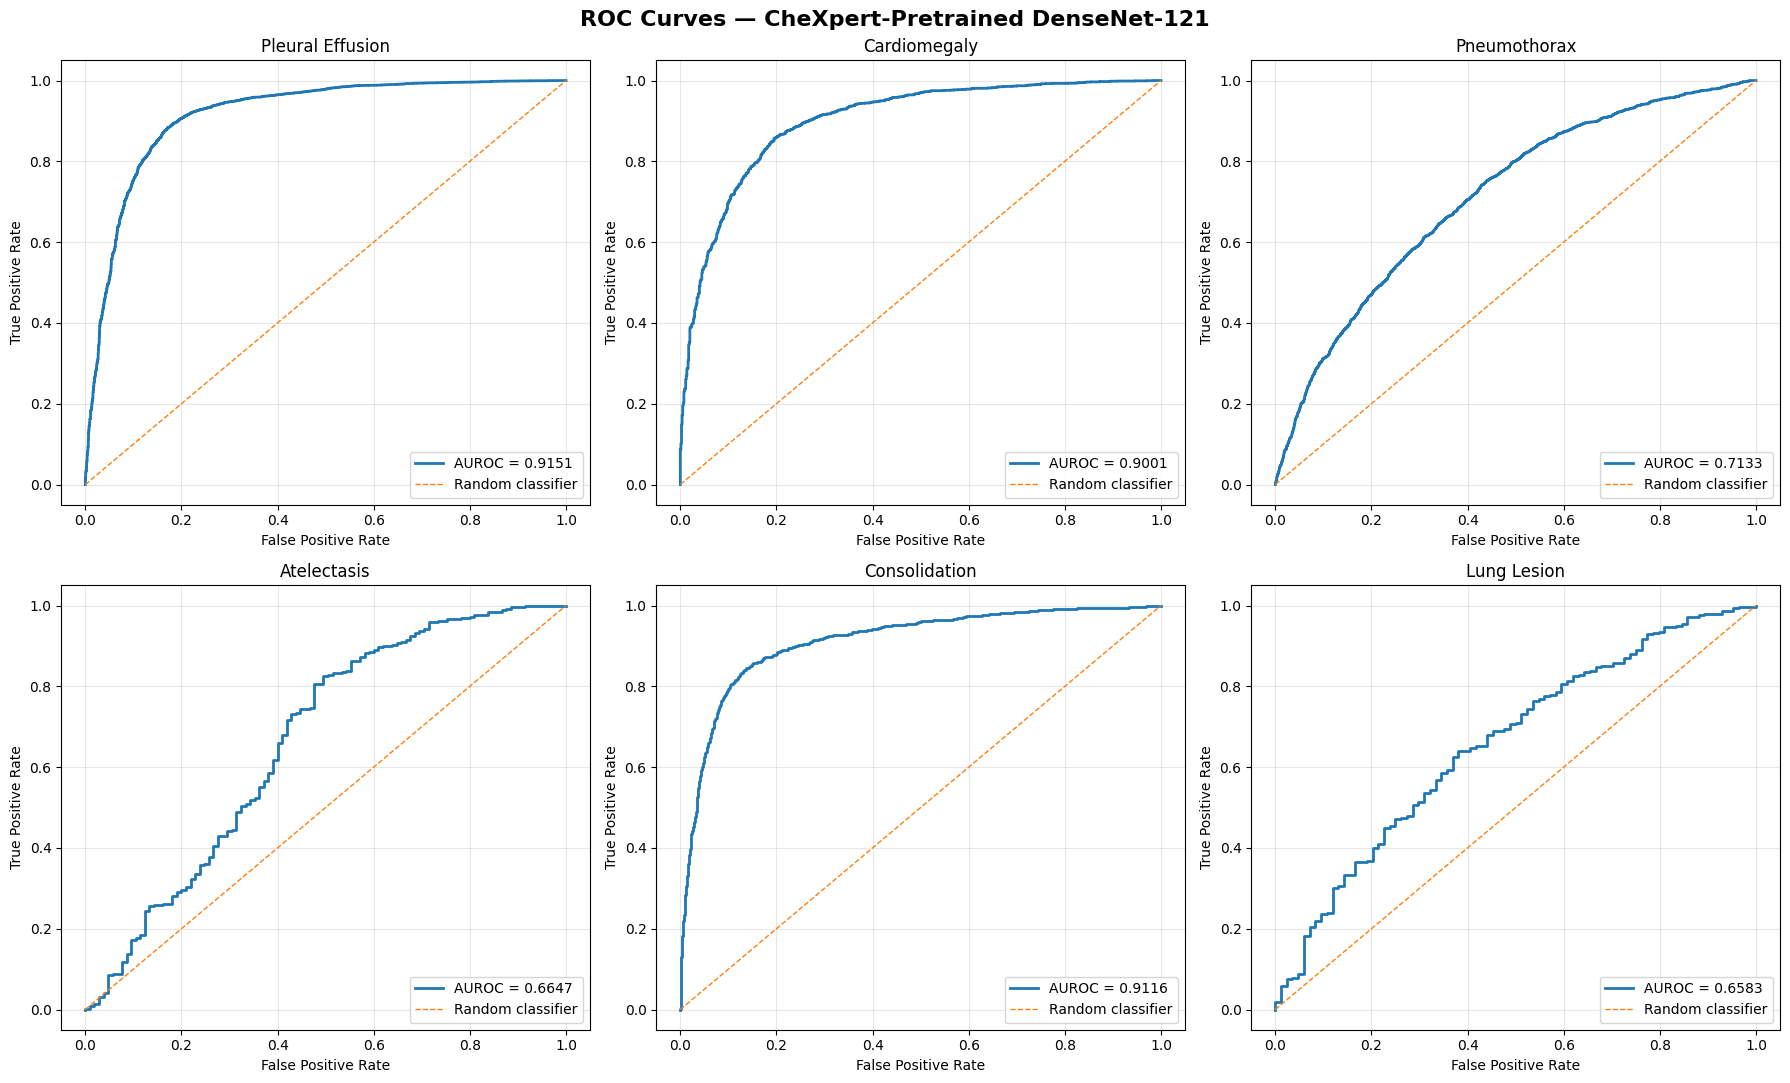

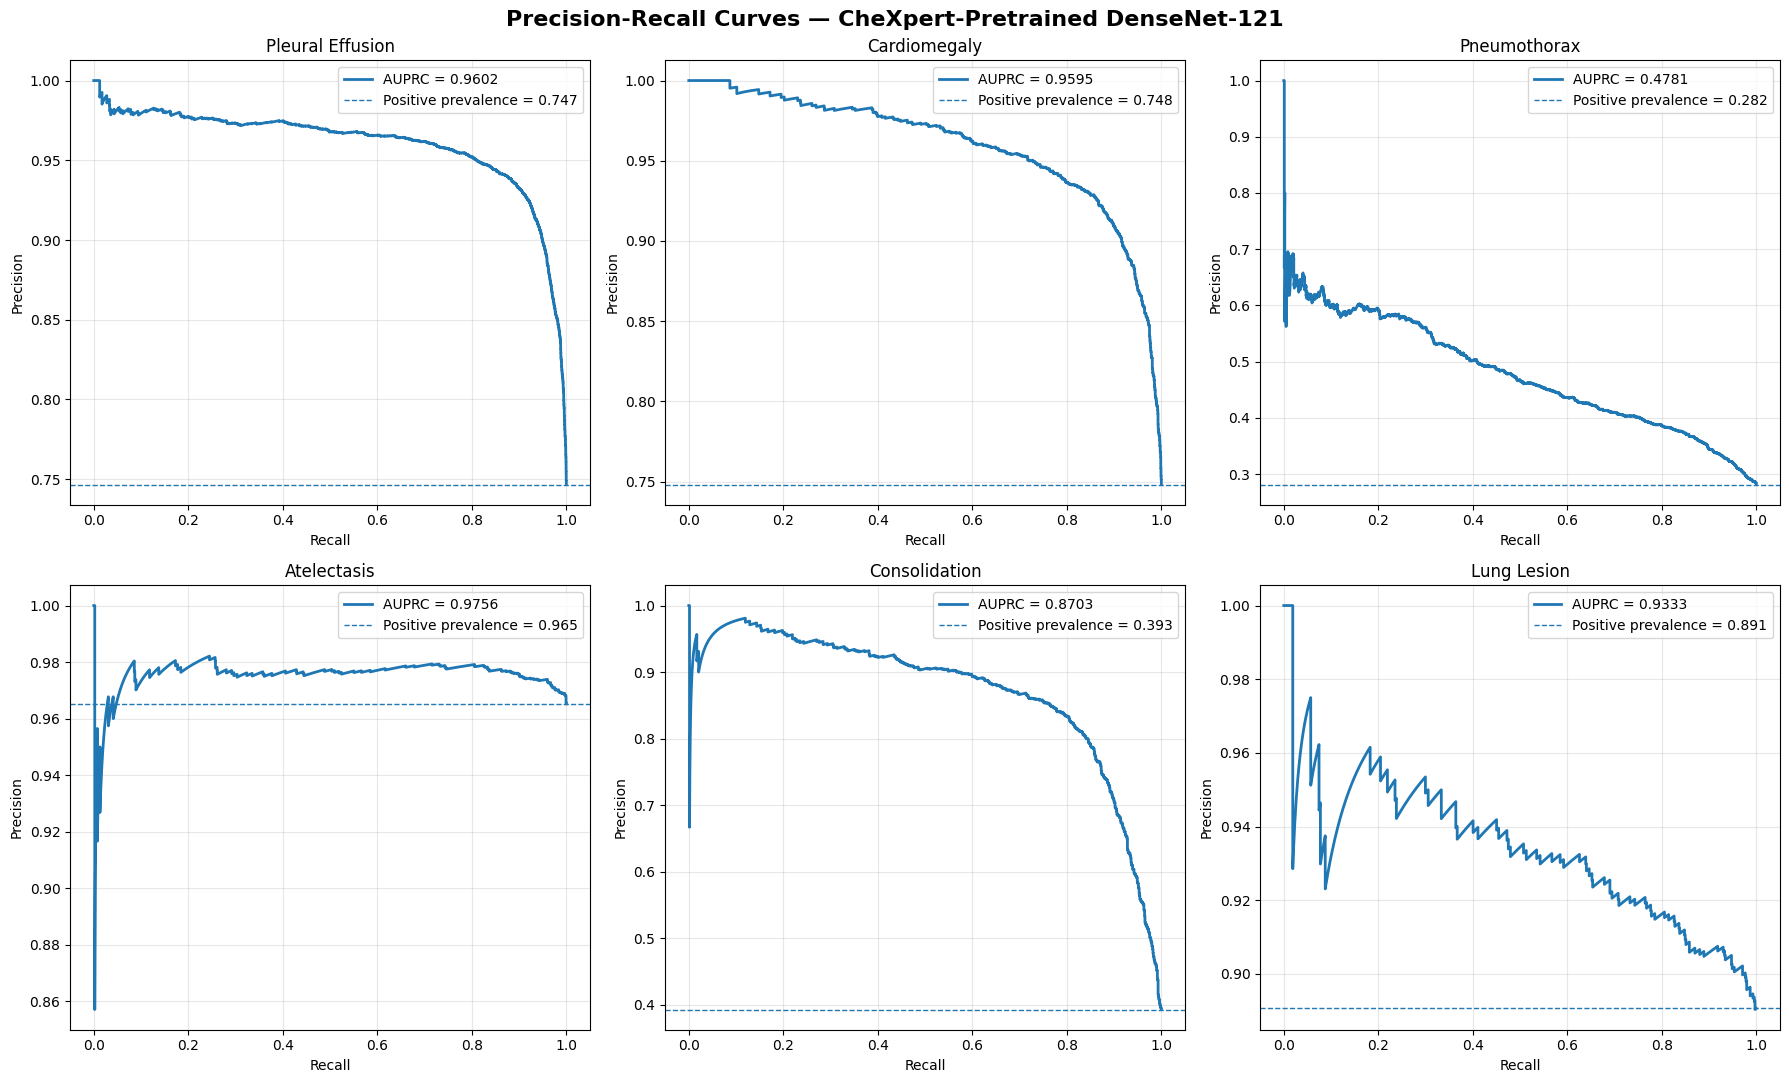

CURVE GENERATION COMPLETED

Saved plots:
roc_curves.png — 440.5 KB
precision_recall_curves.png — 571.1 KB

Output directory: /kaggle/working/m3_chexpert_pretrained/plots


In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

output_dir = "/kaggle/working/m3_chexpert_pretrained"
plot_dir = os.path.join(output_dir, "plots")
os.makedirs(plot_dir, exist_ok=True)

# Load saved predictions
data = np.load(
    os.path.join(output_dir, "validation_predictions.npz"),
    allow_pickle=True
)

predictions = data["predictions"]
targets = data["targets"]
masks = data["masks"]
findings = data["findings"]

metrics_df = pd.read_csv(
    os.path.join(output_dir, "validation_metrics.csv")
)

# ---------------------------------------------------------
# 1. ROC CURVES
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, finding in enumerate(findings):
    valid = masks[:, i].astype(bool)
    y_true = targets[valid, i]
    y_score = predictions[valid, i]

    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)

    axes[i].plot(
        fpr, tpr,
        linewidth=2,
        label=f"AUROC = {auc:.4f}"
    )
    axes[i].plot(
        [0, 1], [0, 1],
        linestyle="--",
        linewidth=1,
        label="Random classifier"
    )

    axes[i].set_title(str(finding))
    axes[i].set_xlabel("False Positive Rate")
    axes[i].set_ylabel("True Positive Rate")
    axes[i].legend(loc="lower right")
    axes[i].grid(alpha=0.3)

fig.suptitle(
    "ROC Curves — CheXpert-Pretrained DenseNet-121",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    os.path.join(plot_dir, "roc_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ---------------------------------------------------------
# 2. PRECISION-RECALL CURVES
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, finding in enumerate(findings):
    valid = masks[:, i].astype(bool)
    y_true = targets[valid, i]
    y_score = predictions[valid, i]

    precision, recall, _ = precision_recall_curve(
        y_true, y_score
    )
    ap = average_precision_score(y_true, y_score)

    prevalence = np.mean(y_true)

    axes[i].plot(
        recall, precision,
        linewidth=2,
        label=f"AUPRC = {ap:.4f}"
    )
    axes[i].axhline(
        prevalence,
        linestyle="--",
        linewidth=1,
        label=f"Positive prevalence = {prevalence:.3f}"
    )

    axes[i].set_title(str(finding))
    axes[i].set_xlabel("Recall")
    axes[i].set_ylabel("Precision")
    axes[i].legend(loc="best")
    axes[i].grid(alpha=0.3)

fig.suptitle(
    "Precision-Recall Curves — CheXpert-Pretrained DenseNet-121",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    os.path.join(plot_dir, "precision_recall_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ---------------------------------------------------------
# 3. SAVE CURVE SUMMARY
# ---------------------------------------------------------

print("=" * 70)
print("CURVE GENERATION COMPLETED")
print("=" * 70)

print("\nSaved plots:")
for filename in [
    "roc_curves.png",
    "precision_recall_curves.png"
]:
    path = os.path.join(plot_dir, filename)
    print(f"{filename} — {os.path.getsize(path) / 1024:.1f} KB")

print("\nOutput directory:", plot_dir)

COMPARATIVE MODEL PERFORMANCE


,Finding,ImageNet_Finetuned_AUROC,ImageNet_Finetuned_AUPRC,CheXpert_Pretrained_AUROC,CheXpert_Pretrained_AUPRC,AUROC_Difference,AUPRC_Difference
0,Pleural Effusion,0.9559,0.9804,0.9151,0.9602,-0.0408,-0.0202
1,Cardiomegaly,0.9442,0.9790,0.9001,0.9595,-0.0441,-0.0195
2,Pneumothorax,0.8268,0.6526,0.7133,0.4781,-0.1135,-0.1745
3,Atelectasis,0.6749,0.9786,0.6647,0.9756,-0.0102,-0.0030
4,Consolidation,0.9427,0.9225,0.9116,0.8703,-0.0311,-0.0522
5,Lung Lesion,0.8091,0.9683,0.6583,0.9333,-0.1508,-0.0350
6,Macro Average,0.8589,0.9136,0.7939,0.8628,-0.0651,-0.0507


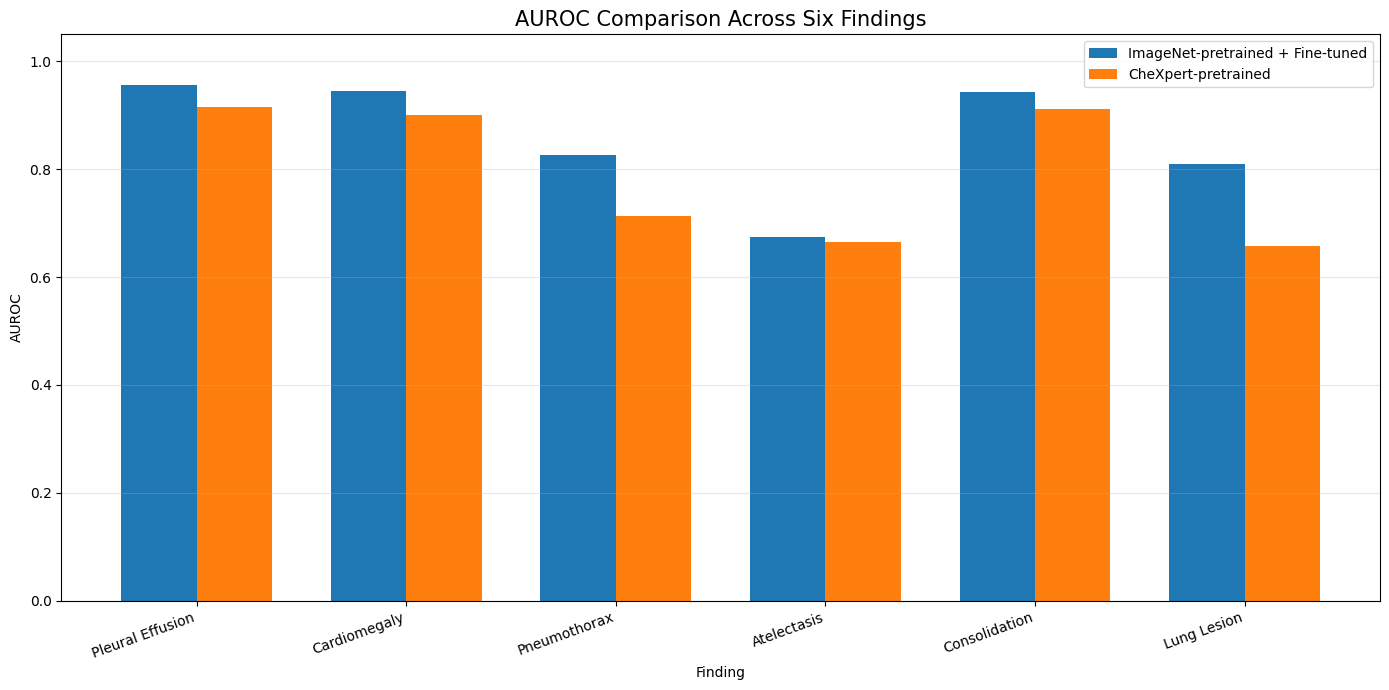

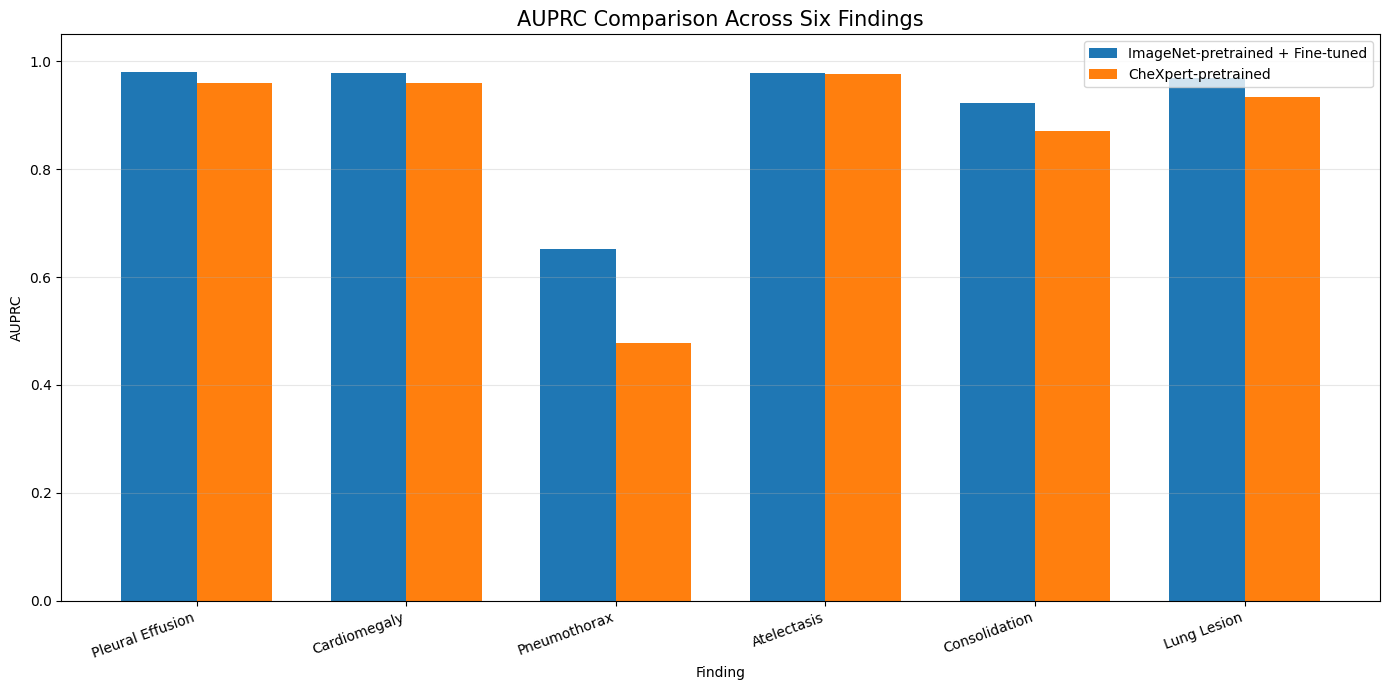


MACRO PERFORMANCE COMPARISON
ImageNet Fine-tuned Macro AUROC: 0.8589
CheXpert Pretrained Macro AUROC: 0.7939
ImageNet Fine-tuned Macro AUPRC: 0.9136
CheXpert Pretrained Macro AUPRC: 0.8628

COMPARISON ARTIFACTS
auprc_comparison.png                     198.19 KB
auroc_comparison.png                     199.58 KB
model_performance_comparison.csv         0.89 KB

Comparison completed.
Output directory: /kaggle/working/m3_chexpert_pretrained/comparison


In [14]:
# ============================================================
# REQUIREMENT 3 — BASELINE MODEL PERFORMANCE
# COMPARATIVE MODEL EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINE OUTPUT DIRECTORIES
# ------------------------------------------------------------

output_dir = "/kaggle/working/m3_chexpert_pretrained"
comparison_dir = os.path.join(output_dir, "comparison")

os.makedirs(comparison_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD CHEXPERT-PRETRAINED MODEL METRICS
# ------------------------------------------------------------

chexpert_metrics_path = os.path.join(
    output_dir, "validation_metrics.csv"
)

df_b = pd.read_csv(chexpert_metrics_path)

required_columns = [
    "Finding", "AUROC", "AUPRC"
]

if not all(col in df_b.columns for col in required_columns):
    raise ValueError(
        f"Unexpected metrics CSV columns: {df_b.columns.tolist()}"
    )

# ------------------------------------------------------------
# 3. IMAGE-NET PRETRAINED + FINE-TUNED MODEL METRICS
# Previously completed experiment
# ------------------------------------------------------------

df_a = pd.DataFrame({
    "Finding": [
        "Pleural Effusion",
        "Cardiomegaly",
        "Pneumothorax",
        "Atelectasis",
        "Consolidation",
        "Lung Lesion"
    ],
    "ImageNet_Finetuned_AUROC": [
        0.9559, 0.9442, 0.8268,
        0.6749, 0.9427, 0.8091
    ],
    "ImageNet_Finetuned_AUPRC": [
        0.9804, 0.9790, 0.6526,
        0.9786, 0.9225, 0.9683
    ]
})

# ------------------------------------------------------------
# 4. PREPARE CHEXPERT-PRETRAINED METRICS
# ------------------------------------------------------------

df_b = df_b.rename(columns={
    "AUROC": "CheXpert_Pretrained_AUROC",
    "AUPRC": "CheXpert_Pretrained_AUPRC"
})

# ------------------------------------------------------------
# 5. MERGE BOTH EXPERIMENTS
# ------------------------------------------------------------

comparison_df = pd.merge(
    df_a,
    df_b[
        [
            "Finding",
            "CheXpert_Pretrained_AUROC",
            "CheXpert_Pretrained_AUPRC"
        ]
    ],
    on="Finding",
    how="inner",
    validate="one_to_one"
)

if len(comparison_df) != 6:
    raise ValueError(
        f"Expected 6 findings, found {len(comparison_df)}"
    )

# ------------------------------------------------------------
# 6. CALCULATE PERFORMANCE DIFFERENCES
# Positive difference means CheXpert-pretrained scored higher.
# ------------------------------------------------------------

comparison_df["AUROC_Difference"] = (
    comparison_df["CheXpert_Pretrained_AUROC"]
    - comparison_df["ImageNet_Finetuned_AUROC"]
)

comparison_df["AUPRC_Difference"] = (
    comparison_df["CheXpert_Pretrained_AUPRC"]
    - comparison_df["ImageNet_Finetuned_AUPRC"]
)

# ------------------------------------------------------------
# 7. CALCULATE MACRO AVERAGES
# ------------------------------------------------------------

macro_row = {
    "Finding": "Macro Average",
    "ImageNet_Finetuned_AUROC": 0.8589485,
    "ImageNet_Finetuned_AUPRC": 0.9135719,
    "CheXpert_Pretrained_AUROC":
        comparison_df["CheXpert_Pretrained_AUROC"].mean(),
    "CheXpert_Pretrained_AUPRC":
        comparison_df["CheXpert_Pretrained_AUPRC"].mean()
}

macro_row["AUROC_Difference"] = (
    macro_row["CheXpert_Pretrained_AUROC"]
    - macro_row["ImageNet_Finetuned_AUROC"]
)

macro_row["AUPRC_Difference"] = (
    macro_row["CheXpert_Pretrained_AUPRC"]
    - macro_row["ImageNet_Finetuned_AUPRC"]
)

comparison_df = pd.concat(
    [comparison_df, pd.DataFrame([macro_row])],
    ignore_index=True
)

# ------------------------------------------------------------
# 8. DISPLAY COMPARATIVE PERFORMANCE TABLE
# ------------------------------------------------------------

print("=" * 90)
print("COMPARATIVE MODEL PERFORMANCE")
print("=" * 90)

display(
    comparison_df.round(4).style.format({
        col: "{:.4f}"
        for col in comparison_df.select_dtypes(
            include="number"
        ).columns
    })
)

# Save comparison table
comparison_df.to_csv(
    os.path.join(
        comparison_dir,
        "model_performance_comparison.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 9. PREPARE DATA FOR PLOTS
# ------------------------------------------------------------

plot_df = comparison_df[
    comparison_df["Finding"] != "Macro Average"
].copy()

x = np.arange(len(plot_df))
width = 0.36

# ------------------------------------------------------------
# 10. AUROC COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(
    x - width / 2,
    plot_df["ImageNet_Finetuned_AUROC"],
    width,
    label="ImageNet-pretrained + Fine-tuned"
)

ax.bar(
    x + width / 2,
    plot_df["CheXpert_Pretrained_AUROC"],
    width,
    label="CheXpert-pretrained"
)

ax.set_title(
    "AUROC Comparison Across Six Findings",
    fontsize=15
)
ax.set_ylabel("AUROC")
ax.set_xlabel("Finding")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["Finding"],
    rotation=20,
    ha="right"
)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        comparison_dir,
        "auroc_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 11. AUPRC COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(
    x - width / 2,
    plot_df["ImageNet_Finetuned_AUPRC"],
    width,
    label="ImageNet-pretrained + Fine-tuned"
)

ax.bar(
    x + width / 2,
    plot_df["CheXpert_Pretrained_AUPRC"],
    width,
    label="CheXpert-pretrained"
)

ax.set_title(
    "AUPRC Comparison Across Six Findings",
    fontsize=15
)
ax.set_ylabel("AUPRC")
ax.set_xlabel("Finding")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["Finding"],
    rotation=20,
    ha="right"
)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        comparison_dir,
        "auprc_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 12. PRINT MACRO COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("MACRO PERFORMANCE COMPARISON")
print("=" * 90)

print(
    f"ImageNet Fine-tuned Macro AUROC: "
    f"{macro_row['ImageNet_Finetuned_AUROC']:.4f}"
)

print(
    f"CheXpert Pretrained Macro AUROC: "
    f"{macro_row['CheXpert_Pretrained_AUROC']:.4f}"
)

print(
    f"ImageNet Fine-tuned Macro AUPRC: "
    f"{macro_row['ImageNet_Finetuned_AUPRC']:.4f}"
)

print(
    f"CheXpert Pretrained Macro AUPRC: "
    f"{macro_row['CheXpert_Pretrained_AUPRC']:.4f}"
)

# ------------------------------------------------------------
# 13. VERIFY AND LIST SAVED ARTIFACTS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("COMPARISON ARTIFACTS")
print("=" * 90)

for filename in sorted(os.listdir(comparison_dir)):
    filepath = os.path.join(comparison_dir, filename)

    print(
        f"{filename:<40} "
        f"{os.path.getsize(filepath) / 1024:.2f} KB"
    )

print("\nComparison completed.")
print("Output directory:", comparison_dir)

In [15]:
import os
import json
import numpy as np

print("=" * 75)
print("VALIDATION ARTIFACT CONSISTENCY CHECK")
print("=" * 75)

paths_to_check = {
    "Original experiment predictions":
        "/kaggle/working/m3_baseline/evaluation/validation_predictions.npz",
    "Original experiment metrics":
        "/kaggle/working/m3_baseline/evaluation/full_validation_metrics.json",
    "CheXpert-pretrained predictions":
        "/kaggle/working/m3_chexpert_pretrained/validation_predictions.npz",
    "CheXpert-pretrained metrics":
        "/kaggle/working/m3_chexpert_pretrained/validation_metrics.csv"
}

for name, path in paths_to_check.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")

print("\nOriginal validation predictions:")
original_path = paths_to_check["Original experiment predictions"]

if os.path.exists(original_path):
    original = np.load(original_path, allow_pickle=True)
    for key in original.files:
        print(key, original[key].shape)
else:
    print("Original prediction archive is not present in this runtime.")

print("\nCheXpert-pretrained validation predictions:")
new_path = paths_to_check["CheXpert-pretrained predictions"]

if os.path.exists(new_path):
    new = np.load(new_path, allow_pickle=True)
    for key in new.files:
        print(key, new[key].shape)
else:
    print("New prediction archive is missing.")

print("\nCheck completed.")

VALIDATION ARTIFACT CONSISTENCY CHECK
Original experiment predictions: NOT FOUND
Original experiment metrics: NOT FOUND
CheXpert-pretrained predictions: FOUND
CheXpert-pretrained metrics: FOUND

Original validation predictions:
Original prediction archive is not present in this runtime.

CheXpert-pretrained validation predictions:
predictions (19100, 6)
targets (19100, 6)
masks (19100, 6)
findings (6,)

Check completed.


In [16]:
import numpy as np
import pandas as pd

print("=" * 75)
print("EXACT VALIDATION SPLIT VERIFICATION")
print("=" * 75)

# Original notebook's validation dataframe
original_paths = (
    chexpert_internal_valid["image_path"]
    .astype(str)
    .to_numpy()
)

# Validation dataframe used for the new experiment
new_paths = (
    chexpert_candidate_valid["image_path"]
    .astype(str)
    .to_numpy()
)

# Compare image membership and ordering
same_count = len(original_paths) == len(new_paths)
same_order = (
    same_count and np.array_equal(original_paths, new_paths)
)
same_members = (
    same_count
    and set(original_paths) == set(new_paths)
)

print("Original validation images:", len(original_paths))
print("New validation images:", len(new_paths))
print("Same number of images:", same_count)
print("Same image membership:", same_members)
print("Same image ordering:", same_order)

# Compare labels and uncertainty masks
original_labels = chexpert_internal_valid[
    target_findings
].to_numpy(dtype=np.float32)

new_labels = chexpert_candidate_valid[
    target_findings
].to_numpy(dtype=np.float32)

original_masks = np.isin(original_labels, [0, 1])
new_masks = np.isin(new_labels, [0, 1])

print("\nSame raw labels:", np.array_equal(
    original_labels, new_labels, equal_nan=True
))

print("Same definite-label masks:", np.array_equal(
    original_masks, new_masks
))

print("\n" + "=" * 75)
print("VERIFICATION COMPLETED")
print("=" * 75)

EXACT VALIDATION SPLIT VERIFICATION
Original validation images: 19100
New validation images: 19100
Same number of images: True
Same image membership: True
Same image ordering: True

Same raw labels: True
Same definite-label masks: True

VERIFICATION COMPLETED


In [17]:
print("=" * 70)
print("CANDIDATE DATASET AUDIT")
print("=" * 70)

for name in [
    "chexpert_train_clean",
    "chexpert_internal_train",
    "chexpert_internal_valid",
    "chexpert_candidate_train",
    "chexpert_candidate_valid",
]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}")
        print("Rows:", len(df))
        if "patient_id" in df.columns:
            print("Unique patients:", df["patient_id"].nunique())
        if "image_path" in df.columns:
            print("Unique image paths:", df["image_path"].nunique())
    else:
        print(f"\n{name}: NOT PRESENT")

print("\n" + "=" * 70)
print("AVAILABLE DATASET-SAMPLING VARIABLES")
print("=" * 70)

keywords = ["candidate", "sample", "subset", "train", "valid", "split"]

for name in sorted(globals()):
    if any(word in name.lower() for word in keywords):
        obj = globals()[name]
        if hasattr(obj, "__len__") and not isinstance(obj, (str, bytes)):
            try:
                print(name, "| type:", type(obj).__name__, "| length:", len(obj))
            except Exception:
                pass

CANDIDATE DATASET AUDIT

chexpert_train_clean
Rows: 191027
Unique patients: 64534
Unique image paths: 191027

chexpert_internal_train
Rows: 171927
Unique patients: 58080
Unique image paths: 171927

chexpert_internal_valid
Rows: 19100
Unique patients: 6454
Unique image paths: 19100

chexpert_candidate_train
Rows: 17508
Unique patients: 5808
Unique image paths: 17508

chexpert_candidate_valid
Rows: 19100
Unique patients: 6454
Unique image paths: 19100

AVAILABLE DATASET-SAMPLING VARIABLES
candidate_indices | type: ndarray | length: 5808
candidate_patients | type: set | length: 5808
candidate_train_patients | type: set | length: 5808
candidate_valid_patients | type: set | length: 6454
chexpert_candidate_train | type: DataFrame | length: 17508
chexpert_candidate_valid | type: DataFrame | length: 19100
chexpert_internal_train | type: DataFrame | length: 171927
chexpert_internal_valid | type: DataFrame | length: 19100
chexpert_train_clean | type: DataFrame | length: 191027
chexpert_train_df 

In [18]:
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

keywords = [
    "candidate_indices",
    "candidate_patients",
    "candidate_train_patients",
    "chexpert_candidate_train",
]

print("=" * 75)
print("ORIGINAL CANDIDATE DATASET CREATION CODE")
print("=" * 75)

for keyword in keywords:
    print(f"\n\n### SEARCH: {keyword}")

    matches = [
        (i, source)
        for i, source in enumerate(history)
        if keyword in source
    ]

    if not matches:
        print("No matching execution-history entry found.")
        continue

    for index, source in matches[-3:]:
        print(f"\n--- History entry {index} ---")
        print(source)

print("\n" + "=" * 75)
print("PATIENT OVERLAP VERIFICATION")
print("=" * 75)

overlap = (
    set(chexpert_candidate_train["patient_id"].unique())
    & set(chexpert_candidate_valid["patient_id"].unique())
)

print("Candidate training patients:", chexpert_candidate_train["patient_id"].nunique())
print("Validation patients:", chexpert_candidate_valid["patient_id"].nunique())
print("Overlapping patients:", len(overlap))
print("Patient-level separation:", len(overlap) == 0)

ORIGINAL CANDIDATE DATASET CREATION CODE


### SEARCH: candidate_indices

--- History entry 5 ---
# ============================================================
# CELL 19 — RESTORE CHEXPERT DATASET AND CANDIDATE SPLITS
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# 1. Load original CheXpert metadata
# ------------------------------------------------------------

chexpert_root = "/kaggle/input/datasets/ashery/chexpert"

train_csv_path = os.path.join(chexpert_root, "train.csv")
valid_csv_path = os.path.join(chexpert_root, "valid.csv")

chexpert_train_df = pd.read_csv(train_csv_path)
chexpert_valid_df = pd.read_csv(valid_csv_path)

# Resolve image paths
def resolve_chexpert_path(csv_path):
    relative_path = csv_path.replace(
        "CheXpert-v1.0-small/", "", 1
    )
    return os.path.join(chexpert_ro

In [19]:
import pandas as pd
import numpy as np

# ============================================================
# REQUIREMENT 3 — CANDIDATE DATASET REPRESENTATIVENESS AUDIT
# ============================================================

findings = target_findings

datasets = {
    "Complete internal training": chexpert_internal_train,
    "Candidate training subset": chexpert_candidate_train
}

results = []

for dataset_name, df in datasets.items():
    for finding in findings:
        labels = df[finding]

        total = len(labels)
        positive = int((labels == 1).sum())
        negative = int((labels == 0).sum())
        uncertain = int((labels == -1).sum())
        missing = int(labels.isna().sum())

        results.append({
            "Dataset": dataset_name,
            "Finding": finding,
            "Total": total,
            "Positive": positive,
            "Negative": negative,
            "Uncertain": uncertain,
            "Missing": missing,
            "Positive (%)": positive / total * 100,
            "Negative (%)": negative / total * 100,
            "Uncertain (%)": uncertain / total * 100,
            "Missing (%)": missing / total * 100
        })

distribution_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Display label distributions
# ------------------------------------------------------------

print("=" * 90)
print("LABEL DISTRIBUTION — COMPLETE TRAINING VS CANDIDATE SUBSET")
print("=" * 90)

display(
    distribution_df.round(2)
)

# ------------------------------------------------------------
# Compare percentage-point differences
# ------------------------------------------------------------

comparison_rows = []

for finding in findings:
    full = distribution_df[
        (distribution_df["Dataset"] == "Complete internal training") &
        (distribution_df["Finding"] == finding)
    ].iloc[0]

    candidate = distribution_df[
        (distribution_df["Dataset"] == "Candidate training subset") &
        (distribution_df["Finding"] == finding)
    ].iloc[0]

    comparison_rows.append({
        "Finding": finding,
        "Positive difference (pp)": (
            candidate["Positive (%)"] - full["Positive (%)"]
        ),
        "Negative difference (pp)": (
            candidate["Negative (%)"] - full["Negative (%)"]
        ),
        "Uncertain difference (pp)": (
            candidate["Uncertain (%)"] - full["Uncertain (%)"]
        ),
        "Missing difference (pp)": (
            candidate["Missing (%)"] - full["Missing (%)"]
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "=" * 90)
print("CANDIDATE VS COMPLETE TRAINING — PERCENTAGE-POINT DIFFERENCES")
print("=" * 90)

display(comparison_df.round(2))

# ------------------------------------------------------------
# Save audit results
# ------------------------------------------------------------

output_dir = "/kaggle/working/m3_chexpert_pretrained"

import os
os.makedirs(output_dir, exist_ok=True)

distribution_df.to_csv(
    os.path.join(output_dir, "candidate_dataset_label_distribution.csv"),
    index=False
)

comparison_df.to_csv(
    os.path.join(output_dir, "candidate_dataset_distribution_comparison.csv"),
    index=False
)

print("\nAudit CSV files saved successfully.")

LABEL DISTRIBUTION — COMPLETE TRAINING VS CANDIDATE SUBSET


,Dataset,Finding,Total,Positive,Negative,Uncertain,Missing,Positive (%),Negative (%),Uncertain (%),Missing (%)
0,Complete internal training,Pleural Effusion,171927,69277,22713,8635,71302,40.29,13.21,5.02,41.47
1,Complete internal training,Cardiomegaly,171927,20994,7064,6058,137811,12.21,4.11,3.52,80.16
2,Complete internal training,Pneumothorax,171927,15849,43117,2463,110498,9.22,25.08,1.43,64.27
3,Complete internal training,Atelectasis,171927,26804,920,26836,117367,15.59,0.54,15.61,68.27
4,Complete internal training,Consolidation,171927,11688,17604,21876,120759,6.80,10.24,12.72,70.24
5,Complete internal training,Lung Lesion,171927,6356,692,1007,163872,3.70,0.40,0.59,95.31
6,Candidate training subset,Pleural Effusion,17508,7168,2344,855,7141,40.94,13.39,4.88,40.79
7,Candidate training subset,Cardiomegaly,17508,2181,700,613,14014,12.46,4.00,3.50,80.04
8,Candidate training subset,Pneumothorax,17508,1605,4320,260,11323,9.17,24.67,1.49,64.67
9,Candidate training subset,Atelectasis,17508,2690,104,2759,11955,15.36,0.59,15.76,68.28



CANDIDATE VS COMPLETE TRAINING — PERCENTAGE-POINT DIFFERENCES


,Finding,Positive difference (pp),Negative difference (pp),Uncertain difference (pp),Missing difference (pp)
0,Pleural Effusion,0.65,0.18,-0.14,-0.69
1,Cardiomegaly,0.25,-0.11,-0.02,-0.11
2,Pneumothorax,-0.05,-0.40,0.05,0.40
3,Atelectasis,-0.23,0.06,0.15,0.02
4,Consolidation,0.37,0.42,0.28,-1.07
5,Lung Lesion,-0.14,-0.00,-0.01,0.16



Audit CSV files saved successfully.
